# Controle neural indireto e direto × PID × LQR

**Vitor Mandolesi** — Trabalho Final de Curso, FEEC/UNICAMP

Derivado do notebook `contr_neural_indireto.ipynb` (EA722, Experiência 7, parte 2; Profs. Fernando J. Von Zuben e Caíque Santos Lima).

## Como usar

**O que o notebook faz.** Projeta e compara três controladores — PID (em cascata no pêndulo, PI na infusão), LQR e o controle neural do notebook do professor em duas formas: a **indireta** (emulador neural da planta + controlador neural treinado através dele, variante `RN`) e a **direta** (o mesmo controlador refinado pela planta exata, com o gradiente exato por autodiferenciação do simulador, uma idealização do controle direto; variante `RN-direta`) — em duas plantas: o carro-pêndulo do notebook do professor e a infusão de fármaco de Jadoon et al. (2017), sem atraso. Simula os cenários C1 (condição inicial pequena), C2 (varredura da condição inicial), C3 (100 plantas com parâmetros a ±20 %) e C4 (LQR projetado num modelo aproximado, só no pêndulo, com a `RN-C4` indireta e a `RN-C4-direta`), as respostas ao degrau e as métricas clássicas, grava as tabelas em CSV, as figuras em PNG e uma rodada de referência com todos os números.

| seção | conteúdo |
|---|---|
| 0 | configuração |
| 1 | plantas (1.1 carro-pêndulo, 1.2 infusão), simulação e métricas (1.3) |
| 2 | controladores clássicos: LQR (2.1), PID em cascata e PI (2.2), margens de estabilidade (2.3) |
| 3 | controlador neural, indireto e direto: funções (3.1), variantes e treino (3.2), qualidade do emulador (3.3), calibração (3.4), curvas de treino (3.5), lei de controle aprendida (3.6), reprodutibilidade (3.7), linhas de controle (3.8) |
| 4 | resultados: C1 e matriz 2 × 3 (4.1), C2 e região de atração (4.2), C3 (4.3), C4 (4.4), ganho da RN na infusão (4.5), custo computacional (4.6), respostas ao degrau e métricas clássicas — tempo de subida, acomodação, sobressinal (4.7) |
| A | código original do professor e as conferências contra ele |
| B | diagnóstico: horizonte de avaliação e termo de x |
| 5 | resumo das verificações e gravação da rodada de referência |

**Como rodar no Colab.**
1. **Com o cache (recomendado).** Descompacte o `TFC_cache.zip` em `MyDrive/TFC_cache`, com os arquivos direto na pasta (sem subpasta). Os arquivos de pesos terminam em `__v1.npz`. Depois, *Ambiente de execução → Executar tudo*. A célula da seção 0 monta o Google Drive (pede autorização uma vez) e esconde a GPU do TensorFlow. Os pesos são carregados, e a seção 3.7 retreina a RN principal na semente 0, duas vezes por planta. Tempo medido num ambiente com as versões do Colab: cerca de 4 min.
2. **Sem o cache.** Todas as redes são treinadas e gravadas em `MyDrive/TFC_cache`. Tempo medido no ambiente onde o notebook foi gravado: cerca de 14 min; no Colab, deve passar disso. O treino não é reprodutível bit a bit entre ambientes de execução diferentes (hardware e bibliotecas numéricas); por isso os pesos treinados acompanham o notebook e, com eles, todos os resultados são reproduzidos exatamente.
3. `RETREINAR = True`, na primeira linha da seção 0, ignora o cache e treina tudo.

O tempo de cada parte aparece na saída da seção 5.

**Onde ficam as saídas.** No Colab, ao lado do cache, no Google Drive:
- `MyDrive/TFC_resultados`: o CSV de cada tabela (`tempos__*.csv` são tempos de relógio);
- `MyDrive/TFC_figuras`: as figuras em PNG a 600 dpi e `legendas.md`, com a legenda de cada figura e tabela;
- `MyDrive/TFC_referencia`: a rodada de referência (`numeros.json`, `trajetorias.json`, `tempos.json`, `hashes.txt`, `ambiente.json` e `csv/`).

Fora do Colab, as pastas `cache/`, `resultados/`, `figuras/` e `referencia/` ficam na pasta de trabalho do notebook.

**Versões testadas.** A célula da seção 0 imprime as versões em uso e avisa, sem parar, se alguma não estiver na tabela.

| biblioteca | ambiente de gravação | ambiente com as versões do Colab |
|---|---|---|
| Python | 3.13.18 | 3.13.18 |
| NumPy | 2.5.3 | 2.1.3 |
| SciPy | 1.18.1 | 1.16.3 |
| pandas | 3.0.5 | 2.2.3 |
| Matplotlib | 3.11.2 | 3.10.0 |
| TensorFlow | 2.21.0 | 2.21.0 |
| Keras | 3.15.1 | 3.13.2 |

**Notas.**
- As mensagens internas do TensorFlow ao ser importado e os avisos das bibliotecas ficam silenciados; erros aparecem normalmente.
- Na tela, cada célula mostra só resumos (mediana, mínimo e máximo; contagens "k de 5"), as figuras e uma linha por verificação (nome, OK ou FALHA, valor e tolerância). As tabelas completas, por semente, por condição inicial e por realização, ficam nos CSV.
- Nas figuras, toda curva é um traço contínuo de mesma espessura, e o controlador é identificado só pela cor, a mesma em todas as figuras.
- Com os pesos do cache e as mesmas versões das bibliotecas, os números se repetem bit a bit; com as versões do Colab, contas de álgebra linear em NumPy e SciPy mudam na última casa. A função `comparar` de `ler_referencia.py` compara duas rodadas de referência e mostra o tamanho de cada diferença.

## 0. Configuração

Importa as bibliotecas, fixa as flags e as sementes, esconde a GPU do TensorFlow e liga as operações determinísticas, define as pastas, o cache de pesos, a função `verificar`, as funções que registram os números da rodada de referência, as cores das figuras e as funções que gravam figuras e mostram tabelas. Imprime as versões e avisa se alguma não está entre as testadas.

- `RETREINAR`: `True` ignora o cache e treina todas as redes; `False` carrega o que estiver no cache e treina o que faltar.
- Cada etapa aleatória do treino recebe a semente 100·código + semente, com código 0 (dados), 1 (dados de validação), 2 (emulador), 3 (imitação) e 4 (refinamento da `RN-C4-direta`).
- Cada arquivo de pesos guarda a configuração do treino, que é conferida na carga.
- `verificar` imprime o resultado de cada verificação e para o notebook se alguma falhar.
- Cada número de resultado entra em `NUMEROS`, com uma chave `planta/cenário/tabela/linha/coluna`; o SHA-256 de cada trajetória simulada entra em `TRAJETORIAS`; os tempos de relógio, em `TEMPOS`.
- `COR`: uma cor fixa por controlador e variante; `CORES_SEMENTE`: uma cor por semente. `salvar_figura` confere que os artistas com rótulo de cada eixo têm cores distintas, grava o PNG a 600 dpi, mostra a figura a 100 dpi e a legenda.
- `LEGENDA_DIRETA` e `LEGENDA_C4_DIRETA`: as frases que acompanham a `RN-direta` e a `RN-C4-direta` nas legendas.

In [1]:
RETREINAR = False   # True: ignora o cache e treina todas as redes; False: carrega o que estiver no cache e treina o que faltar.

import os, sys, gc, re, io, time, json, shutil, hashlib, itertools, platform, warnings, contextlib, unicodedata

# A GPU é escondida do TensorFlow antes de ele ser importado: o treino usa operações determinísticas, e a GPU não tem versão
# determinística de todas elas.
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # reduz as mensagens internas do TensorFlow

import numpy as np
import scipy
import scipy.linalg
import scipy.integrate
import scipy.optimize
import scipy.signal
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from IPython.display import display, Markdown


@contextlib.contextmanager
def sem_mensagens_nativas():
    """Descarta o que bibliotecas em C++ escrevem direto no stderr (as mensagens internas do TensorFlow ao ser importado e ao
    procurar GPU). Exceções do Python continuam aparecendo."""
    sys.stderr.flush()
    copia = os.dup(2)
    nulo = os.open(os.devnull, os.O_WRONLY)
    os.dup2(nulo, 2)
    try:
        yield
    finally:
        os.dup2(copia, 2)
        os.close(nulo)
        os.close(copia)


with sem_mensagens_nativas():
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    tf.config.set_visible_devices([], "GPU")
    tf.config.experimental.enable_op_determinism()   # operações determinísticas
    N_GPUS = len(tf.config.get_visible_devices("GPU"))

# Avisos de bibliotecas silenciados; erros continuam aparecendo.
warnings.simplefilter("ignore")
tf.get_logger().setLevel("ERROR")

SEMENTES = [0, 1, 2, 3, 4]      # sementes de cada RN
T_AVALIACAO = 600               # horizonte de avaliação no pêndulo: 600 passos de 0,02 s (12 s)
SEMENTE_C3 = 2026               # semente do sorteio das plantas do C3 do pêndulo (a infusão usa SEMENTE_C3 + 1)
N_C3 = 100                      # número de plantas do C3

VERSAO_CACHE = "v1"             # sufixo dos arquivos de pesos

# Semente de cada etapa aleatória: 100·código + semente.
CODIGO_ETAPA = {"dados": 0, "validacao": 1, "emulador": 2, "imitacao": 3, "refinamento-C4-direta": 4}


def semente_da_etapa(semente, etapa):
    return 100 * CODIGO_ETAPA[etapa] + semente


def fixar_semente(semente, etapa):
    keras.utils.set_random_seed(semente_da_etapa(semente, etapa))   # fixa as sementes do Python, do NumPy e do TensorFlow


# No Colab, o cache e as saídas vão para o Google Drive.
EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA_CACHE = "/content/drive/MyDrive/TFC_cache"
else:
    PASTA_CACHE = os.path.abspath("./cache")
os.makedirs(PASTA_CACHE, exist_ok=True)

# Tabelas (CSV), figuras (PNG) e rodada de referência, ao lado do cache.
PASTA_BASE = os.path.dirname(PASTA_CACHE)
PASTA_RESULTADOS = os.path.join(PASTA_BASE, "TFC_resultados" if EM_COLAB else "resultados")
PASTA_FIGURAS = os.path.join(PASTA_BASE, "TFC_figuras" if EM_COLAB else "figuras")
PASTA_REFERENCIA = os.path.join(PASTA_BASE, "TFC_referencia" if EM_COLAB else "referencia")
for pasta in (PASTA_RESULTADOS, PASTA_FIGURAS, PASTA_REFERENCIA):
    os.makedirs(pasta, exist_ok=True)

# Versões em uso e versões testadas.
VERSOES = {"Python": platform.python_version(), "NumPy": np.__version__, "SciPy": scipy.__version__, "pandas": pd.__version__,
           "Matplotlib": matplotlib.__version__, "TensorFlow": tf.__version__, "Keras": keras.__version__}
VERSOES_TESTADAS = {"Python": ["3.13.18"], "NumPy": ["2.1.3", "2.5.3"], "SciPy": ["1.16.3", "1.18.1"], "pandas": ["2.2.3", "3.0.5"],
                    "Matplotlib": ["3.10.0", "3.11.2"], "TensorFlow": ["2.21.0"], "Keras": ["3.13.2", "3.15.1"]}


def nome_arquivo(texto):
    """Nome de variante → trecho de nome de arquivo só com ASCII (sem acentos; "+" vira "-mais-")."""
    sem_acento = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return sem_acento.replace("+", "-mais-")


def arquivo_cache(planta, variante, etapa, semente):
    return os.path.join(PASTA_CACHE, f"{planta.nome}__{nome_arquivo(variante)}__{etapa}__s{semente}__{VERSAO_CACHE}.npz")


def como_json(objeto):
    return json.loads(json.dumps(objeto))   # converte tuplas, floats do NumPy etc. em tipos JSON, para comparar com ==


def salvar_cache(caminho, pesos, meta):
    np.savez(caminho, meta=np.array(json.dumps(meta)), **{f"p{i}": np.asarray(w) for i, w in enumerate(pesos)})


def carregar_cache(caminho, config):
    """Devolve (pesos, meta) se o arquivo existe e foi treinado com a mesma configuração; senão, None."""
    if RETREINAR or not os.path.exists(caminho):
        return None
    with np.load(caminho) as dados:
        meta = json.loads(str(dados["meta"]))
        pesos = [dados[f"p{i}"] for i in range(len(dados.files) - 1)]
    if meta.get("config") != como_json(config):
        print(f"  aviso: {os.path.basename(caminho)} foi treinado com outra configuração; treinando de novo.")
        return None
    return pesos, meta


# Resultado de cada verificação; o notebook para na primeira que falhar.
VERIFICACOES = []


def verificar(nome, condicao, detalhe="", tol=""):
    """Registra uma verificação e imprime uma linha: identificador, OK ou FALHA, valor e tolerância. `nome` é
    "identificador — o que confere"; a descrição fica no registro e no código."""
    condicao = bool(condicao)
    VERIFICACOES.append((nome, condicao, detalhe, tol))
    print(f"{nome.split(' — ')[0]}: {'OK' if condicao else 'FALHA'}" + (f" | {detalhe}" if detalhe else "")
          + (f" | tolerância: {tol}" if tol else ""))
    assert condicao, f"Verificação falhou: {nome} ({detalhe})"


# Registros da rodada de referência: números de resultado, SHA-256 das trajetórias, tempos de relógio e CSV gravados.
NUMEROS, TEMPOS, TRAJETORIAS, CSV_GRAVADOS = {}, {}, {}, []


def parte_chave(texto):
    """Um pedaço de chave: o texto como está, com "/" trocada por " por " (a barra separa os níveis da chave)."""
    if isinstance(texto, tuple):
        texto = " | ".join(str(t) for t in texto)
    return str(texto).replace("/", " por ")


def como_numero(valor):
    """bool, int ou float do Python, com o valor exato, para um número; None para o que não é número."""
    if isinstance(valor, (bool, np.bool_)):
        return bool(valor)
    if isinstance(valor, (int, np.integer)):
        return int(valor)
    if isinstance(valor, (float, np.floating)):
        return float(valor)
    return None


def registrar_numeros(prefixo, dicionario, destino=None):
    destino = NUMEROS if destino is None else destino
    for nome, valor in dicionario.items():
        numero = como_numero(valor)
        assert numero is not None, f"registrar_numeros: {prefixo}/{nome} não é número ({valor!r})"
        destino[f"{prefixo}/{parte_chave(nome)}"] = numero


def registrar_matriz(nome, matriz):
    """Cada elemento de um vetor ou de uma matriz (complexos: parte real e parte imaginária)."""
    m = np.atleast_1d(np.asarray(matriz))
    for indice, valor in np.ndenumerate(m):
        sufixo = "_".join(str(i) for i in indice)
        if np.iscomplexobj(m):
            NUMEROS[f"{nome}/{sufixo}/real"] = float(np.real(valor))
            NUMEROS[f"{nome}/{sufixo}/imag"] = float(np.imag(valor))
        else:
            NUMEROS[f"{nome}/{sufixo}"] = como_numero(valor)


def registrar_tabela(nome, tabela, tempo=False):
    """Grava a tabela em CSV e registra cada célula numérica (as de texto ficam só no CSV).

    `nome` é "planta/cenário/tabela". Com tempo=True, a tabela é de tempos de relógio: o CSV ganha o prefixo
    "tempos__" e os números vão para TEMPOS."""
    arquivo = os.path.join(PASTA_RESULTADOS, ("tempos__" if tempo else "") + nome.replace("/", "__") + ".csv")
    tabela.to_csv(arquivo)
    if arquivo not in CSV_GRAVADOS:
        CSV_GRAVADOS.append(arquivo)
    destino = TEMPOS if tempo else NUMEROS
    for coluna in tabela.columns:
        for linha, valor in tabela[coluna].items():
            numero = como_numero(valor)
            if numero is not None:
                destino[f"{nome}/{parte_chave(linha)}/{parte_chave(coluna)}"] = numero


def chave_controlador(rotulo):
    """'RN refinada s3' → 'RN_refinada/semente3'; 'LQR correto' → 'LQR_correto'."""
    achado = re.fullmatch(r"(.*) s(\d+)", rotulo)
    if achado:
        return f"{parte_chave(achado.group(1)).replace(' ', '_')}/semente{achado.group(2)}"
    return parte_chave(rotulo).replace(" ", "_")


def condicao_pendulo(theta0):
    return f"theta{theta0}"


def condicao_infusao(C0):
    return f"C0_{C0}"


def registrar_simulacoes(prefixo, resultados, condicao):
    """As métricas de cada simulação de um cenário e o SHA-256 da trajetória (X e U, em float64)."""
    for (rotulo, cond), r in resultados.items():
        base = f"{prefixo}/{chave_controlador(rotulo)}/{condicao(cond)}"
        for metrica, valor in r.items():
            if metrica in ("familia", "etapa", "semente", "sim"):
                continue
            numero = como_numero(valor)
            if numero is not None:
                NUMEROS[f"{base}/{parte_chave(metrica)}"] = numero
        X = np.ascontiguousarray(r["sim"]["X"], dtype=np.float64)
        U = np.ascontiguousarray(r["sim"]["U"], dtype=np.float64)
        TRAJETORIAS[base] = hashlib.sha256(X.tobytes() + U.tobytes()).hexdigest()


def registrar_c3(prefixo, resultados, condicao, metricas_):
    """As métricas escolhidas de cada realização do C3."""
    for (rotulo, cond), tabela in resultados.items():
        base = f"{prefixo}/{chave_controlador(rotulo)}/{condicao(cond)}"
        for metrica in metricas_:
            for i, valor in tabela[metrica].items():
                numero = como_numero(valor)
                if numero is not None:
                    NUMEROS[f"{base}/real{i:03d}/{parte_chave(metrica)}"] = numero


def registrar_historicos(planta, treino, rns):
    """As perdas de treino: emulador (a cada 100 épocas; o do professor, a cada 50), imitação (a cada 50) e
    refinamento (a cada época)."""
    for (tipo, s), (_, meta, _) in treino["emuladores"].items():
        for epoca, perda in meta["perdas"]:
            NUMEROS[f"{planta.nome}/treino/emulador-{tipo}/semente{s}/epoca{epoca:04d}"] = float(perda)
    for (nome, s), (_, meta, _) in treino["imitados"].items():
        for epoca, perda in meta["perdas"]:
            NUMEROS[f"{planta.nome}/treino/{nome}/semente{s}/epoca{epoca:04d}"] = float(perda)
    for (variante, s), rn in rns.items():
        for epoca, perda in enumerate(rn["perdas_refinamento"]):
            NUMEROS[f"{planta.nome}/treino/{parte_chave(variante)}/semente{s}/refinamento/epoca{epoca:04d}"] = float(perda)


def registrar_caracterizacao(nome, valores):
    """Números das figuras de caracterização, sob o prefixo caracterizacao/ (escalares, vetores ou matrizes)."""
    for chave, valor in valores.items():
        if np.ndim(valor) == 0 and not np.iscomplexobj(valor):
            NUMEROS[f"caracterizacao/{nome}/{parte_chave(chave)}"] = como_numero(valor)
        else:
            registrar_matriz(f"caracterizacao/{nome}/{parte_chave(chave)}", valor)


def tabela_caracterizacao(nome, tabela, legenda, opcoes=None, exibir=None):
    """Grava uma tabela de caracterização em caracterizacao__<nome>.csv, registra os números dela e a mostra. Com
    exibir = (resumo, texto), mostra o resumo, e a tabela fica só no CSV."""
    registrar_tabela(f"caracterizacao/{nome}", tabela)
    if exibir is None:
        mostrar_tabela(tabela, legenda, csv=f"caracterizacao__{nome}.csv", opcoes=opcoes)
    else:
        legenda_csv(f"caracterizacao__{nome}.csv", legenda)
        mostrar_tabela(exibir[0], exibir[1], opcoes=opcoes)


# Cores: uma por controlador e variante, a mesma em todas as figuras. As curvas que dividem um eixo ficam a ΔE ≥ 25 (CIELAB)
# umas das outras, em visão normal e sob deuteranopia (conferido em salvar_figura).
COR = {
    "LQR correto": "#0072B2", "LQR": "#0072B2",
    "PID em cascata": "#D55E00", "PI": "#D55E00",
    "LQR aproximado": "#1E965A",
    "RN imitada": "#5AC3FF", "RN refinada": "#CC79A7", "RN-direta refinada": "#87D269",
    "RN-C4 imitada": "#76B7B2", "RN-C4 refinada": "#5A3C69", "RN-C4-direta refinada": "#8700FF",
    "LQR-identificado": "#C3001E", "LQR-aprox-refinado": "#E1A54B",
    "RN imitada sem calibrar": "#9C755F",
    "LQR-ganho-1,45K": "#117733", "LQR-ganho-Kef": "#2D2DA5",
}
CORES_SEMENTE = ["#44AA99", "#781E69", "#B8860B", "#965A4B", "#00C3E1"]   # uma cor por semente, onde sementes se sobrepõem
COR_AUX = {"preto": "#000000", "cinza escuro": "#4D4D4D", "cinza": "#8a8984", "cinza claro": "#e4e3df",
           "destaque 1": "#44AA99", "destaque 2": "#6A3D9A", "destaque 3": "#B8860B",
           "emulador do professor": "#E69F00"}   # elementos que não são controladores
LARGURA_CURVA = 1.8                  # espessura de toda curva (linha x–y); todas em traço contínuo
MAX_CURVAS = 7                       # curvas por eixo
DELTA_E_MIN = 25.0                   # distância mínima de cor entre curvas com rótulo de um mesmo eixo (CIELAB)
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": LARGURA_CURVA, "legend.frameon": False, "font.size": 10,
})
# Tabelas na tela: no máximo 30 linhas e 10 colunas; o arredondamento é só da exibição (os CSV ficam com precisão total).
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 10)
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.precision", 4)

# A frase que acompanha a RN-direta nas legendas.
LEGENDA_DIRETA = "RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto."

LEGENDA_C4_DIRETA = ("RN-C4-direta refinada: a imitação do LQR aproximado refinada pela planta exata; ela conhece o modelo que o LQR "
                     "aproximado errou e, no C4, é um limite superior idealizado, não o aprendizado do erro de modelo a partir de dados (a "
                     "RN-C4, o LQR-identificado e o LQR-aprox-refinado usam só dados).")


def br(valor, casas=1):
    """Número com vírgula decimal, para legendas."""
    return f"{valor:.{casas}f}".replace(".", ",")


def estatisticas(valores):
    """Mediana, mínimo e máximo dos valores finitos, e quantos não são finitos (quedas, 'não acomodou')."""
    v = np.asarray(valores, dtype=float)
    ok = v[np.isfinite(v)]
    if len(ok) == 0:
        return np.nan, np.nan, np.nan, len(v)
    return float(np.median(ok)), float(ok.min()), float(ok.max()), int(len(v) - len(ok))


def texto_faixa(valores, fmt="{:.4g}", rotulo_nan="sem valor"):
    """'mediana (mín a máx)' para várias sementes; o valor só, para um controlador fixo."""
    med, mn, mx, sem = estatisticas(valores)
    if not np.isfinite(med):
        return f"{rotulo_nan} ({sem} de {len(valores)})"
    texto = fmt.format(med) if len(valores) == 1 else f"{fmt.format(med)} ({fmt.format(mn)} a {fmt.format(mx)})"
    return texto + (f" · {rotulo_nan} {sem} de {len(valores)}" if sem else "")


def resumo_por_coluna(tabela, fmt="{:.4g}", nome="mediana (mín. a máx.) nas 5 sementes"):
    """Uma linha por coluna de uma tabela com uma linha por semente: 'mediana (mín a máx)' dos valores da coluna."""
    return pd.DataFrame({nome: {c: texto_faixa(tabela[c].to_numpy(dtype=float), fmt) for c in tabela.columns}})


# Figuras e legendas gravadas, e o resultado da conferência de cores de cada figura.
FIGURAS_GRAVADAS, LEGENDAS, CORES_CONFERIDAS = [], {}, {}


def cor_do_artista(artista):
    """Cor de um artista com rótulo: linha, área, barra, caixa ou conjunto de pontos (None se não se aplica)."""
    if isinstance(artista, matplotlib.lines.Line2D):
        return mcolors.to_hex(artista.get_color())
    if isinstance(artista, matplotlib.container.BarContainer):
        cores = {cor_do_artista(p) for p in artista.patches}
        return cores.pop() if len(cores) == 1 else None
    if isinstance(artista, matplotlib.patches.Patch):
        face = mcolors.to_rgba(artista.get_facecolor())
        if not artista.get_fill() or face[3] == 0 or face[:3] == (1.0, 1.0, 1.0):
            return mcolors.to_hex(artista.get_edgecolor())
        return mcolors.to_hex(face)
    if isinstance(artista, matplotlib.collections.Collection):
        if artista.get_array() is not None:
            return f"mapa de cores {artista.get_cmap().name}"
        face = artista.get_facecolor()
        if len(face) == 0 or face[0][3] == 0:
            return mcolors.to_hex(artista.get_edgecolor()[0])
        return mcolors.to_hex(face[0])
    return None


# Deuteranopia (Machado, Oliveira e Fernandes, 2009, severidade 1), em RGB linear.
M_DEUTERANOPIA = np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]])
M_RGB_XYZ = np.array([[0.4124564, 0.3575761, 0.1804375], [0.2126729, 0.7151522, 0.0721750], [0.0193339, 0.1191920, 0.9503041]])
BRANCO_D65 = np.array([0.95047, 1.0, 1.08883])


def cielab(cor, deuteranopia=False):
    """L*, a*, b* (iluminante D65) de uma cor sRGB, ou da mesma cor vista com deuteranopia."""
    rgb = np.array(mcolors.to_rgb(cor))
    rgb = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    if deuteranopia:
        rgb = np.clip(M_DEUTERANOPIA @ rgb, 0.0, 1.0)
    xyz = (M_RGB_XYZ @ rgb) / BRANCO_D65
    f = np.where(xyz > (6 / 29) ** 3, np.cbrt(xyz), xyz / (3 * (6 / 29) ** 2) + 4 / 29)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])


def delta_e(cor_1, cor_2, deuteranopia=False):
    """Distância entre duas cores em CIELAB (ΔE de 1976)."""
    return float(np.linalg.norm(cielab(cor_1, deuteranopia) - cielab(cor_2, deuteranopia)))


def curvas_do_eixo(eixo):
    """As curvas de um eixo: linhas x–y em coordenadas de dados, com traço e ao menos 3 pontos. Ficam de fora os marcadores
    soltos (polos, zeros, pontos), as retas de anotação (axhline, axvline) e os traços de 2 pontos dos boxplots."""
    return [linha for linha in eixo.get_lines() if linha.get_transform() == eixo.transData
            and linha.get_linestyle() not in ("None", "", " ") and len(linha.get_xdata()) >= 3]


def conferir_cores(fig, nome):
    """Confere em cada eixo: toda curva em traço contínuo, sem marcador e com espessura LARGURA_CURVA; no máximo MAX_CURVAS
    curvas; as curvas com rótulo a ΔE ≥ DELTA_E_MIN duas a duas, em visão normal e sob deuteranopia; os artistas com rótulo e
    as barras de um mesmo grupo com cores distintas. Falha na primeira condição que não valer."""
    menor = {"normal": np.inf, "deuteranopia": np.inf}
    for i, eixo in enumerate(fig.axes):
        curvas = curvas_do_eixo(eixo)
        assert len(curvas) <= MAX_CURVAS, f"{nome}, eixo {i}: {len(curvas)} curvas (máximo {MAX_CURVAS})"
        for c in curvas:
            assert c.get_linestyle() == "-" and c.get_marker() in ("None", None, "", " ") and np.isclose(c.get_linewidth(), LARGURA_CURVA), \
                f"{nome}, eixo {i}: curva {c.get_label()!r} com traço {c.get_linestyle()!r}, marcador {c.get_marker()!r}, espessura {c.get_linewidth()}"
        com_rotulo = [(mcolors.to_hex(c.get_color()), c.get_label()) for c in curvas if not c.get_label().startswith("_")]
        for (c1, r1), (c2, r2) in itertools.combinations(com_rotulo, 2):
            d_normal, d_deut = delta_e(c1, c2), delta_e(c1, c2, deuteranopia=True)
            menor["normal"], menor["deuteranopia"] = min(menor["normal"], d_normal), min(menor["deuteranopia"], d_deut)
            assert min(d_normal, d_deut) >= DELTA_E_MIN, \
                f"{nome}, eixo {i}: {r1!r} ({c1}) e {r2!r} ({c2}) a ΔE = {d_normal:.1f} (normal) e {d_deut:.1f} (deuteranopia)"
        artistas, rotulos = eixo.get_legend_handles_labels()
        cores = [(cor_do_artista(a), r) for a, r in zip(artistas, rotulos)]
        cores = [(c, r) for c, r in cores if c is not None]
        repetidas = sorted({c for c, _ in cores if sum(c == d for d, _ in cores) > 1})
        assert not repetidas, f"{nome}, eixo {i}: cor repetida {repetidas} em {[r for c, r in cores if c in repetidas]}"
        for grupo in eixo.containers:
            if isinstance(grupo, matplotlib.container.BarContainer):
                cores_barras = [cor_do_artista(p) for p in grupo.patches]
                if len(set(cores_barras)) > 1:
                    assert len(set(cores_barras)) == len(cores_barras), f"{nome}, eixo {i}: barras de um grupo com a mesma cor"
    CORES_CONFERIDAS[nome] = menor


def salvar_figura(fig, nome, legenda):
    """Confere as cores, grava a figura em PNG a 600 dpi, mostra a figura e a legenda."""
    conferir_cores(fig, nome)
    caminho = os.path.join(PASTA_FIGURAS, f"{nome}.png")
    fig.savefig(caminho, dpi=600, bbox_inches="tight")
    if caminho not in FIGURAS_GRAVADAS:
        FIGURAS_GRAVADAS.append(caminho)
    LEGENDAS[f"{nome}.png"] = legenda
    plt.show()
    display(Markdown(f"**Figura `{nome}.png`.** {legenda}"))


def legenda_csv(csv, legenda):
    """Registra a legenda de uma tabela que fica só no CSV (na tela vai um resumo dela)."""
    LEGENDAS[csv] = legenda


def mostrar_tabela(tabela, legenda, csv=None, opcoes=None):
    """Mostra a legenda e a tabela. `csv` é o nome do arquivo da tabela; `opcoes` vão para pd.option_context."""
    if csv is not None:
        LEGENDAS[csv] = legenda
    display(Markdown(f"**Tabela{f' `{csv}`' if csv else ''}.** {legenda}"))
    pares = [x for par in (opcoes or {}).items() for x in par]
    if pares:
        with pd.option_context(*pares):
            display(tabela)
    else:
        display(tabela)


INICIO_NOTEBOOK = time.time()
print(" | ".join(f"{nome} {versao}" for nome, versao in VERSOES.items()))
for nome, versao in VERSOES.items():
    if versao not in VERSOES_TESTADAS[nome]:
        print(f"aviso: {nome} {versao} não está entre as versões testadas ({', '.join(VERSOES_TESTADAS[nome])})")
print(f"Colab: {EM_COLAB} | RETREINAR = {RETREINAR} | GPUs visíveis ao TensorFlow: {N_GPUS} | cache: {PASTA_CACHE}")
print(f"Pastas: resultados {PASTA_RESULTADOS} | figuras {PASTA_FIGURAS} | referência {PASTA_REFERENCIA}")

Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | pandas 3.0.5 | Matplotlib 3.11.2 | TensorFlow 2.21.0 | Keras 3.15.1
Colab: False | RETREINAR = False | GPUs visíveis ao TensorFlow: 0 | cache: /trabalho/TFC/cache
Pastas: resultados /trabalho/TFC/resultados | figuras /trabalho/TFC/figuras | referência /trabalho/TFC/referencia


## 1. Plantas

### 1.1 Carro-pêndulo

Classe `InvertedPendulumCart` do notebook do professor (Barto, Sutton e Anderson, 1983), sem alteração: carro de M = 1 kg, haste uniforme de massa m = 0,1 kg e meia-haste l = 0,5 m, g = 9,81 m/s², força no carro limitada a |F| ≤ 20 N e passo de Euler com dt = 0,02 s. Estado $x = (x,\ \dot x,\ \theta,\ \dot\theta)$, com θ = 0 na vertical para cima:

$$
\text{temp} = \frac{F + m l \dot\theta^2 \sin\theta}{M+m},\qquad
\ddot\theta = \frac{g\sin\theta - \cos\theta\cdot\text{temp}}{l\left(\tfrac43 - \tfrac{m\cos^2\theta}{M+m}\right)},\qquad
\ddot x = \text{temp} - \frac{m l\,\ddot\theta\cos\theta}{M+m}.
$$

`PlantaPendulo` envolve a classe na interface comum às duas plantas: `step(x, u)`; `step_tf(x, u)`, o mesmo passo em TensorFlow, vetorizado e em float32 (a "planta exata" das variantes de diagnóstico da RN); o ponto de operação `x_eq`, `u_eq`; os limites de u; `Q` e `R` do custo; as faixas de dados, de imitação e de refinamento da RN; `com_parametros(...)`, a planta com M, m e l multiplicados por fatores (C3); e os critérios `caiu(x)` (|θ| ≥ 90°) e `estabilizou(X)` (|θ| < 1° e |x| < 5 cm no último 1 s do horizonte). O trilho de ±2,4 m entra só como medida.

**Linearização na origem.** A_d e B_d são a jacobiana do `step()` por diferenças centrais, com δ = 1e-4 e δ_u = 1e-3:

$$A_{:,i} = \frac{f(x_0 + \delta e_i,\,0) - f(x_0 - \delta e_i,\,0)}{2\delta},\qquad B = \frac{f(x_0,\,+\delta_u) - f(x_0,\,-\delta_u)}{2\delta_u}.$$

Modelo contínuo (exato para o passo de Euler): $A_c = (A_d - I)/dt$ e $B_c = B_d/dt$. Funções de transferência:

$$G_{\theta F}(s) = \frac{\Theta(s)}{F(s)} = \frac{b}{s^2 - a},\qquad G_{xF}(s) = \frac{X(s)}{F(s)} = \frac{b_x\,(s^2 - a) + a_x\,b}{s^2\,(s^2 - a)} = \frac{b_x\,(s^2 - z_x^2)}{s^2\,(s^2 - a)},$$

com $a = \partial\ddot\theta/\partial\theta = g/[l(4/3 - m/(M+m))] = 15{,}79\ \mathrm{s^{-2}}$, $b = \partial\ddot\theta/\partial F = -1{,}463\ \mathrm{(kg\cdot m)^{-1}}$, $a_x = \partial\ddot x/\partial\theta = -0{,}718\ \mathrm{m/s^2}$, $b_x = \partial\ddot x/\partial F = 0{,}976\ \mathrm{kg^{-1}}$ e $z_x^2 = a - a_x b/b_x$.

- Polos: 0, 0 e $\pm\sqrt a = \pm 3{,}974\ \mathrm{s^{-1}}$.
- Zeros de $G_{xF}$: $\pm z_x = \pm 3{,}836\ \mathrm{s^{-1}}$. $G_{\theta F}$ não tem zeros finitos.

A tabela de coeficientes põe ao lado o modelo de massa pontual de `cartpole_lqr_gain` (seção 2.1): $\partial\ddot\theta/\partial\theta = g(M+m)/(lM)$, $\partial\ddot\theta/\partial F = -1/(lM)$, $\partial\ddot x/\partial\theta = -mg/M$ e $\partial\ddot x/\partial F = 1/M$.

A resposta livre parte de θ₀ = 5° com F = 0 e compara o `step()` com o modelo linearizado $x_{k+1} = A_d x_k$ até |θ| = 60°.

In [2]:
# Código do professor, sem alteração.
class InvertedPendulumCart:

    def __init__(
        self,
        cart_mass=1.0,
        pole_mass=0.1,
        half_pole_length=0.5,
        gravity=9.81,
        dt=0.02,
        force_limit=20.0,
    ):
        self.M = cart_mass
        self.m = pole_mass
        self.l = half_pole_length
        self.g = gravity
        self.dt = dt
        self.force_limit = force_limit

    def step(self, state, force):
        x, x_dot, theta, theta_dot = np.asarray(state, dtype=np.float64)
        force = float(np.clip(force, -self.force_limit, self.force_limit))

        total_mass = self.M + self.m
        sin_theta = np.sin(theta)
        cos_theta = np.cos(theta)

        temp = (force + self.m * self.l * theta_dot**2 * sin_theta) / total_mass
        theta_acc = (
            self.g * sin_theta - cos_theta * temp
        ) / (self.l * (4.0 / 3.0 - self.m * cos_theta**2 / total_mass))
        x_acc = temp - self.m * self.l * theta_acc * cos_theta / total_mass

        x_next = x + self.dt * x_dot
        x_dot_next = x_dot + self.dt * x_acc
        theta_next = theta + self.dt * theta_dot
        theta_dot_next = theta_dot + self.dt * theta_acc

        return np.asarray(
            [x_next, x_dot_next, theta_next, theta_dot_next],
            dtype=np.float32,
        )

In [3]:
class PlantaPendulo:
    """O carro-pêndulo do professor na interface comum das plantas. Toda função que recebe uma planta só usa os
    atributos abaixo; a infusão (1.2) é outra classe com os mesmos nomes."""

    nome = "pendulo"

    def __init__(self, cart_mass=1.0, pole_mass=0.1, half_pole_length=0.5, gravity=9.81, dt=0.02, force_limit=20.0):
        self.parametros = dict(cart_mass=cart_mass, pole_mass=pole_mass, half_pole_length=half_pole_length,
                               gravity=gravity, dt=dt, force_limit=force_limit)
        self.fatores = {}   # fatores aplicados por com_parametros (vazio na planta nominal)
        self.nucleo = InvertedPendulumCart(**self.parametros)   # a planta do professor
        self.n_estados = 4
        self.nomes_estados = ["x", "ẋ", "θ", "θ̇"]
        self.unidades_estados = ["m", "m/s", "rad", "rad/s"]
        self.dt = dt
        self.u_min, self.u_max = -force_limit, force_limit
        self.nome_u, self.unidade_u = "F", "N"
        self.unidade_esforco = "N²·s"
        self.x_eq = np.zeros(4)
        self.u_eq = 0.0
        self.T_avaliacao = T_AVALIACAO

        # Escalas típicas de cada variável: meias-larguras da caixa de imitação e limite de força.
        self.escala_x = np.array([1.0, 1.0, 0.35, 1.5])
        self.escala_u = force_limit

        # Custo comum do LQR, do refinamento da RN e da avaliação: J = (1/T) Σ (xᵀQx + R·u²).
        self.Q = np.diag([6.0, 1.0, 80.0, 4.0])
        self.R = np.array([[0.08]])
        self.Q_parcial = np.diag([0.0, 1.0, 80.0, 4.0])   # Q sem o termo de x, para a métrica "J sem x"

        # Faixas do professor: estado inicial dos rollouts de identificação, caixa de sorteio da imitação e as
        # 3 condições iniciais do refinamento, com 100 passos.
        self.caixa_dados = np.array([0.8, 0.6, 0.25, 0.8])
        self.centro_dados = self.x_eq
        self.caixa_imitacao = np.array([1.0, 1.0, 0.35, 1.5])
        self.centro_imitacao = self.x_eq
        self.cis_refinamento = np.array([[0.0, 0.0, np.deg2rad(15.0), 0.0],
                                         [0.2, 0.0, np.deg2rad(10.0), 0.0],
                                         [-0.2, 0.0, np.deg2rad(-10.0), 0.0]], dtype=np.float32)
        self.T_refinamento = 100
        # No pêndulo: perda do refinamento sem pesos por condição inicial, perda da imitação em N², saída 20·tanh(·/20).
        self.pesos_cis_refinamento = None
        self.escala_perda_imitacao = None
        self.tipo_saida = "tanh"

        # Critérios de queda e de estabilização.
        self.angulo_queda = np.pi / 2        # |θ| ≥ 90°: o pêndulo caiu
        self.janela_estab = 1.0              # último 1 s do horizonte, com
        self.tol_theta = np.deg2rad(1.0)     # |θ| < 1°
        self.tol_x = 0.05                    # e |x| < 5 cm
        self.trilho = 2.4                    # ±2,4 m: só medida

    def step(self, x, u):
        return self.nucleo.step(x, u)

    def step_tf(self, estado, u):
        """O step do professor em TensorFlow, vetorizado: estados (n × 4) e forças (n × 1), em float32, com o mesmo
        recorte de ±20 N."""
        p = self.nucleo
        forca = tf.clip_by_value(u[:, 0], -p.force_limit, p.force_limit)
        x, x_dot, theta, theta_dot = estado[:, 0], estado[:, 1], estado[:, 2], estado[:, 3]
        massa_total = p.M + p.m
        sen, cos = tf.sin(theta), tf.cos(theta)
        temp = (forca + p.m * p.l * theta_dot**2 * sen) / massa_total
        theta_acc = (p.g * sen - cos * temp) / (p.l * (4.0 / 3.0 - p.m * cos**2 / massa_total))
        x_acc = temp - p.m * p.l * theta_acc * cos / massa_total
        return tf.stack([x + p.dt * x_dot, x_dot + p.dt * x_acc, theta + p.dt * theta_dot, theta_dot + p.dt * theta_acc], axis=1)

    def com_parametros(self, **fatores):
        """A mesma planta com M, m e/ou l multiplicados pelos fatores dados (C3)."""
        mapa = {"M": "cart_mass", "m": "pole_mass", "l": "half_pole_length"}
        novos = dict(self.parametros)
        for chave, fator in fatores.items():
            novos[mapa[chave]] *= fator
        nova = PlantaPendulo(**novos)
        nova.fatores = dict(fatores)
        return nova

    def caiu(self, x):
        return abs(float(x[2])) >= self.angulo_queda

    def estabilizou(self, X):
        n = int(round(self.janela_estab / self.dt))   # 50 amostras = 1 s
        if len(X) < n + 1:
            return False
        final = X[-n:]
        return bool(np.all(np.abs(final[:, 2]) < self.tol_theta) and np.all(np.abs(final[:, 0]) < self.tol_x))

    def __repr__(self):
        p = self.parametros
        return (f"PlantaPendulo(M={p['cart_mass']}, m={p['pole_mass']}, l={p['half_pole_length']}, g={p['gravity']}, "
                f"dt={p['dt']}, |F| ≤ {p['force_limit']} N)")


def jacobiana_numerica(planta, x0=None, u0=None, dx=1e-4, du=1e-3):
    """A e B discretos de x⁺ = step(x, u) em torno de (x0, u0), por diferenças centrais."""
    x0 = planta.x_eq if x0 is None else np.asarray(x0, dtype=np.float64)
    u0 = planta.u_eq if u0 is None else u0
    n = planta.n_estados
    passo = lambda x, u: np.asarray(planta.step(x, u), dtype=np.float64)
    A = np.zeros((n, n))
    B = np.zeros((n, 1))
    # Coluna i de A: variação do próximo estado com o estado i perturbado em ±dx, dividida por 2·dx.
    for i in range(n):
        e = np.zeros(n)
        e[i] = dx
        A[:, i] = (passo(x0 + e, u0) - passo(x0 - e, u0)) / (2 * dx)
    B[:, 0] = (passo(x0, u0 + du) - passo(x0, u0 - du)) / (2 * du)
    return A, B


def conferir_step_tf(planta, estados, forcas, tol=1e-5):
    """Maior diferença entre step_tf (float32, vetorizado) e step, em estados e forças dados: absoluta até 1, relativa acima."""
    numpy_ = np.array([planta.step(s, f) for s, f in zip(estados, forcas)], dtype=np.float64)
    tf_ = planta.step_tf(tf.constant(estados, dtype=tf.float32), tf.constant(np.asarray(forcas).reshape(-1, 1), dtype=tf.float32)).numpy().astype(np.float64)
    dif = np.abs(tf_ - numpy_) / np.maximum(1.0, np.abs(numpy_))
    return float(dif.max()), dif.max() <= tol


def zeros_polos(Ac, Bc, saida, tol=1e-4):
    """Zeros, polos e ganho de x_saida(s)/u(s) do modelo contínuo (A_c, B_c), sem os pares polo-zero coincidentes (a tol)."""
    C = np.zeros((1, Ac.shape[0]))
    C[0, saida] = 1.0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", scipy.signal.BadCoefficients)
        z, p, k = scipy.signal.ss2zpk(Ac, Bc, C, np.zeros((1, 1)))
    z, p = list(z), list(p)
    for zi in list(z):
        j = int(np.argmin(np.abs(np.array(p) - zi)))
        if abs(p[j] - zi) < tol:
            z.remove(zi)
            p.pop(j)
    return np.sort_complex(np.array(z, dtype=complex)), np.sort_complex(np.array(p, dtype=complex)), float(np.real(k))


def resposta_livre(planta, Ad, theta0_graus=5.0, limite_graus=60.0):
    """F = 0 a partir de θ₀: step() (não linear) até |θ| ≥ limite, e o modelo linearizado x⁺ = A_d·x no mesmo número de passos."""
    s = np.asarray([0.0, 0.0, np.deg2rad(theta0_graus), 0.0], dtype=np.float32)
    X_nl = [s]
    while abs(float(s[2])) < np.deg2rad(limite_graus):
        s = planta.step(s, 0.0)
        X_nl.append(s)
    X_nl = np.asarray(X_nl, dtype=np.float64)
    X_lin = [X_nl[0]]
    for _ in range(len(X_nl) - 1):
        X_lin.append(Ad @ X_lin[-1])
    return np.arange(len(X_nl)) * planta.dt, X_nl, np.asarray(X_lin)


def figura_pendulo_polos_zeros(polos_theta, zeros_theta, polos_x, zeros_x):
    fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for eixo, titulo, polos_, zeros_ in [(eixos[0], "F → θ:  G_θF(s) = b/(s² − a)", polos_theta, zeros_theta),
                                         (eixos[1], "F → x:  G_xF(s) = b_x(s² − z_x²)/(s²(s² − a))", polos_x, zeros_x)]:
        eixo.axhline(0, color=COR_AUX["cinza"], lw=0.8)
        eixo.axvline(0, color=COR_AUX["cinza"], lw=0.8)
        eixo.plot(np.real(polos_), np.imag(polos_), "x", ms=10, mew=2, color=COR_AUX["preto"], label="polos")
        if len(zeros_):
            eixo.plot(np.real(zeros_), np.imag(zeros_), "o", ms=10, mfc="none", mew=1.8, color=COR_AUX["destaque 1"], label="zeros")
        for valores, dy in [(polos_, 10), (zeros_, -16)]:
            reais = np.round(np.real(valores), 3) + 0.0
            for v in sorted(set(reais)):
                n_ = int(np.sum(reais == v))
                eixo.annotate(f"{v:+.3f}".replace(".", ",").replace("+0,000", "0") + (f" (×{n_})" if n_ > 1 else ""), (v, 0.0), xytext=(0, dy),
                              textcoords="offset points", ha="center", fontsize=8, color="#52514e")
        eixo.set(title=titulo, xlabel="Re(s) [1/s]", xlim=(-5, 5), ylim=(-1, 1))
        eixo.legend(fontsize=8.5, loc="lower left")
    eixos[0].set_ylabel("Im(s) [1/s]")
    plt.tight_layout()
    salvar_figura(fig, "pendulo_polos_zeros",
                  "Polos e zeros das funções de transferência contínuas do carro-pêndulo linearizado na origem, F → θ e F → x; "
                  "A_c = (A_d − I)/dt e B_c = B_d/dt, com A_d e B_d da jacobiana do step(). Pares polo-zero coincidentes cancelados.")


def figura_pendulo_resposta_livre(t, X_nl, X_lin):
    fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
    eixos[0].plot(t, np.rad2deg(X_nl[:, 2]), "-", color=COR_AUX["preto"], label="step() (não linear)")
    eixos[0].plot(t, np.rad2deg(X_lin[:, 2]), "-", color=COR_AUX["destaque 1"], label="modelo linearizado (x⁺ = A_d·x)")
    eixos[0].set(xlabel="tempo [s]", ylabel="θ [°]", title="Ângulo")
    eixos[1].plot(t, X_nl[:, 0], "-", color=COR_AUX["preto"], label="step() (não linear)")
    eixos[1].plot(t, X_lin[:, 0], "-", color=COR_AUX["destaque 1"], label="modelo linearizado (x⁺ = A_d·x)")
    eixos[1].set(xlabel="tempo [s]", ylabel="x [m]", title="Posição do carro")
    eixos[0].legend(fontsize=8.5)
    plt.tight_layout()
    salvar_figura(fig, "pendulo_resposta_livre",
                  "Resposta livre do carro-pêndulo (F = 0) a partir de θ₀ = 5°, x₀ = 0: step() do professor (não linear) e modelo "
                  "linearizado na origem, até |θ| = 60°.")

In [4]:
planta = PlantaPendulo()
Ad, Bd = jacobiana_numerica(planta)
dt = planta.dt
M, m, l, g = planta.nucleo.M, planta.nucleo.m, planta.nucleo.l, planta.nucleo.g

# Como o step() é um passo de Euler, Ad = I + dt·Ac e Bd = dt·Bc: os coeficientes contínuos saem divididos por dt.
a = Ad[3, 2] / dt   # ∂θ̈/∂θ
b = Bd[3, 0] / dt   # ∂θ̈/∂F

# Fórmulas fechadas da linearização da haste.
fator = l * (4.0 / 3.0 - m / (M + m))
a_haste = g / fator
b_haste = -1.0 / ((M + m) * fator)
ax_haste = -(m * l / (M + m)) * a_haste
bx_haste = 1.0 / (M + m) - (m * l / (M + m)) * b_haste

tabela_coef = pd.DataFrame({
    "massa pontual (LQR do notebook)": [g * (M + m) / (l * M), -1.0 / (l * M), -m * g / M, 1.0 / M, np.sqrt(g * (M + m) / (l * M))],
    "haste (fórmula fechada)": [a_haste, b_haste, ax_haste, bx_haste, np.sqrt(a_haste)],
    "jacobiana do step()": [a, b, Ad[1, 2] / dt, Bd[1, 0] / dt, np.sqrt(a)],
}, index=["∂θ̈/∂θ [1/s²]", "∂θ̈/∂F [1/(kg·m)]", "∂ẍ/∂θ [m/s²]", "∂ẍ/∂F [1/kg]", "polo instável √(∂θ̈/∂θ) [1/s]"])

Ac_haste = np.array([[0, 1, 0, 0], [0, 0, ax_haste, 0], [0, 0, 0, 1], [0, 0, a_haste, 0]], dtype=np.float64)
Bc_haste = np.array([[0.0], [bx_haste], [0.0], [b_haste]])
erro_A = np.max(np.abs(Ad - (np.eye(4) + dt * Ac_haste)))
erro_B = np.max(np.abs(Bd - dt * Bc_haste))
mostrar_tabela(tabela_coef.round(4), "Coeficientes contínuos da linearização do carro-pêndulo na origem: modelo de massa pontual "
               "(cartpole_lqr_gain), fórmula fechada da haste e jacobiana do step().", csv="pendulo__projeto__coeficientes_linearizacao.csv")

# Tolerância contra a fórmula fechada da haste (o arredondamento de 15,7917 para 15,79 já é de 1,7e-3).
verificar("linearizacao-a — pêndulo: ∂θ̈/∂θ da jacobiana = fórmula da haste (≈ 15,79), a 1e-4 relativo",
          abs(a - a_haste) <= 1e-4 * abs(a_haste), f"jacobiana {a:.6f}, fórmula {a_haste:.6f}, diferença {abs(a - a_haste):.1e}", tol="1e-4 relativo")
verificar("linearizacao-b — pêndulo: ∂θ̈/∂F da jacobiana = fórmula da haste (≈ −1,463), a 1e-4 relativo",
          abs(b - b_haste) <= 1e-4 * abs(b_haste), f"jacobiana {b:.6f}, fórmula {b_haste:.6f}, diferença {abs(b - b_haste):.1e}", tol="1e-4 relativo")
verificar("linearizacao-Ad-Bd — pêndulo: Ad e Bd inteiros = I + dt·Ac e dt·Bc da haste, a 1e-6",
          max(erro_A, erro_B) < 1e-6, f"maior diferença em A: {erro_A:.1e}; em B: {erro_B:.1e}", tol="1e-6")
registrar_tabela("pendulo/projeto/coeficientes_linearizacao", tabela_coef)
registrar_matriz("pendulo/projeto/Ad", Ad)
registrar_matriz("pendulo/projeto/Bd", Bd)

# Modelo contínuo (exato para o passo de Euler) e a conferência contra a fórmula fechada.
Ac = (Ad - np.eye(4)) / dt
Bc = Bd / dt
erro_Ac = np.max(np.abs(Ac - Ac_haste)) / np.max(np.abs(Ac_haste))
erro_Bc = np.max(np.abs(Bc - Bc_haste)) / np.max(np.abs(Bc_haste))
verificar("linearizacao-continua — pêndulo: A_c = (A_d − I)/dt e B_c = B_d/dt = fórmula fechada da haste, a 1e-6 relativo ao maior coeficiente",
          max(erro_Ac, erro_Bc) < 1e-6, f"A_c: {erro_Ac:.1e}; B_c: {erro_Bc:.1e}", tol="1e-6 relativo ao maior coeficiente")

# Planta exata em TensorFlow = step do professor, em 1000 estados e forças sorteados (forças até ±25 N, para conferir o recorte).
CAIXA_TESTE = np.array([1.0, 1.5, 1.0, 3.0])   # caixa de sorteio dos estados de teste: x, ẋ, θ, θ̇
estados_exata = (np.random.default_rng(2024).uniform(-1, 1, (1000, 4)) * CAIXA_TESTE).astype(np.float32)
forcas_exata = np.random.default_rng(2025).uniform(-25, 25, 1000)
pior_exata, ok_exata = conferir_step_tf(planta, estados_exata, forcas_exata)
verificar("planta-exata-pendulo — step_tf (TensorFlow, float32) = step do professor, 1000 estados e forças, a 1e-5", ok_exata,
          f"maior diferença {pior_exata:.1e}", tol="1e-5")

**Tabela `pendulo__projeto__coeficientes_linearizacao.csv`.** Coeficientes contínuos da linearização do carro-pêndulo na origem: modelo de massa pontual (cartpole_lqr_gain), fórmula fechada da haste e jacobiana do step().

,massa pontual (LQR do notebook),haste (fórmula fechada),jacobiana do step()
∂θ̈/∂θ [1/s²],21.5820,15.7917,15.7917
∂θ̈/∂F [1/(kg·m)],-2.0000,-1.4634,-1.4634
∂ẍ/∂θ [m/s²],-0.9810,-0.7178,-0.7178
∂ẍ/∂F [1/kg],1.0000,0.9756,0.9756
polo instável √(∂θ̈/∂θ) [1/s],4.6456,3.9739,3.9739


linearizacao-a: OK | jacobiana 15.791707, fórmula 15.791707, diferença 1.7e-07 | tolerância: 1e-4 relativo
linearizacao-b: OK | jacobiana -1.463415, fórmula -1.463415, diferença 5.9e-09 | tolerância: 1e-4 relativo
linearizacao-Ad-Bd: OK | maior diferença em A: 2.5e-08; em B: 5.3e-10 | tolerância: 1e-6
linearizacao-continua: OK | A_c: 8.0e-08; B_c: 1.8e-08 | tolerância: 1e-6 relativo ao maior coeficiente
planta-exata-pendulo: OK | maior diferença 1.8e-07 | tolerância: 1e-5


**Tabela `caracterizacao__pendulo_polos_zeros.csv`.** Polos, zeros e ganho das funções de transferência contínuas do carro-pêndulo linearizado na origem.

,polos [1/s],zeros [1/s],ganho
G_θF(s),"-3.9739, +3.9739",—,-1.4634
G_xF(s),"-3.9739, -0.0000, -0.0000, +3.9739","-3.8360, +3.8360",+0.9756


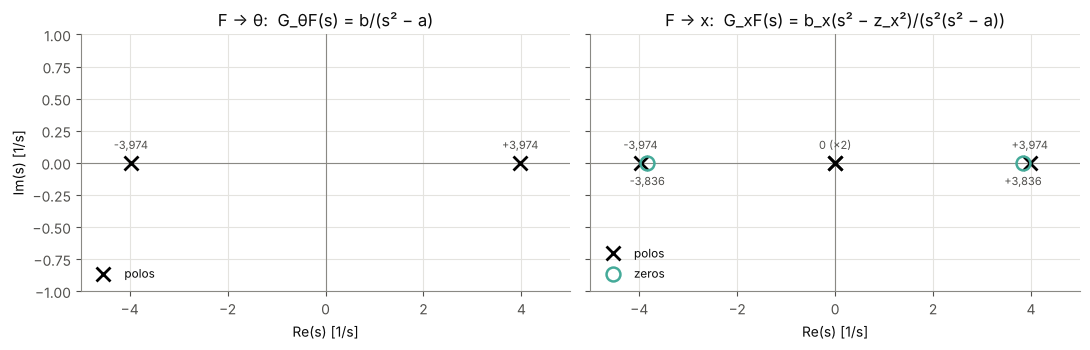

**Figura `pendulo_polos_zeros.png`.** Polos e zeros das funções de transferência contínuas do carro-pêndulo linearizado na origem, F → θ e F → x; A_c = (A_d − I)/dt e B_c = B_d/dt, com A_d e B_d da jacobiana do step(). Pares polo-zero coincidentes cancelados.

**Tabela `caracterizacao__pendulo_resposta_livre.csv`.** Resposta livre do carro-pêndulo (F = 0, θ₀ = 5°): instantes em que a diferença relativa em θ entre o modelo linearizado e o step() passa de 1 % e de 2 %, e o primeiro instante com |θ| ≥ 60°.

,tempo [s],θ step() [°],θ linearizado [°],diferença relativa em θ [%]
diferença em θ passa de 1 %,0.66,31.019,31.351,1.071
diferença em θ passa de 2 %,0.76,44.874,45.822,2.113
|θ| do step() passa de 60°,0.86,64.408,67.079,4.146


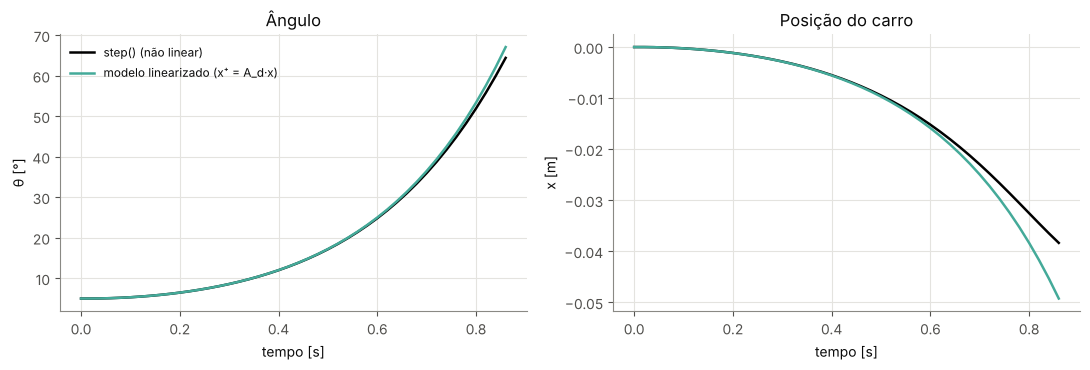

**Figura `pendulo_resposta_livre.png`.** Resposta livre do carro-pêndulo (F = 0) a partir de θ₀ = 5°, x₀ = 0: step() do professor (não linear) e modelo linearizado na origem, até |θ| = 60°.

In [5]:
# Funções de transferência, polos e zeros do modelo contínuo.
zeros_theta, polos_theta, ganho_theta = zeros_polos(Ac, Bc, 2)
zeros_x, polos_x, ganho_x = zeros_polos(Ac, Bc, 0)
polos_sistema = np.sort_complex(np.linalg.eigvals(Ac).astype(complex))
registrar_caracterizacao("pendulo/linearizacao", {"Ac": Ac, "Bc": Bc, "polos": polos_sistema, "G_thetaF_polos": polos_theta,
                                                   "G_thetaF_ganho": ganho_theta, "G_xF_polos": polos_x, "G_xF_zeros": zeros_x,
                                                   "G_xF_ganho": ganho_x, "erro_Ac": erro_Ac, "erro_Bc": erro_Bc,
                                                   "zero_x_formula": float(np.sqrt(a_haste - ax_haste * b_haste / bx_haste)),
                                                   "polo_formula": float(np.sqrt(a_haste))})
tabela_caracterizacao("pendulo_polos_zeros", pd.DataFrame({"polos [1/s]": [", ".join(f"{np.real(v):+.4f}" for v in polos_theta), ", ".join(f"{np.real(v):+.4f}" for v in polos_x)],
                             "zeros [1/s]": ["—", ", ".join(f"{np.real(v):+.4f}" for v in zeros_x)],
                             "ganho": [f"{ganho_theta:+.4f}", f"{ganho_x:+.4f}"]}, index=["G_θF(s)", "G_xF(s)"]),
               "Polos, zeros e ganho das funções de transferência contínuas do carro-pêndulo linearizado na origem.")
figura_pendulo_polos_zeros(polos_theta, zeros_theta, polos_x, zeros_x)

# Resposta livre a partir de 5°, até |θ| = 60°.
t_livre, X_livre_nl, X_livre_lin = resposta_livre(planta, Ad)
dif_rel_livre = np.abs(X_livre_lin[:, 2] - X_livre_nl[:, 2]) / np.abs(X_livre_nl[:, 2])
k1, k2 = int(np.argmax(dif_rel_livre > 0.01)), int(np.argmax(dif_rel_livre > 0.02))
assert dif_rel_livre[k1] > 0.01 and dif_rel_livre[k2] > 0.02   # as duas diferenças são atingidas antes de |θ| = 60°
registrar_caracterizacao("pendulo/resposta_livre", {
    "passos": len(t_livre) - 1, "tempo_final [s]": float(t_livre[-1]), "theta_final_nao_linear [°]": float(np.rad2deg(X_livre_nl[-1, 2])),
    "theta_final_linearizado [°]": float(np.rad2deg(X_livre_lin[-1, 2])), "diferenca_relativa_final_em_theta": float(dif_rel_livre[-1]),
    "theta_com_1pct_de_diferenca [°]": float(np.rad2deg(X_livre_nl[k1, 2])), "tempo_com_1pct_de_diferenca [s]": float(t_livre[k1]),
    "theta_com_2pct_de_diferenca [°]": float(np.rad2deg(X_livre_nl[k2, 2])), "tempo_com_2pct_de_diferenca [s]": float(t_livre[k2])})
tabela_caracterizacao("pendulo_resposta_livre", pd.DataFrame({"tempo [s]": [t_livre[k1], t_livre[k2], t_livre[-1]],
                             "θ step() [°]": np.rad2deg(X_livre_nl[[k1, k2, -1], 2]),
                             "θ linearizado [°]": np.rad2deg(X_livre_lin[[k1, k2, -1], 2]),
                             "diferença relativa em θ [%]": 100 * dif_rel_livre[[k1, k2, -1]]},
                            index=["diferença em θ passa de 1 %", "diferença em θ passa de 2 %", "|θ| do step() passa de 60°"]).round(3),
               "Resposta livre do carro-pêndulo (F = 0, θ₀ = 5°): instantes em que a diferença relativa em θ entre o modelo linearizado "
               "e o step() passa de 1 % e de 2 %, e o primeiro instante com |θ| ≥ 60°.")
figura_pendulo_resposta_livre(t_livre, X_livre_nl, X_livre_lin)

### 1.2 Infusão de fármaco

Modelo de um compartimento de Jadoon et al. (2017), sem atraso: a concentração C do fármaco no plasma sobe com a vazão u da bomba e cai por eliminação,

$$\frac{dC}{dt} = -\frac{\Omega}{V_1}\,C + \frac{u}{V_1},\qquad V_1 = 10\ \text{mL},\quad \Omega = 0{,}04\ \text{mL/s},\qquad G(s) = \frac{C(s)}{U(s)} = \frac{1/\Omega}{\tau s + 1} = \frac{25}{250\,s + 1},$$

com τ = V₁/Ω = 250 s e ganho estático 1/Ω = 25 s/mL. Atuador: 0 ≤ u ≤ u_max = 0,01 mL/s. Discretização exata com segurador de ordem zero (ZOH), Ts = 10 s:

$$C_{k+1} = A_d\,C_k + B_d\,u_k,\qquad A_d = e^{-T_s/\tau} = 0{,}960789,\quad B_d = \frac{1 - A_d}{\Omega} = 0{,}980264,\qquad G(z) = \frac{B_d}{z - A_d}.$$

Ponto de operação: C_ref = 0,15 e u_ss = Ω·C_ref = 0,006 mL/s. Custo no desvio e = C − C_ref, v = u − u_ss: Q = 1/0,01² e R = 1/u_max² (Bryson, com e_max = 0,01 e v_max = u_max). O `step` trabalha em float64.

`PlantaInfusao` tem a mesma interface do pêndulo. O que muda:

| atributo | infusão |
|---|---|
| `n_estados`, `u_min`, `u_max`, `dt` | 1; 0; 0,01 mL/s; 10 s |
| `x_eq`, `u_eq` | C_ref = 0,15; u_ss = 0,006 mL/s |
| `escala_x` | 0,15: a RN recebe (C − C_ref)/0,15 |
| `caixa_dados`, `caixa_imitacao` | C entre 0 e 0,25 |
| `cis_refinamento`, `T_refinamento` | C₀ = 0; 0,10; 0,18, com 100 passos |
| `pesos_cis_refinamento` | 1/((C₀ − C_ref)² + 1e-4) |
| `escala_perda_imitacao` | u_max: a perda da imitação é medida em frações de u_max |
| `tipo_saida` | sigmoide: u = u_max·σ(·) |
| `T_avaliacao` | 150 passos (1500 s) |
| `com_parametros(V1=, Omega=)` | V₁ e Ω multiplicados pelos fatores (C3) |
| `caiu`, `estabilizou` | `caiu` é sempre falso; `estabilizou`: \|C − C_ref\| ≤ 0,02·C_ref nos últimos 10 passos |

Verificações: A_d e B_d contra a integração numérica da EDO (`solve_ivp`), os tempos do artigo (τ·ln 9 = 549,3 s e τ·ln 50 = 978,0 s) e `step_tf` contra `step`.

Figuras: resposta ao degrau u = u_ss a partir de C = 0, contínua, $C(t) = C_{ref}(1 - e^{-t/\tau})$, com as amostras do `step()`; e o diagrama de Bode de G(s), com o polo em 1/τ = 0,004 rad/s e a frequência de Nyquist π/Ts = 0,314 rad/s.

In [6]:
class PlantaInfusao:
    """Infusão de fármaco (Jadoon et al., 2017, sem atraso), na mesma interface do pêndulo, com ZOH exato."""

    nome = "infusao"

    def __init__(self, V1=10.0, Omega=0.04, Ts=10.0, u_max=0.01, C_ref=0.15):
        self.parametros = dict(V1=V1, Omega=Omega, Ts=Ts, u_max=u_max, C_ref=C_ref)
        self.fatores = {}
        self.V1, self.Omega = V1, Omega
        self.lam = Omega / V1                    # λ = Ω/V₁ [1/s]
        self.tau = 1.0 / self.lam                # τ = 250 s
        self.ganho = 1.0 / Omega                 # ganho estático: 25 s/mL
        self.Ad = float(np.exp(-self.lam * Ts))  # ZOH exato
        self.Bd = float((1.0 - self.Ad) / Omega)
        self.n_estados = 1
        self.nomes_estados = ["C"]
        self.unidades_estados = ["—"]
        self.dt = Ts
        self.u_min, self.u_max = 0.0, u_max      # a bomba não retira fármaco
        self.nome_u, self.unidade_u = "u", "mL/s"
        self.unidade_esforco = "mL²/s"
        self.C_ref = C_ref
        self.x_eq = np.array([C_ref])
        self.u_eq = Omega * C_ref                # u_ss desta planta (numa planta perturbada, o u_ss dela)
        self.T_avaliacao = 150

        self.escala_x = np.array([0.15])         # escala da entrada da RN
        self.escala_u = u_max
        self.Q = np.array([[1.0 / 0.01**2]])     # Bryson: e_max = 0,01
        self.R = np.array([[1.0 / u_max**2]])    # Bryson: v_max = u_max
        self.Q_parcial = None                    # sem "J sem x" na infusão

        self.caixa_dados = np.array([0.125])     # C₀ dos rollouts de identificação entre 0 e 0,25
        self.centro_dados = np.array([0.125])
        self.caixa_imitacao = np.array([0.125])  # C das 8000 amostras de imitação entre 0 e 0,25
        self.centro_imitacao = np.array([0.125])
        self.cis_refinamento = np.array([[0.0], [0.10], [0.18]], dtype=np.float32)
        self.T_refinamento = 100
        self.pesos_cis_refinamento = (1.0 / ((np.array([0.0, 0.10, 0.18]) - C_ref) ** 2 + 1e-4)).astype(np.float32)
        self.escala_perda_imitacao = u_max
        self.tipo_saida = "sigmoide"

        self.janela_estab = 10                   # últimos 10 passos (100 s)
        self.tol_C = 0.02 * C_ref                # |C − C_ref| ≤ 2 % de C_ref

    def step(self, x, u):
        C = float(np.asarray(x, dtype=np.float64).reshape(-1)[0])
        u = float(np.clip(u, self.u_min, self.u_max))
        return np.array([self.Ad * C + self.Bd * u])

    def step_tf(self, estado, u):
        """O mesmo passo em TensorFlow, vetorizado e em float32."""
        return self.Ad * estado + self.Bd * tf.clip_by_value(u, self.u_min, self.u_max)

    def com_parametros(self, **fatores):
        """A mesma planta com V1 e/ou Omega multiplicados pelos fatores dados (C3)."""
        novos = dict(self.parametros)
        for chave, fator in fatores.items():
            novos[chave] *= fator
        nova = PlantaInfusao(**novos)
        nova.fatores = dict(fatores)
        return nova

    def caiu(self, x):
        return False

    def estabilizou(self, X):
        if len(X) < self.janela_estab + 1:
            return False
        return bool(np.all(np.abs(X[-self.janela_estab:, 0] - self.C_ref) <= self.tol_C))

    def __repr__(self):
        return (f"PlantaInfusao(V1={self.V1} mL, Ω={self.Omega} mL/s, τ={self.tau:.1f} s, Ts={self.dt} s, "
                f"0 ≤ u ≤ {self.u_max} mL/s, C_ref={self.C_ref}, u_ss={self.u_eq:.4f} mL/s)")


def integrar_edo(planta, C0, u):
    """C ao fim de Ts, com u constante, pela integração numérica da EDO (DOP853)."""
    sol = scipy.integrate.solve_ivp(lambda t, C: -planta.lam * C + u / planta.V1, (0.0, planta.dt), [C0], method="DOP853", rtol=1e-13, atol=1e-15)
    return float(sol.y[0, -1])


def figura_infusao_degrau(planta, t, C_continua, t_amostras, C_amostras):
    fig, eixo = plt.subplots(figsize=(9, 4.2))
    eixo.plot(t, C_continua, "-", color=COR_AUX["preto"], label="C(t) = C_ref·(1 − e^(−t/τ)), contínua")
    eixo.plot(t_amostras, C_amostras, "o", ms=3.5, mfc="none", color=COR_AUX["destaque 1"], label="amostras do step() (ZOH, Ts = 10 s)")
    eixo.axvline(planta.tau, color=COR_AUX["destaque 2"], ls=":", lw=1.3, label="t = τ = 250 s")
    eixo.axhline(planta.C_ref * (1 - np.exp(-1)), color=COR_AUX["cinza escuro"], ls="--", lw=1.0, label="63,2 % de C_ref")
    eixo.axhline(planta.C_ref, color=COR_AUX["cinza"], lw=0.8)
    eixo.set(xlabel="tempo [s]", ylabel="C (concentração, adimensional)", xlim=(0, 1500),
             title="Infusão em malha aberta: u = u_ss = 0,006 mL/s a partir de C = 0")
    eixo.legend(fontsize=8.5, loc="lower right")
    plt.tight_layout()
    salvar_figura(fig, "infusao_degrau_malha_aberta",
                  "Resposta da infusão em malha aberta a u = u_ss = 0,006 mL/s, a partir de C = 0, por 1500 s: solução contínua "
                  "C(t) = C_ref·(1 − e^(−t/τ)) e amostras do step() com ZOH (Ts = 10 s); τ = 250 s e 63,2 % de C_ref marcados.")


def figura_infusao_bode(w, G, w_polo, w_nyquist):
    fig, eixos = plt.subplots(2, 1, figsize=(8.5, 6), sharex=True)
    eixos[0].semilogx(w, 20 * np.log10(np.abs(G)), color=COR_AUX["preto"], label="|G(jω)|")
    eixos[1].semilogx(w, np.degrees(np.angle(G)), color=COR_AUX["preto"], label="∠G(jω)")
    for eixo in eixos:
        eixo.axvline(w_polo, color=COR_AUX["destaque 1"], ls="--", lw=1.2, label="polo: 1/τ = 0,004 rad/s")
        eixo.axvline(w_nyquist, color=COR_AUX["destaque 2"], ls=":", lw=1.4, label="Nyquist: π/Ts = 0,314 rad/s")
    eixos[0].set(ylabel="módulo [dB]", title="Bode de G(s) = 25/(250 s + 1)")
    eixos[1].set(ylabel="fase [°]", xlabel="ω [rad/s]", yticks=[0, -45, -90])
    eixos[0].legend(fontsize=8.5)
    plt.tight_layout()
    salvar_figura(fig, "infusao_bode",
                  "Diagrama de Bode da infusão, G(s) = 25/(250 s + 1): módulo e fase, com o polo em 1/τ = 0,004 rad/s e a frequência "
                  "de Nyquist π/Ts = 0,314 rad/s marcados.")

In [7]:
planta_inf = PlantaInfusao()

# A_d e B_d contra a integração numérica da EDO durante Ts, com u constante.
Ad_num = integrar_edo(planta_inf, 1.0, 0.0)   # resposta livre a partir de C = 1: A_d
Bd_num = integrar_edo(planta_inf, 0.0, 1.0)   # resposta a u = 1 a partir de C = 0: B_d
erro_Ad, erro_Bd = abs(Ad_num / planta_inf.Ad - 1), abs(Bd_num / planta_inf.Bd - 1)
t_10_90 = planta_inf.tau * np.log(9)     # tempo de subida de 10 % a 90 % de uma planta de 1ª ordem
t_2 = planta_inf.tau * np.log(50)        # tempo de acomodação a 2 %
tabela_caracterizacao("infusao_parametros", pd.DataFrame({"valor": [planta_inf.tau, planta_inf.ganho, planta_inf.Ad, planta_inf.Bd, Ad_num, Bd_num, t_10_90, t_2, planta_inf.u_eq]},
                            index=["τ [s]", "ganho estático [s/mL]", "A_d (fórmula)", "B_d (fórmula)", "A_d (solve_ivp)", "B_d (solve_ivp)",
                                   "τ·ln 9 [s]", "τ·ln 50 [s]", "u_ss [mL/s]"]),
               "Parâmetros da infusão: constante de tempo, ganho, discretização ZOH (fórmula e integração numérica) e tempos de 1ª ordem.",
               opcoes={"display.float_format": lambda v: f"{v:.10g}"})
verificar("infusao-zoh — infusão: A_d e B_d = integração numérica da EDO (solve_ivp), a 1e-8 relativo", max(erro_Ad, erro_Bd) < 1e-8,
          f"diferença relativa em A_d {erro_Ad:.1e}, em B_d {erro_Bd:.1e}", tol="1e-8 relativo")
verificar("infusao-artigo — infusão: τ·ln 9 = 549,3 s, τ·ln 50 = 978,0 s e ganho 25, como em Jadoon et al. (2017)",
          abs(t_10_90 - 549.3) < 0.05 and abs(t_2 - 978.0) < 0.05 and abs(planta_inf.ganho - 25) < 1e-12,
          f"{t_10_90:.2f} s, {t_2:.2f} s, {planta_inf.ganho}", tol="0,05 s nos tempos; 1e-12 no ganho")

# Planta exata em TF = step, em 1000 estados e vazões (de −0,005 a 0,015 mL/s, para conferir o recorte em [0, u_max]).
estados_inf_exata = np.random.default_rng(2024).uniform(0.0, 0.3, (1000, 1)).astype(np.float32)
vazoes_inf_exata = np.random.default_rng(2025).uniform(-0.005, 0.015, 1000)
pior_inf_exata, ok_inf_exata = conferir_step_tf(planta_inf, estados_inf_exata, vazoes_inf_exata)
verificar("planta-exata-infusao — step_tf (TensorFlow, float32) = step, infusão, 1000 estados e vazões, a 1e-5", ok_inf_exata,
          f"maior diferença {pior_inf_exata:.1e}", tol="1e-5")
registrar_numeros("infusao/projeto/planta", dict(Ad=planta_inf.Ad, Bd=planta_inf.Bd, Ad_solve_ivp=Ad_num, Bd_solve_ivp=Bd_num,
                                                t_10_90=t_10_90, t_2=t_2, ganho=planta_inf.ganho, tau=planta_inf.tau))

**Tabela `caracterizacao__infusao_parametros.csv`.** Parâmetros da infusão: constante de tempo, ganho, discretização ZOH (fórmula e integração numérica) e tempos de 1ª ordem.

,valor
τ [s],250
ganho estático [s/mL],25
A_d (fórmula),0.9607894392
B_d (fórmula),0.9802640212
A_d (solve_ivp),0.9607894392
B_d (solve_ivp),0.9802640212
τ·ln 9 [s],549.3061443
τ·ln 50 [s],978.0057514
u_ss [mL/s],0.006


infusao-zoh: OK | diferença relativa em A_d 2.2e-16, em B_d 1.3e-15 | tolerância: 1e-8 relativo
infusao-artigo: OK | 549.31 s, 978.01 s, 25.0 | tolerância: 0,05 s nos tempos; 1e-12 no ganho
planta-exata-infusao: OK | maior diferença 2.6e-08 | tolerância: 1e-5


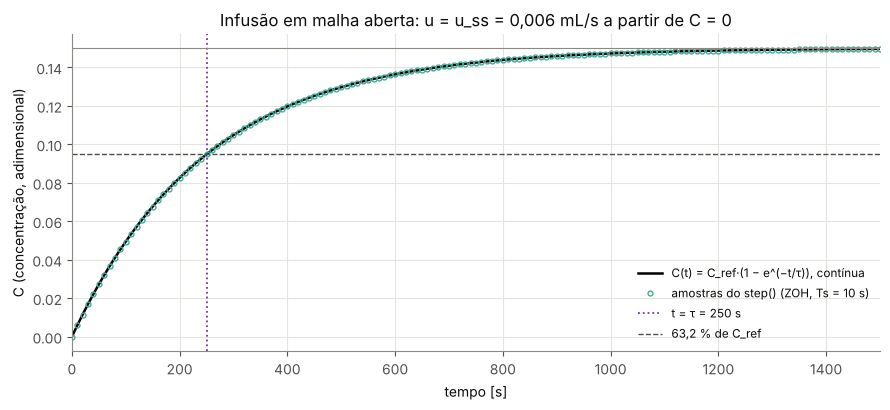

**Figura `infusao_degrau_malha_aberta.png`.** Resposta da infusão em malha aberta a u = u_ss = 0,006 mL/s, a partir de C = 0, por 1500 s: solução contínua C(t) = C_ref·(1 − e^(−t/τ)) e amostras do step() com ZOH (Ts = 10 s); τ = 250 s e 63,2 % de C_ref marcados.

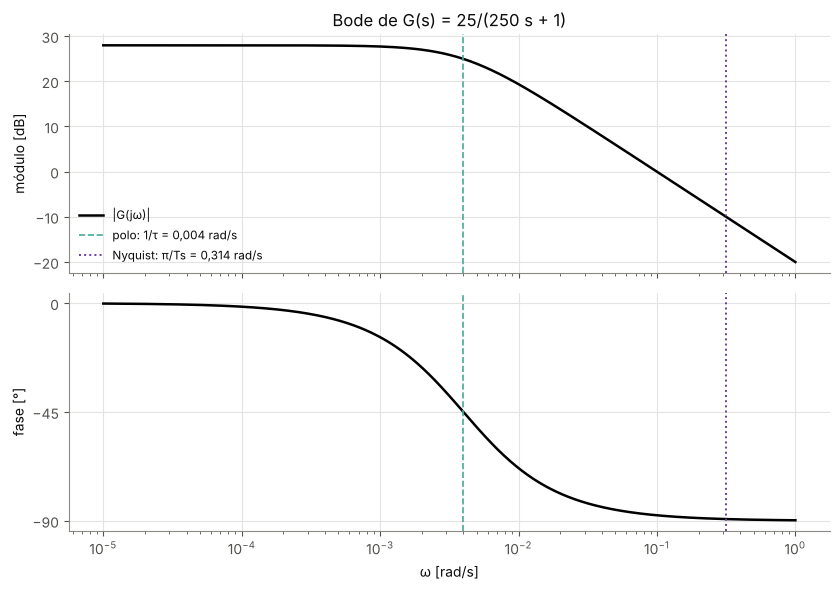

**Figura `infusao_bode.png`.** Diagrama de Bode da infusão, G(s) = 25/(250 s + 1): módulo e fase, com o polo em 1/τ = 0,004 rad/s e a frequência de Nyquist π/Ts = 0,314 rad/s marcados.

In [8]:
# Degrau em malha aberta: u = u_ss a partir de C = 0, por 1500 s.
t_cont = np.linspace(0.0, 1500.0, 1501)
C_cont = planta_inf.C_ref * (1 - np.exp(-t_cont / planta_inf.tau))
C_amostras = [np.array([0.0])]
for _ in range(planta_inf.T_avaliacao):
    C_amostras.append(planta_inf.step(C_amostras[-1], planta_inf.u_eq))
C_amostras = np.array(C_amostras)[:, 0]
t_amostras = np.arange(len(C_amostras)) * planta_inf.dt
C_amostras_formula = planta_inf.C_ref * (1 - np.exp(-t_amostras / planta_inf.tau))
k_tau = int(round(planta_inf.tau / planta_inf.dt))
registrar_caracterizacao("infusao/degrau", {"C_em_tau_amostra": C_amostras[k_tau], "C_em_tau_formula": planta_inf.C_ref * (1 - np.exp(-1)),
                                            "max_dif_amostras_continua": float(np.max(np.abs(C_amostras - C_amostras_formula))),
                                            "C_final_1500s": C_amostras[-1]})
figura_infusao_degrau(planta_inf, t_cont, C_cont, t_amostras, C_amostras)

# Bode de G(s) = (1/Ω)/(τs + 1).
w_bode = np.logspace(-5, 0, 600)
G_bode = planta_inf.ganho / (planta_inf.tau * 1j * w_bode + 1)
w_polo, w_nyquist = 1 / planta_inf.tau, np.pi / planta_inf.dt
G_polo = planta_inf.ganho / (planta_inf.tau * 1j * w_polo + 1)
G_nyq = planta_inf.ganho / (planta_inf.tau * 1j * w_nyquist + 1)
registrar_caracterizacao("infusao/bode", {"ganho_estatico [dB]": 20 * np.log10(planta_inf.ganho), "polo [rad·s⁻¹]": w_polo,
                                          "nyquist [rad·s⁻¹]": w_nyquist, "modulo_no_polo [dB]": 20 * np.log10(abs(G_polo)),
                                          "fase_no_polo [°]": np.degrees(np.angle(G_polo)), "modulo_em_nyquist [dB]": 20 * np.log10(abs(G_nyq)),
                                          "fase_em_nyquist [°]": np.degrees(np.angle(G_nyq))})
figura_infusao_bode(w_bode, G_bode, w_polo, w_nyquist)

### 1.3 Simulação e métricas

`simular` simula a planta real com qualquer controlador: T = 600 passos (12 s) no pêndulo e T = 150 passos (1500 s) na infusão, a partir de uma condição inicial. A simulação para se o pêndulo cai (|θ| ≥ 90°) ou se algum número vira NaN ou infinito; a realização fica marcada como `caiu` ou `divergiu`, e as métricas numéricas dela ficam NaN.

| métrica | definição |
|---|---|
| **J** | $J = \frac1T\sum_{k=1}^{T}\left(\tilde x_k^\top Q\,\tilde x_k + R\,\tilde u_{k-1}^2\right)$, com $\tilde x = x - x_{eq}$ e $\tilde u = u - u_{eq}$ (pêndulo: Q = diag(6, 1, 80, 4), R = 0,08; infusão: Q = R = 1e4) |
| J sem x (pêndulo) | o mesmo, com o peso de x zerado |
| acomodação | primeiro instante a partir do qual a variável (θ ou C) fica, até o fim, dentro de 2 % da amplitude inicial em torno do alvo; NaN se não acomoda |
| pico pós-cruzamento (pêndulo) | maior \|θ\| depois do primeiro cruzamento de θ = 0, em graus e em % de θ₀ |
| Mp (infusão) | sobressinal no sentido do movimento, em % de \|C_ref − C₀\| |
| valores finais | θ, x e ẋ (pêndulo), C e erro em % de C_ref (infusão), no fim do horizonte |
| ITAE | $\sum_k t_k\,\lvert e_k\rvert\,\Delta t$, em θ (pêndulo) ou em C − C_ref (infusão) |
| esforço | $\sum_k u_k^2\,\Delta t$ |
| % saturado | fração dos passos com u a 1 % de um limite (pêndulo: \|u\| ≥ 19,8 N; infusão: u ≤ 1 % ou ≥ 99 % de u_max, também separados) |
| max \|x\| e `dentro_trilho` (pêndulo) | maior afastamento do carro; dentro do trilho se ≤ 2,4 m |
| `estabilizou` | pêndulo: \|θ\| < 1° e \|x\| < 5 cm no último 1 s; infusão: \|C − C_ref\| ≤ 2 % de C_ref nos últimos 10 passos |

`tempo_por_passo` mede o tempo da chamada do controlador com `time.perf_counter`, ao longo de simulações completas (a primeira é descartada): média, percentil 99 e pior caso.

Condições iniciais dos cenários: C1, θ₀ = 15° e C₀ = 0,14; C2, θ₀ de 5° a 60° de 5 em 5 e C₀ = 0; 0,05; 0,10; 0,18; 0,22; C3, θ₀ = 15° e 30° e C₀ = 0,14 e 0; C4, θ₀ de 5° a 40°; otimalidade do LQR da infusão, C₀ = 0,145. Carro parado em x₀ = 0.

In [9]:
def simular(planta, politica, x0, T=None):
    """Simula a planta real com um controlador qualquer. Devolve X (k = 0..T), U (k = 0..T−1) e as marcas de falha."""
    T = planta.T_avaliacao if T is None else T
    if hasattr(politica, "reset"):
        politica.reset()
    n = planta.n_estados
    X = np.full((T + 1, n), np.nan)
    U = np.full(T, np.nan)
    estado = np.asarray(x0, dtype=np.float32)   # estado inicial em float32, como no notebook do professor
    X[0] = estado
    caiu = divergiu = False
    k_fim = T
    for k in range(T):
        u = float(politica(estado))
        if not np.isfinite(u):
            divergiu, k_fim = True, k
            break
        u = min(max(u, planta.u_min), planta.u_max)   # saturação do atuador; o valor guardado é o aplicado
        estado = planta.step(estado, u)
        U[k] = u
        X[k + 1] = estado
        if not np.all(np.isfinite(estado)):
            divergiu, k_fim = True, k + 1
            break
        if planta.caiu(estado):
            caiu, k_fim = True, k + 1
            break
    return dict(X=X[:k_fim + 1], U=U[:k_fim], caiu=caiu, divergiu=divergiu, T=T)


def metricas_pendulo(planta, X, U):
    dt = planta.dt
    th = X[:, 2]
    x = X[:, 0]
    t = np.arange(len(X)) * dt
    th0 = th[0]
    faixa = 0.02 * abs(th0)
    fora = np.flatnonzero(np.abs(th) > faixa)
    if th0 == 0:
        acomodacao = np.nan
    elif len(fora) == 0:
        acomodacao = 0.0
    elif fora[-1] == len(th) - 1:
        acomodacao = np.nan      # ainda fora da faixa no último instante
    else:
        acomodacao = (fora[-1] + 1) * dt
    cruz = np.flatnonzero(np.sign(th[1:]) != np.sign(th0)) + 1 if th0 != 0 else np.array([], int)
    pico = float(np.max(np.abs(th[cruz[0]:]))) if len(cruz) else 0.0
    max_x = float(np.max(np.abs(x)))
    return {
        "acomodação θ [s]": acomodacao,
        "pico pós-cruzamento [°]": np.rad2deg(pico),
        "pico [% de θ₀]": 100 * pico / abs(th0) if th0 != 0 else np.nan,
        "θ final [°]": float(np.rad2deg(th[-1])),
        "x final [m]": float(x[-1]),
        "ẋ final [m/s]": float(X[-1, 1]),
        "ITAE θ [rad·s²]": float(np.sum(t[1:] * np.abs(th[1:])) * dt),
        "max |x| [m]": max_x,
        "estabilizou": planta.estabilizou(X),
        "dentro_trilho": max_x <= planta.trilho,
    }


def metricas_infusao(planta, X, U):
    dt = planta.dt
    C = X[:, 0]
    t = np.arange(len(X)) * dt
    C0 = C[0]
    amp = abs(planta.C_ref - C0)
    erro = C - planta.C_ref
    fora = np.flatnonzero(np.abs(erro) > 0.02 * amp)
    if amp == 0:
        acomodacao = np.nan
    elif len(fora) == 0:
        acomodacao = 0.0
    elif fora[-1] == len(C) - 1:
        acomodacao = np.nan      # ainda fora da faixa no fim
    else:
        acomodacao = (fora[-1] + 1) * dt
    # Sobressinal no sentido do movimento: para cima, se C₀ < C_ref; para baixo, se C₀ > C_ref.
    sentido = np.sign(planta.C_ref - C0)
    mp = 100 * max(0.0, float(np.max(sentido * erro[1:]))) / amp if amp > 0 else np.nan
    margem = 0.01 * planta.u_max
    return {
        "acomodação C [s]": acomodacao,
        "Mp [%]": mp,
        "C final": float(C[-1]),
        "erro final [% de C_ref]": 100 * float(erro[-1]) / planta.C_ref,
        "ITAE C [s²]": float(np.sum(t[1:] * np.abs(erro[1:])) * dt),
        "% em 0 (≤ 1 % de u_max)": 100 * float(np.mean(U <= planta.u_min + margem)),
        "% em u_max (≥ 99 %)": 100 * float(np.mean(U >= planta.u_max - margem)),
        "estabilizou": planta.estabilizou(X),
    }


# Função de métricas específicas e lista das métricas numéricas de cada planta.
METRICAS_ESPECIFICAS = {"pendulo": metricas_pendulo, "infusao": metricas_infusao}
CHAVES_NUMERICAS = ["J", "J sem x", "acomodação θ [s]", "pico pós-cruzamento [°]", "pico [% de θ₀]", "θ final [°]", "x final [m]",
                    "ẋ final [m/s]", "ITAE θ [rad·s²]", "Σu²·dt [N²·s]", "% saturado", "max |x| [m]"]
CHAVES_NUMERICAS_INFUSAO = ["J", "acomodação C [s]", "Mp [%]", "C final", "erro final [% de C_ref]", "ITAE C [s²]", "Σu²·dt [mL²/s]",
                            "% saturado", "% em 0 (≤ 1 % de u_max)", "% em u_max (≥ 99 %)"]
CHAVES_POR_PLANTA = {"pendulo": CHAVES_NUMERICAS, "infusao": CHAVES_NUMERICAS_INFUSAO}


def metricas(planta, sim):
    base = {"caiu": sim["caiu"], "divergiu": sim["divergiu"]}
    if sim["caiu"] or sim["divergiu"]:
        # Realização que caiu ou divergiu: todas as métricas numéricas ficam NaN.
        base.update({chave: np.nan for chave in CHAVES_POR_PLANTA[planta.nome]})
        base.update({"estabilizou": False, "dentro_trilho": np.nan})
        return base
    X, U, T = sim["X"], sim["U"], sim["T"]
    Xd = X[1:] - planta.x_eq
    Ud = U - planta.u_eq
    r = float(planta.R[0, 0])
    base["J"] = float(np.mean(np.sum((Xd @ planta.Q) * Xd, axis=1) + r * Ud**2))
    if planta.Q_parcial is not None:
        base["J sem x"] = float(np.mean(np.sum((Xd @ planta.Q_parcial) * Xd, axis=1) + r * Ud**2))
    # Limiar de saturação: 1 % do maior |limite| (0,2 N no pêndulo; 1 % de u_max na infusão).
    margem = 0.01 * max(abs(planta.u_min), abs(planta.u_max))
    saturado = (U >= planta.u_max - margem) | (U <= planta.u_min + margem)
    base.update({f"Σu²·dt [{planta.unidade_esforco}]": float(np.sum(U**2) * planta.dt), "% saturado": 100 * float(np.mean(saturado))})
    base.update(METRICAS_ESPECIFICAS[planta.nome](planta, X, U))
    return base


def estado_inicial_pendulo(theta0_graus, x0=0.0):
    return [x0, 0.0, np.deg2rad(theta0_graus), 0.0]


def estado_inicial_infusao(C0):
    return [C0]


def tempo_por_passo(planta, politica, x0, repeticoes=5, T=None):
    """Tempo da chamada do controlador, em µs, ao longo de simulações completas (a 1ª é aquecimento e é descartada)."""
    T = planta.T_avaliacao if T is None else T
    tempos = []
    for rep in range(repeticoes + 1):
        if hasattr(politica, "reset"):
            politica.reset()
        s = np.asarray(x0, dtype=np.float32)
        for _ in range(T):
            t0 = time.perf_counter()
            u = politica(s)
            t1 = time.perf_counter()
            if rep > 0:
                tempos.append(t1 - t0)
            s = planta.step(s, u)
    tempos = np.array(tempos) * 1e6
    return dict(media=float(tempos.mean()), p99=float(np.percentile(tempos, 99)), pior=float(tempos.max()), chamadas=len(tempos))


# Condições iniciais dos cenários.
C1_ANGULO = 15                       # C1 do pêndulo: θ₀ = 15°
ANGULOS_C2 = list(range(5, 61, 5))   # C2 do pêndulo: θ₀ de 5° a 60°
ANGULOS_C4 = list(range(5, 41, 5))   # C4: θ₀ de 5° a 40°
CONDICOES_C3_PEND = [15, 30]         # C3 do pêndulo
C1_INF = 0.14                        # C1 da infusão: C₀ = 0,14
C2_INF = [0.0, 0.05, 0.10, 0.18, 0.22]
CONDS_INF = sorted(C2_INF + [C1_INF])
C0_OTIM = 0.145                      # otimalidade do LQR da infusão
CONDICOES_C3_INF = [0.14, 0.0]       # C3 da infusão

## 2. Controladores clássicos

### 2.1 LQR

LQR discreto: o ganho K que minimiza $\sum_k \left(\tilde x_k^\top Q\,\tilde x_k + R\,\tilde u_k^2\right)$ no modelo linear $\tilde x_{k+1} = A\,\tilde x_k + B\,\tilde u_k$, com a lei $\tilde u = -K\tilde x$:

$$K = (R + B^\top P B)^{-1} B^\top P A,\qquad P = A^\top P A - A^\top P B\,(R + B^\top P B)^{-1} B^\top P A + Q.$$

- `solve_discrete_lqr`, `cartpole_lqr_gain` e `state_feedback_control` são as funções do notebook do professor, sem alteração. `solve_discrete_lqr` itera a equação de Riccati 500 vezes, a partir de P = Q; o resultado é conferido contra `scipy.linalg.solve_discrete_are`.
- **LQR correto (pêndulo):** A e B da jacobiana do `step()` (1.1), Q = diag(6, 1, 80, 4), R = 0,08; a lei é u = −Kx, recortada em ±20 N (`PoliticaLQR`).
- **LQR aproximado (pêndulo):** `cartpole_lqr_gain` do professor, com A e B do modelo de massa pontual discretizado por Euler.
- **P_terminal:** a solução P da equação de Riccati (scipy) com A e B corretos; o refinamento aceita o custo terminal $x_T^\top P\,x_T/T$, que nenhuma variante da RN usa.
- **LQR da infusão:** A_d e B_d da mesma `jacobiana_numerica`, em torno de (C_ref, u_ss), Q = R = 1e4, e a lei $u = \mathrm{clip}\big(u_{ss} - K\,(C - C_{ref}),\ 0,\ u_{max}\big)$.
- Polos de malha fechada: autovalores z de A − BK, levados ao tempo contínuo por s = ln(z)/Ts.

In [10]:
# Código do professor, sem alteração.
def solve_discrete_lqr(A, B, Q, R, iterations=500):
    P = Q.copy()

    for _ in range(iterations):
        bt_p = B.T @ P
        P = A.T @ P @ A - A.T @ P @ B @ np.linalg.inv(R + bt_p @ B) @ bt_p @ A + Q

    return np.linalg.inv(R + B.T @ P @ B) @ (B.T @ P @ A)


def cartpole_lqr_gain(plant):
    M = plant.M
    m = plant.m
    l = plant.l
    g = plant.g
    dt = plant.dt

    A_c = np.asarray(
        [
            [0.0, 1.0, 0.0, 0.0],
            [0.0, 0.0, -(m * g) / M, 0.0],
            [0.0, 0.0, 0.0, 1.0],
            [0.0, 0.0, g * (M + m) / (l * M), 0.0],
        ],
        dtype=np.float64,
    )
    B_c = np.asarray([[0.0], [1.0 / M], [0.0], [-1.0 / (l * M)]], dtype=np.float64)

    A_d = np.eye(4) + dt * A_c
    B_d = dt * B_c
    Q = np.diag([6.0, 1.0, 80.0, 4.0])
    R = np.asarray([[0.08]])

    return solve_discrete_lqr(A_d, B_d, Q, R)


def state_feedback_control(state, K, force_limit):
    """Linear full-state feedback: u = -Kx."""
    force = -float((K @ np.asarray(state, dtype=np.float64).reshape(4, 1))[0, 0])
    return np.clip(force, -force_limit, force_limit)

In [11]:
def rotulo_lqr(planta, K, estado):
    """state_feedback_control do professor para n estados: u = u_eq − K·(x − x_eq), recortado nos limites."""
    desvio = np.asarray(estado, dtype=np.float64) - planta.x_eq
    u = planta.u_eq - (np.asarray(K, dtype=np.float64).reshape(1, -1) @ desvio)[0]
    return float(np.clip(u, planta.u_min, planta.u_max))


class PoliticaLQR:
    """u = u_eq − K·(x − x_eq), saturado. É o LQR usado em todas as simulações."""

    def __init__(self, planta, K):
        self.planta = planta
        self.K = np.asarray(K, dtype=np.float64).reshape(1, -1)

    def __call__(self, estado):
        return rotulo_lqr(self.planta, self.K, estado)


def polos(A_mf):
    """Autovalores z de uma matriz de malha fechada do pêndulo e os polos contínuos s = ln(z)/dt."""
    z = np.linalg.eigvals(A_mf)
    s = np.log(z.astype(complex)) / dt
    return z, s


def figura_LQR_polos(polos_ma_pend, s_correto, s_aproximado, polo_ma_inf, s_inf):
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
    eixo = eixos[0]
    eixo.plot(np.real(polos_ma_pend), np.imag(polos_ma_pend), "x", ms=10, mew=2, color=COR_AUX["preto"], label="malha aberta (modelo contínuo)")
    eixo.plot(np.real(s_correto), np.imag(s_correto), "o", ms=7, color=COR["LQR correto"], label="malha fechada, LQR correto")
    eixo.plot(np.real(s_aproximado), np.imag(s_aproximado), "s", ms=7, mfc="none", mew=1.6, color=COR["LQR aproximado"],
              label="malha fechada, LQR aproximado")
    eixo.set(title="Carro-pêndulo", xlabel="Re(s) [1/s]", ylabel="Im(s) [1/s]")
    eixo = eixos[1]
    eixo.plot([np.real(polo_ma_inf)], [0.0], "x", ms=10, mew=2, color=COR_AUX["preto"], label="malha aberta: −1/τ")
    eixo.plot(np.real(s_inf), np.imag(s_inf), "o", ms=7, color=COR["LQR"], label="malha fechada, LQR")
    eixo.set(title="Infusão", xlabel="Re(s) [1/s]", ylabel="Im(s) [1/s]", ylim=(-0.05, 0.05))
    for eixo in eixos:
        eixo.axhline(0, color=COR_AUX["cinza"], lw=0.8)
        eixo.axvline(0, color=COR_AUX["cinza"], lw=0.8)
        eixo.legend(fontsize=8.5)
    plt.tight_layout()
    salvar_figura(fig, "LQR_polos",
                  "Polos de malha aberta e de malha fechada com o LQR, em tempo contínuo: carro-pêndulo com o LQR correto e com o LQR aproximado "
                  "(avaliados na linearização correta) e infusão. Malha aberta: autovalores do modelo contínuo (pêndulo: A_c de 1.1; "
                  "infusão: −1/τ). Malha fechada: autovalores z de A_d − B_d·K, levados ao tempo contínuo por s = ln(z)/Ts.")

lqr-correto-estavel: OK | maior |z| = 0.97511 | tolerância: maior |z| < 1
lqr-aproximado-estavel: OK | maior |z| = 0.97634 | tolerância: maior |z| < 1
riccati-professor-scipy: OK | diferença relativa em K: 4.8e-11 | tolerância: 1e-6 relativo
infusao-lqr: OK | polo 0.3817; diferença relativa em K 2.3e-15; jacobiana × fórmula: 9.1e-14, 2.8e-15 | tolerância: |z| < 1; 1e-6 relativo


**Tabela `caracterizacao__LQR_ganhos_e_polos.csv`.** Ganhos do LQR e polos de malha fechada: carro-pêndulo com o LQR correto e com o LQR aproximado (avaliados na linearização correta) e infusão.

,K,"polos de malha fechada, s = ln(z)/Ts [1/s]",maior |z|
LQR correto (pêndulo),"[-7.230, -10.000, -71.747, -18.256]","-11.375+0.000j, -4.476+0.000j, -1.260-0.925j, -1.260+0.925j",0.9751
LQR aproximado (pêndulo),"[-6.960, -9.325, -65.472, -14.644]","-4.964-5.268j, -4.964+5.268j, -1.197-0.851j, -1.197+0.851j",0.9763
LQR (infusão),0.5908,-0.0963,0.3817


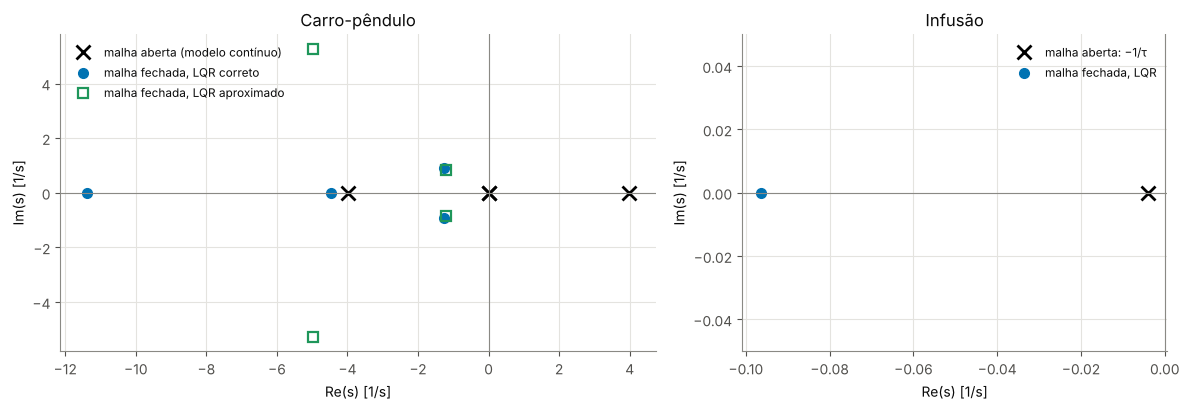

**Figura `LQR_polos.png`.** Polos de malha aberta e de malha fechada com o LQR, em tempo contínuo: carro-pêndulo com o LQR correto e com o LQR aproximado (avaliados na linearização correta) e infusão. Malha aberta: autovalores do modelo contínuo (pêndulo: A_c de 1.1; infusão: −1/τ). Malha fechada: autovalores z de A_d − B_d·K, levados ao tempo contínuo por s = ln(z)/Ts.

In [12]:
Q, R = planta.Q, planta.R

K_correto = solve_discrete_lqr(Ad, Bd, Q, R)                 # Riccati do professor com a linearização do step()
P_scipy = scipy.linalg.solve_discrete_are(Ad, Bd, Q, R)
K_scipy = np.linalg.solve(R + Bd.T @ P_scipy @ Bd, Bd.T @ P_scipy @ Ad)
K_aproximado = cartpole_lqr_gain(planta.nucleo)              # função do professor (massa pontual)
P_terminal = P_scipy                                         # P da Riccati (o custo terminal opcional do refinamento)

z_c, s_c = polos(Ad - Bd @ K_correto)
z_a, s_a = polos(Ad - Bd @ K_aproximado)   # o LQR aproximado avaliado na linearização correta

dif_K = np.max(np.abs(K_correto - K_scipy)) / np.max(np.abs(K_scipy))
verificar("lqr-correto-estavel — LQR correto: A − BK com todos os |z| < 1", np.max(np.abs(z_c)) < 1, f"maior |z| = {np.max(np.abs(z_c)):.5f}", tol="maior |z| < 1")
verificar("lqr-aproximado-estavel — LQR aproximado: A − BK (linearização correta) com todos os |z| < 1", np.max(np.abs(z_a)) < 1,
          f"maior |z| = {np.max(np.abs(z_a)):.5f}", tol="maior |z| < 1")
verificar("riccati-professor-scipy — Riccati do professor (500 iterações) = scipy.linalg.solve_discrete_are, a 1e-6 relativo", dif_K < 1e-6,
          f"diferença relativa em K: {dif_K:.1e}", tol="1e-6 relativo")
registrar_matriz("pendulo/projeto/K_correto", K_correto)
registrar_matriz("pendulo/projeto/K_aproximado", K_aproximado)
registrar_matriz("pendulo/projeto/P_terminal", P_terminal)
registrar_matriz("pendulo/projeto/polos_z_LQR_correto", np.sort_complex(z_c))
registrar_matriz("pendulo/projeto/polos_z_LQR_aproximado", np.sort_complex(z_a))

# LQR da infusão.
Ad_inf, Bd_inf = jacobiana_numerica(planta_inf)
Q_inf, R_inf = planta_inf.Q, planta_inf.R
K_inf = solve_discrete_lqr(Ad_inf, Bd_inf, Q_inf, R_inf)            # Riccati do professor, 500 iterações
P_inf = scipy.linalg.solve_discrete_are(Ad_inf, Bd_inf, Q_inf, R_inf)
K_inf_scipy = np.linalg.solve(R_inf + Bd_inf.T @ P_inf @ Bd_inf, Bd_inf.T @ P_inf @ Ad_inf)
polo_lqr_inf = float(Ad_inf[0, 0] - Bd_inf[0, 0] * K_inf[0, 0])
K_nom_inf = float(K_inf[0, 0])
dif_K_inf = abs(K_inf[0, 0] - K_inf_scipy[0, 0]) / abs(K_inf_scipy[0, 0])
verificar("infusao-lqr — infusão, LQR: |A_d − B_d·K| < 1, e Riccati do professor = solve_discrete_are a 1e-6", abs(polo_lqr_inf) < 1 and dif_K_inf < 1e-6,
          f"polo {polo_lqr_inf:.4f}; diferença relativa em K {dif_K_inf:.1e}; jacobiana × fórmula: {abs(Ad_inf[0, 0] - planta_inf.Ad):.1e}, {abs(Bd_inf[0, 0] - planta_inf.Bd):.1e}", tol="|z| < 1; 1e-6 relativo")

TAB_LQR = pd.DataFrame({
    "K": ["[" + ", ".join(f"{v:.3f}" for v in K_correto[0]) + "]", "[" + ", ".join(f"{v:.3f}" for v in K_aproximado[0]) + "]", f"{K_inf[0, 0]:.4f}"],
    "polos de malha fechada, s = ln(z)/Ts [1/s]": [", ".join(f"{v:.3f}" for v in np.sort_complex(s_c)), ", ".join(f"{v:.3f}" for v in np.sort_complex(s_a)),
                                                   f"{np.log(polo_lqr_inf) / planta_inf.dt:.4f}"],
    "maior |z|": [np.max(np.abs(z_c)), np.max(np.abs(z_a)), abs(polo_lqr_inf)],
}, index=["LQR correto (pêndulo)", "LQR aproximado (pêndulo)", "LQR (infusão)"])
tabela_caracterizacao("LQR_ganhos_e_polos", TAB_LQR, "Ganhos do LQR e polos de malha fechada: carro-pêndulo com o LQR correto e com o LQR aproximado (avaliados na "
               "linearização correta) e infusão.", opcoes={"display.max_colwidth": 80})

# Polos em tempo contínuo: malha aberta do modelo contínuo e malha fechada por s = ln(z)/Ts.
s_inf_mf = np.array([np.log(complex(polo_lqr_inf)) / planta_inf.dt])
registrar_caracterizacao("LQR/pendulo", {"polos_malha_aberta": polos_sistema, "polos_s_LQR_correto": np.sort_complex(s_c),
                                         "polos_s_LQR_aproximado": np.sort_complex(s_a)})
registrar_caracterizacao("LQR/infusao", {"polo_malha_aberta": -1 / planta_inf.tau, "polo_s_LQR": s_inf_mf, "polo_z_LQR": polo_lqr_inf})
figura_LQR_polos(polos_sistema, s_c, s_a, -1 / planta_inf.tau, s_inf_mf)

### 2.2 PID em cascata e PI

**PID em cascata (pêndulo).** Duas malhas, fechadas uma de cada vez, por alocação de polos:

- **Malha interna (θ):** $F = K_p(\theta - \theta_{ref}) + K_i\int(\theta - \theta_{ref})\,dt + K_d\dot\theta$, com o derivativo em θ̇ medido. Com $\ddot\theta = a\theta + bF$ (1.1) e a integral como terceiro estado, o polinômio característico $s^3 + |b|K_d\,s^2 + (|b|K_p - a)\,s + |b|K_i$ é igualado a $(s + p)^3$:
$$K_d = \frac{3p}{|b|},\qquad K_p = \frac{3p^2 + a}{|b|},\qquad K_i = \frac{p^3}{|b|},\qquad p = 1{,}5\sqrt a.$$
- **Malha externa (x):** com $\ddot x \approx g\,\theta$, a referência de ângulo é
$$\theta_{ref} = -\frac{\omega_o^2\,x + 2\zeta_o\omega_o\,\dot x}{g},\quad \text{recortada em } \pm 0{,}3\ \text{rad},\qquad \omega_o = p/10,\quad \zeta_o = 0{,}7.$$
- **Anti-windup:** integração condicional (a integral não acumula quando a força satura no sentido do erro).
- **Cascata linear completa:** matriz de malha fechada discreta com 5 estados (x, ẋ, θ, θ̇ e a integral), sem o recorte de θ_ref. O limite de estabilidade em ω_o é achado por bisseção. O lugar das raízes mostra os 5 autovalores, levados ao tempo contínuo por s = ln(z)/dt, com ω_o de 0 a 1,2 rad/s.

**PI (infusão).** Regras SIMC de Skogestad (2003) para uma planta de 1ª ordem sem atraso, com ganho K_p = 25 s/mL, τ = 250 s e τ_c = 10 s:
$$C(s) = K_c\left(1 + \frac{1}{T_i\,s}\right),\qquad K_c = \frac{\tau}{K_p\,\tau_c} = 1{,}0,\qquad T_i = \min(\tau,\ 4\tau_c) = 40\ \text{s}.$$
- **Implementação discreta:** $u_k = K_c\,(e_k + I_k/T_i)$, $I_{k+1} = I_k + T_s\,e_k$, com $e_k = C_{ref} - C_k$; ou seja, $C(z) = K_c\left(1 + \dfrac{T_s}{T_i\,(z - 1)}\right)$.
- **Partida em regime:** $I_0 = u_{ss}\,T_i/K_c$ (u = u_ss com erro nulo).
- **Anti-windup:** integração condicional, com a saturação assimétrica em [0, u_max].
- **Malha aberta:** $L(s) = C(s)\,G(s)$ (contínua) e $L(z) = C(z)\,G(z)$, com G(z) do ZOH (com o segurador). A margem de fase é 180° + ∠L no cruzamento |L| = 1, calculada nas duas formas.

In [13]:
class PIDCascata:
    """PID em cascata do pêndulo: θ na malha interna, x na externa."""

    def __init__(self, planta, a, b, p, omega_o, zeta_o=0.7, lim_theta_ref=0.3):
        self.planta = planta
        self.g = planta.nucleo.g
        self.dt = planta.dt
        self.p, self.omega_o, self.zeta_o, self.lim_theta_ref = p, omega_o, zeta_o, lim_theta_ref
        # Ganhos que colocam os 3 polos da malha interna em −p.
        self.Kd = 3 * p / abs(b)
        self.Kp = (3 * p**2 + a) / abs(b)
        self.Ki = p**3 / abs(b)
        self.reset()

    def reset(self):
        self.I = 0.0   # a integral começa zerada em cada simulação

    def theta_ref(self, estado):
        x, x_dot = float(estado[0]), float(estado[1])
        th_ref = -(self.omega_o**2 * x + 2 * self.zeta_o * self.omega_o * x_dot) / self.g   # malha externa
        return float(np.clip(th_ref, -self.lim_theta_ref, self.lim_theta_ref))              # recorte de θ_ref

    def __call__(self, estado):
        theta, theta_dot = float(estado[2]), float(estado[3])
        e = theta - self.theta_ref(estado)
        v = self.Kp * e + self.Ki * self.I + self.Kd * theta_dot   # derivativo em θ̇ medido
        # Integração condicional: a integral só acumula se a força não está saturada ou se está saturada no
        # sentido contrário ao do erro.
        if abs(v) < self.planta.u_max or np.sign(v) != np.sign(e):
            self.I += e * self.dt
        return float(np.clip(v, self.planta.u_min, self.planta.u_max))


def matriz_cascata_linear(Ad, Bd, pid):
    """Matriz de malha fechada linear da cascata, com estado aumentado z = (x, ẋ, θ, θ̇, I), sem o recorte de θ_ref."""
    # Sem o recorte, o erro é e = θ + (ωo²·x + 2ζo·ωo·ẋ)/g = c_e·x, e a força é u = Kp·e + Ki·I + Kd·θ̇.
    c_e = np.array([pid.omega_o**2 / pid.g, 2 * pid.zeta_o * pid.omega_o / pid.g, 1.0, 0.0])
    K_u = pid.Kp * c_e + pid.Kd * np.array([0.0, 0.0, 0.0, 1.0])
    Mz = np.zeros((5, 5))
    Mz[:4, :4] = Ad + Bd @ K_u.reshape(1, 4)
    Mz[:4, 4] = Bd[:, 0] * pid.Ki
    Mz[4, :4] = pid.dt * c_e     # integral por Euler: I⁺ = I + e·dt
    Mz[4, 4] = 1.0
    return Mz


class PIInfusao:
    """PI por SIMC na infusão: u = Kc·(e_r + I/Ti), e_r = C_ref − C, partida em regime e integração condicional."""

    def __init__(self, planta, tau_c=10.0):
        self.planta = planta                                   # a planta nominal
        self.tau_c = tau_c
        self.Kc = planta.tau / (planta.ganho * tau_c)          # τ/(K_p·τ_c) = 250/(25·10) = 1,0
        self.Ti = min(planta.tau, 4 * tau_c)                   # min(τ, 4τ_c) = 40 s
        self.I0 = planta.u_eq * self.Ti / self.Kc              # partida em regime: u = u_ss com erro nulo
        self.reset()

    def reset(self):
        self.I = self.I0   # a integral começa em I₀ em cada simulação

    def __call__(self, estado):
        p = self.planta
        e = p.C_ref - float(estado[0])
        v = self.Kc * (e + self.I / self.Ti)
        # Integração condicional com a saturação assimétrica: acumula se a vazão não está saturada, ou se está
        # saturada no sentido contrário ao do erro (em u_max com C acima do alvo; em 0 com C abaixo).
        if (p.u_min < v < p.u_max) or (v >= p.u_max and e < 0) or (v <= p.u_min and e > 0):
            self.I += e * p.dt
        return float(np.clip(v, p.u_min, p.u_max))


def margem_de_fase(L, w_min, w_max):
    """Cruzamento de ganho |L(jω)| = 1 (método de Brent) e margem de fase 180° + ∠L nele, de uma resposta em frequência L(ω)."""
    wc = scipy.optimize.brentq(lambda w: abs(L(w)) - 1.0, w_min, w_max, xtol=1e-15, rtol=1e-14)
    return float(wc), float(180.0 + np.degrees(np.angle(L(wc))))


def figura_PID_lugar_raizes(omegas, s_grade, s_usado, s_limite, omega_o, omega_lim):
    fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
    for eixo, (xlim, ylim, titulo) in zip(eixos, [(None, None, "Os 5 autovalores"), ((-1.6, 0.4), (-1.0, 1.0), "Detalhe perto da origem")]):
        pontos = eixo.scatter(np.real(s_grade).ravel(), np.imag(s_grade).ravel(), c=np.repeat(omegas, s_grade.shape[1]), cmap="viridis",
                              s=6, label="ω_o de 0 a 1,2 rad/s")
        eixo.plot(np.real(s_usado), np.imag(s_usado), "D", ms=7, mfc="none", mew=1.8, color=COR["PID em cascata"], label=f"ω_o = {omega_o:.3f} (usado)".replace(".", ","))
        eixo.plot(np.real(s_limite), np.imag(s_limite), "*", ms=10, color=COR_AUX["preto"], label=f"ω_o = {omega_lim:.3f} (limite de estabilidade)".replace(".", ","))
        eixo.axhline(0, color=COR_AUX["cinza"], lw=0.8)
        eixo.axvline(0, color=COR_AUX["cinza"], lw=0.8)
        eixo.set(title=titulo, xlabel="Re(s) [1/s]", ylabel="Im(s) [1/s]")
        if xlim:
            eixo.set(xlim=xlim, ylim=ylim)
        eixo.legend(fontsize=8, loc="lower left")
    fig.colorbar(pontos, ax=eixos, label="ω_o [rad/s]", shrink=0.9)
    salvar_figura(fig, "PID_cascata_lugar_raizes",
                  "Lugar das raízes da cascata linear completa do PID do carro-pêndulo (5 estados: x, ẋ, θ, θ̇ e a integral; discreta, "
                  "levada ao tempo contínuo por s = ln(z)/dt) com ω_o de 0 a 1,2 rad/s; marcados o ω_o usado e o limite de estabilidade.")


def figura_PI_bode(w, L, wc, pm_continua, pm_discreta, w_nyquist):
    fig, eixos = plt.subplots(2, 1, figsize=(8.5, 6.2), sharex=True)
    eixos[0].semilogx(w, 20 * np.log10(np.abs(L)), color=COR["PI"], label="|L(jω)|")
    eixos[1].semilogx(w, np.degrees(np.unwrap(np.angle(L))), color=COR["PI"], label="∠L(jω)")
    for eixo in eixos:
        eixo.axvline(wc, color=COR_AUX["preto"], ls="--", lw=1.1, label=f"cruzamento: ω = {wc:.4f} rad/s".replace(".", ","))
        eixo.axvline(w_nyquist, color=COR_AUX["destaque 2"], ls=":", lw=1.3, label="Nyquist: π/Ts = 0,314 rad/s")
    eixos[0].axhline(0, color=COR_AUX["cinza"], lw=0.8)
    eixos[1].axhline(-180, color=COR_AUX["cinza"], lw=0.8)
    eixos[1].text(0.02, 0.08, f"margem de fase contínua ≈ {pm_continua:.1f}°\ncom segurador de ordem zero ≈ {pm_discreta:.1f}°".replace(".", ","),
                  transform=eixos[1].transAxes, fontsize=9, color="#0b0b0b")
    eixos[0].set(ylabel="módulo [dB]", title="Bode contínuo de L(s) = K_c·(1 + 1/(T_i·s))·25/(250 s + 1)")
    eixos[1].set(ylabel="fase [°]", xlabel="ω [rad/s]")
    eixos[0].legend(fontsize=8.5)
    plt.tight_layout()
    salvar_figura(fig, "PI_bode_malha_aberta",
                  "Bode contínuo da malha aberta do PI da infusão, L(s) = K_c·(1 + 1/(T_i·s))·G(s), com K_c = 1 e T_i = 40 s; cruzamento "
                  f"de ganho e frequência de Nyquist marcados; margem de fase contínua ≈ {br(pm_continua)}°; com segurador de ordem zero, "
                  f"≈ {br(pm_discreta)}°.")

In [14]:
p_pid = 1.5 * np.sqrt(a)        # p = 1,5·√a ≈ 5,96 s⁻¹
omega_o = p_pid / 10            # ω_o = p/10 ≈ 0,596 rad/s
pid = PIDCascata(planta, a, b, p_pid, omega_o)

# Malha interna sozinha (θ, θ̇, I): autovalores 1 − p·dt (o polo triplo em −p, por Euler).
M_int = np.array([[Ad[2, 2], Ad[2, 3], 0.0],
                  [Ad[3, 2] + Bd[3, 0] * pid.Kp, Ad[3, 3] + Bd[3, 0] * pid.Kd, Bd[3, 0] * pid.Ki],
                  [dt, 0.0, 1.0]])
z_int = np.linalg.eigvals(M_int)

z_06 = np.linalg.eigvals(matriz_cascata_linear(Ad, Bd, pid))
pid_12 = PIDCascata(planta, a, b, p_pid, 1.2)
z_12 = np.linalg.eigvals(matriz_cascata_linear(Ad, Bd, pid_12))

# Bisseção do ω_o a partir do qual a cascata linear deixa de ser estável.
lo, hi = omega_o, 1.2
for _ in range(50):
    meio = 0.5 * (lo + hi)
    if np.max(np.abs(np.linalg.eigvals(matriz_cascata_linear(Ad, Bd, PIDCascata(planta, a, b, p_pid, meio))))) < 1:
        lo = meio
    else:
        hi = meio
omega_lim = 0.5 * (lo + hi)

# Polo triplo: a conferência é nos coeficientes do polinômio característico, det(zI − M) = (z − (1 − p·dt))³.
coef_int = np.poly(M_int)
coef_alvo = np.poly([1 - p_pid * dt] * 3)
verificar("pid-malha-interna-polo-triplo — PID: malha interna com o polo triplo alocado, (z − (1 − p·dt))³, coeficientes a 1e-6",
          np.max(np.abs(coef_int - coef_alvo)) < 1e-6, f"maior diferença nos coeficientes {np.max(np.abs(coef_int - coef_alvo)):.1e}", tol="1e-6 nos coeficientes")
verificar("pid-cascata-estavel — PID: cascata linear de 5 estados com todos os |z| < 1 (ω_o ≈ 0,6)", np.max(np.abs(z_06)) < 1, f"maior |z| = {np.max(np.abs(z_06)):.5f}", tol="maior |z| < 1")
verificar("pid-cascata-limite — PID: teste de limite, com ω_o = 1,2 algum |z| > 1", np.max(np.abs(z_12)) > 1, f"maior |z| = {np.max(np.abs(z_12)):.5f}", tol="maior |z| > 1")
registrar_numeros("pendulo/projeto/PID", dict(p=p_pid, omega_o=omega_o, zeta_o=pid.zeta_o, Kp=pid.Kp, Ki=pid.Ki, Kd=pid.Kd, omega_o_limite=omega_lim))

# PI da infusão.
pi_inf = PIInfusao(planta_inf)
# Malha linear do PI, sem saturação, no desvio (C − C_ref, I − I₀): u_k = Kc·(e_k + I_k/Ti) e I_{k+1} = I_k + Ts·e_k.
M_pi = np.array([[planta_inf.Ad - planta_inf.Bd * pi_inf.Kc, planta_inf.Bd * pi_inf.Kc / pi_inf.Ti],
                 [-planta_inf.dt, 1.0]])
z_pi = np.linalg.eigvals(M_pi)
s_pi = np.log(z_pi.astype(complex)) / planta_inf.dt
verificar("infusao-pi-estavel — infusão, PI: malha linear com os dois polos dentro do círculo unitário", np.max(np.abs(z_pi)) < 1, f"maior |z| = {np.max(np.abs(z_pi)):.4f}", tol="maior |z| < 1")
registrar_numeros("infusao/projeto/LQR_PI", dict(K=K_inf[0, 0], P=P_inf[0, 0], polo_LQR=polo_lqr_inf, Kc=pi_inf.Kc, Ti=pi_inf.Ti, I0=pi_inf.I0))
registrar_matriz("infusao/projeto/polos_z_PI", np.sort_complex(z_pi))

TAB_PID_PI = pd.DataFrame({"valor": [p_pid, omega_o, pid.zeta_o, pid.Kp, pid.Ki, pid.Kd, omega_lim, np.max(np.abs(z_06)),
                                     pi_inf.Kc, pi_inf.Ti, pi_inf.I0, np.max(np.abs(z_pi))]},
                          index=["PID: p [1/s]", "PID: ω_o [rad/s]", "PID: ζ_o", "PID: K_p [N/rad]", "PID: K_i [N/(rad·s)]", "PID: K_d [N·s/rad]",
                                 "PID: limite de estabilidade em ω_o [rad/s]", "PID: maior |z| da cascata linear", "PI: K_c", "PI: T_i [s]",
                                 "PI: I₀", "PI: maior |z| da malha linear"])
tabela_caracterizacao("PID_PI_parametros", TAB_PID_PI, "Parâmetros do PID em cascata do carro-pêndulo e do PI da infusão, e o maior |z| de cada malha linear.",
               opcoes={"display.float_format": lambda v: f"{v:.5g}"})

pid-malha-interna-polo-triplo: OK | maior diferença nos coeficientes 9.2e-08 | tolerância: 1e-6 nos coeficientes
pid-cascata-estavel: OK | maior |z| = 0.99188 | tolerância: maior |z| < 1
pid-cascata-limite: OK | maior |z| = 1.03084 | tolerância: maior |z| > 1
infusao-pi-estavel: OK | maior |z| = 0.6118 | tolerância: maior |z| < 1


**Tabela `caracterizacao__PID_PI_parametros.csv`.** Parâmetros do PID em cascata do carro-pêndulo e do PI da infusão, e o maior |z| de cada malha linear.

,valor
PID: p [1/s],5.9608
PID: ω_o [rad/s],0.59608
PID: ζ_o,0.7
PID: K_p [N/rad],83.63
PID: K_i [N/(rad·s)],144.73
PID: K_d [N·s/rad],12.22
PID: limite de estabilidade em ω_o [rad/s],0.96518
PID: maior |z| da cascata linear,0.99188
PI: K_c,1
PI: T_i [s],40


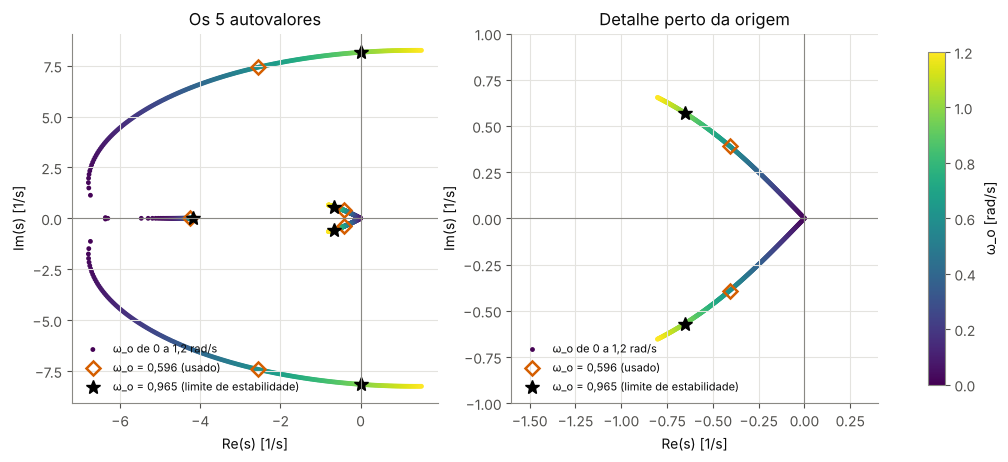

**Figura `PID_cascata_lugar_raizes.png`.** Lugar das raízes da cascata linear completa do PID do carro-pêndulo (5 estados: x, ẋ, θ, θ̇ e a integral; discreta, levada ao tempo contínuo por s = ln(z)/dt) com ω_o de 0 a 1,2 rad/s; marcados o ω_o usado e o limite de estabilidade.

pi-margem-de-fase: OK | contínua 78.56°, com segurador 49.59°; diferenças 0.0e+00° e 0.0e+00° | tolerância: 1e-6° entre as duas contas; 1e-12 em G(z)


**Tabela `caracterizacao__PI_margem_de_fase.csv`.** Cruzamento de ganho e margem de fase da malha aberta do PI da infusão, em tempo contínuo e com o segurador de ordem zero (Ts = 10 s).

,cruzamento [rad/s],margem de fase [°]
"contínua, L(s) = C(s)·G(s)",0.1028,78.5635
"com segurador, L(z) = C(z)·G(z)",0.0942,49.5863


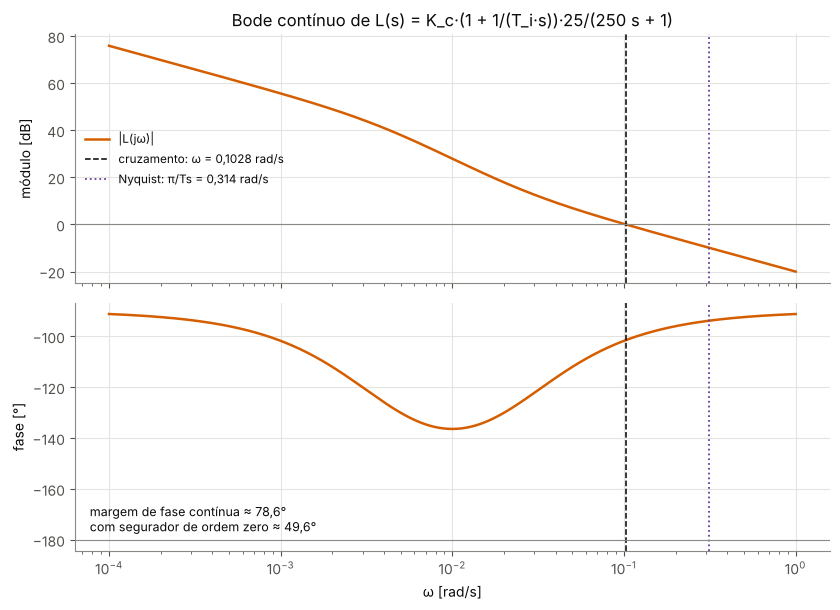

**Figura `PI_bode_malha_aberta.png`.** Bode contínuo da malha aberta do PI da infusão, L(s) = K_c·(1 + 1/(T_i·s))·G(s), com K_c = 1 e T_i = 40 s; cruzamento de ganho e frequência de Nyquist marcados; margem de fase contínua ≈ 78,6°; com segurador de ordem zero, ≈ 49,6°.

In [15]:
# Lugar das raízes da cascata em ω_o, de 0 a 1,2 rad/s.
omegas_lr = np.linspace(0.0, 1.2, 241)
s_lr = np.array([np.sort_complex(np.log(np.linalg.eigvals(matriz_cascata_linear(Ad, Bd, PIDCascata(planta, a, b, p_pid, w))).astype(complex)) / dt)
                 for w in omegas_lr])
s_usado = np.sort_complex(np.log(z_06.astype(complex)) / dt)
s_limite = np.sort_complex(np.log(np.linalg.eigvals(matriz_cascata_linear(Ad, Bd, PIDCascata(planta, a, b, p_pid, omega_lim))).astype(complex)) / dt)
registrar_caracterizacao("PID/lugar_raizes", {"omega_o_usado": omega_o, "omega_o_limite": omega_lim, "polos_s_no_omega_usado": s_usado,
                                              "polos_s_no_limite": s_limite, "maior_Re_s_no_omega_usado": float(np.max(np.real(s_usado))),
                                              "maior_Re_s_em_1_2": float(np.max(np.real(s_lr[-1])))})
figura_PID_lugar_raizes(omegas_lr, s_lr, s_usado, s_limite, omega_o, omega_lim)

# Margem de fase do PI: contínua, L(s) = C(s)·G(s), e discreta, L(z) = C(z)·G(z) com o ZOH, cada uma em duas contas.
Kc_pi, Ti_pi, Ts_pi = pi_inf.Kc, pi_inf.Ti, planta_inf.dt
L_cont = lambda w: Kc_pi * (1 + 1 / (Ti_pi * 1j * w)) * planta_inf.ganho / (planta_inf.tau * 1j * w + 1)
L_disc = lambda w: (Kc_pi * (1 + Ts_pi / (Ti_pi * (np.exp(1j * w * Ts_pi) - 1)))
                    * planta_inf.Bd / (np.exp(1j * w * Ts_pi) - planta_inf.Ad))
sis_cont = scipy.signal.lti(np.polymul([Kc_pi * Ti_pi, Kc_pi], [planta_inf.ganho]), np.polymul([Ti_pi, 0.0], [planta_inf.tau, 1.0]))
num_G, den_G, _ = scipy.signal.cont2discrete(([planta_inf.ganho], [planta_inf.tau, 1.0]), Ts_pi, method="zoh")
num_G, den_G = np.ravel(num_G), np.ravel(den_G)
sis_disc = scipy.signal.dlti(np.polymul([Kc_pi, Kc_pi * (Ts_pi / Ti_pi - 1)], num_G), np.polymul([1.0, -1.0], den_G), dt=Ts_pi)
L_cont_scipy = lambda w: complex(sis_cont.freqresp(w=[w])[1][0])
L_disc_scipy = lambda w: complex(scipy.signal.dfreqresp(sis_disc, w=[w * Ts_pi])[1][0])
w_nyq = np.pi / Ts_pi
wc_c, pm_c = margem_de_fase(L_cont, 1e-3, 1.0)
wc_c2, pm_c2 = margem_de_fase(L_cont_scipy, 1e-3, 1.0)
wc_d, pm_d = margem_de_fase(L_disc, 1e-3, 0.999 * w_nyq)
wc_d2, pm_d2 = margem_de_fase(L_disc_scipy, 1e-3, 0.999 * w_nyq)
dif_G = max(abs(num_G[-1] - planta_inf.Bd), abs(den_G[-1] + planta_inf.Ad))
verificar("pi-margem-de-fase — PI da infusão: margem de fase contínua e com segurador, cada uma por duas contas (fórmula direta × scipy.signal) "
          "a 1e-6°, e G(z) do cont2discrete = B_d/(z − A_d) a 1e-12",
          max(abs(pm_c - pm_c2), abs(pm_d - pm_d2)) < 1e-6 and dif_G < 1e-12,
          f"contínua {pm_c:.2f}°, com segurador {pm_d:.2f}°; diferenças {abs(pm_c - pm_c2):.1e}° e {abs(pm_d - pm_d2):.1e}°", tol="1e-6° entre as duas contas; 1e-12 em G(z)")
registrar_caracterizacao("PI/bode", {"cruzamento_continuo [rad·s⁻¹]": wc_c, "margem_de_fase_continua [°]": pm_c,
                                     "cruzamento_discreto [rad·s⁻¹]": wc_d, "margem_de_fase_discreta [°]": pm_d,
                                     "atraso_do_segurador_no_cruzamento_discreto [°]": float(np.degrees(wc_d * Ts_pi / 2)),
                                     "atraso_do_segurador_no_cruzamento_continuo [°]": float(np.degrees(wc_c * Ts_pi / 2)),
                                     "diferenca_entre_as_margens [°]": pm_c - pm_d})
tabela_caracterizacao("PI_margem_de_fase", pd.DataFrame({"cruzamento [rad/s]": [wc_c, wc_d], "margem de fase [°]": [pm_c, pm_d]},
                            index=["contínua, L(s) = C(s)·G(s)", "com segurador, L(z) = C(z)·G(z)"]).round(4),
               "Cruzamento de ganho e margem de fase da malha aberta do PI da infusão, em tempo contínuo e com o segurador de ordem zero (Ts = 10 s).")
w_pi = np.logspace(-4, 0, 600)
figura_PI_bode(w_pi, L_cont(w_pi), wc_c, pm_c, pm_d, w_nyq)

### 2.3 Margens de estabilidade

Malha discreta, como implementada, sem saturação, quebrada na entrada da planta: planta $x_{k+1} = A x_k + B u_k$; controlador com estado $\xi$ (a integral, no PID e no PI), $\xi_{k+1} = A_c \xi_k + B_c x_k$, $v_k = C_c \xi_k + D_c x_k$; malha fechada com $u_k = k\,v_k$. Ganho de laço:

$$L(z) = -\left[C_c (zI - A_c)^{-1} B_c + D_c\right](zI - A)^{-1} B.$$

- **Faixa de ganho:** os valores de k, em torno de k = 1, com todos os autovalores de $\begin{bmatrix} A + k B D_c & k B C_c \\ B_c & A_c\end{bmatrix}$ dentro do círculo unitário (varredura de k de 1e-4 a 1e4 e bisseção nas bordas).
- **Margem de fase:** 180° + ∠L(e^{jωT}) no cruzamento de ganho, |L| = 1, com ω de 0 a π/T; havendo mais de um cruzamento, a menor.

| controlador | A, B | D_c | controlador com estado |
|---|---|---|---|
| LQR correto e LQR aproximado (pêndulo) | jacobiana do `step()` (1.1) | −K | — |
| PID em cascata (pêndulo) | idem | K_p·c_e + K_d·(0, 0, 0, 1), c_e = (ω_o²/g, 2ζ_oω_o/g, 1, 0) | $A_c = 1$, $B_c = dt\cdot c_e$, $C_c = K_i$ |
| LQR (infusão) | A_d, B_d (ZOH) | −K | — |
| PI (infusão) | idem | −K_c | $A_c = 1$, $B_c = -T_s$, $C_c = K_c/T_i$ |

As RN não têm margens definidas (o laço é não linear).

Verificações: as bordas da faixa de k contra os autovalores logo dentro e logo fora delas; a margem do PI igual à de 2.2 (com o segurador), a 1e-6°; os valores contra uma implementação independente.

In [16]:
def margens_discretas(A, B, A_c, B_c, C_c, D_c, T, k_busca=(1e-4, 1e4)):
    """Faixa de k com a malha fechada estável em torno de k = 1, cruzamentos de ganho e margem de fase de L(z) (ver o texto).
    Matrizes com o controlador sem estado: A_c de 0 × 0, B_c de 0 × n, C_c de 1 × 0."""
    def raio(k):
        M = np.block([[A + k * B @ D_c, k * B @ C_c], [B_c, A_c]]) if A_c.size else A + k * B @ D_c
        return float(np.max(np.abs(np.linalg.eigvals(M))))

    def borda(dentro, fora):
        for _ in range(200):
            meio = np.sqrt(dentro * fora)
            dentro, fora = (meio, fora) if raio(meio) < 1 else (dentro, meio)
        return np.sqrt(dentro * fora)

    assert raio(1.0) < 1, "a malha fechada nominal não é estável"
    grade = np.logspace(np.log10(k_busca[0]), np.log10(k_busca[1]), 1601)
    estavel = np.array([raio(k) < 1 for k in grade])
    i1 = int(np.searchsorted(grade, 1.0))
    abaixo = np.flatnonzero(~estavel[:i1])
    acima = np.flatnonzero(~estavel[i1:])
    k_min = borda(grade[abaixo[-1] + 1], grade[abaixo[-1]]) if len(abaixo) else 0.0
    k_max = borda(grade[i1 + acima[0] - 1], grade[i1 + acima[0]]) if len(acima) else np.inf

    def L(w):
        z = np.exp(1j * w * T)
        P = np.linalg.solve(z * np.eye(A.shape[0]) - A, B)
        H = D_c + (C_c @ np.linalg.solve(z * np.eye(A_c.shape[0]) - A_c, B_c) if A_c.size else 0.0)
        return complex(-(H @ P)[0, 0])

    ws = np.logspace(-6, np.log10(np.pi / T), 20001)[:-1]
    g = np.array([abs(L(w)) for w in ws]) - 1.0
    cruzamentos = [scipy.optimize.brentq(lambda w: abs(L(w)) - 1.0, ws[i], ws[i + 1], xtol=1e-15, rtol=1e-14)
                   for i in np.flatnonzero(np.sign(g[:-1]) != np.sign(g[1:]))]
    fases = [float((np.degrees(np.angle(L(w))) + 180.0 + 180.0) % 360.0 - 180.0) for w in cruzamentos]
    i_mf = int(np.argmin(np.abs(fases))) if fases else None
    return dict(k_min=k_min, k_max=k_max, raio=raio, cruzamentos=cruzamentos, fases=fases,
                wc=cruzamentos[i_mf] if fases else np.nan, MF=fases[i_mf] if fases else np.nan)


vazio = (np.zeros((0, 0)), np.zeros((0, 4)), np.zeros((1, 0)))
c_e = np.array([pid.omega_o**2 / pid.g, 2 * pid.zeta_o * pid.omega_o / pid.g, 1.0, 0.0])
MARGENS = {
    "LQR correto (pêndulo)": margens_discretas(Ad, Bd, *vazio, -K_correto.reshape(1, 4), dt),
    "LQR aproximado (pêndulo)": margens_discretas(Ad, Bd, *vazio, -K_aproximado.reshape(1, 4), dt),
    "PID em cascata (pêndulo)": margens_discretas(Ad, Bd, np.eye(1), dt * c_e.reshape(1, 4), np.array([[pid.Ki]]),
                                                 (pid.Kp * c_e + pid.Kd * np.array([0.0, 0.0, 0.0, 1.0])).reshape(1, 4), dt),
    "LQR (infusão)": margens_discretas(np.array([[planta_inf.Ad]]), np.array([[planta_inf.Bd]]), np.zeros((0, 0)), np.zeros((0, 1)),
                                       np.zeros((1, 0)), -np.array([[K_inf[0, 0]]]), planta_inf.dt),
    "PI (infusão)": margens_discretas(np.array([[planta_inf.Ad]]), np.array([[planta_inf.Bd]]), np.eye(1), np.array([[-planta_inf.dt]]),
                                      np.array([[pi_inf.Kc / pi_inf.Ti]]), np.array([[-pi_inf.Kc]]), planta_inf.dt),
}

# Bordas da faixa de k: estável logo dentro, instável logo fora (1e-6 relativo).
bordas_ok = all((m_["k_min"] == 0.0 or (m_["raio"](m_["k_min"] * (1 + 1e-6)) < 1 < m_["raio"](m_["k_min"] * (1 - 1e-6)))) and
                (not np.isfinite(m_["k_max"]) or (m_["raio"](m_["k_max"] * (1 - 1e-6)) < 1 < m_["raio"](m_["k_max"] * (1 + 1e-6))))
                for m_ in MARGENS.values())
verificar("margens-bordas — faixa de k: malha fechada estável logo dentro de cada borda e instável logo fora", bordas_ok,
          f"{len(MARGENS)} malhas", tol="1e-6 relativo em k")
verificar("margens-pi-igual-2.2 — margem de fase do PI = a de 2.2 com o segurador", abs(MARGENS["PI (infusão)"]["MF"] - pm_d) < 1e-6,
          f"{MARGENS['PI (infusão)']['MF']:.4f}° × {pm_d:.4f}°", tol="1e-6°")
MARGENS_CONF = {"LQR correto (pêndulo)": (60.9, 0.295, 6.24), "LQR aproximado (pêndulo)": (49.5, None, None),
                "PID em cascata (pêndulo)": (32.4, 0.498, 10.08), "LQR (infusão)": (76.6, None, 3.38), "PI (infusão)": (49.6, None, 2.28)}
difs_m = []
for nome, (mf, kmin, kmax) in MARGENS_CONF.items():
    m_ = MARGENS[nome]
    difs_m.append(abs(round(m_["MF"], 1) - mf) / 0.1)
    if kmin is not None:
        difs_m.append(abs(round(m_["k_min"], 3) - kmin) / 0.001)
    if kmax is not None:
        difs_m.append(abs(round(m_["k_max"], 2) - kmax) / 0.01)
verificar("margens-conferencia — margens de fase e faixas de k = implementação independente, a uma unidade na última casa",
          max(difs_m) <= 1.0 + 1e-9, f"maior diferença {max(difs_m):.1f} unidade(s) na última casa", tol="1 unidade na última casa")

linhas_ = []
for nome, m_ in MARGENS.items():
    linhas_.append({"malha": nome, "margem de fase [°]": m_["MF"], "cruzamento de ganho [rad/s]": m_["wc"], "cruzamentos": len(m_["cruzamentos"]),
                    "k mínimo": m_["k_min"], "k máximo": m_["k_max"],
                    "margem de ganho, para baixo [dB]": 20 * np.log10(m_["k_min"]) if m_["k_min"] > 0 else np.nan,   # sem limite inferior
                    "margem de ganho, para cima [dB]": 20 * np.log10(m_["k_max"])})
TAB_MARGENS = pd.DataFrame(linhas_).set_index("malha")
registrar_tabela("margens/tabela", TAB_MARGENS)
exibir_ = pd.DataFrame({"margem de fase [°]": TAB_MARGENS["margem de fase [°]"].map(lambda v: f"{v:.1f}"),
                        "cruzamento [rad/s]": TAB_MARGENS["cruzamento de ganho [rad/s]"].map(lambda v: f"{v:.4g}"),
                        "faixa de k estável": [f"{a:.3g} a {b:.3g}" if a > 0 else f"0 a {b:.3g}" for a, b in zip(TAB_MARGENS["k mínimo"], TAB_MARGENS["k máximo"])]})
exibir_.loc["RN (as duas plantas)"] = ["não definida (laço não linear)", "—", "—"]
mostrar_tabela(exibir_, "Margens de estabilidade da malha discreta, sem saturação, quebrada na entrada da planta: margem de fase no cruzamento "
               "de ganho de L(z) e faixa do multiplicador k do ganho de laço com a malha fechada estável. As RN não têm margens definidas.",
               csv="margens__tabela.csv")

margens-bordas: OK | 5 malhas | tolerância: 1e-6 relativo em k
margens-pi-igual-2.2: OK | 49.5863° × 49.5863° | tolerância: 1e-6°
margens-conferencia: OK | maior diferença 1.0 unidade(s) na última casa | tolerância: 1 unidade na última casa


**Tabela `margens__tabela.csv`.** Margens de estabilidade da malha discreta, sem saturação, quebrada na entrada da planta: margem de fase no cruzamento de ganho de L(z) e faixa do multiplicador k do ganho de laço com a malha fechada estável. As RN não têm margens definidas.

,margem de fase [°],cruzamento [rad/s],faixa de k estável
malha,,,
LQR correto (pêndulo),60.9,15.65,0.294 a 6.24
LQR aproximado (pêndulo),49.6,11.51,0.349 a 8.72
PID em cascata (pêndulo),32.5,10.41,0.498 a 10.1
LQR (infusão),76.6,0.05983,0 a 3.39
PI (infusão),49.6,0.09424,0 a 2.29
RN (as duas plantas),não definida (laço não linear),—,—


## 3. Controlador neural: indireto e direto

### 3.1 Funções

Controle neural indireto: um emulador neural da planta e um controlador neural treinado através dele, com uma etapa de imitação do LQR antes do refinamento, como no notebook do professor. Controle neural direto (`RN-direta`): o mesmo controlador, com o refinamento feito pela planta exata (`ModeloExato`), sem emulador; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto. As três etapas usam Adam.

| etapa | o que treina | dados | perda |
|---|---|---|---|
| 1. identificação | emulador | 120 rollouts × 60 passos da planta, com entrada aleatória uniforme em [u_min, u_max] | erro quadrático do próximo estado |
| 2. imitação | controlador | 8000 estados sorteados numa caixa, com o comando do LQR (já saturado) como rótulo | erro quadrático do comando |
| 3. refinamento | controlador, com o modelo congelado | malha fechada simulada no modelo por T_ref passos, a partir de 3 condições iniciais | J, com o gradiente por retropropagação através do tempo |

- **Emulador do professor** (`PlantModel`, `train_plant_model`): $\hat x^+ = x + N([x,\ u])$, com N um MLP 2 × 64 tanh; 501 épocas, Adam 1e-3, perda MSE no estado.
- **Emulador corrigido** (`EmuladorNormalizado`, `treinar_emulador_corrigido`): $\hat x^+ = x + \sigma_\Delta \odot N\!\left(\left[\dfrac{x - x_{eq}}{\sigma_x},\ \dfrac{u - u_{eq}}{\sigma_u}\right]\right)$, com σ_x, σ_u e σ_Δ os desvios padrão dos estados, da entrada e do incremento Δ = x⁺ − x nos dados de treino; perda $\mathrm{média}\big[((\hat x^+ - x^+)/\sigma_\Delta)^2\big]$; 3000 épocas, Adam 1e-3.
- **Controlador do professor** (`Controller`): $u = 20\,\tanh\!\big((g\,N(x) + \delta)/20\big)$, com N um MLP 2 × 64 tanh, g = 1 e δ não treináveis (δ é a calibração).
- **Controlador da infusão** (`ControladorSigmoide`): $u = u_{max}\,\sigma\!\big(z_0 + N((C - C_{ref})/0{,}15) + \delta\big)$, com σ a sigmoide e $z_0 = \mathrm{logit}(u_{ss}/u_{max})$.
- **Imitação** (`treinar_imitacao`): 501 épocas, Adam 1e-3, perda $\mathrm{média}[(u - u_{LQR})^2]$; na infusão, com u e u_LQR divididos por u_max.
- **Refinamento** (`refinar_controlador`, `perda_no_emulador`): 201 épocas, Adam 5e-4, perda
$$\mathcal L = \frac{1}{N_{ci}}\sum_{i=1}^{N_{ci}} w_i\left[\frac1T\sum_{k=1}^{T}\left(\tilde x_{i,k}^\top Q\,\tilde x_{i,k} + R\,\tilde u_{i,k-1}^2\right) + \frac{\tilde x_{i,T}^\top P\,\tilde x_{i,T}}{T}\right],$$
com o termo terminal opcional (nenhuma variante o usa) e os pesos $w_i$ só na infusão ($w_i = 1$ no pêndulo). O modelo do refinamento é o emulador corrigido (indireta) ou a planta exata (direta: `ModeloExato`, que chama `step_tf`). O emulador do professor é treinado e passa pelo portão de qualidade (3.3), sem refinamento.
- **Calibração** (`calibrar`): no pêndulo, a do professor, δ ← δ − (u(x_eq) − u_eq), repetida até |u(x_eq) − u_eq| < 1e-7; na infusão, δ = logit(u_ss/u_max) − z₀ − N(0), em float64, de modo que u(C_ref) = u_ss.
- **Exportação para numpy** (`PoliticaNumpy`, `PoliticaNumpySigmoide`): os pesos copiados em float64; as simulações usam esta versão.
- `perda_na_planta`: a perda do refinamento simulada na planta real. `liberar_memoria_tf`: apaga do registro global do TensorFlow as funções de gradiente dos treinos já feitos; não muda nenhuma conta.

In [17]:
# Código do professor, com o parâmetro n_estados acrescentado (padrão 4; com 4 estados, são as classes dele).
class PlantModel(keras.Model):
    def __init__(self, hidden=64, n_estados=4):
        super().__init__()
        self.net = keras.Sequential(
            [
                layers.Input(shape=(n_estados + 1,)),
                layers.Dense(hidden, activation="tanh"),
                layers.Dense(hidden, activation="tanh"),
                layers.Dense(n_estados),
            ],
            name="cartpole_identifier",
        )

    def call(self, inputs, training=False):
        state, force = inputs
        x = tf.concat([state, force], axis=-1)
        delta_state = self.net(x, training=training)
        return state + delta_state


def train_plant_model(X, Y, epochs=501, n_estados=4):
    model = PlantModel(n_estados=n_estados)
    optimizer = keras.optimizers.Adam(learning_rate=0.001)
    loss_fn = keras.losses.MeanSquaredError()

    X = tf.convert_to_tensor(X, dtype=tf.float32)
    Y = tf.convert_to_tensor(Y, dtype=tf.float32)
    state = X[:, :n_estados]
    force = X[:, n_estados:n_estados + 1]

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            y_pred = model([state, force], training=True)
            loss = loss_fn(Y, y_pred)

        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

        if epoch % 50 == 0:
            print(f"[Plant] Epoch {epoch}, Loss: {loss.numpy():.6f}")

    return model


class Controller(keras.Model):
    def __init__(self, force_limit=20.0, hidden=64, n_estados=4):
        super().__init__()
        self.force_limit = force_limit
        self.output_gain = tf.Variable(1.0, trainable=False, dtype=tf.float32)
        self.output_offset = tf.Variable(0.0, trainable=False, dtype=tf.float32)
        self.net = keras.Sequential(
            [
                layers.Input(shape=(n_estados,)),
                layers.Dense(hidden, activation="tanh"),
                layers.Dense(hidden, activation="tanh"),
                layers.Dense(1),
            ],
            name="cartpole_neural_controller",
        )

    def call(self, state, training=False):
        raw_force = self.net(state, training=training)
        force = self.output_gain * raw_force + self.output_offset
        return self.force_limit * tf.tanh(force / self.force_limit)

In [18]:
# ----------------------------------------------------------------------------------------------------
# Etapa 1: dados e emuladores
# ----------------------------------------------------------------------------------------------------
def gerar_dados(planta, rollouts=120, T=60):
    """generate_data do professor para n estados: mesma sequência de sorteios, faixas tiradas da planta."""
    dados = []
    for _ in range(rollouts):
        # Estado inicial: um componente por vez, na ordem do professor (pêndulo: caixa centrada na origem; infusão: em C = 0,125).
        estado = np.asarray([planta.centro_dados[i] + np.random.uniform(-c, c) for i, c in enumerate(planta.caixa_dados)], dtype=np.float32)
        for _ in range(T):
            forca = np.random.uniform(planta.u_min, planta.u_max)   # entrada aleatória a cada passo
            proximo = planta.step(estado, forca)
            dados.append(np.concatenate([estado, [forca], proximo]))
            estado = proximo
    dados = np.asarray(dados, dtype=np.float32)
    n = planta.n_estados
    return dados[:, :n + 1], dados[:, n + 1:]


class EmuladorNormalizado(keras.Model):
    """Emulador corrigido: o MLP do professor, com entradas e incremento normalizados."""

    def __init__(self, planta, escala_x, escala_u, escala_delta, hidden=64):
        super().__init__()
        n = planta.n_estados
        self.x_eq = tf.constant(planta.x_eq, dtype=tf.float32)
        self.u_eq = tf.constant(planta.u_eq, dtype=tf.float32)
        self.escala_x = tf.constant(escala_x, dtype=tf.float32)
        self.escala_u = tf.constant(escala_u, dtype=tf.float32)
        self.escala_delta = tf.constant(escala_delta, dtype=tf.float32)
        self.net = keras.Sequential(
            [layers.Input(shape=(n + 1,)), layers.Dense(hidden, activation="tanh"),
             layers.Dense(hidden, activation="tanh"), layers.Dense(n)],
            name="emulador_normalizado",
        )

    def call(self, inputs, training=False):
        estado, forca = inputs
        # Entradas centradas no ponto de operação e divididas pelo desvio padrão; o incremento previsto volta à escala do estado.
        z = tf.concat([(estado - self.x_eq) / self.escala_x, (forca - self.u_eq) / self.escala_u], axis=-1)
        return estado + self.net(z, training=training) * self.escala_delta


def escalas_emulador(planta, X, Y):
    """Desvios padrão dos dados de treino: estados, força e incremento Δ = x⁺ − x."""
    n = planta.n_estados
    escalas = dict(escala_x=X[:, :n].std(axis=0), escala_u=X[:, n].std(), escala_delta=(Y - X[:, :n]).std(axis=0))
    for nome, valor in escalas.items():
        assert np.all(np.asarray(valor) > 0), f"escala nula em {nome}: a variável não varia nos dados"
    return escalas


def treinar_emulador_corrigido(planta, X, Y, epocas=3000, lr=1e-3):
    n = planta.n_estados
    emulador = EmuladorNormalizado(planta, **escalas_emulador(planta, X, Y))
    otimizador = keras.optimizers.Adam(learning_rate=lr)
    S, F, Yt = tf.constant(X[:, :n]), tf.constant(X[:, n:n + 1]), tf.constant(Y)
    escala_delta = emulador.escala_delta

    @tf.function
    def passo():
        with tf.GradientTape() as tape:
            # Perda em unidades normalizadas: erro de cada componente do próximo estado em desvios padrão do incremento.
            perda = tf.reduce_mean(tf.square((emulador([S, F], training=True) - Yt) / escala_delta))
        gradientes = tape.gradient(perda, emulador.trainable_variables)
        otimizador.apply_gradients(zip(gradientes, emulador.trainable_variables))
        return perda

    t0 = time.perf_counter()
    historico = []
    for epoca in range(epocas):
        perda = passo()
        if epoca % 100 == 0 or epoca == epocas - 1:
            historico.append([epoca, float(perda.numpy())])
    return emulador, dict(tempo=time.perf_counter() - t0, perdas=historico)


def erro_incremento(planta, emulador, X, Y):
    """Erro relativo de 1 passo no incremento: global (norma de Frobenius) e por componente."""
    n = planta.n_estados
    Yp = emulador([tf.constant(X[:, :n]), tf.constant(X[:, n:n + 1])], training=False).numpy()
    D = Y - X[:, :n]
    E = Yp - Y
    return float(np.linalg.norm(E) / np.linalg.norm(D)), np.linalg.norm(E, axis=0) / np.linalg.norm(D, axis=0)


class ModeloExato:
    """A planta exata (step_tf), com a mesma chamada de um emulador: modelo([estado, u]) → próximo estado."""

    trainable = False   # como um emulador congelado

    def __init__(self, planta):
        self.planta = planta

    def __call__(self, inputs, training=False):
        estado, u = inputs
        return self.planta.step_tf(estado, u)


# ----------------------------------------------------------------------------------------------------
# Etapa 2: imitação do LQR
# ----------------------------------------------------------------------------------------------------
def treinar_imitacao(planta, K, caixa, semente, epocas=501, amostras=8000, lr=1e-3):
    """train_controller_from_linear_feedback do professor, com a caixa de sorteio como parâmetro e @tf.function."""
    fixar_semente(semente, "imitacao")
    n = planta.n_estados
    controlador = novo_controlador(planta)   # pesos iniciais sorteados antes dos estados, na ordem do professor
    otimizador = keras.optimizers.Adam(learning_rate=lr)
    perda_fn = keras.losses.MeanSquaredError()
    estados = np.column_stack([planta.centro_imitacao[i] + np.random.uniform(-caixa[i], caixa[i], amostras) for i in range(n)]).astype(np.float32)
    forcas = np.asarray([rotulo_lqr(planta, K, s) for s in estados], dtype=np.float32).reshape(-1, 1)   # rótulo: comando do LQR, saturado
    S, F = tf.convert_to_tensor(estados), tf.convert_to_tensor(forcas)
    escala = planta.escala_perda_imitacao   # None no pêndulo (perda em N²); u_max na infusão

    @tf.function
    def passo():
        with tf.GradientTape() as tape:
            if escala is None:
                perda = perda_fn(F, controlador(S, training=True))
            else:
                perda = perda_fn(F / escala, controlador(S, training=True) / escala)   # perda em frações de u_max
        gradientes = tape.gradient(perda, controlador.trainable_variables)
        otimizador.apply_gradients(zip(gradientes, controlador.trainable_variables))
        return perda

    t0 = time.perf_counter()
    historico = []
    for epoca in range(epocas):
        perda = passo()
        if epoca % 50 == 0 or epoca == epocas - 1:
            historico.append([epoca, float(perda.numpy())])
    return controlador, dict(tempo=time.perf_counter() - t0, perdas=historico)


# ----------------------------------------------------------------------------------------------------
# Etapa 3: refinamento através do modelo congelado (emulador ou planta exata)
# ----------------------------------------------------------------------------------------------------
def perda_no_emulador(planta, modelo, controlador, cis, T, P_terminal=None, pesos=None):
    """A perda do refinamento do professor (média sobre as condições iniciais), calculada no modelo.

    `modelo` é o emulador ou a planta exata (ModeloExato). Opcionais, desligados por padrão:
    - P_terminal: soma x_Tᵀ P x_T / T à perda de cada condição inicial, antes da média;
    - pesos: multiplica a perda de cada condição inicial por um peso.
    Sem eles, a conta é a do professor."""
    Q1 = tf.constant(np.diag(planta.Q), dtype=tf.float32)
    R1 = float(planta.R[0, 0])
    x_eq = tf.constant(planta.x_eq, dtype=tf.float32)
    s = tf.constant(cis, dtype=tf.float32)
    soma_x = 0.0
    soma_u = 0.0
    for _ in range(T):
        u = controlador(s, training=True)
        s = modelo([s, u], training=False)
        soma_x += tf.reduce_sum(Q1 * tf.square(s - x_eq), axis=1)
        soma_u += tf.square(u[:, 0] - planta.u_eq)
    perda_ci = soma_x / T + R1 * soma_u / T
    if P_terminal is not None:
        # Custo terminal x_Tᵀ P x_T, dividido por T.
        d = s - x_eq
        perda_ci = perda_ci + tf.reduce_sum(tf.matmul(d, tf.constant(P_terminal, dtype=tf.float32)) * d, axis=1) / T
    if pesos is not None:
        perda_ci = perda_ci * tf.constant(pesos, dtype=tf.float32)
    return tf.reduce_mean(perda_ci)


def refinar_controlador(planta, modelo, controlador, cis, T, epocas=201, lr=5e-4, P_terminal=None, pesos=None):
    """refine_controller_with_model do professor, com as condições iniciais vetorizadas e @tf.function."""
    otimizador = keras.optimizers.Adam(learning_rate=lr)
    modelo.trainable = False   # o modelo fica congelado: só os pesos do controlador mudam

    @tf.function
    def passo():
        # O GradientTape grava os T passos da malha fechada controlador → modelo e calcula ∂perda/∂pesos
        # (retropropagação através do tempo).
        with tf.GradientTape() as tape:
            perda = perda_no_emulador(planta, modelo, controlador, cis, T, P_terminal, pesos)
        gradientes = tape.gradient(perda, controlador.trainable_variables)
        otimizador.apply_gradients(zip(gradientes, controlador.trainable_variables))
        return perda

    t0 = time.perf_counter()
    historico = [float(passo().numpy()) for _ in range(epocas)]   # perda antes do passo de gradiente de cada época, como no professor
    return controlador, dict(tempo=time.perf_counter() - t0, perdas=historico)


# ----------------------------------------------------------------------------------------------------
# Controlador com saída sigmoide (infusão)
# ----------------------------------------------------------------------------------------------------
class ControladorSigmoide(keras.Model):
    """Controlador neural com saída em (0, u_max):

        u = u_max·σ(z₀ + RN((x − x_eq)/escala_x) + δ),   z₀ = logit(u_eq/u_max).

    A RN é o mesmo MLP 2 × 64 tanh do professor. δ não é treinável: é a calibração, que faz u(x_eq) = u_eq."""

    def __init__(self, planta, hidden=64):
        super().__init__()
        n = planta.n_estados
        self.u_max = float(planta.u_max)
        self.x_eq = tf.constant(planta.x_eq, dtype=tf.float32)
        self.escala_x = tf.constant(planta.escala_x, dtype=tf.float32)
        self.x_eq_64 = tuple(float(v) for v in planta.x_eq)        # x_eq e escala em float64, para a versão numpy
        self.escala_64 = tuple(float(v) for v in planta.escala_x)
        self.z0_64 = float(np.log(planta.u_eq / (planta.u_max - planta.u_eq)))   # logit(u_eq/u_max), em float64
        self.z0 = tf.Variable(self.z0_64, trainable=False, dtype=tf.float32)
        self.output_offset = tf.Variable(0.0, trainable=False, dtype=tf.float32)  # δ, em float32 (Keras)
        self.offset_64 = 0.0                                                       # o mesmo δ, em float64 (versão numpy)
        self.net = keras.Sequential(
            [layers.Input(shape=(n,)), layers.Dense(hidden, activation="tanh"),
             layers.Dense(hidden, activation="tanh"), layers.Dense(1)],
            name="controlador_sigmoide",
        )

    def call(self, estado, training=False):
        z = self.z0 + self.net((estado - self.x_eq) / self.escala_x, training=training) + self.output_offset
        return self.u_max * tf.sigmoid(z)


# ----------------------------------------------------------------------------------------------------
# Calibração, cópia e exportação para numpy
# ----------------------------------------------------------------------------------------------------
def calibrar_offset(controlador, planta):
    """calibrate_controller_offset do professor para n estados e ponto de operação (x_eq, u_eq)."""
    estado_eq = tf.constant(planta.x_eq.reshape(1, -1), dtype=tf.float32)
    forca = controlador(estado_eq, training=False).numpy()[0, 0]
    controlador.output_offset.assign_add(-(forca - planta.u_eq))
    return float(forca)


def calibrar_tanh(controlador, planta, tol=1e-7, max_iter=10):
    """Aplica a calibração do professor até que |RN(x_eq) − u_eq| < tol."""
    estado_eq = tf.constant(planta.x_eq.reshape(1, -1), dtype=tf.float32)
    f0 = None
    for iteracao in range(1, max_iter + 1):
        forca = calibrar_offset(controlador, planta)
        f0 = forca if f0 is None else f0
        residuo = float(controlador(estado_eq, training=False).numpy()[0, 0]) - planta.u_eq
        if iteracao == 1:
            residuo_1 = residuo
        if abs(residuo) < tol:
            break
    return dict(f0=f0, residuo_1_aplicacao=residuo_1, iteracoes=iteracao, residuo=residuo,
                offset=float(controlador.output_offset.numpy()))


def calibrar_sigmoide(controlador, planta):
    """Calibração da saída sigmoide: δ = logit(u_eq/u_max) − z₀ − r₀, em float64, com r₀ a saída bruta da RN em x_eq.
    A versão numpy usa δ em float64; o Keras recebe δ arredondado para float32."""
    antes = PoliticaNumpySigmoide(controlador)
    u_antes = antes(planta.x_eq)
    r0 = antes.bruto(planta.x_eq)
    delta = float(np.log(planta.u_eq / (planta.u_max - planta.u_eq)) - controlador.z0_64 - r0)
    controlador.offset_64 = delta
    controlador.output_offset.assign(delta)
    residuo = PoliticaNumpySigmoide(controlador)(planta.x_eq) - planta.u_eq
    residuo_keras = float(controlador(tf.constant(planta.x_eq.reshape(1, -1), dtype=tf.float32), training=False).numpy()[0, 0]) - planta.u_eq
    return dict(f0=float(u_antes), residuo_1_aplicacao=float(residuo), iteracoes=1, residuo=float(residuo),
                residuo_keras=residuo_keras, offset=delta)


def calibrar(controlador, planta):
    """Calibração do controlador: a do professor (tanh, repetida) ou a da saída sigmoide (infusão)."""
    return calibrar_sigmoide(controlador, planta) if planta.tipo_saida == "sigmoide" else calibrar_tanh(controlador, planta)


def novo_controlador(planta):
    if planta.tipo_saida == "sigmoide":
        return ControladorSigmoide(planta)
    return Controller(force_limit=planta.u_max, n_estados=planta.n_estados)


def copiar_controlador(planta, origem):
    copia = novo_controlador(planta)
    copia.net.set_weights(origem.net.get_weights())
    copia.output_offset.assign(origem.output_offset)
    if hasattr(origem, "output_gain"):
        copia.output_gain.assign(origem.output_gain)
    if hasattr(origem, "offset_64"):
        copia.offset_64 = origem.offset_64
    return copia


class PoliticaNumpy:
    """O controlador neural com os pesos copiados para numpy (float64): u = 20·tanh((ganho·RN(x) + offset)/20)."""

    def __init__(self, controlador):
        pesos = [w.numpy().astype(np.float64) for w in controlador.net.weights]
        self.camadas = [(pesos[i], pesos[i + 1]) for i in range(0, len(pesos), 2)]
        self.ganho = float(controlador.output_gain.numpy())
        self.offset = float(controlador.output_offset.numpy())
        self.limite = float(controlador.force_limit)

    def vetorizado(self, estados):
        h = np.asarray(estados, dtype=np.float64)
        for W, b in self.camadas[:-1]:
            h = np.tanh(h @ W + b)
        W, b = self.camadas[-1]
        bruto = (h @ W + b)[:, 0]
        return self.limite * np.tanh((self.ganho * bruto + self.offset) / self.limite)

    def __call__(self, estado):
        h = np.asarray(estado, dtype=np.float64)
        for W, b in self.camadas[:-1]:
            h = np.tanh(h @ W + b)
        W, b = self.camadas[-1]
        bruto = float(h @ W[:, 0] + b[0])
        return self.limite * np.tanh((self.ganho * bruto + self.offset) / self.limite)


class PoliticaNumpySigmoide:
    """O ControladorSigmoide em numpy (float64): u = u_max·σ(z₀ + RN((x − x_eq)/escala) + δ), com x_eq, escala, z₀ e δ
    em float64 e os pesos do Keras convertidos para float64."""

    def __init__(self, controlador):
        pesos = [w.numpy().astype(np.float64) for w in controlador.net.weights]
        self.camadas = [(pesos[i], pesos[i + 1]) for i in range(0, len(pesos), 2)]
        self.u_max = controlador.u_max
        self.x_eq = np.asarray(controlador.x_eq_64, dtype=np.float64)
        self.escala = np.asarray(controlador.escala_64, dtype=np.float64)
        self.z = controlador.z0_64 + controlador.offset_64

    def bruto_vetorizado(self, estados):
        h = (np.asarray(estados, dtype=np.float64).reshape(-1, len(self.x_eq)) - self.x_eq) / self.escala
        for W, b in self.camadas[:-1]:
            h = np.tanh(h @ W + b)
        W, b = self.camadas[-1]
        return (h @ W + b)[:, 0]

    def bruto(self, estado):
        return float(self.bruto_vetorizado(estado)[0])

    def vetorizado(self, estados):
        return self.u_max / (1.0 + np.exp(-(self.z + self.bruto_vetorizado(estados))))

    def __call__(self, estado):
        h = (np.asarray(estado, dtype=np.float64) - self.x_eq) / self.escala
        for W, b in self.camadas[:-1]:
            h = np.tanh(h @ W + b)
        W, b = self.camadas[-1]
        return self.u_max / (1.0 + np.exp(-(self.z + float(h @ W[:, 0] + b[0]))))


def politica_numpy(controlador):
    return PoliticaNumpySigmoide(controlador) if isinstance(controlador, ControladorSigmoide) else PoliticaNumpy(controlador)


def perda_na_planta(planta, politica, cis, T, P_terminal=None, pesos=None):
    """A mesma conta da perda do refinamento, simulando a planta real (teste de fechamento)."""
    q = np.diag(planta.Q)
    r = float(planta.R[0, 0])
    perdas = []
    for ci in cis:
        s = np.asarray(ci, dtype=np.float32)
        soma_x = soma_u = 0.0
        for _ in range(T):
            u = politica(s)
            s = planta.step(s, u)
            soma_x += float(np.sum(q * np.square(np.asarray(s, dtype=np.float64) - planta.x_eq)))
            soma_u += (u - planta.u_eq) ** 2
        perda = soma_x / T + r * soma_u / T
        if P_terminal is not None:
            d = np.asarray(s, dtype=np.float64) - planta.x_eq
            perda += float(d @ P_terminal @ d) / T
        perdas.append(perda)
    perdas = np.array(perdas)
    if pesos is not None:
        perdas = perdas * np.asarray(pesos, dtype=np.float64)
    return float(np.mean(perdas))


def liberar_memoria_tf():
    """Apaga do registro global do TensorFlow as funções de gradiente ("CustomGradient-n") que o apply_gradients do Keras
    registra a cada treino compilado com @tf.function, e chama o coletor de lixo. Não muda nenhuma conta."""
    try:
        from tensorflow.python.framework import ops as tf_ops
        registro = tf_ops._gradient_registry._registry
        for chave in [k for k in registro if k.startswith("CustomGradient-")]:
            del registro[chave]
    except AttributeError:
        pass   # versão do TensorFlow sem esse registro interno
    gc.collect()


def rotulo_rn(variante, etapa, semente):
    return f"{variante} {etapa} s{semente}"

### 3.2 Variantes, cache e treino

Variantes de RN, todas com as sementes 0 a 4. Cada uma produz a RN **imitada** (fim da etapa 2) e a **refinada** (fim da etapa 3), as duas avaliadas calibradas.

| variante | planta | modelo do refinamento | LQR imitado | caixa de imitação | refinamento |
|---|---|---|---|---|---|
| `RN` (indireta) | as duas | emulador corrigido | correto | a do professor | 3 condições iniciais, 100 passos |
| `RN-direta` | as duas | planta exata (`step_tf`) | correto | a do professor | 3 condições iniciais, 100 passos |
| `RN-C4` | pêndulo | emulador corrigido | aproximado | a do professor | 3 condições iniciais, 100 passos |
| `RN-C4-direta` | pêndulo | planta exata (`step_tf`) | aproximado | a do professor | 3 condições iniciais, 100 passos |

- Caixa de imitação do professor: pêndulo, x ±1, ẋ ±1, θ ±0,35 rad, θ̇ ±1,5; infusão, C de 0 a 0,25. Condições iniciais do refinamento: pêndulo, (x, θ) = (0; 15°), (0,2 m; 10°) e (−0,2 m; −10°); infusão, C₀ = 0; 0,10; 0,18.
- `RN` e `RN-direta` partem da mesma RN imitada em cada semente (mesma semente, caixa e K); nas tabelas, ela aparece como `RN imitada`. `RN-C4` e `RN-C4-direta` partem da mesma imitação do LQR aproximado (`RN-C4 imitada`).
- O refinamento da `RN-C4-direta` fixa a semente da etapa `refinamento-C4-direta` (código 4) antes de começar; as etapas das outras variantes não mudam.
- O emulador do professor é treinado em cada semente do pêndulo (`PROJETO["pendulo"]["emuladores"]`) para o portão de qualidade (3.3) e as curvas de treino (3.5); nenhuma variante é refinada por ele.
- `PROJETO` guarda, por planta, os ganhos dos LQR imitados, as imitações, as variantes, os emuladores treinados e a matriz P da Riccati (o custo terminal opcional do refinamento).
- `montar_rns` treina ou carrega do cache, por semente: os dados (de treino e de validação), os emuladores, as imitações e os refinamentos de cada variante; depois calibra a imitada e a refinada e exporta as duas para numpy. Arquivos de pesos: `<planta>__<variante ou etapa>__<pesos|refinada|ganhos>__s<semente>__v1.npz`.

In [19]:
HIPER = dict(rollouts=120, passos_por_rollout=60, epocas_emulador_corrigido=3000, epocas_emulador_professor=501,
             lr_emulador=1e-3, epocas_imitacao=501, amostras_imitacao=8000, lr_imitacao=1e-3,
             epocas_refinamento=201, lr_refinamento=5e-4)

# Pêndulo. A chave "emulador" diz por qual modelo o gradiente do refinamento passa: "corrigido" (a RN indireta) ou "exato"
# (a planta exata em TensorFlow: a RN direta); "terminal" liga o custo terminal x_Tᵀ P x_T / T (desligado em todas).
GANHOS = {"correto": K_correto, "aproximado": K_aproximado}
IMITACOES = {
    "imit-correto": dict(K="correto", caixa=planta.caixa_imitacao),
    "imit-aproximado": dict(K="aproximado", caixa=planta.caixa_imitacao),
}
CIS, T_REF = planta.cis_refinamento, planta.T_refinamento
VARIANTES = {
    "RN": dict(emulador="corrigido", imitacao="imit-correto", cis=CIS, T_ref=T_REF, terminal=False),
    "RN-direta": dict(emulador="exato", imitacao="imit-correto", cis=CIS, T_ref=T_REF, terminal=False),
    "RN-C4": dict(emulador="corrigido", imitacao="imit-aproximado", cis=CIS, T_ref=T_REF, terminal=False),
    "RN-C4-direta": dict(emulador="exato", imitacao="imit-aproximado", cis=CIS, T_ref=T_REF, terminal=False),
}
# Etapa (semente própria) do refinamento de cada variante que tem uma.
ETAPA_REFINAMENTO = {"RN-C4-direta": "refinamento-C4-direta"}

# Infusão.
CIS_INF, T_REF_INF = planta_inf.cis_refinamento, planta_inf.T_refinamento
GANHOS_INF = {"lqr": K_inf}
IMITACOES_INF = {"imit-lqr": dict(K="lqr", caixa=planta_inf.caixa_imitacao)}
VARIANTES_INF = {
    "RN": dict(emulador="corrigido", imitacao="imit-lqr", cis=CIS_INF, T_ref=T_REF_INF, terminal=False),
    "RN-direta": dict(emulador="exato", imitacao="imit-lqr", cis=CIS_INF, T_ref=T_REF_INF, terminal=False),
}

# "emuladores": os emuladores treinados em cada semente (o do professor, só para o portão de 3.3 e as curvas de 3.5).
PROJETO = {"pendulo": dict(ganhos=GANHOS, imitacoes=IMITACOES, variantes=VARIANTES, emuladores=["corrigido", "professor"], P_terminal=P_terminal),
           "infusao": dict(ganhos=GANHOS_INF, imitacoes=IMITACOES_INF, variantes=VARIANTES_INF, emuladores=["corrigido"], P_terminal=P_inf)}


def obter_dados(planta, semente):
    fixar_semente(semente, "dados")
    X, Y = gerar_dados(planta, HIPER["rollouts"], HIPER["passos_por_rollout"])
    fixar_semente(semente, "validacao")
    Xv, Yv = gerar_dados(planta, HIPER["rollouts"], HIPER["passos_por_rollout"])   # conjunto independente, para a validação do portão
    return X, Y, Xv, Yv


def obter_emulador(planta, tipo, semente, X, Y, usar_cache=True):
    n = planta.n_estados
    epocas = HIPER["epocas_emulador_corrigido"] if tipo == "corrigido" else HIPER["epocas_emulador_professor"]
    config = dict(tipo=tipo, epocas=epocas, lr=HIPER["lr_emulador"], rollouts=HIPER["rollouts"], passos=HIPER["passos_por_rollout"], semente=semente)
    caminho = arquivo_cache(planta, f"emulador-{tipo}", "pesos", semente)
    achado = carregar_cache(caminho, config) if usar_cache else None
    fixar_semente(semente, "emulador")   # antes de criar o emulador, no treino e na carga
    if tipo == "corrigido":
        if achado:
            emulador = EmuladorNormalizado(planta, **escalas_emulador(planta, X, Y))
            emulador.net.set_weights(achado[0])
        else:
            emulador, meta = treinar_emulador_corrigido(planta, X, Y, epocas, HIPER["lr_emulador"])
    else:
        if achado:
            emulador = PlantModel(n_estados=n)
            emulador.net.set_weights(achado[0])
        else:
            t0 = time.perf_counter()
            # Treino do professor (modo eager, sem normalização). A impressão a cada 50 épocas é capturada e lida de volta
            # para o histórico de perdas.
            impresso = io.StringIO()
            with contextlib.redirect_stdout(impresso):
                emulador = train_plant_model(X, Y, epochs=epocas, n_estados=n)
            perdas = [[int(e), float(p)] for e, p in re.findall(r"\[Plant\] Epoch (\d+), Loss: ([0-9.eE+-]+)", impresso.getvalue())]
            meta = dict(tempo=time.perf_counter() - t0, perdas=perdas)
    if achado:
        return emulador, achado[1], "cache"
    meta["config"] = como_json(config)
    if usar_cache:
        salvar_cache(caminho, emulador.net.get_weights(), meta)
    return emulador, meta, "treinado"


def obter_imitacao(planta, nome, semente, usar_cache=True):
    projeto = PROJETO[planta.nome]
    cfg = projeto["imitacoes"][nome]
    K = projeto["ganhos"][cfg["K"]]
    config = dict(K=K.tolist(), caixa=np.asarray(cfg["caixa"]).tolist(), epocas=HIPER["epocas_imitacao"],
                  amostras=HIPER["amostras_imitacao"], lr=HIPER["lr_imitacao"], semente=semente)
    caminho = arquivo_cache(planta, nome, "pesos", semente)
    achado = carregar_cache(caminho, config) if usar_cache else None
    if achado:
        controlador = novo_controlador(planta)
        controlador.net.set_weights(achado[0])
        return controlador, achado[1], "cache"
    controlador, meta = treinar_imitacao(planta, K, cfg["caixa"], semente, HIPER["epocas_imitacao"], HIPER["amostras_imitacao"], HIPER["lr_imitacao"])
    meta["config"] = como_json(config)
    if usar_cache:
        salvar_cache(caminho, controlador.net.get_weights(), meta)
    return controlador, meta, "treinado"


def obter_refinada(planta, variante, semente, modelo, imitado, usar_cache=True):
    projeto = PROJETO[planta.nome]
    cfg = projeto["variantes"][variante]
    config = dict(variante=variante, emulador=cfg["emulador"], imitacao=cfg["imitacao"], cis=np.asarray(cfg["cis"]).tolist(),
                  T=cfg["T_ref"], epocas=HIPER["epocas_refinamento"], lr=HIPER["lr_refinamento"], semente=semente)
    # As chaves abaixo só entram na configuração quando ligadas.
    if cfg["terminal"]:
        config["terminal"] = np.asarray(projeto["P_terminal"]).tolist()
    if planta.pesos_cis_refinamento is not None:
        config["pesos_cis"] = np.asarray(planta.pesos_cis_refinamento).tolist()
    etapa = ETAPA_REFINAMENTO.get(variante) if planta.nome == "pendulo" else None
    if etapa is not None:
        config["semente_da_etapa"] = semente_da_etapa(semente, etapa)
    caminho = arquivo_cache(planta, variante, "refinada", semente)
    achado = carregar_cache(caminho, config) if usar_cache else None
    if etapa is not None:
        fixar_semente(semente, etapa)   # antes de copiar a imitada, no treino e na carga
    controlador = copiar_controlador(planta, imitado)   # o refinamento parte de uma cópia da imitada
    if achado:
        controlador.net.set_weights(achado[0])
        return controlador, achado[1], "cache"
    controlador, meta = refinar_controlador(planta, modelo, controlador, cfg["cis"], cfg["T_ref"], HIPER["epocas_refinamento"], HIPER["lr_refinamento"],
                                            P_terminal=projeto["P_terminal"] if cfg["terminal"] else None, pesos=planta.pesos_cis_refinamento)
    meta["config"] = como_json(config)
    if usar_cache:
        salvar_cache(caminho, controlador.net.get_weights(), meta)
    return controlador, meta, "treinado"


def montar_rns(planta, sementes, usar_cache=True, variantes=None):
    """Treina ou carrega tudo e devolve dados, emuladores, imitadas e RN (imitada e refinada, calibradas). Sem `variantes`: todas as
    variantes e os emuladores de PROJETO[planta]["emuladores"]; com `variantes`: só elas e os emuladores que elas usam."""
    projeto = PROJETO[planta.nome]
    todas = variantes is None
    variantes = list(projeto["variantes"]) if todas else variantes
    saida = dict(dados={}, emuladores={}, imitados={}, rns={})
    modelo_exato = (ModeloExato(planta), dict(tempo=0.0, perdas=[]), "exato")
    for semente in sementes:
        X, Y, Xv, Yv = obter_dados(planta, semente)
        saida["dados"][semente] = (X, Y, Xv, Yv)
        tipos = sorted(set(projeto["emuladores"]) if todas else {projeto["variantes"][v]["emulador"] for v in variantes} - {"exato"})
        imits = sorted({projeto["variantes"][v]["imitacao"] for v in variantes})
        for tipo in tipos:
            saida["emuladores"][(tipo, semente)] = obter_emulador(planta, tipo, semente, X, Y, usar_cache)
        for nome in imits:
            saida["imitados"][(nome, semente)] = obter_imitacao(planta, nome, semente, usar_cache)
        liberar_memoria_tf()
        for variante in variantes:
            cfg = projeto["variantes"][variante]
            modelo, meta_emu, origem_emu = modelo_exato if cfg["emulador"] == "exato" else saida["emuladores"][(cfg["emulador"], semente)]
            imitado, meta_imit, origem_imit = saida["imitados"][(cfg["imitacao"], semente)]
            refinado, meta_ref, origem_ref = obter_refinada(planta, variante, semente, modelo, imitado, usar_cache)
            liberar_memoria_tf()
            imitado_cal = copiar_controlador(planta, imitado)
            cal_imit = calibrar(imitado_cal, planta)
            cal_ref = calibrar(refinado, planta)
            saida["rns"][(variante, semente)] = dict(
                imitada=politica_numpy(imitado_cal), refinada=politica_numpy(refinado), imitada_crua=politica_numpy(imitado),
                keras_imitada=imitado_cal, keras_refinada=refinado, keras_imitada_crua=imitado,
                calibracao=dict(imitada=cal_imit, refinada=cal_ref),
                perdas_refinamento=meta_ref["perdas"],
                tempos=dict(emulador=meta_emu["tempo"], imitacao=meta_imit["tempo"], refinamento=meta_ref["tempo"]),
                origem=dict(emulador=origem_emu, imitacao=origem_imit, refinamento=origem_ref),
            )
    return saida


def origens(rns):
    """Quantas etapas vieram do cache e quantas foram treinadas, por etapa."""
    linhas = {}
    for etapa in ["emulador", "imitacao", "refinamento"]:
        valores = [rn["origem"][etapa] for rn in rns.values()]
        linhas[etapa] = {o: valores.count(o) for o in sorted(set(valores))}
    return linhas


def pesos_iguais(a, b):
    """Os pesos (rede, offset e ganho) de dois controladores Keras, bit a bit."""
    pa = a.net.get_weights() + [a.output_offset.numpy()] + ([a.output_gain.numpy()] if hasattr(a, "output_gain") else [])
    pb = b.net.get_weights() + [b.output_offset.numpy()] + ([b.output_gain.numpy()] if hasattr(b, "output_gain") else [])
    return len(pa) == len(pb) and all(x.dtype == y.dtype and x.shape == y.shape and x.tobytes() == y.tobytes() for x, y in zip(pa, pb))

In [20]:
t0_treino = time.perf_counter()
TREINO = montar_rns(planta, SEMENTES)
RNS = TREINO["rns"]
TEMPO_TREINO_PENDULO = time.perf_counter() - t0_treino
TEMPOS["pendulo/treino/célula inteira [s]"] = TEMPO_TREINO_PENDULO

t0_treino = time.perf_counter()
TREINO_INF = montar_rns(planta_inf, SEMENTES)
RNS_INF = TREINO_INF["rns"]
TEMPO_TREINO_INFUSAO = time.perf_counter() - t0_treino
TEMPOS["infusao/treino/célula inteira [s]"] = TEMPO_TREINO_INFUSAO

verificar("rn-c4-direta-imitada — pêndulo: a RN imitada da RN-C4-direta é, em cada semente, bit a bit a da RN-C4 (a mesma imitação do LQR aproximado)",
          all(pesos_iguais(RNS[("RN-C4", s)]["keras_imitada_crua"], RNS[("RN-C4-direta", s)]["keras_imitada_crua"]) for s in SEMENTES),
          f"{len(SEMENTES)} sementes comparadas", tol="igualdade exata")
mostrar_tabela(pd.DataFrame([{"planta": nome, "variantes × sementes": len(rns), **{f"{etapa}": ", ".join(f"{o}: {k}" for o, k in cont.items())
                                                                                    for etapa, cont in origens(rns).items()},
                              "tempo [s]": tempo}
                             for nome, rns, tempo in [("pêndulo", RNS, TEMPO_TREINO_PENDULO), ("infusão", RNS_INF, TEMPO_TREINO_INFUSAO)]]).set_index("planta"),
               "Origem dos pesos de cada etapa (cache ou treinado nesta execução; \"exato\" = refinamento pela planta exata, sem emulador) e "
               "tempo de treino ou carga, por planta.", opcoes={"display.float_format": lambda v: f"{v:.1f}"})

rn-c4-direta-imitada: OK | 5 sementes comparadas | tolerância: igualdade exata


**Tabela.** Origem dos pesos de cada etapa (cache ou treinado nesta execução; "exato" = refinamento pela planta exata, sem emulador) e tempo de treino ou carga, por planta.

,variantes × sementes,emulador,imitacao,refinamento,tempo [s]
planta,,,,,
pêndulo,20,"cache: 10, exato: 10",cache: 20,cache: 20,4.0
infusão,10,"cache: 5, exato: 5",cache: 10,cache: 10,2.4


### 3.3 Qualidade do emulador

**Portão de qualidade**, por emulador e semente:
1. erro relativo de 1 passo no incremento, nos dados de validação: $\lVert \hat x^+ - x^+ \rVert_F / \lVert x^+ - x \rVert_F \le 10\,\%$;
2. teste de fechamento: a perda do refinamento do controlador imitado (sem calibrar), calculada no emulador e na planta real a partir das mesmas condições iniciais e com o mesmo horizonte, com razão emulador/planta entre 0,5 e 2.

A segunda tabela repete o teste de fechamento para cada variante, com as condições iniciais e o horizonte dela. Na `RN-direta` e na `RN-C4-direta`, o modelo é a planta exata (a razão é 1, por construção): o portão não se aplica a elas, que não usam emulador.

**Polos da linearização do emulador na origem.** A jacobiana do mapa de 1 passo do emulador em (x_eq, u_eq) é calculada a partir dos pesos, em float64, já na escala do estado:

$$A_{emu} = I + \operatorname{diag}(\sigma_\Delta)\,\frac{\partial N}{\partial z_x}\,\operatorname{diag}(1/\sigma_x),\qquad \frac{\partial N}{\partial z} = W_1\,\operatorname{diag}(1 - h_1^2)\,W_2\,\operatorname{diag}(1 - h_2^2)\,W_3$$

(no emulador do professor, σ = 1). Levada ao contínuo: no pêndulo, $A_c = (A_{emu} - I)/dt$, como em 1.1; na infusão, $s = \ln(A_{emu})/T_s$, exato para o ZOH. Os polos ficam ao lado dos da planta real (±3,974 s⁻¹ e 0, 0 no pêndulo; −1/250 s⁻¹ na infusão) e dos do modelo de massa pontual (±4,646 s⁻¹ e 0, 0).

In [21]:
def faixa_aprov(ok):
    return "aprovado" if ok else "##### REPROVADO #####"


def tabela_portao(planta, treino, sementes, tipos, imitacao):
    """Portão de qualidade por emulador e semente: erro de 1 passo na validação e teste de fechamento com o controlador imitado."""
    linhas = []
    for semente in sementes:
        X, Y, Xv, Yv = treino["dados"][semente]
        imitado = treino["imitados"][(imitacao, semente)][0]   # o controlador imitado, sem calibrar, como entra no refinamento
        perda_real = perda_na_planta(planta, politica_numpy(imitado), planta.cis_refinamento, planta.T_refinamento, pesos=planta.pesos_cis_refinamento)
        for tipo in tipos:
            emulador = treino["emuladores"][(tipo, semente)][0]
            e_val, e_val_comp = erro_incremento(planta, emulador, Xv, Yv)
            e_tr, _ = erro_incremento(planta, emulador, X, Y)
            perda_emu = float(perda_no_emulador(planta, emulador, imitado, planta.cis_refinamento, planta.T_refinamento, pesos=planta.pesos_cis_refinamento).numpy())
            razao = perda_emu / perda_real
            ok1 = e_val <= 0.10
            ok2 = 0.5 < razao < 2.0
            linhas.append({
                "emulador": tipo, "semente": semente, "erro treino [%]": 100 * e_tr, "erro validação [%]": 100 * e_val,
                **({f"erro val. {nome} [%]": 100 * v for nome, v in zip(planta.nomes_estados, e_val_comp)} if planta.n_estados > 1 else {}),
                "perda no emulador": perda_emu, "perda na planta": perda_real, "razão emu/planta": razao,
                "critério 1 (≤ 10 %)": "passa" if ok1 else "falha", "critério 2 (razão < 2)": "passa" if ok2 else "falha",
                "portão": faixa_aprov(ok1 and ok2),
            })
    return pd.DataFrame(linhas)


def tabela_fechamento(planta, treino, rns, sementes, extras=()):
    """Teste de fechamento de cada variante, com as suas condições iniciais, horizonte e custo terminal.

    `extras` são configurações sem refinamento próprio, no formato (rótulo, tipo do emulador, imitação, cis, T)."""
    projeto = PROJETO[planta.nome]
    casos = [(v, cfg["emulador"], cfg["imitacao"], cfg["cis"], cfg["T_ref"], cfg["terminal"], v) for v, cfg in projeto["variantes"].items()]
    casos += [(rot, tipo, imit, cis, T, False, None) for rot, tipo, imit, cis, T in extras]
    linhas = []
    for rotulo, tipo, imitacao, cis, T, terminal, variante in casos:
        for semente in sementes:
            modelo = ModeloExato(planta) if tipo == "exato" else treino["emuladores"][(tipo, semente)][0]
            imitado = treino["imitados"][(imitacao, semente)][0]
            P = projeto["P_terminal"] if terminal else None
            pe = float(perda_no_emulador(planta, modelo, imitado, cis, T, P, planta.pesos_cis_refinamento).numpy())
            pr = perda_na_planta(planta, politica_numpy(imitado), cis, T, P, planta.pesos_cis_refinamento)
            linha = {"variante": rotulo, "modelo": tipo, "semente": semente, "T": T, "perda no modelo": pe, "perda na planta": pr,
                     "razão": pe / pr, "fechamento": faixa_aprov(0.5 < pe / pr < 2.0)}
            if variante is not None:
                perdas = rns[(variante, semente)]["perdas_refinamento"]
                linha.update({"perda do refinamento, época 0": perdas[0], "época 200": perdas[-1]})
            linhas.append(linha)
    return pd.DataFrame(linhas)


def resumo_portao(nome_planta, portao):
    """Uma linha por emulador: faixa entre sementes do erro de validação e da razão de fechamento, e quantas sementes passam."""
    linhas = []
    for tipo, t in portao.groupby("emulador", sort=False):
        linhas.append({"planta": nome_planta, "emulador": tipo,
                       "erro de validação [%], mín. a máx.": f"{t['erro validação [%]'].min():.2f} a {t['erro validação [%]'].max():.2f}",
                       "razão emu/planta, mín. a máx.": f"{t['razão emu/planta'].min():.3g} a {t['razão emu/planta'].max():.3g}",
                       "aprovado": f"{int((t['portão'] == 'aprovado').sum())} de {len(t)}"})
    return linhas


def resumo_fechamento(nome_planta, fechamento):
    linhas = []
    for variante, t in fechamento.groupby("variante", sort=False):
        linhas.append({"planta": nome_planta, "variante": variante, "modelo": t["modelo"].iloc[0], "T": int(t["T"].iloc[0]),
                       "razão, mín. a máx.": f"{t['razão'].min():.3g} a {t['razão'].max():.3g}",
                       "fechamento aprovado": f"{int((t['fechamento'] == 'aprovado').sum())} de {len(t)}"})
    return linhas


def jacobiana_emulador(emulador, planta):
    """A e B do mapa de 1 passo do emulador em (x_eq, u_eq), na escala do estado, em float64, a partir dos pesos."""
    n = planta.n_estados
    W1, b1, W2, b2, W3, b3 = [w.astype(np.float64) for w in emulador.net.get_weights()]
    if isinstance(emulador, EmuladorNormalizado):
        z = np.zeros(n + 1)
        esc_x = emulador.escala_x.numpy().astype(np.float64).reshape(n)
        esc_u = float(emulador.escala_u.numpy())
        esc_d = emulador.escala_delta.numpy().astype(np.float64).reshape(n)
    else:
        z = np.concatenate([planta.x_eq, [planta.u_eq]]).astype(np.float64)
        esc_x, esc_u, esc_d = np.ones(n), 1.0, np.ones(n)
    h1 = np.tanh(z @ W1 + b1)
    h2 = np.tanh(h1 @ W2 + b2)
    J = (W1 * (1 - h1**2)) @ (W2 * (1 - h2**2)) @ W3   # ∂N/∂z: linhas = entradas, colunas = saídas
    A = np.eye(n) + (J[:n, :] / esc_x[:, None] * esc_d[None, :]).T
    B = (J[n:, :] / esc_u * esc_d[None, :]).T
    return A, B


def figura_emulador_polos(polos_pend, polos_inf, polos_planta, polos_massa_pontual, polo_inf_real):
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
    for eixo, tipo, titulo in [(eixos[0], "corrigido", "Pêndulo: emulador corrigido"), (eixos[1], "professor", "Pêndulo: emulador do professor")]:
        for s in SEMENTES:
            p_ = polos_pend[(tipo, s)]
            eixo.plot(np.real(p_), np.imag(p_), "o", ms=6, mfc="none", mew=1.4, color=CORES_SEMENTE[s], label=f"semente {s}")
        eixo.plot(np.real(polos_planta), np.imag(polos_planta), "x", ms=11, mew=2, color=COR_AUX["preto"], label="planta real (linearização do step())")
        eixo.plot(np.real(polos_massa_pontual), np.imag(polos_massa_pontual), "+", ms=12, mew=2, color=COR_AUX["cinza escuro"], label="modelo de massa pontual")
        eixo.set(title=titulo, xlabel="Re(s) [1/s]", ylabel="Im(s) [1/s]")
    for s in SEMENTES:
        p_ = polos_inf[s]
        eixos[2].plot(np.real(p_), np.imag(p_), "o", ms=6, mfc="none", mew=1.4, color=CORES_SEMENTE[s], label=f"semente {s}")
    eixos[2].plot([polo_inf_real], [0.0], "x", ms=11, mew=2, color=COR_AUX["preto"], label="planta real: −1/τ")
    reais_inf = np.real(np.concatenate([np.ravel(polos_inf[s]) for s in SEMENTES] + [[polo_inf_real]]))
    folga_inf = 0.25 * (reais_inf.max() - reais_inf.min())
    eixos[2].set(title="Infusão: emulador corrigido (detalhe em torno de −1/τ)", xlabel="Re(s) [1/s]", ylabel="Im(s) [1/s]",
                 xlim=(reais_inf.min() - folga_inf, reais_inf.max() + folga_inf), ylim=(-1.0, 1.0))
    eixos[2].ticklabel_format(axis="x", style="sci", scilimits=(-3, -3))
    for eixo in eixos:
        eixo.axhline(0, color=COR_AUX["cinza"], lw=0.8)
        eixo.legend(fontsize=7.5)
    for eixo in eixos[:2]:
        eixo.axvline(0, color=COR_AUX["cinza"], lw=0.8)
    plt.tight_layout()
    salvar_figura(fig, "emulador_polos",
                  "Polos da linearização dos emuladores na origem, em tempo contínuo, nas 5 sementes: carro-pêndulo com o emulador corrigido "
                  "e com o do professor, s = autovalores de (A_emu − I)/dt, ao lado dos polos da linearização do step() e do modelo de massa "
                  "pontual; infusão com o emulador corrigido, s = ln(A_emu)/Ts, ao lado de −1/τ (eixo real só em torno desses polos).")

In [22]:
PORTAO = tabela_portao(planta, TREINO, SEMENTES, ["corrigido", "professor"], "imit-correto")
FECHAMENTO = tabela_fechamento(planta, TREINO, RNS, SEMENTES)
PORTAO_INF = tabela_portao(planta_inf, TREINO_INF, SEMENTES, ["corrigido"], "imit-lqr")
FECHAMENTO_INF = tabela_fechamento(planta_inf, TREINO_INF, RNS_INF, SEMENTES)
registrar_tabela("pendulo/portao", PORTAO)
registrar_tabela("pendulo/fechamento", FECHAMENTO)
registrar_tabela("infusao/portao", PORTAO_INF)
registrar_tabela("infusao/fechamento", FECHAMENTO_INF)
verificar("portao-impresso — portão calculado para cada emulador e semente, nas duas plantas",
          len(PORTAO) == 2 * len(SEMENTES) and len(PORTAO_INF) == len(SEMENTES), f"{len(PORTAO)} linhas no pêndulo, {len(PORTAO_INF)} na infusão", tol="uma linha por emulador e semente")
mostrar_tabela(pd.DataFrame(resumo_portao("pêndulo", PORTAO) + resumo_portao("infusão", PORTAO_INF)).set_index(["planta", "emulador"]),
               "Portão de qualidade do emulador nas 5 sementes: erro relativo de 1 passo no incremento, nos dados de validação (critério: ≤ 10 %), "
               "e razão entre a perda do refinamento do controlador imitado no emulador e na planta real (critério: entre 0,5 e 2). "
               "Por semente: pendulo__portao.csv e infusao__portao.csv.")
mostrar_tabela(pd.DataFrame(resumo_fechamento("pêndulo", FECHAMENTO) + resumo_fechamento("infusão", FECHAMENTO_INF)).set_index(["planta", "variante"]),
               "Teste de fechamento por variante, com as condições iniciais e o horizonte T de cada uma (critério: razão entre 0,5 e 2), "
               "nas 5 sementes; na RN-direta e na RN-C4-direta, o modelo é a planta exata. Por semente: pendulo__fechamento.csv e infusao__fechamento.csv.")

portao-impresso: OK | 10 linhas no pêndulo, 5 na infusão | tolerância: uma linha por emulador e semente


**Tabela.** Portão de qualidade do emulador nas 5 sementes: erro relativo de 1 passo no incremento, nos dados de validação (critério: ≤ 10 %), e razão entre a perda do refinamento do controlador imitado no emulador e na planta real (critério: entre 0,5 e 2). Por semente: pendulo__portao.csv e infusao__portao.csv.

erro de validação [%], mín. a máx. razão emu/planta, mín. a máx. aprovado
planta  emulador                                                                           
pêndulo corrigido                        5.10 a 6.21                  0.939 a 1.05   5 de 5
        professor                      22.81 a 27.85                    21.3 a 306   0 de 5
infusão corrigido                        0.34 a 0.51                   1.01 a 1.02   5 de 5

**Tabela.** Teste de fechamento por variante, com as condições iniciais e o horizonte T de cada uma (critério: razão entre 0,5 e 2), nas 5 sementes; na RN-direta e na RN-C4-direta, o modelo é a planta exata. Por semente: pendulo__fechamento.csv e infusao__fechamento.csv.

modelo    T razão, mín. a máx. fechamento aprovado
planta  variante                                                           
pêndulo RN            corrigido  100       0.939 a 1.05              5 de 5
        RN-direta         exato  100              1 a 1              5 de 5
        RN-C4         corrigido  100       0.952 a 1.05              5 de 5
        RN-C4-direta      exato  100              1 a 1              5 de 5
infusão RN            corrigido  100        1.01 a 1.02              5 de 5
        RN-direta         exato  100              1 a 1              5 de 5

**Tabela.** Polos da linearização dos emuladores na origem, em tempo contínuo: maior e menor Re(s) e número de polos com Re(s) acima de 0,5 s⁻¹ (pêndulo) ou de 0 (infusão), mediana (mín. a máx.) nas 5 sementes; planta real e modelo de massa pontual com um valor. Por semente: caracterizacao__emulador_polos.csv.

,maior Re(s) [1/s],menor Re(s) [1/s],polos com Re(s) acima do limiar,sementes com mais de um
"pêndulo, emulador corrigido",+4.081 (+3.942 a +4.326),-4.343 (-4.685 a -3.877),1 (1 a 1),0 de 5
"pêndulo, emulador do professor",+4.544 (+3.675 a +6.331),-4.077 (-6.867 a -1.235),2 (1 a 3),4 de 5
"pêndulo, planta real",+3.974,-3.974,1,0 de 1
"pêndulo, massa pontual",+4.646,-4.646,1,0 de 1
"infusão, emulador corrigido",-0.003953 (-0.003972 a -0.003939),-0.003953 (-0.003972 a -0.003939),0 (0 a 0),0 de 5
"infusão, planta real",-0.004,-0.004,0,0 de 1


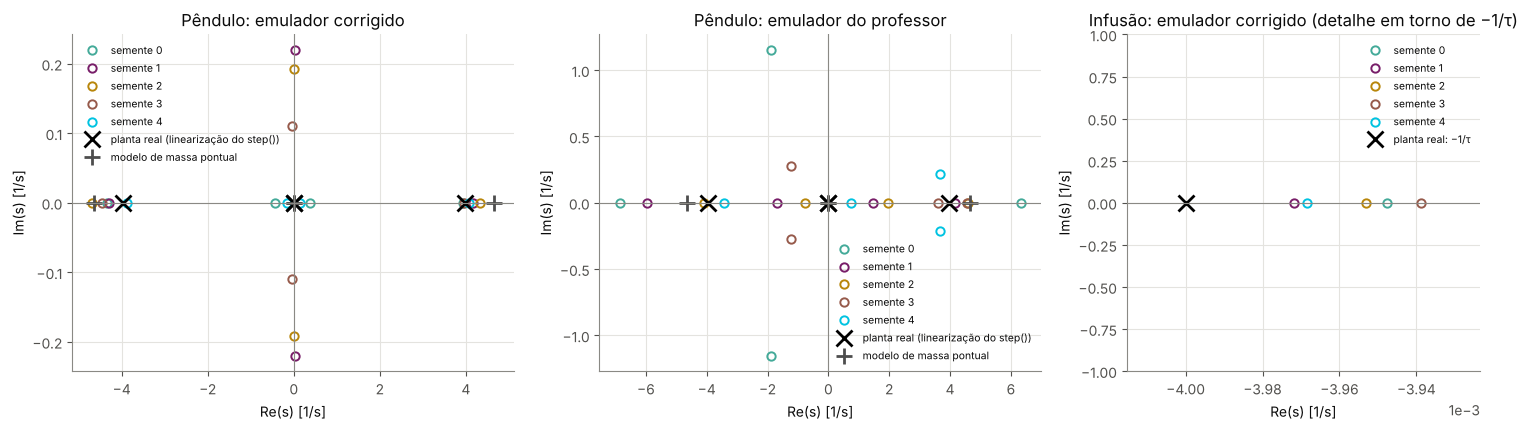

**Figura `emulador_polos.png`.** Polos da linearização dos emuladores na origem, em tempo contínuo, nas 5 sementes: carro-pêndulo com o emulador corrigido e com o do professor, s = autovalores de (A_emu − I)/dt, ao lado dos polos da linearização do step() e do modelo de massa pontual; infusão com o emulador corrigido, s = ln(A_emu)/Ts, ao lado de −1/τ (eixo real só em torno desses polos).

In [23]:
# Polos da linearização dos emuladores na origem, em tempo contínuo.
POLOS_EMULADOR_PEND, POLOS_EMULADOR_INF = {}, {}
for (tipo, s), (emulador, _, _) in TREINO["emuladores"].items():
    A_emu, B_emu = jacobiana_emulador(emulador, planta)
    POLOS_EMULADOR_PEND[(tipo, s)] = np.sort_complex(np.linalg.eigvals((A_emu - np.eye(4)) / dt).astype(complex))
    registrar_caracterizacao(f"emulador/pendulo/{tipo}/semente{s}", {"polos": POLOS_EMULADOR_PEND[(tipo, s)], "A": A_emu, "B": B_emu})
for (tipo, s), (emulador, _, _) in TREINO_INF["emuladores"].items():
    A_emu, B_emu = jacobiana_emulador(emulador, planta_inf)
    POLOS_EMULADOR_INF[s] = np.array([np.log(complex(A_emu[0, 0])) / planta_inf.dt])
    registrar_caracterizacao(f"emulador/infusao/{tipo}/semente{s}", {"polo": POLOS_EMULADOR_INF[s], "A": A_emu, "B": B_emu})
Ac_massa_pontual = np.array([[0, 1, 0, 0], [0, 0, -m * g / M, 0], [0, 0, 0, 1], [0, 0, g * (M + m) / (l * M), 0]], dtype=np.float64)
polos_massa_pontual = np.sort_complex(np.linalg.eigvals(Ac_massa_pontual).astype(complex))
registrar_caracterizacao("emulador/referencias", {"polos_planta_pendulo": polos_sistema, "polos_massa_pontual": polos_massa_pontual,
                                                  "polo_planta_infusao": -1 / planta_inf.tau})
linhas = [{"planta": "pêndulo", "emulador": tipo, "semente": s, "polos [1/s]": ", ".join(f"{v:.3f}" for v in p_)}
          for (tipo, s), p_ in sorted(POLOS_EMULADOR_PEND.items())]
linhas += [{"planta": "infusão", "emulador": "corrigido", "semente": s, "polos [1/s]": ", ".join(f"{v.real:.6f}" for v in p_)}
           for s, p_ in sorted(POLOS_EMULADOR_INF.items())]
linhas += [{"planta": "pêndulo", "emulador": "planta real", "semente": "—", "polos [1/s]": ", ".join(f"{v:.3f}" for v in polos_sistema)},
           {"planta": "pêndulo", "emulador": "massa pontual", "semente": "—", "polos [1/s]": ", ".join(f"{v:.3f}" for v in polos_massa_pontual)},
           {"planta": "infusão", "emulador": "planta real", "semente": "—", "polos [1/s]": f"{-1 / planta_inf.tau:.6f}"}]


def resumo_polos(polos_por_semente, limiar=0.5):
    """Maior e menor Re(s) e número de polos com Re(s) > limiar [1/s], por semente: 'mediana (mín a máx)' nas sementes."""
    maior = [float(np.max(np.real(p_))) for p_ in polos_por_semente]
    menor = [float(np.min(np.real(p_))) for p_ in polos_por_semente]
    n_inst = [int(np.sum(np.real(p_) > limiar)) for p_ in polos_por_semente]
    return {"maior Re(s) [1/s]": texto_faixa(maior, "{:+.4g}"), "menor Re(s) [1/s]": texto_faixa(menor, "{:+.4g}"),
            "polos com Re(s) acima do limiar": texto_faixa(n_inst, "{:.0f}"),
            "sementes com mais de um": f"{sum(n > 1 for n in n_inst)} de {len(n_inst)}"}


resumo_polos_emu = pd.DataFrame({
    "pêndulo, emulador corrigido": resumo_polos([POLOS_EMULADOR_PEND[("corrigido", s)] for s in SEMENTES]),
    "pêndulo, emulador do professor": resumo_polos([POLOS_EMULADOR_PEND[("professor", s)] for s in SEMENTES]),
    "pêndulo, planta real": resumo_polos([polos_sistema]),
    "pêndulo, massa pontual": resumo_polos([polos_massa_pontual]),
    "infusão, emulador corrigido": resumo_polos([POLOS_EMULADOR_INF[s] for s in SEMENTES], limiar=0.0),
    "infusão, planta real": resumo_polos([np.array([-1 / planta_inf.tau])], limiar=0.0),
}).T
tabela_caracterizacao("emulador_polos", pd.DataFrame(linhas).set_index(["planta", "emulador", "semente"]),
               "Polos da linearização dos emuladores na origem, em tempo contínuo (pêndulo: autovalores de (A_emu − I)/dt; infusão: ln(A_emu)/Ts), "
               "por semente, e os da planta real e do modelo de massa pontual.", opcoes={"display.max_colwidth": 40},
               exibir=(resumo_polos_emu,
                       "Polos da linearização dos emuladores na origem, em tempo contínuo: maior e menor Re(s) e número de polos com Re(s) acima "
                       "de 0,5 s⁻¹ (pêndulo) ou de 0 (infusão), mediana (mín. a máx.) nas 5 sementes; planta real e modelo de massa pontual "
                       "com um valor. Por semente: caracterizacao__emulador_polos.csv."))
figura_emulador_polos(POLOS_EMULADOR_PEND, POLOS_EMULADOR_INF, polos_sistema, polos_massa_pontual, -1 / planta_inf.tau)

### 3.4 Calibração

- **Pêndulo:** RN(0) = 0 depois da calibração, no Keras e na versão numpy (a simulada), e a versão numpy igual à do Keras em 1000 estados sorteados (x ±1, ẋ ±1,5, θ ±1 rad, θ̇ ±3), em todas as RN (imitadas e refinadas, 7 variantes × 5 sementes).
- **Infusão:** u(C_ref) = u_ss depois da calibração, na versão numpy (δ em float64) e no Keras (float32), e numpy = Keras em 1000 valores de C entre 0 e 0,25.

In [24]:
# Pêndulo: RN(0) = 0 no Keras e no numpy, e numpy = Keras em 1000 estados sorteados.
gerador_teste = np.random.default_rng(12345)   # gerador próprio
estados_teste = (gerador_teste.uniform(-1, 1, (1000, planta.n_estados)) * CAIXA_TESTE).astype(np.float32)
x_eq_tf = tf.constant(planta.x_eq.reshape(1, -1), dtype=tf.float32)

linhas_cal = []
pior_rn0_keras = pior_rn0_numpy = pior_numpy_keras = 0.0
for (variante, semente), rn in RNS.items():
    for etapa in ["imitada", "refinada"]:
        keras_c = rn[f"keras_{etapa}"]
        pol = rn[etapa]
        rn0_keras = abs(float(keras_c(x_eq_tf).numpy()[0, 0]) - planta.u_eq)
        rn0_numpy = abs(pol(planta.x_eq) - planta.u_eq)
        dif = float(np.max(np.abs(pol.vetorizado(estados_teste) - keras_c(tf.constant(estados_teste)).numpy()[:, 0])))
        pior_rn0_keras, pior_rn0_numpy, pior_numpy_keras = max(pior_rn0_keras, rn0_keras), max(pior_rn0_numpy, rn0_numpy), max(pior_numpy_keras, dif)
        cal = rn["calibracao"][etapa]
        linhas_cal.append({"variante": variante, "semente": semente, "etapa": etapa, "RN(0) antes [N]": cal["f0"],
                           "resíduo com 1 aplicação [N]": cal["residuo_1_aplicacao"], "aplicações": cal["iteracoes"],
                           "|RN(0)| Keras [N]": rn0_keras, "|RN(0)| numpy [N]": rn0_numpy, "máx |numpy − Keras| [N]": dif})
TAB_CAL = pd.DataFrame(linhas_cal)
verificar("calibracao-keras — pêndulo: RN(0) = 0 a 1e-6 N depois da calibração (Keras), em todas as RN", pior_rn0_keras < 1e-6, f"pior |RN(0)| = {pior_rn0_keras:.1e} N", tol="1e-6 N")
# Tolerância de 1e-5 N, a mesma de numpy = Keras: a versão numpy usa o offset calculado pela calibração no Keras (float32), e o
# resíduo dela fica limitado pela diferença numpy × Keras.
verificar("calibracao-numpy — pêndulo: RN(0) = 0 a 1e-5 N depois da calibração (numpy, a versão simulada)", pior_rn0_numpy < 1e-5, f"pior |RN(0)| = {pior_rn0_numpy:.1e} N", tol="1e-5 N")
verificar("numpy-igual-keras — pêndulo: numpy = Keras a 1e-5 N em 1000 estados sorteados, em todas as RN", pior_numpy_keras < 1e-5, f"pior diferença = {pior_numpy_keras:.1e} N", tol="1e-5 N")
registrar_tabela("pendulo/calibracao", TAB_CAL)

# Infusão: u(C_ref) = u_ss (numpy a 1e-9·u_max; Keras, em float32, a 1e-6·u_max) e numpy = Keras em 1000 valores de C.
estados_teste_inf = np.random.default_rng(12345).uniform(0.0, 0.25, (1000, 1)).astype(np.float32)
linhas_cal_inf = []
pior_numpy_inf = pior_keras_inf = pior_nk_inf = 0.0
for (variante, semente), rn in RNS_INF.items():
    for etapa in ["imitada", "refinada"]:
        keras_c, pol, cal = rn[f"keras_{etapa}"], rn[etapa], rn["calibracao"][etapa]
        u_numpy = abs(pol(planta_inf.x_eq) - planta_inf.u_eq)
        u_keras = abs(float(keras_c(tf.constant(planta_inf.x_eq.reshape(1, -1), dtype=tf.float32)).numpy()[0, 0]) - planta_inf.u_eq)
        dif = float(np.max(np.abs(pol.vetorizado(estados_teste_inf) - keras_c(tf.constant(estados_teste_inf)).numpy()[:, 0])))
        pior_numpy_inf, pior_keras_inf, pior_nk_inf = max(pior_numpy_inf, u_numpy), max(pior_keras_inf, u_keras), max(pior_nk_inf, dif)
        linhas_cal_inf.append({"variante": variante, "semente": semente, "etapa": etapa, "u(C_ref) antes [mL/s]": cal["f0"],
                               "δ": cal["offset"], "|u(C_ref) − u_ss| numpy [u_max]": u_numpy / planta_inf.u_max,
                               "|u(C_ref) − u_ss| Keras [u_max]": u_keras / planta_inf.u_max, "máx |numpy − Keras| [u_max]": dif / planta_inf.u_max})
TAB_CAL_INF = pd.DataFrame(linhas_cal_inf)
verificar("infusao-calibracao-numpy — infusão: u(C_ref) = u_ss a 1e-9·u_max depois da calibração (numpy, a versão simulada), em todas as RN",
          pior_numpy_inf < 1e-9 * planta_inf.u_max, f"pior |u(C_ref) − u_ss| = {pior_numpy_inf / planta_inf.u_max:.1e}·u_max", tol="1e-9·u_max")
verificar("infusao-calibracao-keras — infusão: no Keras (float32), u(C_ref) = u_ss a 1e-6·u_max, e numpy = Keras a 1e-6·u_max em 1000 estados",
          pior_keras_inf < 1e-6 * planta_inf.u_max and pior_nk_inf < 1e-6 * planta_inf.u_max,
          f"pior |u(C_ref) − u_ss| Keras = {pior_keras_inf / planta_inf.u_max:.1e}·u_max; pior |numpy − Keras| = {pior_nk_inf / planta_inf.u_max:.1e}·u_max", tol="1e-6·u_max")
registrar_tabela("infusao/calibracao", TAB_CAL_INF)

resumo_cal = TAB_CAL.groupby(["variante", "etapa"], sort=False).agg(**{
    "aplicações (máx.)": ("aplicações", "max"), "|RN(0)| Keras, máx. [N]": ("|RN(0)| Keras [N]", "max"),
    "|RN(0)| numpy, máx. [N]": ("|RN(0)| numpy [N]", "max"), "|numpy − Keras|, máx. [N]": ("máx |numpy − Keras| [N]", "max")})
mostrar_tabela(resumo_cal, "Calibração das RN do carro-pêndulo, por variante e etapa (máximo nas 5 sementes): número de aplicações da calibração "
               "do professor, |RN(0)| depois dela no Keras e no numpy, e a maior diferença numpy × Keras em 1000 estados. Por semente: "
               "pendulo__calibracao.csv.", opcoes={"display.float_format": lambda v: f"{v:.2e}"})

calibracao-keras: OK | pior |RN(0)| = 3.7e-08 N | tolerância: 1e-6 N
calibracao-numpy: OK | pior |RN(0)| = 5.4e-07 N | tolerância: 1e-5 N
numpy-igual-keras: OK | pior diferença = 4.4e-06 N | tolerância: 1e-5 N
infusao-calibracao-numpy: OK | pior |u(C_ref) − u_ss| = 8.7e-17·u_max | tolerância: 1e-9·u_max
infusao-calibracao-keras: OK | pior |u(C_ref) − u_ss| Keras = 5.2e-09·u_max; pior |numpy − Keras| = 6.0e-07·u_max | tolerância: 1e-6·u_max


**Tabela.** Calibração das RN do carro-pêndulo, por variante e etapa (máximo nas 5 sementes): número de aplicações da calibração do professor, |RN(0)| depois dela no Keras e no numpy, e a maior diferença numpy × Keras em 1000 estados. Por semente: pendulo__calibracao.csv.

aplicações (máx.)  |RN(0)| Keras, máx. [N]  |RN(0)| numpy, máx. [N]  |numpy − Keras|, máx. [N]
variante     etapa                                                                                                   
RN           imitada                   2                 9.31e-09                 1.15e-07                   4.20e-06
             refinada                  2                 0.00e+00                 2.74e-07                   4.33e-06
RN-direta    imitada                   2                 9.31e-09                 1.15e-07                   4.20e-06
             refinada                  2                 3.73e-08                 2.03e-07                   3.42e-06
RN-C4        imitada                   2                 0.00e+00                 2.86e-07                   3.66e-06
             refinada                  2                 0.00e+00                 5.39e-07                   4.43e-06
RN-C4-direta imitada                   2                 0.00e+00                 2.86e-07                   3.66e-06
             refinada                  2                 0.00e+00                 2.61e-07                   3.95e-06

### 3.5 Curvas de treino

Registra as perdas de treino de todas as etapas e sementes (emulador a cada 100 épocas, o do professor a cada 50, imitação a cada 50 e refinamento a cada época) e desenha as curvas da variante `RN` na **semente mediana** de cada planta: a semente cuja RN refinada tem o J mediano no C1.

In [25]:
def semente_mediana(res, cond, variante="RN"):
    """A semente cuja RN refinada tem o J mediano na condição dada (com 5 sementes, a 3ª em ordem de J)."""
    js = sorted((res[(rotulo_rn(variante, "refinada", s), cond)]["J"], s) for s in SEMENTES)
    return js[len(js) // 2][1]


def curva(perdas):
    h = np.asarray(perdas, dtype=float)
    return (h[:, 0], h[:, 1]) if h.ndim == 2 and len(h) else (np.arange(len(h)), h)


def painel(eixo, perdas, titulo, ylabel, cor, log=True):
    x, y_ = curva(perdas)
    if len(y_):
        (eixo.semilogy if log else eixo.plot)(x, y_, color=cor)
    else:
        eixo.text(0.5, 0.5, "histórico não gravado", ha="center", va="center", transform=eixo.transAxes, fontsize=9, color="#52514e")
    eixo.set(title=titulo, xlabel="época", ylabel=ylabel)


def figura_treino(chave_planta, treino, rns, s, imit):
    paineis = [("emulador corrigido (3000 épocas)", treino["emuladores"][("corrigido", s)][1]["perdas"], "perda (unidades normalizadas, log)", COR_AUX["destaque 1"], True)]
    if chave_planta == "pendulo":
        paineis.append(("emulador do professor (501 épocas)", treino["emuladores"][("professor", s)][1]["perdas"], "perda (MSE no estado, sem normalizar, log)", COR_AUX["emulador do professor"], True))
    paineis += [("imitação do LQR (501 épocas)", treino["imitados"][(imit, s)][1]["perdas"], "perda (MSE do comando" + (", N², log)" if chave_planta == "pendulo" else ", em u_max², log)"), COR["RN imitada"], True),
                ("refinamento pelo emulador (201 épocas)", rns[("RN", s)]["perdas_refinamento"], "perda do refinamento (100 passos" + (")" if chave_planta == "pendulo" else ", ponderada)"), COR["RN refinada"], False)]
    fig, eixos = plt.subplots(1, len(paineis), figsize=(4.2 * len(paineis), 3.8))
    for eixo, (titulo, perdas, ylabel, cor, log) in zip(eixos, paineis):
        painel(eixo, perdas, titulo, ylabel, cor, log)
    nome_planta = "carro-pêndulo" if chave_planta == "pendulo" else "infusão"
    fig.suptitle(f"Treino da RN, {nome_planta}, semente {s} (a mediana)", y=1.02)
    plt.tight_layout()
    if chave_planta == "pendulo":
        legenda = (f"Perdas de treino da RN do carro-pêndulo (variante RN), semente mediana s{s}: emulador corrigido (3000 épocas, unidades "
                   "normalizadas), emulador do professor (501 épocas, MSE no estado), imitação do LQR (501 épocas, MSE do comando em N²) e "
                   "refinamento pelo emulador corrigido (201 épocas, perda do refinamento com 100 passos).")
    else:
        legenda = (f"Perdas de treino da RN da infusão (variante RN), semente mediana s{s}: emulador corrigido (3000 épocas, unidades "
                   "normalizadas), imitação do LQR (501 épocas, MSE do comando em frações de u_max) e refinamento pelo emulador corrigido "
                   "(201 épocas, perda do refinamento ponderada, com 100 passos).")
    salvar_figura(fig, f"treino_{chave_planta}", legenda)

**Tabela.** Semente mediana de cada planta: a semente cuja RN refinada (variante RN) tem o J mediano no C1.

,semente mediana,"J da RN refinada no C1, mediana (mín. a máx.)"
pêndulo (θ₀ = 15°),0,0.494 (0.48861 a 0.5085)
"infusão (C₀ = 0,14)",3,0.0046385 (0.0046349 a 0.0046425)


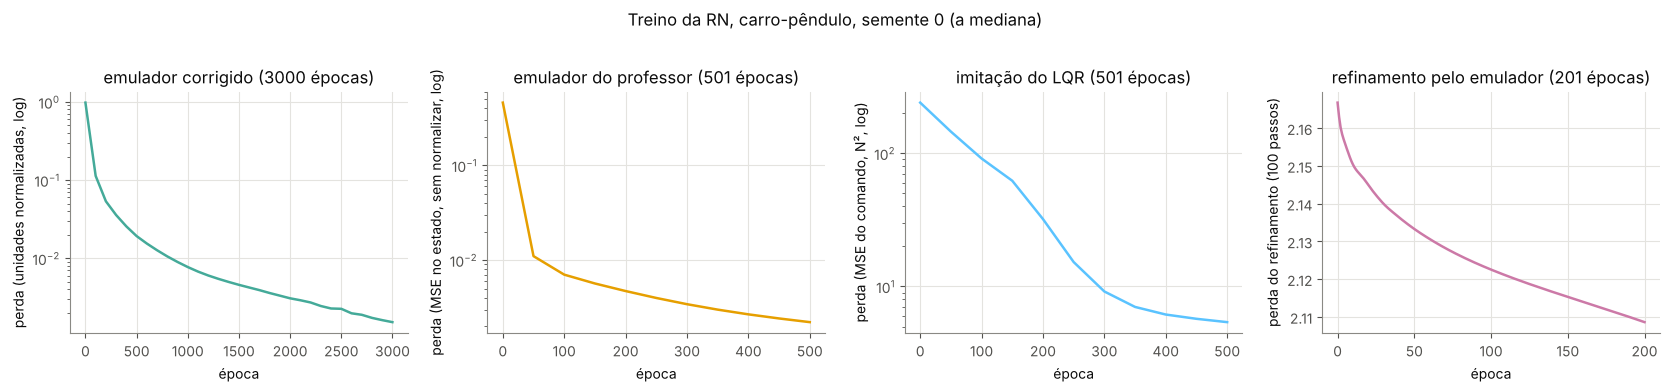

**Figura `treino_pendulo.png`.** Perdas de treino da RN do carro-pêndulo (variante RN), semente mediana s0: emulador corrigido (3000 épocas, unidades normalizadas), emulador do professor (501 épocas, MSE no estado), imitação do LQR (501 épocas, MSE do comando em N²) e refinamento pelo emulador corrigido (201 épocas, perda do refinamento com 100 passos).

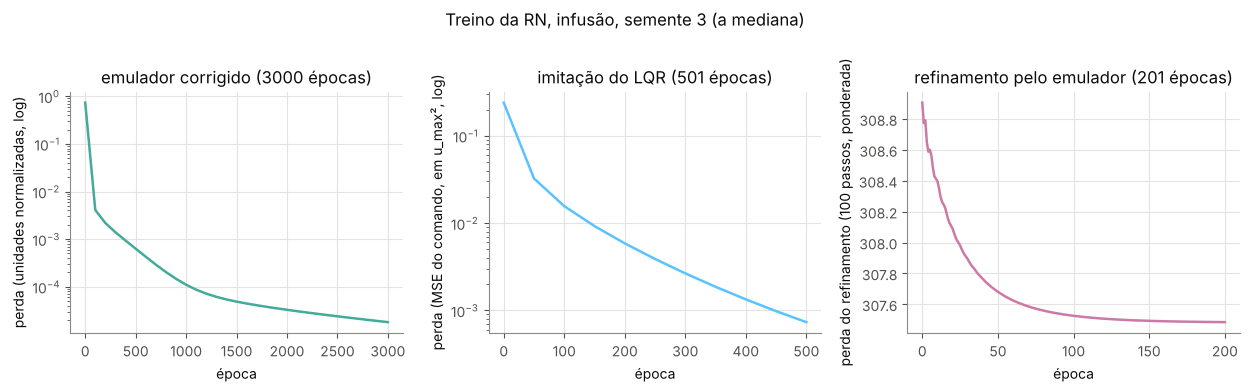

**Figura `treino_infusao.png`.** Perdas de treino da RN da infusão (variante RN), semente mediana s3: emulador corrigido (3000 épocas, unidades normalizadas), imitação do LQR (501 épocas, MSE do comando em frações de u_max) e refinamento pelo emulador corrigido (201 épocas, perda do refinamento ponderada, com 100 passos).

In [26]:
registrar_historicos(planta, TREINO, RNS)
registrar_historicos(planta_inf, TREINO_INF, RNS_INF)

# Semente mediana: J da RN refinada (variante RN) no C1 de cada planta.
J_C1_RN = {(rotulo_rn("RN", "refinada", s), C1_ANGULO): {"J": metricas(planta, simular(planta, RNS[("RN", s)]["refinada"], estado_inicial_pendulo(C1_ANGULO)))["J"]}
           for s in SEMENTES}
J_C1_RN_INF = {(rotulo_rn("RN", "refinada", s), C1_INF): {"J": metricas(planta_inf, simular(planta_inf, RNS_INF[("RN", s)]["refinada"], estado_inicial_infusao(C1_INF)))["J"]}
               for s in SEMENTES}
S_MED_PEND = semente_mediana(J_C1_RN, C1_ANGULO)
S_MED_INF = semente_mediana(J_C1_RN_INF, C1_INF)
registrar_numeros("matriz/semente_mediana", {"pendulo": S_MED_PEND, "infusao": S_MED_INF})
mostrar_tabela(pd.DataFrame({"semente mediana": [S_MED_PEND, S_MED_INF],
                             "J da RN refinada no C1, mediana (mín. a máx.)": [texto_faixa([J_C1_RN[(rotulo_rn('RN', 'refinada', s), C1_ANGULO)]['J'] for s in SEMENTES], "{:.5g}"),
                                                                              texto_faixa([J_C1_RN_INF[(rotulo_rn('RN', 'refinada', s), C1_INF)]['J'] for s in SEMENTES], "{:.5g}")]},
                            index=["pêndulo (θ₀ = 15°)", "infusão (C₀ = 0,14)"]),
               "Semente mediana de cada planta: a semente cuja RN refinada (variante RN) tem o J mediano no C1.")
figura_treino("pendulo", TREINO, RNS, S_MED_PEND, "imit-correto")
figura_treino("infusao", TREINO_INF, RNS_INF, S_MED_INF, "imit-lqr")

### 3.6 Lei de controle aprendida

Cortes da lei de controle da variante `RN`, imitada e refinada (semente mediana, com a faixa das 5 sementes), ao lado do LQR:
- **pêndulo:** F(θ) com x = ẋ = θ̇ = 0, para θ de −1 a 1 rad, e a lei do LQR correto, $F = \mathrm{clip}(-K_{\theta}\,\theta,\ \pm 20\ \mathrm{N})$, com $K_\theta$ o ganho de θ; a caixa de imitação (±0,35 rad) e o limite de ±20 N marcados;
- **infusão:** u(C) para C de 0 a 0,25 e a lei do LQR, $u = \mathrm{clip}\big(u_{ss} - K\,(C - C_{ref}),\ 0,\ u_{max}\big)$.

A inclinação no alvo é medida por diferença central com passo 1e-5: $-\partial F/\partial\theta$ em θ = 0 no pêndulo e $K_{ef} = -\partial u/\partial C$ em C_ref na infusão (`ganho_local`).

In [27]:
def ganho_local(politica, h=1e-5):
    """Ganho local K_ef = −du/dC em C_ref de um controlador da infusão, por diferença central."""
    return -(politica([planta_inf.C_ref + h]) - politica([planta_inf.C_ref - h])) / (2 * h)


def inclinacao_theta(politica, h=1e-5):
    """−∂F/∂θ em θ = 0 (com x = ẋ = θ̇ = 0) de um controlador do pêndulo, por diferença central."""
    return -(politica([0.0, 0.0, h, 0.0]) - politica([0.0, 0.0, -h, 0.0])) / (2 * h)


def corte(politicas, estados):
    """Comando de cada política em cada estado (uma linha por política)."""
    return np.array([[float(p(e)) for e in estados] for p in politicas])


def figura_lei_pendulo(theta, F_imit, F_ref, F_lqr, s, caixa, limite):
    fig, eixo = plt.subplots(figsize=(9, 4.8))
    for F, nome in [(F_imit, "RN imitada"), (F_ref, "RN refinada")]:
        eixo.fill_between(theta, F.min(axis=0), F.max(axis=0), color=COR[nome], alpha=0.18, lw=0)
        eixo.plot(theta, F[s], color=COR[nome], label=f"{nome} (s{s}; faixa = 5 sementes)")
    eixo.plot(theta, F_lqr, color=COR["LQR correto"], label="LQR correto, clip(−K_θ·θ, ±20 N)")
    eixo.axvline(-caixa, color=COR_AUX["destaque 2"], ls="-.", lw=1.0, label="caixa de imitação: ±0,35 rad")
    eixo.axvline(caixa, color=COR_AUX["destaque 2"], ls="-.", lw=1.0)
    eixo.axhline(limite, color=COR_AUX["cinza escuro"], ls="--", lw=0.9, label="limite: ±20 N")
    eixo.axhline(-limite, color=COR_AUX["cinza escuro"], ls="--", lw=0.9)
    eixo.set(xlabel="θ [rad] (demais estados nulos)", ylabel="F [N]", title="Carro-pêndulo: corte F(θ) da lei de controle")
    eixo.legend(fontsize=8.5, loc="lower right")
    plt.tight_layout()
    salvar_figura(fig, "RN_lei_de_controle_pendulo",
                  f"Corte F(θ) da lei de controle do carro-pêndulo, com x = ẋ = θ̇ = 0 e θ de −1 a 1 rad: RN imitada e RN refinada (variante RN, "
                  f"semente mediana s{s}; faixa = mínimo a máximo das 5 sementes) e LQR correto, clip(−K_θ·θ, ±20 N); caixa de imitação (±0,35 rad) "
                  "e limite de ±20 N marcados.")


def figura_lei_infusao(C, u_imit, u_ref, u_lqr, s, k_lqr, k_imit, k_ref):
    fig, eixo = plt.subplots(figsize=(9, 4.8))
    for u, nome, k in [(u_imit, "RN imitada", k_imit), (u_ref, "RN refinada", k_ref)]:
        eixo.fill_between(C, 1e3 * u.min(axis=0), 1e3 * u.max(axis=0), color=COR[nome], alpha=0.18, lw=0)
        eixo.plot(C, 1e3 * u[s], color=COR[nome], label=f"{nome} (s{s}; faixa = 5 sementes); K_ef = {k:.3f} = {k / k_lqr:.3f}·K".replace(".", ","))
    eixo.plot(C, 1e3 * u_lqr, color=COR["LQR"], label=f"LQR, clip(u_ss − K·(C − C_ref), 0, u_max); K = {k_lqr:.4f}".replace(".", ","))
    eixo.axvline(planta_inf.C_ref, color=COR_AUX["cinza"], lw=0.8)
    eixo.axhline(1e3 * planta_inf.u_eq, color=COR_AUX["cinza"], lw=0.8)
    eixo.set(xlabel="C (concentração)", ylabel="u [10⁻³ mL/s]", title="Infusão: lei de controle u(C)")
    eixo.legend(fontsize=8.5, loc="lower left")
    plt.tight_layout()
    salvar_figura(fig, "RN_lei_de_controle_infusao",
                  f"Lei de controle u(C) da infusão, para C de 0 a 0,25: RN imitada e RN refinada (variante RN, semente mediana s{s}; faixa = "
                  "mínimo a máximo das 5 sementes) e LQR com recorte em [0, u_max]; inclinação no alvo, K_ef = −du/dC em C_ref, anotada.")

**Tabela `caracterizacao__RN_lei_inclinacao.csv`.** Inclinação da lei de controle no alvo, por diferença central (passo 1e-5): −∂F/∂θ em θ = 0 no carro-pêndulo e K_ef = −du/dC em C_ref na infusão, relativo ao K do LQR; RN da variante RN, mediana e faixa de 5 sementes.

,pêndulo: −∂F/∂θ em θ = 0 [N/rad],pêndulo: mín. a máx. entre sementes,infusão: K_ef / K,infusão: mín. a máx. entre sementes
LQR,-71.75,—,1,—
RN imitada (mediana),-109.2,-110.23 a -107.71,0.8628,0.818 a 0.872
RN refinada (mediana),-115.5,-159.52 a -98.55,1.456,1.436 a 1.464


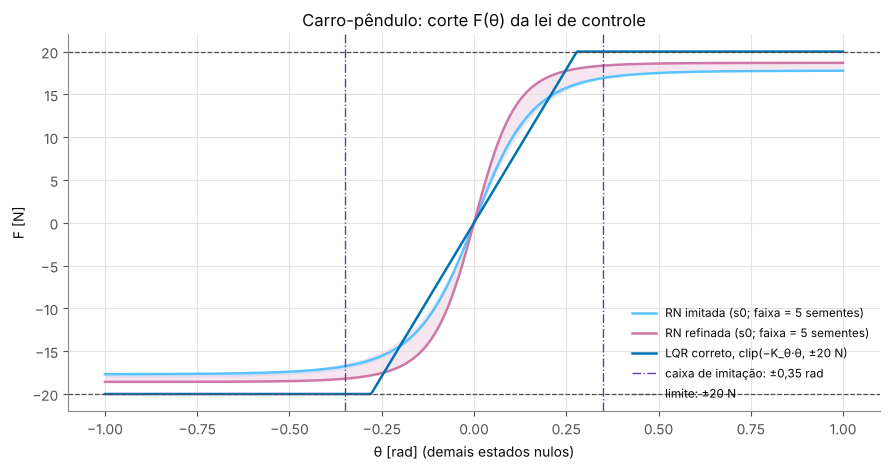

**Figura `RN_lei_de_controle_pendulo.png`.** Corte F(θ) da lei de controle do carro-pêndulo, com x = ẋ = θ̇ = 0 e θ de −1 a 1 rad: RN imitada e RN refinada (variante RN, semente mediana s0; faixa = mínimo a máximo das 5 sementes) e LQR correto, clip(−K_θ·θ, ±20 N); caixa de imitação (±0,35 rad) e limite de ±20 N marcados.

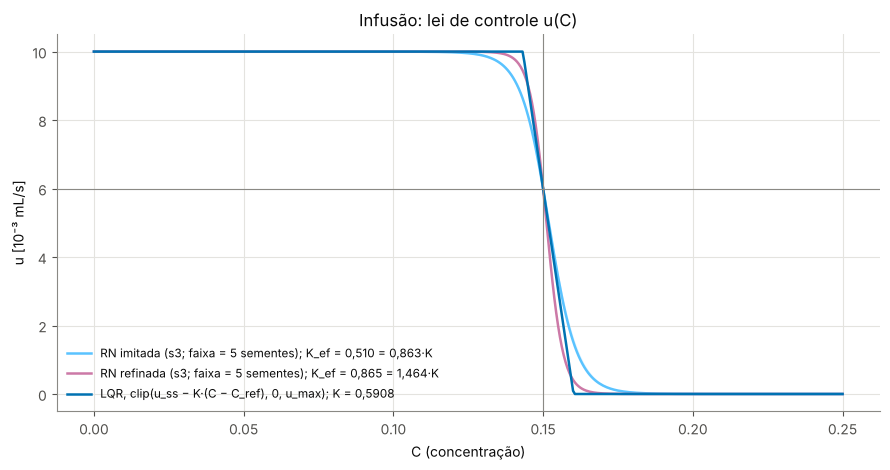

**Figura `RN_lei_de_controle_infusao.png`.** Lei de controle u(C) da infusão, para C de 0 a 0,25: RN imitada e RN refinada (variante RN, semente mediana s3; faixa = mínimo a máximo das 5 sementes) e LQR com recorte em [0, u_max]; inclinação no alvo, K_ef = −du/dC em C_ref, anotada.

In [28]:
# Pêndulo: corte F(θ).
theta_corte = np.linspace(-1.0, 1.0, 401)
estados_corte = [[0.0, 0.0, th, 0.0] for th in theta_corte]
F_imit = corte([RNS[("RN", s)]["imitada"] for s in SEMENTES], estados_corte)
F_ref = corte([RNS[("RN", s)]["refinada"] for s in SEMENTES], estados_corte)
lqr_correto_politica = PoliticaLQR(planta, K_correto)
F_lqr = np.array([lqr_correto_politica(e) for e in estados_corte])
incl_pend = {"LQR correto": inclinacao_theta(lqr_correto_politica)}
for s in SEMENTES:
    incl_pend[f"RN imitada s{s}"] = inclinacao_theta(RNS[("RN", s)]["imitada"])
    incl_pend[f"RN refinada s{s}"] = inclinacao_theta(RNS[("RN", s)]["refinada"])
registrar_caracterizacao("RN_lei/pendulo/inclinacao_em_theta0", incl_pend)
registrar_caracterizacao("RN_lei/pendulo", {"K_theta_LQR_correto": -K_correto[0, 2]})

# Infusão: u(C).
C_corte = np.linspace(0.0, 0.25, 401)
estados_corte_inf = [[c] for c in C_corte]
u_imit = corte([RNS_INF[("RN", s)]["imitada"] for s in SEMENTES], estados_corte_inf)
u_ref = corte([RNS_INF[("RN", s)]["refinada"] for s in SEMENTES], estados_corte_inf)
lqr_inf_politica = PoliticaLQR(planta_inf, K_inf)
u_lqr = np.array([lqr_inf_politica(e) for e in estados_corte_inf])
k_ef_imit = {s: ganho_local(RNS_INF[("RN", s)]["imitada"]) for s in SEMENTES}
k_ef_ref = {s: ganho_local(RNS_INF[("RN", s)]["refinada"]) for s in SEMENTES}
registrar_caracterizacao("RN_lei/infusao/K_ef", {"LQR": ganho_local(lqr_inf_politica), **{f"RN imitada s{s}": k for s, k in k_ef_imit.items()},
                                                **{f"RN refinada s{s}": k for s, k in k_ef_ref.items()}})
registrar_caracterizacao("RN_lei/infusao/K_ef_por_K", {**{f"RN imitada s{s}": k / K_nom_inf for s, k in k_ef_imit.items()},
                                                      **{f"RN refinada s{s}": k / K_nom_inf for s, k in k_ef_ref.items()}})
tabela_caracterizacao("RN_lei_inclinacao", pd.DataFrame({
    "pêndulo: −∂F/∂θ em θ = 0 [N/rad]": [incl_pend["LQR correto"]] + [np.median([incl_pend[f"RN {e} s{s}"] for s in SEMENTES]) for e in ["imitada", "refinada"]],
    "pêndulo: mín. a máx. entre sementes": ["—"] + [f"{min(incl_pend[f'RN {e} s{s}'] for s in SEMENTES):.2f} a {max(incl_pend[f'RN {e} s{s}'] for s in SEMENTES):.2f}" for e in ["imitada", "refinada"]],
    "infusão: K_ef / K": [1.0, np.median([k / K_nom_inf for k in k_ef_imit.values()]), np.median([k / K_nom_inf for k in k_ef_ref.values()])],
    "infusão: mín. a máx. entre sementes": ["—"] + [f"{min(k.values()) / K_nom_inf:.3f} a {max(k.values()) / K_nom_inf:.3f}" for k in [k_ef_imit, k_ef_ref]],
}, index=["LQR", "RN imitada (mediana)", "RN refinada (mediana)"]),
    "Inclinação da lei de controle no alvo, por diferença central (passo 1e-5): −∂F/∂θ em θ = 0 no carro-pêndulo e K_ef = −du/dC em C_ref "
    "na infusão, relativo ao K do LQR; RN da variante RN, mediana e faixa de 5 sementes.", opcoes={"display.float_format": lambda v: f"{v:.4g}"})
figura_lei_pendulo(theta_corte, F_imit, F_ref, F_lqr, S_MED_PEND, planta.caixa_imitacao[2], planta.u_max)
figura_lei_infusao(C_corte, u_imit, u_ref, u_lqr, S_MED_INF, K_nom_inf, k_ef_imit[S_MED_INF], k_ef_ref[S_MED_INF])

### 3.7 Reprodutibilidade do treino

A variante `RN` é treinada duas vezes, do zero, na semente 0, nas duas plantas, sem ler nem gravar o cache, e os dois retreinos são comparados: os pesos da RN imitada (antes e depois da calibração) e da refinada, bit a bit, e o J do C1, que tem de ser igual. Os pesos do cache não entram nesta verificação.

In [29]:
def verificar_reprodutibilidade(planta, x0):
    """Retreina a variante RN na semente 0 duas vezes, sem cache, e compara os dois retreinos: pesos, bit a bit, e J do C1."""
    retreinos = [montar_rns(planta, [0], usar_cache=False, variantes=["RN"])["rns"][("RN", 0)] for _ in range(2)]
    resultado = {}
    for etapa, chaves in [("imitada", ["keras_imitada_crua", "keras_imitada"]), ("refinada", ["keras_refinada"])]:
        pesos = all(pesos_iguais(retreinos[0][c], retreinos[1][c]) for c in chaves)
        j = [metricas(planta, simular(planta, r[etapa], x0))["J"] for r in retreinos]
        resultado[etapa] = (pesos, abs(j[0] - j[1]))
    return resultado

In [30]:
x0_c1 = estado_inicial_pendulo(C1_ANGULO)
x0_c1_inf = estado_inicial_infusao(C1_INF)
for nome_planta, chave, p_, x0_ in [("pêndulo", "pendulo", planta, x0_c1), ("infusão", "infusao", planta_inf, x0_c1_inf)]:
    t0_repro = time.perf_counter()
    repro_ = verificar_reprodutibilidade(p_, x0_)
    TEMPOS[f"{chave}/reprodutibilidade [s]"] = time.perf_counter() - t0_repro
    for etapa, (pesos, dif) in repro_.items():
        verificar(f"reprodutibilidade-{chave}-{etapa} — {nome_planta}: RN {etapa}, semente 0, dois retreinos na mesma execução: pesos bit a bit e J do C1 iguais",
                  pesos and dif == 0.0, f"pesos iguais: {'sim' if pesos else 'não'}; diferença de J: {dif:.1e}", tol="igualdade exata")

reprodutibilidade-pendulo-imitada: OK | pesos iguais: sim; diferença de J: 0.0e+00 | tolerância: igualdade exata
reprodutibilidade-pendulo-refinada: OK | pesos iguais: sim; diferença de J: 0.0e+00 | tolerância: igualdade exata


reprodutibilidade-infusao-imitada: OK | pesos iguais: sim; diferença de J: 0.0e+00 | tolerância: igualdade exata
reprodutibilidade-infusao-refinada: OK | pesos iguais: sim; diferença de J: 0.0e+00 | tolerância: igualdade exata


### 3.8 Linhas de controle

**Carro-pêndulo (C4).** Duas leis lineares por semente, com os mesmos dados de identificação e o mesmo emulador corrigido da `RN-C4` daquela semente:
1. **`LQR-identificado`:** mínimos quadrados de $x^+ = A\,x + B\,u$ nos dados de treino do emulador, só nas amostras com |θ| < 0,35 rad; K pelo `solve_discrete_lqr` do professor, com o Q e o R dele.
2. **`LQR-aprox-refinado`:** parte do K aproximado e refina os 4 ganhos pelo emulador corrigido, com a perda do refinamento (3 condições iniciais, 100 passos, Q e R), 201 épocas e Adam com lr = 1e-2. No refinamento, o comando é $u = 20\tanh(-Kx/20)$ (`LeiLinearSuave`); na avaliação, $\mathrm{clip}(-Kx, \pm 20)$. Os ganhos refinados vão para o cache.

Verificação: ‖K_identificado − K_correto‖/‖K_correto‖ < 2 % em todas as sementes.

**Infusão.** O ganho local da RN refinada em C_ref, $K_{ef} = -du/dC$ (diferença central, passo 1e-5, na versão numpy calibrada), e duas leis lineares com recorte duro:
1. **`LQR-ganho-1,45K`:** $u = \mathrm{clip}(u_{ss} - 1{,}45\,K\,e,\ 0,\ u_{max})$;
2. **`LQR-ganho-Kef`:** $u = \mathrm{clip}(u_{ss} - K_{ef}\,e,\ 0,\ u_{max})$, com o $K_{ef}$ de cada semente.

In [31]:
class LeiLinearSuave(tf.Module):
    """u = u_eq + u_lim·tanh(−K(x − x_eq)/u_lim): a lei do LQR com a saturação suavizada, para o refinamento dos ganhos.

    Os 4 ganhos são as únicas variáveis treináveis. Na avaliação, o K refinado vai para a PoliticaLQR, com o recorte duro."""

    def __init__(self, planta, K0):
        super().__init__()
        self.K = tf.Variable(np.asarray(K0, dtype=np.float32).reshape(1, -1), name="K")
        self.x_eq = tf.constant(planta.x_eq, dtype=tf.float32)
        self.u_eq = float(planta.u_eq)
        self.lim = float(planta.u_max)

    def __call__(self, estado, training=False):
        return self.u_eq + self.lim * tf.tanh(-tf.matmul(estado - self.x_eq, self.K, transpose_b=True) / self.lim)


HIPER_LQR_REFINADO = dict(lr=1e-2, epocas=HIPER["epocas_refinamento"], lim_theta=0.35)


def obter_lqr_refinado(planta, semente, emulador, K0, usar_cache=True):
    """Refina os ganhos do LQR aproximado pelo emulador corrigido da semente, com cache."""
    config = dict(linha="LQR-aprox-refinado", K0=np.asarray(K0).tolist(), emulador="corrigido", cis=np.asarray(CIS).tolist(),
                  T=T_REF, epocas=HIPER_LQR_REFINADO["epocas"], lr=HIPER_LQR_REFINADO["lr"], saida_no_refinamento="u_lim*tanh(-Kx/u_lim)", semente=semente)
    caminho = arquivo_cache(planta, "LQR-aprox-refinado", "ganhos", semente)
    achado = carregar_cache(caminho, config) if usar_cache else None
    if achado:
        return np.asarray(achado[0][0], dtype=np.float64), achado[1], "cache"
    lei = LeiLinearSuave(planta, K0)
    lei, meta = refinar_controlador(planta, emulador, lei, CIS, T_REF, HIPER_LQR_REFINADO["epocas"], HIPER_LQR_REFINADO["lr"])
    liberar_memoria_tf()
    meta.update(config=como_json(config))
    if usar_cache:
        salvar_cache(caminho, [lei.K.numpy()], meta)
    return lei.K.numpy().astype(np.float64), meta, "treinado"


def identificar_linear(planta, X, Y, lim_theta):
    """Mínimos quadrados de x⁺ = A·x + B·u nos dados (X = [x, u], Y = x⁺), só nas amostras com |θ| < lim_theta."""
    n = planta.n_estados
    mascara = np.abs(X[:, 2]) < lim_theta
    Theta, *_ = np.linalg.lstsq(X[mascara].astype(np.float64), Y[mascara].astype(np.float64), rcond=None)
    return Theta[:n].T, Theta[n:n + 1].T, int(mascara.sum())


def dist_rel(M, M_ref):
    """‖M − M_ref‖/‖M_ref‖ (norma de Frobenius)."""
    return float(np.linalg.norm(np.asarray(M) - np.asarray(M_ref)) / np.linalg.norm(M_ref))

In [32]:
LQR_C4 = {}
for s in SEMENTES:
    X, Y = TREINO["dados"][s][:2]                  # os dados de identificação do emulador da semente
    t0 = time.perf_counter()
    A_id, B_id, n_amostras = identificar_linear(planta, X, Y, HIPER_LQR_REFINADO["lim_theta"])
    K_id = solve_discrete_lqr(A_id, B_id, Q, R)    # Riccati do professor, 500 iterações
    tempo_id = time.perf_counter() - t0
    P_id = scipy.linalg.solve_discrete_are(A_id, B_id, Q, R)
    K_id_scipy = np.linalg.solve(R + B_id.T @ P_id @ B_id, B_id.T @ P_id @ A_id)
    emulador = TREINO["emuladores"][("corrigido", s)][0]   # o emulador corrigido da RN-C4 desta semente
    K_ref, meta_ref, origem = obter_lqr_refinado(planta, s, emulador, K_aproximado)
    LQR_C4[s] = dict(A_id=A_id, B_id=B_id, K_id=K_id, K_ref=K_ref, n_amostras=n_amostras, perdas=meta_ref["perdas"],
                     tempo_id=tempo_id, tempo_ref=meta_ref["tempo"], origem=origem, riccati_vs_scipy=dist_rel(K_id, K_id_scipy))

linhas = []
for s, m_ in LQR_C4.items():
    linha = {"semente": s, "amostras usadas": m_["n_amostras"]}
    linha.update({f"K_identificado[{i}]": v for i, v in enumerate(m_["K_id"][0])})
    linha.update({f"K_aprox-refinado[{i}]": v for i, v in enumerate(m_["K_ref"][0])})
    linha.update({"‖A_id − A_correto‖/‖A_correto‖": dist_rel(m_["A_id"], Ad), "‖A_id − A_correto‖/‖A_correto − I‖": float(np.linalg.norm(m_["A_id"] - Ad) / np.linalg.norm(Ad - np.eye(4))),
                  "‖B_id − B_correto‖/‖B_correto‖": dist_rel(m_["B_id"], Bd), "‖K_id − K_correto‖/‖K_correto‖": dist_rel(m_["K_id"], K_correto),
                  "‖K_refinado − K_correto‖/‖K_correto‖": dist_rel(m_["K_ref"], K_correto), "‖K_aproximado − K_correto‖/‖K_correto‖": dist_rel(K_aproximado, K_correto),
                  "Riccati do professor × scipy (K_id)": m_["riccati_vs_scipy"]})
    linhas.append(linha)
TAB_GANHOS_C4 = pd.DataFrame(linhas).set_index("semente")
legenda_csv("pendulo__C4__linhas_de_controle_ganhos.csv", "Linhas de controle do C4, por semente: amostras usadas na identificação, ganhos "
            "do LQR-identificado e do LQR-aprox-refinado, e distâncias relativas (norma de Frobenius) aos A, B e K corretos.")
mostrar_tabela(resumo_por_coluna(TAB_GANHOS_C4), "Linhas de controle do C4: amostras usadas na identificação, ganhos do LQR-identificado e "
               "do LQR-aprox-refinado, e distâncias relativas (norma de Frobenius) aos A, B e K corretos; mediana (mín. a máx.) nas 5 "
               "sementes. Por semente: pendulo__C4__linhas_de_controle_ganhos.csv.")
registrar_tabela("pendulo/C4/linhas_de_controle_ganhos", TAB_GANHOS_C4)
for s, m_ in LQR_C4.items():
    registrar_matriz(f"pendulo/C4/LQR-identificado/semente{s}/A", m_["A_id"])
    registrar_matriz(f"pendulo/C4/LQR-identificado/semente{s}/B", m_["B_id"])
    for epoca, perda in enumerate(m_["perdas"]):
        NUMEROS[f"pendulo/treino/LQR-aprox-refinado/semente{s}/refinamento/epoca{epoca:04d}"] = float(perda)
    TEMPOS[f"pendulo/C4/LQR-identificado/semente{s}/tempo [s]"] = m_["tempo_id"]
    TEMPOS[f"pendulo/C4/LQR-aprox-refinado/semente{s}/tempo [s]"] = m_["tempo_ref"]

dist_K = TAB_GANHOS_C4["‖K_id − K_correto‖/‖K_correto‖"]
verificar("c4-lqr-identificado — C4: ‖K_identificado − K_correto‖/‖K_correto‖ < 2 % em todas as sementes", bool((dist_K < 0.02).all()),
          f"de {100 * dist_K.min():.2f} % a {100 * dist_K.max():.2f} % (K aproximado: {100 * dist_rel(K_aproximado, K_correto):.1f} %)", tol="2 %")

**Tabela.** Linhas de controle do C4: amostras usadas na identificação, ganhos do LQR-identificado e do LQR-aprox-refinado, e distâncias relativas (norma de Frobenius) aos A, B e K corretos; mediana (mín. a máx.) nas 5 sementes. Por semente: pendulo__C4__linhas_de_controle_ganhos.csv.

,mediana (mín. a máx.) nas 5 sementes
amostras usadas,2641 (2466 a 2659)
K_identificado[0],-7.255 (-7.385 a -7.236)
K_identificado[1],-10.04 (-10.1 a -9.986)
K_identificado[2],-72.19 (-72.37 a -72.03)
K_identificado[3],-18.49 (-18.51 a -18.46)
K_aprox-refinado[0],-5.695 (-6.317 a -5.36)
K_aprox-refinado[1],-8.179 (-8.423 a -8.105)
K_aprox-refinado[2],-67.16 (-67.47 a -64.19)
K_aprox-refinado[3],-15.79 (-15.86 a -15.68)
‖A_id − A_correto‖/‖A_correto‖,0.003259 (0.002423 a 0.003833)


c4-lqr-identificado: OK | de 0.46 % a 0.91 % (K aproximado: 9.7 %) | tolerância: 2 %


In [33]:
# Infusão: ganho local da RN refinada e as duas leis lineares com esse ganho.
GANHO_FIXO_INF = 1.45
K_EF_INF = {s: ganho_local(RNS_INF[("RN", s)]["refinada"]) for s in SEMENTES}
LQR_GANHO_FIXO = PoliticaLQR(planta_inf, GANHO_FIXO_INF * K_inf)
LINHAS_GANHO_INF = ([("LQR-ganho-1,45K", "LQR-ganho-1,45K", None, None, LQR_GANHO_FIXO)] +
                    [(f"LQR-ganho-Kef s{s}", "LQR-ganho-Kef", None, s, PoliticaLQR(planta_inf, K_EF_INF[s])) for s in SEMENTES])
FAMILIAS_GANHO = ("LQR-ganho-1,45K", "LQR-ganho-Kef")
K_EF_INF_DIRETA = {s: ganho_local(RNS_INF[("RN-direta", s)]["refinada"]) for s in SEMENTES}
TAB_KEF = pd.DataFrame({"K_ef da RN refinada": K_EF_INF, "K_ef / K do LQR": {s: k / K_inf[0, 0] for s, k in K_EF_INF.items()},
                        "K_ef da RN-direta refinada": K_EF_INF_DIRETA,
                        "K_ef / K do LQR, RN-direta refinada": {s: k / K_inf[0, 0] for s, k in K_EF_INF_DIRETA.items()}})
TAB_KEF.index.name = "semente"
legenda_csv("infusao__ganho_da_RN__ganho_local.csv", f"Ganho local K_ef = −du/dC em C_ref da RN refinada da infusão (variante RN) e da "
            f"RN-direta refinada, por semente, e relativo ao K do LQR (K = {br(K_inf[0, 0], 4)}; LQR-ganho-1,45K: "
            f"k = {br(GANHO_FIXO_INF * K_inf[0, 0], 4)}). " + LEGENDA_DIRETA)
mostrar_tabela(resumo_por_coluna(TAB_KEF), f"Ganho local K_ef = −du/dC em C_ref da RN refinada da infusão (variante RN) e da RN-direta refinada, "
               f"e relativo ao K do LQR (K = {br(K_inf[0, 0], 4)}; LQR-ganho-1,45K: k = {br(GANHO_FIXO_INF * K_inf[0, 0], 4)}); mediana (mín. a "
               "máx.) nas 5 sementes. Por semente: infusao__ganho_da_RN__ganho_local.csv. " + LEGENDA_DIRETA)
registrar_tabela("infusao/ganho_da_RN/ganho_local", TAB_KEF)

**Tabela.** Ganho local K_ef = −du/dC em C_ref da RN refinada da infusão (variante RN) e da RN-direta refinada, e relativo ao K do LQR (K = 0,5908; LQR-ganho-1,45K: k = 0,8566); mediana (mín. a máx.) nas 5 sementes. Por semente: infusao__ganho_da_RN__ganho_local.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

,mediana (mín. a máx.) nas 5 sementes
K_ef da RN refinada,0.86 (0.8486 a 0.8646)
K_ef / K do LQR,1.456 (1.436 a 1.464)
K_ef da RN-direta refinada,0.8657 (0.8529 a 0.8708)
"K_ef / K do LQR, RN-direta refinada",1.465 (1.444 a 1.474)


## 4. Resultados

### 4.0 Funções de cenário e de figura

- `FIXOS`, `FIXOS_INF`: os controladores sem semente (pêndulo: PID em cascata, LQR correto, LQR aproximado; infusão: PI, LQR, LQR-ganho-1,45K).
- `controladores` monta a lista (rótulo, família, etapa, semente, política) de um cenário; a RN imitada compartilhada entra uma vez, com o nome da primeira variante que a usa. `rodar_cenario` simula cada controlador em cada condição inicial.
- ΔJ = J/J_ref − 1, em %. Nas linhas com uma versão por semente: mediana (mín. a máx.) entre as 5 sementes e "k de 5" = sementes com ΔJ < 0 (abaixo da referência); quedas à parte (`resumo_sementes`, `texto_faixa`, `estatisticas`).
- Região de atração (`regiao_atracao`): maior θ₀ da sequência contínua de sucessos a partir de 5°, pelo critério de estabilização, e o maior θ₀ sem queda.
- C3 (`sortear_c3`, `rodar_c3`, `resumo_c3`): fatores uniformes e independentes em [0,8; 1,2], sorteados uma vez com gerador próprio (pêndulo: M, m, l, semente 2026; infusão: V₁, Ω, semente 2027), as mesmas plantas para todos os controladores. Por controlador e condição: mediana e IQR de J; ΔJ pareado (o controlador contra o LQR na mesma planta), mediana e IQR; fração das plantas abaixo do LQR (queda = +∞); contagens de queda, de pé sem estabilizar e fora do trilho. Na infusão, J é medido em torno do equilíbrio da planta simulada, u_ss′ = Ω′·C_ref.
- Fração recuperada no C4: $(J_{aprox} - J)/(J_{aprox} - J_{correto})$.
- `refinar_lei_linear`: refina o ganho k de $u = u_{ss} - k\,e$ pela planta exata da infusão (float64), com a perda do refinamento da RN (3 condições iniciais, os pesos delas, 100 passos), 3000 épocas, Adam 5e-3, em duas versões: (a) $u = \mathrm{clip}(u_{ss} - k\,e,\ 0,\ u_{max})$; (b) $u = u_{max}\,\sigma\big(z_0 - k\,e/(u_{max}\,\sigma_0(1 - \sigma_0))\big)$, com $\sigma_0 = u_{ss}/u_{max}$ e $z_0 = \mathrm{logit}(\sigma_0)$.
- As funções `figura_*` desenham e gravam as figuras de resultado.

In [34]:
FIXOS = {
    "PID em cascata": pid,
    "LQR correto": PoliticaLQR(planta, K_correto),
    "LQR aproximado": PoliticaLQR(planta, K_aproximado),
}
FIXOS_INF = {"PI": pi_inf, "LQR": PoliticaLQR(planta_inf, K_inf), "LQR-ganho-1,45K": LQR_GANHO_FIXO}


def controladores(variantes, etapas=("imitada", "refinada"), fixos=("PID em cascata", "LQR correto"), rns=None, fixos_dict=None, cfg_variantes=None):
    """Lista de (rótulo, família, etapa, semente, política). Variantes que partem da mesma imitação têm a mesma RN imitada,
    que entra uma vez só, com o nome da primeira variante da lista que a usa."""
    rns = RNS if rns is None else rns
    fixos_dict = FIXOS if fixos_dict is None else fixos_dict
    cfg_variantes = VARIANTES if cfg_variantes is None else cfg_variantes
    lista = [(nome, nome, None, None, fixos_dict[nome]) for nome in fixos]
    imitacoes_vistas = set()
    for variante in variantes:
        for etapa in etapas:
            if etapa == "imitada":
                imitacao = cfg_variantes[variante]["imitacao"]
                if imitacao in imitacoes_vistas:
                    continue
                imitacoes_vistas.add(imitacao)
            for semente in SEMENTES:
                lista.append((rotulo_rn(variante, etapa, semente), variante, etapa, semente, rns[(variante, semente)][etapa]))
    return lista


def rodar_cenario(lista, condicoes, planta_=None, estado_inicial=None):
    """Simula cada controlador da lista a partir de cada condição (θ₀ em graus no pêndulo, C₀ na infusão)."""
    planta_ = planta if planta_ is None else planta_
    estado_inicial = estado_inicial_pendulo if estado_inicial is None else estado_inicial
    resultados = {}
    for rotulo, familia, etapa, semente, politica in lista:
        for cond in condicoes:
            sim = simular(planta_, politica, estado_inicial(cond))
            resultados[(rotulo, cond)] = dict(familia=familia, etapa=etapa, semente=semente, sim=sim, **metricas(planta_, sim))
    return resultados


def texto_j(valor, linha):
    if linha["divergiu"]:
        return "divergiu"
    if linha["caiu"]:
        return "caiu"
    return valor


def faixa_pct(valores):
    """Faixa entre sementes, em %, com a contagem de quedas."""
    v = np.array(valores, dtype=float)
    ok = v[np.isfinite(v)]
    quedas = int(np.sum(~np.isfinite(v)))
    if len(ok) == 0:
        return f"caiu ({quedas}/{len(v)})" if quedas else "—"
    txt = f"{ok.min():+.1f}" if len(ok) == 1 else f"{ok.min():+.1f} a {ok.max():+.1f}"
    return txt + (f" (caiu {quedas}/{len(v)})" if quedas else "")


def resumo_sementes(valores, casas=1, contar=True, rotulo_nan="caiu", sinal=True):
    """'mediana (mín a máx) · k de n': k = sementes com valor < 0 (abaixo da referência). Quedas (NaN) à parte."""
    v = np.array(valores, dtype=float)
    ok = v[np.isfinite(v)]
    quedas = int(np.sum(~np.isfinite(v)))
    if len(ok) == 0:
        return f"{rotulo_nan} {quedas} de {len(v)}" if quedas else "—"
    f = f"{{:{'+' if sinal else ''}.{casas}f}}"
    txt = f"{f.format(np.median(ok))} ({f.format(ok.min())} a {f.format(ok.max())})"
    if contar:
        txt += f" · {int(np.sum(ok < 0))} de {len(v)}"
    if quedas:
        txt += f" · {rotulo_nan} {quedas} de {len(v)}"
    return txt


def resumo_varredura(res, grupos, conds, ref, fmt="{:+.1f}"):
    """Resumo de uma varredura de condições iniciais, para a tela: por linha (nome, rótulos), ΔJ sobre a referência nas condições
    em que a referência fica de pé, 'mediana (mín a máx)' sobre condições e sementes; quantas simulações ficam abaixo da
    referência; quantas caem."""
    conds_ref = [c for c in conds if np.isfinite(res[(ref, c)]["J"])]
    linhas_ = []
    for nome, rotulos in grupos:
        dj = np.array([delta_pct(res, rot, c, ref) for rot in rotulos for c in conds_ref])
        quedas = sum(bool(res[(rot, c)]["caiu"] or res[(rot, c)]["divergiu"]) for rot in rotulos for c in conds_ref)
        ok = dj[np.isfinite(dj)]
        linhas_.append({"controlador": nome, "simulações": len(dj),
                        "ΔJ [%], mediana (mín. a máx.)": texto_faixa(ok, fmt) if len(ok) else "—",
                        "abaixo da referência": f"{int(np.sum(ok < 0))} de {len(ok)}", "caíram": f"{quedas} de {len(dj)}"})
    return pd.DataFrame(linhas_).set_index("controlador")


def linhas_resumo(tab, rotulos_rn, coluna, sementes=SEMENTES):
    """Uma linha por RN (variante + etapa): mediana, mín., máx. e k de 5 da coluna dada."""
    saida = []
    for nome in rotulos_rn:
        valores = [tab.loc[f"{nome} s{s}", coluna] for s in sementes]
        mediana, minimo, maximo, _ = estatisticas(valores)
        v = np.asarray(valores, dtype=float)
        k = int(np.sum(v[np.isfinite(v)] < 0))
        saida.append({"RN": nome, "mediana": mediana, "mín.": minimo, "máx.": maximo,
                      "k abaixo da referência": f"{k} de {len(sementes)}",
                      "estabilizou": f"{sum(bool(tab.loc[f'{nome} s{s}', 'estabilizou']) for s in sementes)} de {len(sementes)}"})
    return saida


def delta_pct(res, rotulo, th, ref="LQR correto"):
    j, jr = res[(rotulo, th)]["J"], res[(ref, th)]["J"]
    return 100 * (j / jr - 1) if np.isfinite(j) and np.isfinite(jr) else np.nan


def deltas_sementes(res, variante, etapa, th, ref="LQR correto"):
    return [delta_pct(res, rotulo_rn(variante, etapa, s), th, ref) for s in SEMENTES]


def simbolo(r):
    """✓ estabilizou; "de pé": não caiu mas não estabilizou; ✗ caiu."""
    if r["divergiu"]:
        return "div."
    if r["caiu"]:
        return "✗"
    return "✓" if r["estabilizou"] else "de pé"


def regiao_atracao(res, rotulo, angulos):
    maior = None
    for th in angulos:
        if res[(rotulo, th)]["estabilizou"]:
            maior = th
        else:
            break
    sem_queda = [th for th in angulos if not res[(rotulo, th)]["caiu"] and not res[(rotulo, th)]["divergiu"]]
    estab_fora = [th for th in angulos if res[(rotulo, th)]["estabilizou"] and (maior is None or th > maior)]
    return maior, (max(sem_queda) if sem_queda else None), estab_fora


def rotulos_da_linha(nome):
    """Os rótulos de uma linha do C4: um só nos LQR fixos; um por semente nas outras."""
    return [nome] if nome in FIXOS else [f"{nome} s{s}" for s in SEMENTES]


def linhas_c4(tabela, th, nome):
    """As linhas da tabela longa do C4 com θ₀ = th e linha = nome."""
    return tabela[(tabela["θ₀ [°]"] == th) & (tabela["linha"] == nome)]


def celula_c4(valores, fixo):
    """Um valor só (LQR fixo) ou 'mediana (mín a máx) · k de 5', com k = sementes abaixo da referência."""
    if fixo:
        return f"{valores[0]:+.2f}" if np.isfinite(valores[0]) else "caiu"
    return resumo_sementes(valores, 2)


def sortear_c3(nomes, semente, n=N_C3):
    """Fatores uniformes e independentes em [0,8; 1,2], sorteados uma vez com um gerador próprio."""
    gerador = np.random.default_rng(semente)
    tabela = pd.DataFrame(gerador.uniform(0.8, 1.2, (n, len(nomes))), columns=nomes)
    tabela.index.name = "realização"
    return tabela


def gravar_realizacoes(tabela, arquivo):
    """Grava as realizações do C3 em CSV na pasta do cache."""
    tabela.to_csv(os.path.join(PASTA_CACHE, arquivo), float_format="%.10f")


def rodar_c3(planta, fatores, lista, condicoes, estado_inicial):
    """Simula cada controlador em cada uma das plantas perturbadas, a partir de cada condição inicial. Devolve um DataFrame por
    (rótulo, condição), com uma linha por realização, e os fatores que cada controlador viu, na ordem."""
    plantas = [planta.com_parametros(**linha) for linha in fatores.to_dict("records")]
    resultados = {}
    vistas = {}
    for rotulo, familia, etapa, semente, politica in lista:
        for cond in condicoes:
            linhas = []
            for i, p in enumerate(plantas):
                m = metricas(p, simular(p, politica, estado_inicial(cond)))
                m.update({"realização": i, **{f"fator {k}": v for k, v in p.fatores.items()}})
                linhas.append(m)
            tabela = pd.DataFrame(linhas).set_index("realização")
            resultados[(rotulo, cond)] = tabela
            vistas[(rotulo, cond)] = tabela[[f"fator {k}" for k in fatores.columns]].to_numpy()
    return resultados, vistas


def resumo_c3(planta, res, lista, condicoes, ref="LQR correto"):
    """Por controlador e condição: mediana e IQR de J, contagens e a comparação pareada contra a referência."""
    linhas = []
    for rotulo, familia, etapa, semente, _ in lista:
        for cond in condicoes:
            t = res[(rotulo, cond)]
            tr = res[(ref, cond)]
            J = t["J"].to_numpy(dtype=float)
            Jr = tr["J"].to_numpy(dtype=float)
            caiu = (t["caiu"] | t["divergiu"]).to_numpy(dtype=bool)
            ok = np.isfinite(J)
            # Na comparação pareada, uma queda vale +∞.
            J_inf = np.where(ok, J, np.inf)
            Jr_inf = np.where(np.isfinite(Jr), Jr, np.inf)
            par = np.isfinite(J) & np.isfinite(Jr)
            dJ = 100 * (J[par] / Jr[par] - 1)
            linha = {"controlador": rotulo, "família": familia, "etapa": etapa or "—", "semente": semente, "condição": cond,
                     "J mediana": np.median(J[ok]) if ok.any() else np.nan,
                     "J IQR (25 %)": np.percentile(J[ok], 25) if ok.any() else np.nan,
                     "J IQR (75 %)": np.percentile(J[ok], 75) if ok.any() else np.nan,
                     "caiu": int(caiu.sum()),
                     "de pé sem estabilizar": int(((~caiu) & ~t["estabilizou"].to_numpy(dtype=bool)).sum())}
            if "dentro_trilho" in t and planta.nome == "pendulo":
                linha["fora do trilho (de pé)"] = int(((~caiu) & (t["dentro_trilho"] == False)).sum())
            linha.update({"ΔJ pareado vs LQR, mediana [%]": np.median(dJ) if len(dJ) else np.nan,
                          "ΔJ pareado, IQR (25 %)": np.percentile(dJ, 25) if len(dJ) else np.nan,
                          "ΔJ pareado, IQR (75 %)": np.percentile(dJ, 75) if len(dJ) else np.nan,
                          "fração abaixo do LQR [%]": 100 * float(np.mean(J_inf < Jr_inf)),
                          "pares válidos": int(par.sum())})
            linhas.append(linha)
    return pd.DataFrame(linhas)


def resumo_c3_sementes(tab, familia, etapa, condicoes):
    """Resume as 5 sementes de uma RN no C3: mediana (mín a máx) de cada estatística entre sementes."""
    saida = []
    for cond in condicoes:
        t = tab[(tab["família"] == familia) & (tab["etapa"] == etapa) & (tab["condição"] == cond)]
        linha = {"RN": familia if etapa == "—" else f"{familia} {etapa}", "condição": cond}
        for col in ["J mediana", "ΔJ pareado vs LQR, mediana [%]", "fração abaixo do LQR [%]"]:
            v = t[col].to_numpy(dtype=float)
            linha[col] = f"{np.median(v):.4g} ({v.min():.4g} a {v.max():.4g})"
        linha[f"k de {len(t)}: mediana do ΔJ pareado < 0"] = int(np.sum(t["ΔJ pareado vs LQR, mediana [%]"].to_numpy(dtype=float) < 0))
        for col in ["caiu", "de pé sem estabilizar"] + (["fora do trilho (de pé)"] if "fora do trilho (de pé)" in t else []):
            v = t[col].to_numpy()
            linha[f"{col} (mín a máx)"] = f"{v.min()} a {v.max()}"
        saida.append(linha)
    return saida


def tabela_metrica_inf(chave, casas=0):
    """Uma métrica do C2 da infusão por controlador e C₀ (RN: mediana (mín a máx) de 5 sementes)."""
    tab = {}
    for nome in ["PI", "LQR"]:
        tab[nome] = [round(RES_C2_INF[(nome, c)][chave], casas) if np.isfinite(RES_C2_INF[(nome, c)][chave]) else "não acomodou" for c in CONDS_INF]
    for nome in ROTULOS_RN_INF:
        variante, etapa = ("RN", nome[3:]) if nome.startswith("RN imitada") else (nome.rsplit(" ", 1)[0], "refinada")
        tab[nome] = [resumo_sementes([RES_C2_INF[(rotulo_rn(variante, etapa, s), c)][chave] for s in SEMENTES], casas, contar=False,
                                     rotulo_nan="não acomodou", sinal=False)
                     for c in CONDS_INF]
    tab["LQR-ganho-1,45K"] = [round(RES_C2_INF[("LQR-ganho-1,45K", c)][chave], casas) if np.isfinite(RES_C2_INF[("LQR-ganho-1,45K", c)][chave]) else "não acomodou" for c in CONDS_INF]
    tab["LQR-ganho-Kef"] = [resumo_sementes([RES_C2_INF[(f"LQR-ganho-Kef s{s}", c)][chave] for s in SEMENTES], casas, contar=False, rotulo_nan="não acomodou", sinal=False)
                            for c in CONDS_INF]
    return pd.DataFrame(tab, index=pd.Index(CONDS_INF, name="C₀")).T


def tabela_treino(rns, cfg_variantes):
    linhas = []
    for (variante, semente), rn in rns.items():
        t = rn["tempos"]
        linhas.append({"variante": variante, "modelo": cfg_variantes[variante]["emulador"], "semente": semente, "emulador [s]": t["emulador"],
                       "imitação [s]": t["imitacao"], "refinamento [s]": t["refinamento"],
                       "total de uma RN [s]": t["emulador"] + t["imitacao"] + t["refinamento"],
                       "origem": "/".join(sorted(set(rn["origem"].values())))})
    return pd.DataFrame(linhas)


def tempos_variante(tab, variante, coluna):
    return tab.loc[tab["variante"] == variante, coluna].to_numpy(dtype=float)


def registrar_tabela_matriz(nome, tabela, tempo=False):
    """registrar_tabela com o nome sob o prefixo matriz/."""
    registrar_tabela(f"matriz/{nome}", tabela, tempo=tempo)


def refinar_lei_linear(planta, k0, saida, epocas=3000, lr=5e-3):
    """Refina o ganho k de u = u_ss − k·e pela planta exata (float64), com a perda do refinamento da planta.

    saida = "recorte": u = clip(u_ss − k·e, 0, u_max); saida = "sigmoide": a sigmoide da RN com inclinação −k em e = 0.
    Devolve o histórico de k (um valor por época, antes do passo daquela época, e o final)."""
    k = tf.Variable(float(k0), dtype=tf.float64)
    otimizador = keras.optimizers.Adam(learning_rate=lr)
    cis = tf.constant(np.asarray(planta.cis_refinamento, dtype=np.float64))
    pesos = tf.constant(np.asarray(planta.pesos_cis_refinamento, dtype=np.float64))
    q, r, T = float(planta.Q[0, 0]), float(planta.R[0, 0]), planta.T_refinamento
    x_eq, u_eq, u_max = float(planta.x_eq[0]), float(planta.u_eq), float(planta.u_max)
    s0 = u_eq / u_max
    z0, escala = float(np.log(s0 / (1 - s0))), u_max * s0 * (1 - s0)

    def comando(C):
        e = C - x_eq
        if saida == "recorte":
            return tf.clip_by_value(u_eq - k * e, planta.u_min, u_max)
        return u_max * tf.sigmoid(z0 - k * e / escala)

    @tf.function
    def passo():
        with tf.GradientTape() as tape:
            C, soma_x, soma_u = cis, 0.0, 0.0
            for _ in range(T):
                u = comando(C)
                C = planta.step_tf(C, u)        # a planta exata
                soma_x += q * tf.square(C[:, 0] - x_eq)
                soma_u += tf.square(u[:, 0] - u_eq)
            perda = tf.reduce_mean((soma_x / T + r * soma_u / T) * pesos)   # a mesma conta de perda_no_emulador
        otimizador.apply_gradients(zip(tape.gradient(perda, [k]), [k]))
        return perda

    historico = []
    for _ in range(epocas):
        historico.append(float(k.numpy()))
        passo()
    historico.append(float(k.numpy()))
    return np.array(historico)


def pareado(res, rotulos, cond, ref):
    """ΔJ pareado [%] dos rótulos contra a referência, nas plantas do C3 em que os dois ficam de pé (todas as sementes juntas)."""
    jr = res[(ref, cond)]["J"].to_numpy(dtype=float)
    saida = []
    for rot in rotulos:
        j = res[(rot, cond)]["J"].to_numpy(dtype=float)
        par = np.isfinite(j) & np.isfinite(jr)
        saida.append(100 * (j[par] / jr[par] - 1))
    return np.concatenate(saida)


def banda_de_pe(res, rotulos_por_semente, conds, ref, minimo=3):
    """Mínimo, mediana e máximo do ΔJ entre sementes; a mediana só onde ao menos `minimo` sementes ficam de pé."""
    v = np.array([[delta_pct(res, rot, c, ref) for c in conds] for rot in rotulos_por_semente])
    de_pe = np.isfinite(v).sum(axis=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        mn, md_, mx = np.nanmin(v, axis=0), np.nanmedian(v, axis=0), np.nanmax(v, axis=0)
    md_ = np.where(de_pe >= minimo, md_, np.nan)
    return mn, md_, mx


def escala_y(eixo, valores, limiar):
    """Escala log se todos os valores são positivos; senão, log simétrica (linear entre −limiar e limiar)."""
    v = np.concatenate([np.ravel(x) for x in valores])
    v = v[np.isfinite(v)]
    if v.min() > 0:
        eixo.set_yscale("log")
        return "escala log"
    eixo.set_yscale("symlog", linthresh=limiar)
    return f"escala log; linear entre −{limiar:g} e {limiar:g}".replace(".", ",")


def curvas_c1(nome_pid, nome_lqr, s):
    """Rótulo da simulação, cor e legenda de cada curva das respostas do C1."""
    return [(nome_pid, COR[nome_pid], nome_pid), (nome_lqr, COR[nome_lqr], nome_lqr),
            (rotulo_rn("RN", "refinada", s), COR["RN refinada"], f"RN refinada (s{s})"),
            (rotulo_rn("RN", "imitada", s), COR["RN imitada"], f"RN imitada (s{s})")]

In [35]:
def figura_C1_respostas_pendulo(res, s):
    fig, eixos = plt.subplots(3, 1, figsize=(8.5, 8.2), sharex=True)
    for rotulo, cor, legenda in curvas_c1("PID em cascata", "LQR correto", s):
        sim = res[(rotulo, C1_ANGULO)]["sim"]
        t = np.arange(len(sim["X"])) * planta.dt
        kw = dict(color=cor, label=legenda)
        eixos[0].plot(t, np.rad2deg(sim["X"][:, 2]), **kw)
        eixos[1].plot(t, sim["X"][:, 0], **kw)
        eixos[2].plot(t[:-1], sim["U"], **kw)
    eixos[0].set(ylabel="θ [°]", title=f"C1 do carro-pêndulo: θ₀ = {C1_ANGULO}°, x₀ = 0")
    eixos[1].set(ylabel="x [m]")
    eixos[2].set(ylabel="F [N]", xlabel="tempo [s]")
    for eixo in eixos:
        eixo.axhline(0, color="#8a8984", lw=0.8)
    eixos[0].legend(ncol=2, fontsize=8.5)
    plt.tight_layout()
    salvar_figura(fig, "C1_respostas_pendulo",
                  f"Respostas no C1 do carro-pêndulo (θ₀ = 15°, x₀ = 0, 12 s): θ, x e F do PID em cascata, do LQR correto e da RN da variante RN, "
                  f"imitada e refinada, na semente mediana s{s}.")


def figura_C1_respostas_infusao(res, s):
    fig, eixos = plt.subplots(2, 1, figsize=(8.5, 6), sharex=True)
    for rotulo, cor, legenda in curvas_c1("PI", "LQR", s):
        sim = res[(rotulo, C1_INF)]["sim"]
        t = np.arange(len(sim["X"])) * planta_inf.dt
        kw = dict(color=cor, label=legenda)
        eixos[0].plot(t, sim["X"][:, 0], **kw)
        eixos[1].step(t[:-1], 1e3 * sim["U"], where="post", **kw)
    eixos[0].axhline(planta_inf.C_ref, color="#8a8984", lw=0.8)
    eixos[0].axhspan(planta_inf.C_ref - planta_inf.tol_C, planta_inf.C_ref + planta_inf.tol_C, color="#e4e3df", alpha=0.6, lw=0, label="±2 % de C_ref")
    eixos[1].axhline(1e3 * planta_inf.u_eq, color="#8a8984", lw=0.8)
    eixos[0].set(ylabel="C (concentração, adimensional)", title="C1 da infusão: C₀ = 0,14, C_ref = 0,15", ylim=(0.1385, 0.1525))
    eixos[1].set(ylabel="u [10⁻³ mL/s]", xlabel="tempo [s]", xlim=(0, 300))
    eixos[0].legend(ncol=2, fontsize=8.5)
    plt.tight_layout()
    salvar_figura(fig, "C1_respostas_infusao",
                  f"Respostas no C1 da infusão (C₀ = 0,14, C_ref = 0,15; primeiros 300 s): concentração C e vazão u do PI, do LQR e da RN da "
                  f"variante RN, imitada e refinada, na semente mediana s{s}; faixa de ±2 % de C_ref sombreada.")


def figura_C2_deltaJ(res_pend, res_inf):
    fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
    ang_dj = [th for th in ANGULOS_C2 if np.isfinite(res_pend[("LQR correto", th)]["J"])]
    eixo, desenhados = eixos[0], []
    for nome in ["LQR aproximado", "PID em cascata"]:
        v = [delta_pct(res_pend, nome, th) for th in ang_dj]
        eixo.plot(ang_dj, v, color=COR[nome], label=nome)
        desenhados.append(v)
    for etapa in ["imitada", "refinada"]:
        cor = COR[f"RN {etapa}"]
        mn, md_, mx = banda_de_pe(res_pend, [rotulo_rn("RN", etapa, s) for s in SEMENTES], ang_dj, "LQR correto")
        eixo.fill_between(ang_dj, mn, mx, color=cor, alpha=0.18 if etapa == "refinada" else 0.10, lw=0)
        eixo.plot(ang_dj, md_, color=cor, label=f"RN {etapa} (mediana; faixa = 5 sementes)")
        desenhados += [mn, mx]
    escala_pend = escala_y(eixo, desenhados, 1.0)
    eixo.set(xlabel="θ₀ [°]", ylabel=f"ΔJ vs LQR correto [%] ({escala_pend})", xticks=ang_dj,
             title=f"C2 do carro-pêndulo (5° a {ang_dj[-1]}°; acima, o LQR correto cai)")
    eixo.legend(fontsize=7.8)

    eixo, desenhados = eixos[1], []
    for nome in ["PI", "LQR-ganho-1,45K"]:
        v = [delta_pct(res_inf, nome, c, "LQR") for c in CONDS_INF]
        eixo.plot(CONDS_INF, v, color=COR[nome], label=nome)
        desenhados.append(v)
    for etapa in ["imitada", "refinada"]:
        cor = COR[f"RN {etapa}"]
        mn, md_, mx = banda_de_pe(res_inf, [rotulo_rn("RN", etapa, s) for s in SEMENTES], CONDS_INF, "LQR")
        eixo.fill_between(CONDS_INF, mn, mx, color=cor, alpha=0.18 if etapa == "refinada" else 0.10, lw=0)
        eixo.plot(CONDS_INF, md_, color=cor, label=f"RN {etapa} (mediana; faixa = 5 sementes)")
        desenhados += [mn, mx]
    mn, md_, mx = banda_de_pe(res_inf, [f"LQR-ganho-Kef s{s}" for s in SEMENTES], CONDS_INF, "LQR")
    eixo.plot(CONDS_INF, md_, color=COR["LQR-ganho-Kef"], label="LQR-ganho-Kef (mediana)")
    desenhados += [mn, mx]
    eixo.axvline(planta_inf.C_ref, color="#8a8984", lw=0.8, ls="--")
    eixo.text(planta_inf.C_ref, 0.04, " C_ref", transform=eixo.get_xaxis_transform(), fontsize=8, color="#52514e")
    escala_inf = escala_y(eixo, desenhados, 0.01)
    eixo.set(xlabel="C₀ (concentração inicial)", ylabel=f"ΔJ vs LQR [%] ({escala_inf})", title="C2 da infusão (C₀ = 0,14 é o C1)")
    eixo.legend(fontsize=7.8)
    plt.tight_layout()
    salvar_figura(fig, "C2_deltaJ_amplitude",
                  f"ΔJ sobre o LQR em função da condição inicial no C2: carro-pêndulo, θ₀ de 5° a {ang_dj[-1]}° (referência: LQR correto), com o "
                  "LQR aproximado, o PID em cascata e a RN imitada e refinada; infusão, C₀ de 0 a 0,22 (referência: LQR), com o PI, o "
                  "LQR-ganho-1,45K, o LQR-ganho-Kef e a RN imitada e refinada. RN: mediana (onde ao menos 3 de 5 sementes ficam de pé) e "
                  "faixa mínimo–máximo de 5 sementes. "
                  + (f"Eixo y em {escala_pend}, nas duas plantas." if escala_pend == escala_inf else f"Eixo y: pêndulo, {escala_pend}; infusão, {escala_inf}."))


def figura_regiao_atracao(regiao, ra_por_controlador):
    fig, eixo = plt.subplots(figsize=(10, 7.2))
    grupos = list(regiao.index)
    y = np.arange(len(grupos))
    for desloc, coluna, hachura in [(-0.19, "região (estabilizou) [°]", None), (0.19, "maior θ₀ sem cair [°]", "///")]:
        med, lo, hi = [], [], []
        for g_ in grupos:
            m_, mn, mx, _ = estatisticas(ra_por_controlador.loc[ra_por_controlador["grupo"] == g_, coluna].to_numpy(dtype=float))
            med.append(0 if not np.isfinite(m_) else m_)
            lo.append(0 if not np.isfinite(m_) else m_ - mn)
            hi.append(0 if not np.isfinite(m_) else mx - m_)
        cores_ = [COR[g_] for g_ in grupos]
        eixo.barh(y + desloc, med, height=0.36, color=cores_ if hachura is None else "white", edgecolor=cores_, hatch=hachura, lw=1.2,
                  xerr=[lo, hi], error_kw=dict(ecolor="#0b0b0b", lw=1, capsize=2.5))
    eixo.set_yticks(y, grupos, fontsize=8.5)
    eixo.invert_yaxis()
    eixo.set(xlabel="θ₀ [°] (mediana das sementes; traço = mín. a máx.)", xlim=(0, 62), xticks=ANGULOS_C2,
             title="Região de atração do carro-pêndulo: maior θ₀ contínuo a partir de 5°")
    eixo.legend(handles=[Patch(facecolor=COR_AUX["cinza escuro"], edgecolor=COR_AUX["cinza escuro"], label="estabilizou"),
                         Patch(facecolor="white", edgecolor=COR_AUX["cinza escuro"], hatch="///", label="não caiu")], loc="lower right", fontsize=9)
    eixo.grid(axis="y", visible=False)
    plt.tight_layout()
    salvar_figura(fig, "C2_regiao_atracao_pendulo",
                  "Região de atração do carro-pêndulo por controlador e variante (θ₀ de 5° a 60°, de 5 em 5; x₀ = 0; 12 s): maior θ₀ da sequência "
                  "contínua de sucessos a partir de 5°, pelo critério de estabilização (|θ| < 1° e |x| < 5 cm no último 1 s; barra cheia) e "
                  "pelo critério \"não caiu\" (barra hachurada); mediana das sementes, traço = mínimo a máximo. " + LEGENDA_DIRETA + " "
                  + LEGENDA_C4_DIRETA)


def figura_C4(tab_c4_linhas):
    fig, eixo = plt.subplots(figsize=(10, 5.4))
    limite_c4, acima = 12.0, []
    for nome in LINHAS_C4:
        cor = COR[nome]
        v = np.array([linhas_c4(tab_c4_linhas, th, nome)["ΔJ vs LQR correto [%]"].to_numpy() for th in ANGULOS_C4])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            med = np.nanmedian(v, axis=1)
        if v.shape[1] > 1 and nome != "RN-C4 imitada":
            eixo.fill_between(ANGULOS_C4, np.nanmin(v, axis=1), np.minimum(np.nanmax(v, axis=1), limite_c4), color=cor, alpha=0.12, lw=0)
        eixo.plot(ANGULOS_C4, np.minimum(med, limite_c4), color=cor, zorder=3 if nome == "LQR-identificado" else 2,
                  label=nome + (" (mediana)" if v.shape[1] > 1 else ""))
        acima += [(th, nome, m_) for th, m_ in zip(ANGULOS_C4, med) if np.isfinite(m_) and m_ > limite_c4]
    for i, (th, nome, m_) in enumerate(acima):
        eixo.annotate(f"{nome} a {th}°: {m_:+.0f} %", (th, limite_c4), xytext=(-6, -14 - 12 * i), textcoords="offset points", ha="right", fontsize=8, color="#52514e")
    eixo.set_ylim(-1.5, limite_c4)
    eixo.set(xlabel="θ₀ [°]", ylabel="ΔJ vs LQR correto [%] (eixo cortado em 12 %)",
             title="C4: o LQR do modelo aproximado e o que cada método recupera com os mesmos dados")
    eixo.legend(fontsize=8, ncol=2, loc="upper left")
    plt.tight_layout()
    salvar_figura(fig, "C4_linhas_de_controle",
                  "ΔJ sobre o LQR correto em função de θ₀ no C4 do carro-pêndulo (θ₀ de 5° a 40°): LQR correto, LQR aproximado, LQR-identificado, "
                  "LQR-aprox-refinado, RN-C4 imitada, RN-C4 refinada e RN-C4-direta refinada; nas linhas com 5 sementes, mediana e faixa "
                  "mínimo–máximo sombreada (na RN-C4 imitada, só a mediana); eixo cortado em 12 %, com as medianas acima anotadas. "
                  + LEGENDA_C4_DIRETA)


def figura_C3_boxplots(res_pend, res_inf):
    fig, eixos = plt.subplots(2, 2, figsize=(13, 8.4))
    for col, cond in enumerate(CONDICOES_C3_PEND):
        grupos = [("PID em cascata", ["PID em cascata"], COR["PID em cascata"]), ("RN imitada", [rotulo_rn("RN", "imitada", s) for s in SEMENTES], COR["RN imitada"]),
                  ("RN refinada", [rotulo_rn("RN", "refinada", s) for s in SEMENTES], COR["RN refinada"]),
                  ("RN-direta refinada", [rotulo_rn("RN-direta", "refinada", s) for s in SEMENTES], COR["RN-direta refinada"])]
        dados = [pareado(res_pend, rots, cond, "LQR correto") for _, rots, _ in grupos]
        caixas = eixos[0, col].boxplot(dados, tick_labels=[g_[0] for g_ in grupos], patch_artist=True, widths=0.55, flierprops=dict(ms=3), medianprops=dict(color="#0b0b0b", lw=1.6))
        for caixa, (nome, _, cor), hachura in zip(caixas["boxes"], grupos, [None, "///", None, None]):
            caixa.set(facecolor="white" if hachura else cor, alpha=1 if hachura else 0.45, edgecolor=cor, hatch=hachura, label=nome)
        eixos[0, col].axhline(0, color=COR["LQR correto"], lw=1.2)
        eixos[0, col].set_yscale("symlog", linthresh=2.0)
        quedas = sum(int(res_pend[(r, cond)]["caiu"].sum()) for _, rots, _ in grupos for r in rots)
        eixos[0, col].set(title=f"C3 do carro-pêndulo, θ₀ = {cond}° ({quedas} quedas fora das caixas)", ylabel="ΔJ pareado vs LQR [%] (log; linear em ±2)")
    for col, cond in enumerate(CONDICOES_C3_INF):
        grupos = [("PI", ["PI"], COR["PI"], None), ("RN imitada", [rotulo_rn("RN", "imitada", s) for s in SEMENTES], COR["RN imitada"], "///"),
                  ("RN refinada", [rotulo_rn("RN", "refinada", s) for s in SEMENTES], COR["RN refinada"], None),
                  ("RN-direta refinada", [rotulo_rn("RN-direta", "refinada", s) for s in SEMENTES], COR["RN-direta refinada"], None),
                  ("LQR-ganho-1,45K", ["LQR-ganho-1,45K"], COR["LQR-ganho-1,45K"], "..."),
                  ("LQR-ganho-Kef", [f"LQR-ganho-Kef s{s}" for s in SEMENTES], COR["LQR-ganho-Kef"], "\\\\")]
        dados = [pareado(res_inf, rots, cond, "LQR") for _, rots, _, _ in grupos]
        caixas = eixos[1, col].boxplot(dados, tick_labels=[g_[0] for g_ in grupos], patch_artist=True, widths=0.55, flierprops=dict(ms=3), medianprops=dict(color="#0b0b0b", lw=1.6))
        for caixa, (nome, _, cor, hachura) in zip(caixas["boxes"], grupos):
            caixa.set(facecolor="white" if hachura else cor, alpha=1 if hachura else 0.45, edgecolor=cor, hatch=hachura, label=nome)
        eixos[1, col].axhline(0, color=COR["LQR"], lw=1.2)
        eixos[1, col].set(title=f"C3 da infusão, C₀ = {cond:g}".replace(".", ","), ylabel="ΔJ pareado vs LQR [%]")
        eixos[1, col].tick_params(axis="x", labelsize=7)
    plt.tight_layout()
    salvar_figura(fig, "C3_boxplots_pareados",
                  "ΔJ pareado contra o LQR (o controlador e o LQR na mesma planta) no C3, nas 100 plantas com parâmetros a ±20 %: carro-pêndulo "
                  "a θ₀ = 15° e 30° (PID em cascata, RN imitada, RN refinada e RN-direta refinada; referência: LQR correto; escala log, linear "
                  "em ±2 %) e infusão a C₀ = 0,14 e 0 (PI, RN imitada, RN refinada, RN-direta refinada, LQR-ganho-1,45K e LQR-ganho-Kef; "
                  "referência: LQR). Nas linhas com 5 sementes, os 500 valores juntos; as realizações em que o pêndulo caiu ficam fora das "
                  "caixas. " + LEGENDA_DIRETA)


def figura_C3_erro_regime(res_inf, fatores):
    fig, eixo = plt.subplots(figsize=(9, 5))
    fator_om = fatores["Omega"].to_numpy()
    for rotulo, mk in [("PI", "o"), ("LQR", "s"), ("LQR-ganho-1,45K", "^")]:
        eixo.plot(fator_om, res_inf[(rotulo, 0.14)]["erro final [% de C_ref]"], mk, ms=4.5, color=COR[rotulo], mfc="none", label=rotulo)
    for s in SEMENTES:
        eixo.plot(fator_om, res_inf[(rotulo_rn("RN", "refinada", s), 0.14)]["erro final [% de C_ref]"], "x", ms=4, color=CORES_SEMENTE[s],
                  label=f"RN refinada s{s}")
    grade = np.linspace(0.8, 1.2, 201)
    om, om_l = planta_inf.Omega, planta_inf.Omega * grade
    for k_, rot, cor in [(K_nom_inf, "teoria, k = K", COR_AUX["preto"]), (GANHO_FIXO_INF * K_nom_inf, "teoria, k = 1,45·K", COR_AUX["cinza escuro"])]:
        eixo.plot(grade, 100 * (om - om_l) / (om_l + k_), color=cor, label=rot)
    eixo.axhline(0, color="#8a8984", lw=0.8)
    eixo.set(xlabel="fator em Ω (Ω' = fator·Ω)", ylabel="erro em regime, C_final/C_ref − 1 [%]",
             title="C3 da infusão (C₀ = 0,14): erro em regime de um controlador proporcional, 100·(Ω − Ω')/(Ω' + k)")
    eixo.legend(fontsize=8.5, ncol=2)
    plt.tight_layout()
    salvar_figura(fig, "C3_infusao_erro_regime",
                  "Erro em regime, C_final/C_ref − 1 (depois de 1500 s), em função do fator de Ω nas 100 plantas do C3 da infusão (C₀ = 0,14): PI, "
                  "LQR, LQR-ganho-1,45K e RN refinada (variante RN, 5 sementes), e a curva 100·(Ω − Ω′)/(Ω′ + k) para k = K e k = 1,45·K.")


def figura_diagnostico_sigmoide(diag, kef_rel):
    fig, eixo = plt.subplots(figsize=(9, 4.6))
    for saida, rot, cor in [("recorte", "(a) lei linear, recorte duro", COR_AUX["preto"]),
                            ("sigmoide", "(b) lei linear pela sigmoide da RN", COR_AUX["cinza escuro"])]:
        eixo.plot(np.arange(len(diag[saida])), diag[saida], color=cor, label=rot)
    eixo.axhspan(kef_rel.min(), kef_rel.max(), color=COR["RN refinada"], alpha=0.25, lw=0, label="K_ef/K da RN refinada (5 sementes)")
    eixo.axhline(1.0, color=COR["LQR"], lw=1.2, ls=":", label="K do LQR")
    eixo.axvline(HIPER["epocas_refinamento"], color="#8a8984", lw=0.9, ls="-.")
    eixo.text(HIPER["epocas_refinamento"], 0.03, " 201 épocas (o refinamento da RN)", transform=eixo.get_xaxis_transform(), fontsize=8, color="#52514e")
    eixo.set(xlabel="época", ylabel="k / K", title="Infusão: refinando um ganho linear com a perda do refinamento, pela planta exata")
    eixo.legend(fontsize=8.5, loc="center right")
    plt.tight_layout()
    salvar_figura(fig, "infusao_diagnostico_sigmoide",
                  "k/K ao longo das épocas no refinamento de uma lei linear u = u_ss − k·e pela planta exata da infusão, com a perda do refinamento "
                  "da RN, a partir de k = 0,8·K (3000 épocas, Adam 5e-3, float64): (a) com recorte duro em [0, u_max]; (b) pela sigmoide da saída "
                  "da RN; faixa do K_ef/K da RN refinada (5 sementes), K do LQR e a época 201 marcados.")

### 4.1 C1 e matriz 2 × 3

C1: θ₀ = 15° (pêndulo) e C₀ = 0,14 (infusão). Simula, por planta, o PID em cascata ou o PI, o LQR (correto, no pêndulo), as RN (a imitada, a `RN` refinada pelo emulador e a `RN-direta` refinada pela planta exata; na infusão, também a imitada sem calibrar) nas 5 sementes e, na infusão, as linhas LQR-ganho-1,45K e LQR-ganho-Kef. As tabelas completas (todas as métricas, por controlador e semente) vão para `pendulo__C1__tabela.csv` e `infusao__C1__tabela.csv`. A matriz 2 × 3 junta as duas plantas e os três controladores (PID/PI, LQR, RN refinada).

In [36]:
VARIANTES_C1 = ["RN", "RN-direta"]
lista_c1 = controladores(VARIANTES_C1)
RES_C1 = rodar_cenario(lista_c1, [C1_ANGULO])
J_lqr_c1 = RES_C1[("LQR correto", C1_ANGULO)]["J"]

colunas = ["J", "ΔJ vs LQR correto [%]"] + CHAVES_NUMERICAS[1:] + ["estabilizou", "dentro_trilho", "caiu", "divergiu"]
linhas = []
for rotulo, *_ in lista_c1:
    r = RES_C1[(rotulo, C1_ANGULO)]
    linha = {"controlador": rotulo, **{c: r.get(c) for c in colunas if c in r}}
    linha["ΔJ vs LQR correto [%]"] = 100 * (r["J"] / J_lqr_c1 - 1)
    linhas.append(linha)
TAB_C1 = pd.DataFrame(linhas).set_index("controlador")[colunas]

ROTULOS_RN_C1 = ["RN imitada"] + [f"{v} refinada" for v in VARIANTES_C1]
resumo = linhas_resumo(TAB_C1, ROTULOS_RN_C1, "ΔJ vs LQR correto [%]")
resumo.append({"RN": "PID em cascata (referência clássica)", "mediana": TAB_C1.loc["PID em cascata", "ΔJ vs LQR correto [%]"],
               "k abaixo da referência": "—", "estabilizou": "sim" if TAB_C1.loc["PID em cascata", "estabilizou"] else "não"})
RESUMO_C1 = pd.DataFrame(resumo).set_index("RN")
registrar_tabela("pendulo/C1/tabela", TAB_C1)
registrar_tabela("pendulo/C1/resumo", RESUMO_C1)
registrar_simulacoes("pendulo/C1", RES_C1, condicao_pendulo)
assert semente_mediana(RES_C1, C1_ANGULO) == S_MED_PEND   # a mesma semente mediana de 3.5

# Infusão.
VARIANTES_INF_LISTA = list(VARIANTES_INF)
lista_inf = controladores(VARIANTES_INF_LISTA, fixos=("PI", "LQR"), rns=RNS_INF, fixos_dict=FIXOS_INF, cfg_variantes=VARIANTES_INF)
lista_inf += [(rotulo_rn("RN", "imitada sem calibrar", s), "RN sem calibrar", "imitada sem calibrar", s, RNS_INF[("RN", s)]["imitada_crua"]) for s in SEMENTES]
lista_inf += LINHAS_GANHO_INF
RES_C1_INF = rodar_cenario(lista_inf, [C1_INF], planta_inf, estado_inicial_infusao)
J_lqr_c1_inf = RES_C1_INF[("LQR", C1_INF)]["J"]

colunas_inf = ["J", "ΔJ vs LQR [%]"] + CHAVES_NUMERICAS_INFUSAO[1:] + ["estabilizou"]
linhas = []
for rotulo, *_ in lista_inf:
    r = RES_C1_INF[(rotulo, C1_INF)]
    linha = {"controlador": rotulo, **{c: r.get(c) for c in colunas_inf if c in r}}
    linha["ΔJ vs LQR [%]"] = 100 * (r["J"] / J_lqr_c1_inf - 1)
    linhas.append(linha)
TAB_C1_INF = pd.DataFrame(linhas).set_index("controlador")[colunas_inf]

ROTULOS_RN_INF = ["RN imitada sem calibrar", "RN imitada"] + [f"{v} refinada" for v in VARIANTES_INF_LISTA]
resumo = linhas_resumo(TAB_C1_INF, ROTULOS_RN_INF + ["LQR-ganho-Kef"], "ΔJ vs LQR [%]")
for r in resumo:
    nome = r["RN"]
    r["acomodação [s] (mediana)"] = float(np.nanmedian([TAB_C1_INF.loc[f"{nome} s{s}", "acomodação C [s]"] for s in SEMENTES]))
    r["erro final [% C_ref] (mediana)"] = float(np.median([TAB_C1_INF.loc[f"{nome} s{s}", "erro final [% de C_ref]"] for s in SEMENTES]))
for nome in ["PI", "LQR", "LQR-ganho-1,45K"]:
    resumo.append({"RN": f"{nome} (referência)" if nome in ("PI", "LQR") else f"{nome} (linha de controle)", "mediana": TAB_C1_INF.loc[nome, "ΔJ vs LQR [%]"], "k abaixo da referência": "—",
                   "estabilizou": "sim" if TAB_C1_INF.loc[nome, "estabilizou"] else "não",
                   "acomodação [s] (mediana)": TAB_C1_INF.loc[nome, "acomodação C [s]"], "erro final [% C_ref] (mediana)": TAB_C1_INF.loc[nome, "erro final [% de C_ref]"]})
RESUMO_C1_INF = pd.DataFrame(resumo).set_index("RN")
registrar_tabela("infusao/C1/tabela", TAB_C1_INF)
registrar_tabela("infusao/C1/resumo", RESUMO_C1_INF)
registrar_simulacoes("infusao/C1", RES_C1_INF, condicao_infusao)
assert semente_mediana(RES_C1_INF, C1_INF) == S_MED_INF   # a mesma semente mediana de 3.5

In [37]:
# Matriz 2 × 3 no C1.
METRICAS_MATRIZ = {
    "pendulo": [("J", "J"), ("ΔJ vs LQR [%]", None), ("acomodação de θ [s]", "acomodação θ [s]"),
                ("pico pós-cruzamento [% de θ₀]", "pico [% de θ₀]"), ("θ final [°]", "θ final [°]"), ("x final [m]", "x final [m]"),
                ("ITAE em θ [rad·s²]", "ITAE θ [rad·s²]"), ("esforço Σu²·dt [N²·s]", "Σu²·dt [N²·s]"), ("% do tempo saturado", "% saturado")],
    "infusao": [("J", "J"), ("ΔJ vs LQR [%]", None), ("acomodação de C [s]", "acomodação C [s]"), ("sobressinal Mp [%]", "Mp [%]"),
                ("erro final [% de C_ref]", "erro final [% de C_ref]"), ("ITAE em C [s²]", "ITAE C [s²]"),
                ("esforço Σu²·dt [mL²/s]", "Σu²·dt [mL²/s]"), ("% do tempo saturado", "% saturado")],
}
RNS_REFINADAS = [rotulo_rn("RN", "refinada", s) for s in SEMENTES]
CELULAS_MATRIZ = {
    "pendulo": ("carro-pêndulo, θ₀ = 15°", RES_C1, C1_ANGULO, [("PID / PI", ["PID em cascata"]), ("LQR", ["LQR correto"]), ("RN refinada", RNS_REFINADAS)]),
    "infusao": ("infusão, C₀ = 0,14", RES_C1_INF, C1_INF, [("PID / PI", ["PI"]), ("LQR", ["LQR"]), ("RN refinada", RNS_REFINADAS)]),
}
linhas_num, celulas = [], {}
for chave_planta, (titulo, res, cond, colunas_) in CELULAS_MATRIZ.items():
    j_lqr = res[(colunas_[1][1][0], cond)]["J"]
    for metrica, chave in METRICAS_MATRIZ[chave_planta]:
        for coluna, rotulos in colunas_:
            valores = [100 * (res[(r, cond)]["J"] / j_lqr - 1) if chave is None else float(res[(r, cond)][chave]) for r in rotulos]
            med, mn, mx, sem = estatisticas(valores)
            linhas_num.append({"planta": chave_planta, "métrica": metrica, "controlador": coluna, "mediana": med, "mín.": mn, "máx.": mx,
                               "sementes": len(valores), "sem valor": sem})
            fmt = "{:+.2f}" if chave is None else "{:.4g}"
            celulas[(titulo, metrica, coluna)] = texto_faixa(valores, fmt, "não acomodou" if "acomodação" in metrica else "sem valor")
MATRIZ_C1 = pd.DataFrame(linhas_num).set_index(["planta", "métrica", "controlador"])
registrar_tabela_matriz("C1_2x3", MATRIZ_C1)
MATRIZ_C1_EXIBIDA = pd.Series(celulas).unstack(level=2)[["PID / PI", "LQR", "RN refinada"]]
MATRIZ_C1_EXIBIDA = MATRIZ_C1_EXIBIDA.reindex(pd.MultiIndex.from_tuples([k[:2] for k in celulas if k[2] == "LQR"]))
MATRIZ_C1_EXIBIDA.index.names = ["planta", "métrica"]
registrar_tabela_matriz("C1_2x3_texto", MATRIZ_C1_EXIBIDA)

mostrar_tabela(RESUMO_C1.round(2), "ΔJ sobre o LQR correto no C1 do carro-pêndulo (θ₀ = 15°), por RN: mediana, mínimo e máximo de 5 sementes, "
               "sementes abaixo do LQR correto e sementes que estabilizam; PID em cascata como referência. " + LEGENDA_DIRETA, csv="pendulo__C1__resumo.csv")
mostrar_tabela(RESUMO_C1_INF, "ΔJ sobre o LQR no C1 da infusão (C₀ = 0,14), por RN e linha de controle: mediana, mínimo e máximo de 5 sementes, "
               "sementes abaixo do LQR, sementes que estabilizam, acomodação e erro final (medianas); PI, LQR e LQR-ganho-1,45K com um valor. " + LEGENDA_DIRETA,
               csv="infusao__C1__resumo.csv", opcoes={"display.float_format": lambda v: f"{v:.4g}"})


**Tabela `pendulo__C1__resumo.csv`.** ΔJ sobre o LQR correto no C1 do carro-pêndulo (θ₀ = 15°), por RN: mediana, mínimo e máximo de 5 sementes, sementes abaixo do LQR correto e sementes que estabilizam; PID em cascata como referência. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

,mediana,mín.,máx.,k abaixo da referência,estabilizou
RN,,,,,
RN imitada,1.69,1.42,1.83,0 de 5,5 de 5
RN refinada,2.32,1.21,5.32,0 de 5,5 de 5
RN-direta refinada,1.56,1.52,1.68,0 de 5,5 de 5
PID em cascata (referência clássica),88.97,NaN,NaN,—,sim


**Tabela `infusao__C1__resumo.csv`.** ΔJ sobre o LQR no C1 da infusão (C₀ = 0,14), por RN e linha de controle: mediana, mínimo e máximo de 5 sementes, sementes abaixo do LQR, sementes que estabilizam, acomodação e erro final (medianas); PI, LQR e LQR-ganho-1,45K com um valor. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

,mediana,mín.,máx.,k abaixo da referência,estabilizou,acomodação [s] (mediana),erro final [% C_ref] (mediana)
RN,,,,,,,
RN imitada sem calibrar,34.63,21.82,39.28,0 de 5,5 de 5,70,-0.1401
RN imitada,20.39,19.31,23.4,0 de 5,5 de 5,70,-1.85e-14
RN refinada,3.745,3.665,3.834,0 de 5,5 de 5,40,-1.85e-14
RN-direta refinada,3.682,3.607,3.785,0 de 5,5 de 5,40,0
LQR-ganho-Kef,2.196,2.143,2.218,0 de 5,5 de 5,30,0
PI (referência),3.855,NaN,NaN,—,sim,70,0
LQR (referência),0,NaN,NaN,—,sim,50,-1.85e-14
"LQR-ganho-1,45K (linha de controle)",2.18,NaN,NaN,—,sim,30,-1.85e-14


**Tabela `matriz__C1_2x3_texto.csv`.** Matriz 2 × 3 no C1: carro-pêndulo com θ₀ = 15° e infusão com C₀ = 0,14; PID em cascata ou PI, LQR e RN refinada (variante RN: mediana (mín. a máx.) de 5 sementes). ΔJ sobre o LQR; pico pós-cruzamento: maior |θ| depois do primeiro cruzamento de zero, em % de θ₀. Tempo por passo: tabela de 4.6.

PID / PI         LQR                         RN refinada
planta                  métrica                                                                                 
carro-pêndulo, θ₀ = 15° J                                 0.9123      0.4828             0.494 (0.4886 a 0.5085)
                        ΔJ vs LQR [%]                     +88.97       +0.00               +2.32 (+1.21 a +5.32)
                        acomodação de θ [s]                 2.66         3.6                  3.38 (2.76 a 3.92)
                        pico pós-cruzamento [% de θ₀]      82.56       39.87               38.58 (31.42 a 43.94)
                        θ final [°]                    -0.005129  -1.734e-06   0.0002533 (-3.342e-05 a 0.001503)
                        x final [m]                     0.001592  -5.383e-07  7.091e-05 (-5.029e-06 a 0.0008145)
                        ITAE em θ [rad·s²]                0.0994      0.1317            0.1273 (0.1255 a 0.1325)
                        esforço Σu²·dt [N²·s]              52.43       18.33               17.06 (15.57 a 19.23)
                        % do tempo saturado               0.1667           0                           0 (0 a 0)
infusão, C₀ = 0,14      J                               0.004643    0.004471      0.004639 (0.004635 a 0.004642)
                        ΔJ vs LQR [%]                      +3.86       +0.00               +3.74 (+3.66 a +3.83)
                        acomodação de C [s]                   70          50                        40 (40 a 40)
                        sobressinal Mp [%]                 3.775           0                           0 (0 a 0)
                        erro final [% de C_ref]                0   -1.85e-14           -1.85e-14 (-1.85e-14 a 0)
                        ITAE em C [s²]                     1.815       1.487               1.287 (1.283 a 1.309)
                        esforço Σu²·dt [mL²/s]           0.05549     0.05542         0.05542 (0.05542 a 0.05542)
                        % do tempo saturado                1.333      0.6667                           0 (0 a 0)

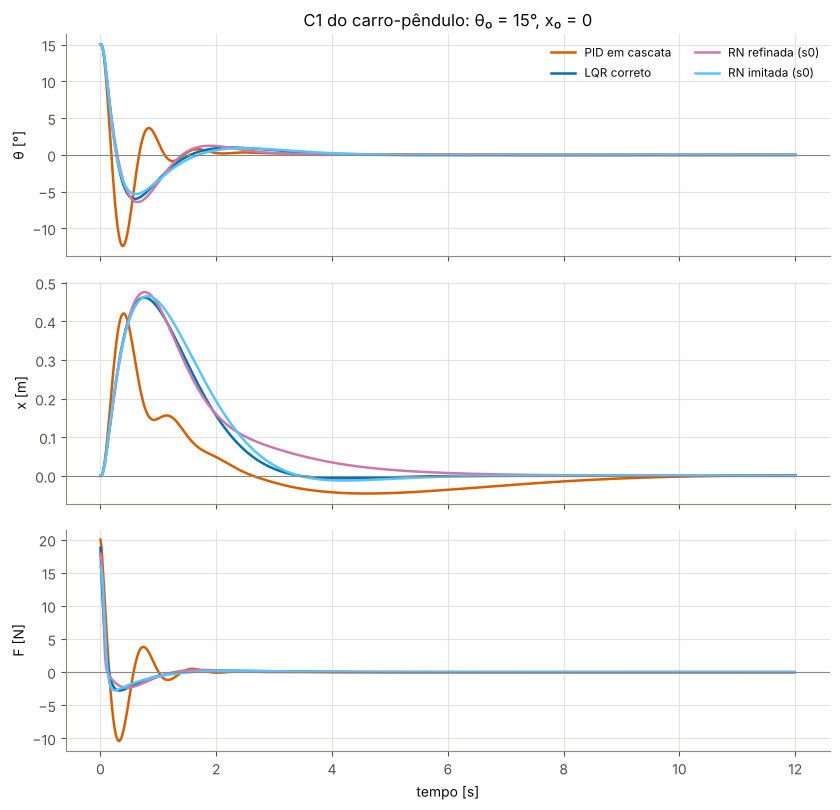

**Figura `C1_respostas_pendulo.png`.** Respostas no C1 do carro-pêndulo (θ₀ = 15°, x₀ = 0, 12 s): θ, x e F do PID em cascata, do LQR correto e da RN da variante RN, imitada e refinada, na semente mediana s0.

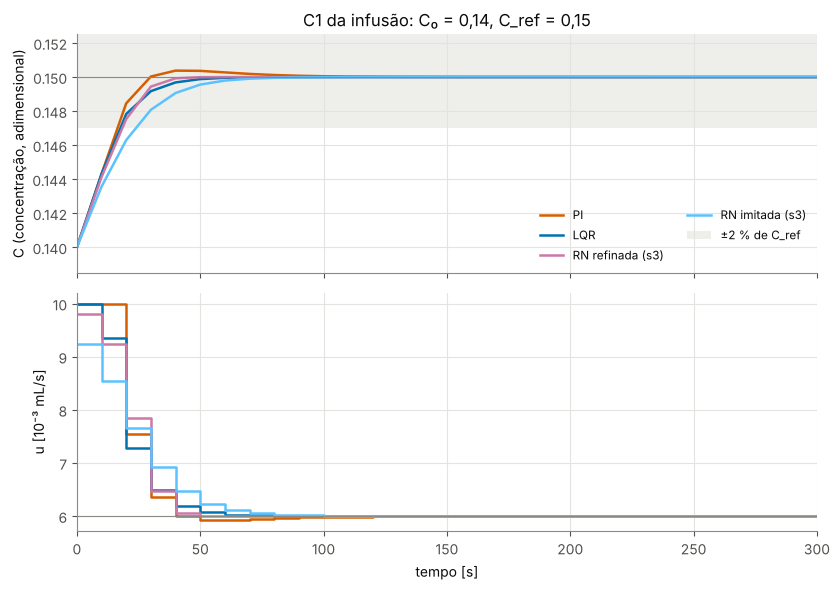

**Figura `C1_respostas_infusao.png`.** Respostas no C1 da infusão (C₀ = 0,14, C_ref = 0,15; primeiros 300 s): concentração C e vazão u do PI, do LQR e da RN da variante RN, imitada e refinada, na semente mediana s3; faixa de ±2 % de C_ref sombreada.

In [38]:
mostrar_tabela(MATRIZ_C1_EXIBIDA, "Matriz 2 × 3 no C1: carro-pêndulo com θ₀ = 15° e infusão com C₀ = 0,14; PID em cascata ou PI, LQR e RN "
               "refinada (variante RN: mediana (mín. a máx.) de 5 sementes). ΔJ sobre o LQR; pico pós-cruzamento: maior |θ| depois do primeiro "
               "cruzamento de zero, em % de θ₀. Tempo por passo: tabela de 4.6.", csv="matriz__C1_2x3_texto.csv", opcoes={"display.max_colwidth": 40})
figura_C1_respostas_pendulo(RES_C1, S_MED_PEND)
figura_C1_respostas_infusao(RES_C1_INF, S_MED_INF)

### 4.2 C2 e região de atração

C2: θ₀ de 5° a 60°, de 5 em 5 (pêndulo, com os controladores do C1 e o LQR aproximado), e C₀ = 0; 0,05; 0,10; 0,18; 0,22 (infusão, com os controladores do C1). A célula de região de atração simula também os controladores do C4 (RN-C4, RN-C4-direta, `LQR-identificado` e `LQR-aprox-refinado`): de 5° a 40°, as simulações do C4 (usadas em 4.4); de 45° a 60°, só para a região de atração.

Verificação de otimalidade do LQR da infusão a C₀ = 0,145, em que o LQR não satura: J de toda RN da infusão (imitadas, calibradas e sem calibrar, e as duas variantes refinadas, nas 5 sementes) ≥ J do LQR·(1 − 1e-6).

Tabelas completas: `pendulo__C2__mapa.csv` e `pendulo__C2__regiao_atracao.csv` (por controlador e semente), `infusao__C2__acomodacao.csv`, `infusao__C2__sobressinal.csv`, `infusao__C2__saturado.csv` e `infusao__otimalidade.csv`.

In [39]:
VARIANTES_C2 = VARIANTES_C1
lista_c2 = controladores(VARIANTES_C2, fixos=("PID em cascata", "LQR correto", "LQR aproximado"))
RES_C2 = rodar_cenario(lista_c2, ANGULOS_C2)
ROTULOS_RN_C2 = [("RN", "imitada")] + [(v, "refinada") for v in VARIANTES_C1]

# J absoluto e ΔJ dos controladores fixos.
tab = {}
for nome in ["LQR correto", "LQR aproximado", "PID em cascata"]:
    tab[f"J {nome}"] = [texto_j(round(RES_C2[(nome, th)]["J"], 4), RES_C2[(nome, th)]) for th in ANGULOS_C2]
for nome in ["LQR aproximado", "PID em cascata"]:
    tab[f"ΔJ {nome} [%]"] = [faixa_pct([delta_pct(RES_C2, nome, th)]) if np.isfinite(RES_C2[("LQR correto", th)]["J"]) else "—" for th in ANGULOS_C2]
TAB_C2_FIXOS = pd.DataFrame(tab, index=pd.Index(ANGULOS_C2, name="θ₀ [°]"))

# ΔJ de cada RN relativo ao LQR correto, 5 sementes.
tab = {}
for variante, etapa in ROTULOS_RN_C2:
    tab[f"{variante} {etapa}"] = [resumo_sementes(deltas_sementes(RES_C2, variante, etapa, th))
                                  if np.isfinite(RES_C2[("LQR correto", th)]["J"]) else
                                  "LQR caiu" + (f" (RN de pé em {sum(not RES_C2[(rotulo_rn(variante, etapa, s), th)]['caiu'] for s in SEMENTES)} de 5)")
                                  for th in ANGULOS_C2]
TAB_C2 = pd.DataFrame(tab, index=pd.Index(ANGULOS_C2, name="θ₀ [°]"))
registrar_tabela("pendulo/C2/fixos", TAB_C2_FIXOS)
registrar_tabela("pendulo/C2/RN", TAB_C2)
registrar_simulacoes("pendulo/C2", RES_C2, condicao_pendulo)

# Mapa de sucesso e região de atração por controlador e semente.
rotulos_c2 = [rot for rot, *_ in lista_c2]
MAPA_C2 = pd.DataFrame({th: [simbolo(RES_C2[(rot, th)]) for rot in rotulos_c2] for th in ANGULOS_C2}, index=rotulos_c2)
MAPA_C2.columns.name = "θ₀ [°]"
linhas = []
for rot, familia, etapa, semente, _ in lista_c2:
    maior, sem_queda, fora = regiao_atracao(RES_C2, rot, ANGULOS_C2)
    linhas.append({"controlador": rot, "família": familia, "etapa": etapa or "—", "semente": semente,
                   "região de atração (estabilizou) [°]": maior, "maior θ₀ sem cair [°]": sem_queda,
                   "estabilizou também em (fora da sequência)": fora or "—"})
RA_C2 = pd.DataFrame(linhas).set_index("controlador")
registrar_tabela("pendulo/C2/mapa", MAPA_C2)
registrar_tabela("pendulo/C2/regiao_atracao", RA_C2)

In [40]:
# C2 da infusão.
RES_C2_INF = rodar_cenario(lista_inf, C2_INF + [C1_INF], planta_inf, estado_inicial_infusao)
tab = {"J PI": [RES_C2_INF[("PI", c)]["J"] for c in CONDS_INF], "J LQR": [RES_C2_INF[("LQR", c)]["J"] for c in CONDS_INF],
       "ΔJ PI [%]": [f"{delta_pct(RES_C2_INF, 'PI', c, 'LQR'):+.3f}" for c in CONDS_INF]}
for nome in ROTULOS_RN_INF:
    variante, etapa = ("RN", nome[3:]) if nome.startswith("RN imitada") else (nome.rsplit(" ", 1)[0], "refinada")
    tab[f"ΔJ {nome} [%]"] = [resumo_sementes([delta_pct(RES_C2_INF, rotulo_rn(variante, etapa, s), c, "LQR") for s in SEMENTES], 3) for c in CONDS_INF]
tab["ΔJ LQR-ganho-1,45K [%]"] = [f"{delta_pct(RES_C2_INF, 'LQR-ganho-1,45K', c, 'LQR'):+.3f}" for c in CONDS_INF]
tab["ΔJ LQR-ganho-Kef [%]"] = [resumo_sementes([delta_pct(RES_C2_INF, f"LQR-ganho-Kef s{s}", c, "LQR") for s in SEMENTES], 3) for c in CONDS_INF]
TAB_C2_INF = pd.DataFrame(tab, index=pd.Index(CONDS_INF, name="C₀"))
TAB_ACOMODACAO_INF, TAB_MP_INF, TAB_SATURADO_INF = tabela_metrica_inf("acomodação C [s]"), tabela_metrica_inf("Mp [%]", 2), tabela_metrica_inf("% saturado", 1)
registrar_tabela("infusao/C2/tabela", TAB_C2_INF)
registrar_tabela("infusao/C2/acomodacao", TAB_ACOMODACAO_INF)
registrar_tabela("infusao/C2/sobressinal", TAB_MP_INF)
registrar_tabela("infusao/C2/saturado", TAB_SATURADO_INF)
registrar_simulacoes("infusao/C2", RES_C2_INF, condicao_infusao)

# Otimalidade do LQR a C₀ = 0,145 (sem saturação).
RES_OTIM = rodar_cenario(lista_inf, [C0_OTIM], planta_inf, estado_inicial_infusao)
sim_lqr_otim = RES_OTIM[("LQR", C0_OTIM)]["sim"]
J_lqr_otim = RES_OTIM[("LQR", C0_OTIM)]["J"]
saturou = bool(np.any(sim_lqr_otim["U"] >= planta_inf.u_max) or np.any(sim_lqr_otim["U"] <= planta_inf.u_min))
linhas = []
for rotulo, familia, etapa, semente, _ in lista_inf:
    if familia in ("PI", "LQR") + FAMILIAS_GANHO:   # o teste é das RN
        continue
    j = RES_OTIM[(rotulo, C0_OTIM)]["J"]
    linhas.append({"RN": rotulo, "J": j, "J/J_LQR − 1": j / J_lqr_otim - 1})
TAB_OTIM = pd.DataFrame(linhas).set_index("RN")
pior = TAB_OTIM["J/J_LQR − 1"].min()
verificar("infusao-otimalidade-lqr — infusão, a partir de C₀ = 0,145 (LQR sem saturação): J de toda RN ≥ J do LQR·(1 − 1e-6)",
          (not saturou) and pior >= -1e-6, f"{len(TAB_OTIM)} RN; menor J/J_LQR − 1 = {pior:.2e}; LQR saturou: {saturou}", tol="J/J_LQR − 1 ≥ −1e-6")
registrar_tabela("infusao/otimalidade", TAB_OTIM)
registrar_simulacoes("infusao/otimalidade", RES_OTIM, condicao_infusao)

infusao-otimalidade-lqr: OK | 20 RN; menor J/J_LQR − 1 = 2.13e-02; LQR saturou: False | tolerância: J/J_LQR − 1 ≥ −1e-6


In [41]:
# Controladores do C4: de 5° a 40° (as simulações do C4, usadas em 4.4) e de 45° a 60° (só para a região de atração).
lista_c4 = [("LQR correto", "LQR correto", None, None, FIXOS["LQR correto"]), ("LQR aproximado", "LQR aproximado", None, None, FIXOS["LQR aproximado"])]
lista_c4 += [(rotulo_rn("RN-C4", etapa, s), "RN-C4", etapa, s, RNS[("RN-C4", s)][etapa]) for etapa in ["imitada", "refinada"] for s in SEMENTES]
lista_c4 += [(rotulo_rn("RN-C4-direta", "refinada", s), "RN-C4-direta", "refinada", s, RNS[("RN-C4-direta", s)]["refinada"]) for s in SEMENTES]
lista_c4_lqr = ([(f"LQR-identificado s{s}", "LQR-identificado", None, s, PoliticaLQR(planta, LQR_C4[s]["K_id"])) for s in SEMENTES] +
                [(f"LQR-aprox-refinado s{s}", "LQR-aprox-refinado", None, s, PoliticaLQR(planta, LQR_C4[s]["K_ref"])) for s in SEMENTES])
RES_C4 = rodar_cenario(lista_c4, ANGULOS_C4)
RES_C4_LQR = rodar_cenario(lista_c4_lqr, ANGULOS_C4)
registrar_simulacoes("pendulo/C4", RES_C4, condicao_pendulo)
registrar_simulacoes("pendulo/C4", RES_C4_LQR, condicao_pendulo)
RES_C4_TOTAL = {**RES_C4, **RES_C4_LQR}

ANG_RA_EXTRA = [th for th in ANGULOS_C2 if th not in ANGULOS_C4]
lista_ra_extra = [linha for linha in lista_c4 if linha[1] in ("RN-C4", "RN-C4-direta")] + lista_c4_lqr
RES_RA_C4 = {**RES_C4_TOTAL, **rodar_cenario(lista_ra_extra, ANG_RA_EXTRA)}
registrar_simulacoes("pendulo/regiao_atracao_C4", {k: v for k, v in RES_RA_C4.items() if k[1] in ANG_RA_EXTRA}, condicao_pendulo)

GRUPOS_RA = ([("LQR correto", RES_C2, ["LQR correto"]), ("LQR aproximado", RES_C2, ["LQR aproximado"]), ("PID em cascata", RES_C2, ["PID em cascata"]),
              ("RN imitada", RES_C2, [rotulo_rn("RN", "imitada", s) for s in SEMENTES])] +
             [(f"{v} refinada", RES_C2, [rotulo_rn(v, "refinada", s) for s in SEMENTES]) for v in VARIANTES_C1] +
             [(f"RN-C4 {e}", RES_RA_C4, [rotulo_rn("RN-C4", e, s) for s in SEMENTES]) for e in ["imitada", "refinada"]] +
             [("RN-C4-direta refinada", RES_RA_C4, [rotulo_rn("RN-C4-direta", "refinada", s) for s in SEMENTES])] +
             [(nome, RES_RA_C4, [f"{nome} s{s}" for s in SEMENTES]) for nome in ["LQR-identificado", "LQR-aprox-refinado"]])

linhas_num, linhas_txt = [], []
for grupo, res, rotulos in GRUPOS_RA:
    ra, sq, xm, caiu45 = [], [], [], 0
    for rot in rotulos:
        maior, sem_queda, _ = regiao_atracao(res, rot, ANGULOS_C2)
        r45 = res[(rot, 45)]
        ra.append(np.nan if maior is None else maior)
        sq.append(np.nan if sem_queda is None else sem_queda)
        xm.append(r45["max |x| [m]"])
        caiu45 += int(r45["caiu"] or r45["divergiu"])
        linhas_num.append({"grupo": grupo, "controlador": rot, "região (estabilizou) [°]": ra[-1], "maior θ₀ sem cair [°]": sq[-1],
                           "max |x| a 45° [m]": xm[-1], "caiu a 45°": bool(r45["caiu"] or r45["divergiu"])})
    linhas_txt.append({"controlador": grupo, "sementes": len(rotulos),
                       "região de atração, critério de estabilização [°]": texto_faixa(ra, "{:.0f}", "nenhum"),
                       "maior θ₀ sem cair [°]": texto_faixa(sq, "{:.0f}", "nenhum"),
                       "max |x| a 45° [m]": texto_faixa(xm, "{:.2f}", "caiu"),
                       "a 45°: caiu": f"{caiu45} de {len(rotulos)}"})
RA_POR_CONTROLADOR = pd.DataFrame(linhas_num).set_index("controlador")
REGIAO_ATRACAO = pd.DataFrame(linhas_txt).set_index("controlador")
registrar_tabela_matriz("regiao_atracao_pendulo", REGIAO_ATRACAO)
registrar_tabela_matriz("regiao_atracao_pendulo_por_controlador", RA_POR_CONTROLADOR)

**Tabela.** C2 do carro-pêndulo, θ₀ de 5° a 45° (onde o LQR correto fica de pé): ΔJ sobre o LQR correto, mediana (mín. a máx.) sobre θ₀ e sementes; simulações abaixo do LQR correto; quedas. Por θ₀: pendulo__C2__fixos.csv e pendulo__C2__RN.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

,simulações,"ΔJ [%], mediana (mín. a máx.)",abaixo da referência,caíram
controlador,,,,
LQR aproximado,9,+6.1 (+5.7 a +6.8),0 de 8,1 de 9
PID em cascata,9,+67.2 (+43.1 a +100.6),0 de 9,0 de 9
RN imitada,45,+4.2 (+1.4 a +51.8),0 de 41,4 de 45
RN refinada,45,+4.9 (+0.9 a +32.3),0 de 39,6 de 45
RN-direta refinada,45,+3.3 (+1.0 a +48.4),0 de 38,7 de 45


**Tabela.** C2 da infusão, C₀ de 0 a 0,22 (com o C1, C₀ = 0,14): ΔJ sobre o LQR, mediana (mín. a máx.) sobre C₀ e sementes; simulações abaixo do LQR. Por C₀: infusao__C2__tabela.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

,simulações,"ΔJ [%], mediana (mín. a máx.)",abaixo da referência,caíram
controlador,,,,
PI,6,+0.065 (+0.006 a +3.855),0 de 6,0 de 6
RN imitada sem calibrar,30,+0.480 (+0.034 a +39.277),0 de 30,0 de 30
RN imitada,30,+0.446 (+0.032 a +23.401),0 de 30,0 de 30
RN refinada,30,+0.054 (+0.004 a +3.834),0 de 30,0 de 30
RN-direta refinada,30,+0.053 (+0.004 a +3.785),0 de 30,0 de 30
"LQR-ganho-1,45K",6,+0.039 (+0.002 a +2.180),0 de 6,0 de 6
LQR-ganho-Kef,30,+0.038 (+0.002 a +2.218),0 de 30,0 de 30


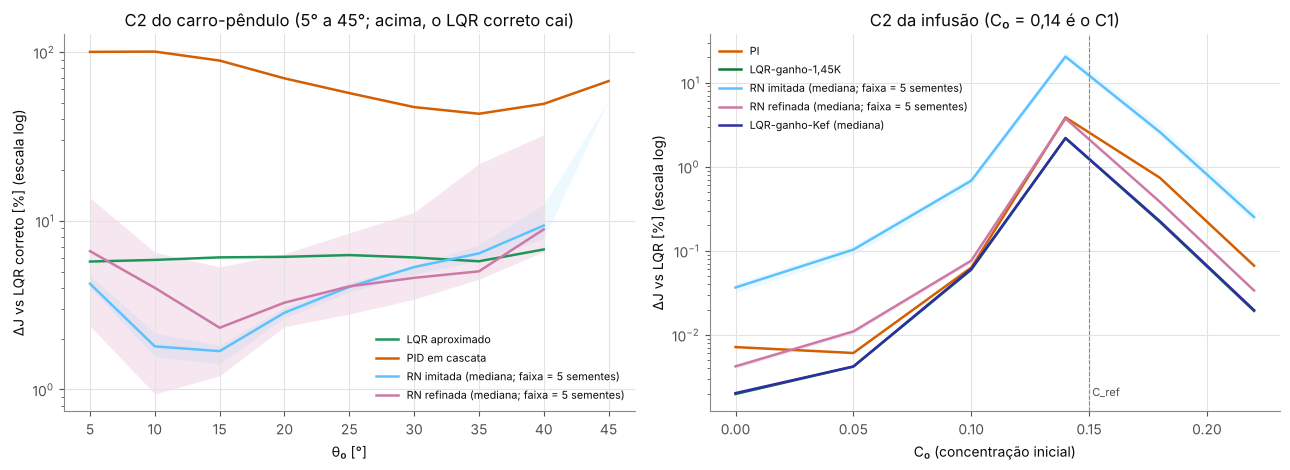

**Figura `C2_deltaJ_amplitude.png`.** ΔJ sobre o LQR em função da condição inicial no C2: carro-pêndulo, θ₀ de 5° a 45° (referência: LQR correto), com o LQR aproximado, o PID em cascata e a RN imitada e refinada; infusão, C₀ de 0 a 0,22 (referência: LQR), com o PI, o LQR-ganho-1,45K, o LQR-ganho-Kef e a RN imitada e refinada. RN: mediana (onde ao menos 3 de 5 sementes ficam de pé) e faixa mínimo–máximo de 5 sementes. Eixo y em escala log, nas duas plantas.

In [42]:
# Na tela: resumo de cada varredura (mediana, mínimo e máximo sobre condições iniciais e sementes); por θ₀ e por C₀, nos CSV.
legenda_csv("pendulo__C2__fixos.csv", "C2 do carro-pêndulo, controladores fixos: J (12 s) do LQR correto, do LQR aproximado e do PID em "
            "cascata, e ΔJ sobre o LQR correto, por θ₀; \"caiu\" = |θ| ≥ 90°.")
legenda_csv("pendulo__C2__RN.csv", "C2 do carro-pêndulo, ΔJ das RN sobre o LQR correto [%], por θ₀ de 5° a 60°: mediana (mín. a máx.) · "
            "sementes abaixo do LQR correto, de 5; quedas à parte; \"LQR caiu\" onde o LQR correto cai. " + LEGENDA_DIRETA)
legenda_csv("infusao__C2__tabela.csv", "C2 da infusão (C₀ = 0,14 é o C1): J do PI e do LQR, e ΔJ sobre o LQR [%] (RN e LQR-ganho-Kef: "
            "mediana (mín. a máx.) · sementes abaixo do LQR, de 5), por C₀. " + LEGENDA_DIRETA)
grupos_c2 = ([("LQR aproximado", ["LQR aproximado"]), ("PID em cascata", ["PID em cascata"])] +
             [(f"{v} {e}", [rotulo_rn(v, e, s) for s in SEMENTES]) for v, e in ROTULOS_RN_C2])
ang_ref = [th for th in ANGULOS_C2 if np.isfinite(RES_C2[("LQR correto", th)]["J"])]
mostrar_tabela(resumo_varredura(RES_C2, grupos_c2, ANGULOS_C2, "LQR correto"),
               f"C2 do carro-pêndulo, θ₀ de 5° a {ang_ref[-1]}° (onde o LQR correto fica de pé): ΔJ sobre o LQR correto, mediana (mín. a máx.) "
               "sobre θ₀ e sementes; simulações abaixo do LQR correto; quedas. Por θ₀: pendulo__C2__fixos.csv e pendulo__C2__RN.csv. " + LEGENDA_DIRETA)


def rotulos_rn_inf(nome):
    """Os 5 rótulos de uma RN da infusão a partir do nome da linha ('RN imitada', 'RN-direta refinada'...)."""
    variante, etapa = ("RN", nome[3:]) if nome.startswith("RN imitada") else (nome.rsplit(" ", 1)[0], "refinada")
    return [rotulo_rn(variante, etapa, s) for s in SEMENTES]


grupos_c2_inf = ([("PI", ["PI"])] + [(nome, rotulos_rn_inf(nome)) for nome in ROTULOS_RN_INF] +
                 [("LQR-ganho-1,45K", ["LQR-ganho-1,45K"]), ("LQR-ganho-Kef", [f"LQR-ganho-Kef s{s}" for s in SEMENTES])])
mostrar_tabela(resumo_varredura(RES_C2_INF, grupos_c2_inf, CONDS_INF, "LQR", fmt="{:+.3f}"),
               "C2 da infusão, C₀ de 0 a 0,22 (com o C1, C₀ = 0,14): ΔJ sobre o LQR, mediana (mín. a máx.) sobre C₀ e sementes; simulações "
               "abaixo do LQR. Por C₀: infusao__C2__tabela.csv. " + LEGENDA_DIRETA)
figura_C2_deltaJ(RES_C2, RES_C2_INF)

**Tabela `matriz__regiao_atracao_pendulo.csv`.** Região de atração do carro-pêndulo (θ₀ de 5° a 60°, x₀ = 0): maior θ₀ da sequência contínua de sucessos a partir de 5° pelo critério de estabilização (|θ| < 1° e |x| < 5 cm no último 1 s de 12 s) e pelo critério "não caiu", e max |x| a 45°; nas linhas com 5 sementes, mediana (mín. a máx.). Os controladores do C4 foram simulados de 45° a 60° só para esta tabela. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto. RN-C4-direta refinada: a imitação do LQR aproximado refinada pela planta exata; ela conhece o modelo que o LQR aproximado errou e, no C4, é um limite superior idealizado, não o aprendizado do erro de modelo a partir de dados (a RN-C4, o LQR-identificado e o LQR-aprox-refinado usam só dados).

,sementes,"região de atração, critério de estabilização [°]",maior θ₀ sem cair [°],max |x| a 45° [m],a 45°: caiu
controlador,,,,,
LQR correto,1,45,45,2.61,0 de 1
LQR aproximado,1,40,40,caiu (1 de 1),1 de 1
PID em cascata,1,35,60,2.82,0 de 1
RN imitada,5,40 (40 a 45),40 (40 a 45),3.07 (3.07 a 3.07) · caiu 4 de 5,4 de 5
RN refinada,5,40 (35 a 40),40 (35 a 40),caiu (5 de 5),5 de 5
RN-direta refinada,5,40 (35 a 40),40 (35 a 40),caiu (5 de 5),5 de 5
RN-C4 imitada,5,35 (35 a 40),35 (35 a 40),caiu (5 de 5),5 de 5
RN-C4 refinada,5,40 (40 a 40),40 (40 a 40),caiu (5 de 5),5 de 5
RN-C4-direta refinada,5,40 (35 a 40),40 (35 a 40),caiu (5 de 5),5 de 5


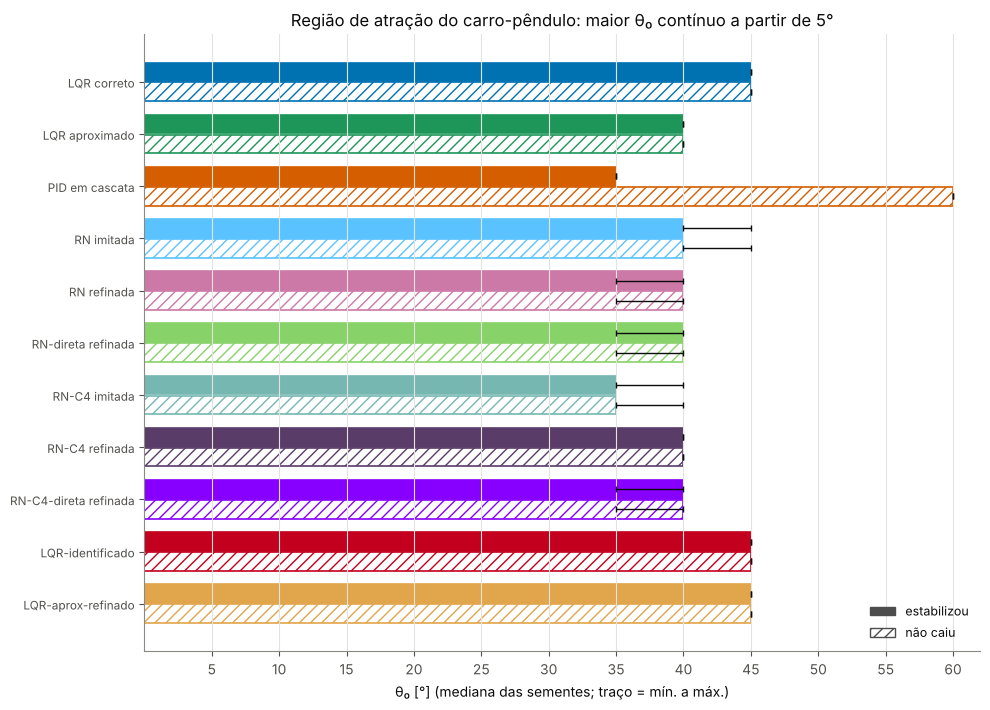

**Figura `C2_regiao_atracao_pendulo.png`.** Região de atração do carro-pêndulo por controlador e variante (θ₀ de 5° a 60°, de 5 em 5; x₀ = 0; 12 s): maior θ₀ da sequência contínua de sucessos a partir de 5°, pelo critério de estabilização (|θ| < 1° e |x| < 5 cm no último 1 s; barra cheia) e pelo critério "não caiu" (barra hachurada); mediana das sementes, traço = mínimo a máximo. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto. RN-C4-direta refinada: a imitação do LQR aproximado refinada pela planta exata; ela conhece o modelo que o LQR aproximado errou e, no C4, é um limite superior idealizado, não o aprendizado do erro de modelo a partir de dados (a RN-C4, o LQR-identificado e o LQR-aprox-refinado usam só dados).

In [43]:
mostrar_tabela(REGIAO_ATRACAO, "Região de atração do carro-pêndulo (θ₀ de 5° a 60°, x₀ = 0): maior θ₀ da sequência contínua de sucessos a partir "
               "de 5° pelo critério de estabilização (|θ| < 1° e |x| < 5 cm no último 1 s de 12 s) e pelo critério \"não caiu\", e max |x| a "
               "45°; nas linhas com 5 sementes, mediana (mín. a máx.). Os controladores do C4 foram simulados de 45° a 60° só para esta tabela. "
               + LEGENDA_DIRETA + " " + LEGENDA_C4_DIRETA,
               csv="matriz__regiao_atracao_pendulo.csv", opcoes={"display.max_colwidth": 40})
figura_regiao_atracao(REGIAO_ATRACAO, RA_POR_CONTROLADOR)

### 4.3 C3

100 plantas com parâmetros a ±20 % (pêndulo: M, m e l; infusão: V₁ e Ω), sorteadas uma vez e as mesmas para todos os controladores, todos projetados na planta nominal. Pêndulo: PID em cascata, LQR correto, RN imitada e refinada (variante `RN`) e RN-direta refinada (5 sementes cada), a θ₀ = 15° e 30°. Infusão: PI, LQR, RN imitada e refinada, LQR-ganho-1,45K, LQR-ganho-Kef e RN-direta refinada, a C₀ = 0,14 e 0. A RN imitada é a mesma da `RN` e da `RN-direta` e entra uma vez. As realizações sorteadas vão para o cache (`c3_realizacoes_*.csv`) e para `pendulo__C3__realizacoes.csv` e `infusao__C3__realizacoes.csv`.

Verificações: todos os controladores viram as mesmas plantas, na mesma ordem; na infusão, o erro em regime do LQR bate com a fórmula de regime, a 1e-6 de C_ref:

$$C^* = \frac{B_d'\,(u_{ss} + K\,C_{ref})}{1 - A_d' + B_d'\,K},$$

com A_d′ e B_d′ da planta perturbada e u_ss, K nominais. A mesma fórmula com o ganho local K_ef no lugar de K dá o erro previsto de cada controlador proporcional, $C^* = (u_{ss} + K_{ef}\,C_{ref})/(\Omega' + K_{ef})$.

Tabelas completas: `pendulo__C3__tabela.csv`, `pendulo__C3__resumo.csv`, `infusao__C3__tabela.csv`, `infusao__C3__resumo.csv`, `infusao__C3__erro_regime.csv`, `infusao__C3__ganho_local.csv` e `matriz__C3_duas_plantas_numerico.csv`.

In [44]:
# Pêndulo.
FATORES_C3_PEND = sortear_c3(["M", "m", "l"], SEMENTE_C3)
gravar_realizacoes(FATORES_C3_PEND, "c3_realizacoes_pendulo.csv")
registrar_tabela("pendulo/C3/realizacoes", FATORES_C3_PEND)
lista_c3 = controladores(["RN", "RN-direta"])   # a RN imitada, comum às duas, entra uma vez
t0 = time.perf_counter()
RES_C3_PEND, VISTAS_C3_PEND = rodar_c3(planta, FATORES_C3_PEND, lista_c3, CONDICOES_C3_PEND, estado_inicial_pendulo)
TEMPO_C3_PEND = time.perf_counter() - t0
iguais = all(np.array_equal(v, FATORES_C3_PEND.to_numpy()) for v in VISTAS_C3_PEND.values())
verificar("c3-pendulo-mesmas-plantas — C3 do pêndulo: as mesmas 100 realizações (M, m, l) para todos os controladores e condições", iguais,
          f"{len(VISTAS_C3_PEND)} listas comparadas com a tabela sorteada", tol="igualdade exata")
TAB_C3_PEND = resumo_c3(planta, RES_C3_PEND, lista_c3, CONDICOES_C3_PEND)
RESUMO_C3_PEND = pd.DataFrame(resumo_c3_sementes(TAB_C3_PEND, "RN", "imitada", CONDICOES_C3_PEND) +
                              resumo_c3_sementes(TAB_C3_PEND, "RN", "refinada", CONDICOES_C3_PEND) +
                              resumo_c3_sementes(TAB_C3_PEND, "RN-direta", "refinada", CONDICOES_C3_PEND)).set_index(["RN", "condição"])
registrar_tabela("pendulo/C3/tabela", TAB_C3_PEND)
registrar_tabela("pendulo/C3/resumo", RESUMO_C3_PEND)
registrar_c3("pendulo/C3", RES_C3_PEND, condicao_pendulo, ["J", "caiu", "divergiu", "estabilizou", "dentro_trilho", "max |x| [m]"])
TEMPOS["pendulo/C3/simulações [s]"] = TEMPO_C3_PEND

c3-pendulo-mesmas-plantas: OK | 34 listas comparadas com a tabela sorteada | tolerância: igualdade exata


In [45]:
# Infusão.
FATORES_C3_INF = sortear_c3(["V1", "Omega"], SEMENTE_C3 + 1)
gravar_realizacoes(FATORES_C3_INF, "c3_realizacoes_infusao.csv")
lista_c3_inf = (controladores(["RN"], fixos=("PI", "LQR"), rns=RNS_INF, fixos_dict=FIXOS_INF, cfg_variantes=VARIANTES_INF) + LINHAS_GANHO_INF
                + [(rotulo_rn("RN-direta", "refinada", s), "RN-direta", "refinada", s, RNS_INF[("RN-direta", s)]["refinada"]) for s in SEMENTES])
RES_C3_INF, VISTAS_C3_INF = rodar_c3(planta_inf, FATORES_C3_INF, lista_c3_inf, CONDICOES_C3_INF, estado_inicial_infusao)
iguais_inf = all(np.array_equal(v, FATORES_C3_INF.to_numpy()) for v in VISTAS_C3_INF.values())

# Erro em regime do LQR contra a fórmula C* = B_d(u_ss + K·C_ref)/(1 − A_d + B_d·K), com A_d e B_d de cada planta perturbada
# e u_ss, K nominais; o "regime" é o C final, depois de 150 passos.
plantas_c3_inf = [planta_inf.com_parametros(**linha) for linha in FATORES_C3_INF.to_dict("records")]
C_formula = np.array([p.Bd * (planta_inf.u_eq + K_nom_inf * planta_inf.C_ref) / (1 - p.Ad + p.Bd * K_nom_inf) for p in plantas_c3_inf])
dif_formula = {}
for cond in CONDICOES_C3_INF:
    C_final = RES_C3_INF[("LQR", cond)]["C final"].to_numpy()
    dif_formula[cond] = float(np.max(np.abs(C_final - C_formula)) / planta_inf.C_ref)
verificar("c3-infusao-mesmas-plantas-regime — C3 da infusão: as mesmas 100 realizações para todos, e erro em regime do LQR = fórmula de regime a 1e-6 de C_ref",
          iguais_inf and max(dif_formula.values()) < 1e-6,
          f"{len(VISTAS_C3_INF)} listas comparadas; maior |C_final − C*| = {max(dif_formula.values()):.1e}·C_ref", tol="igualdade exata; 1e-6 de C_ref")

TAB_C3_INF = resumo_c3(planta_inf, RES_C3_INF, lista_c3_inf, CONDICOES_C3_INF, ref="LQR")
erros = []
for rotulo, familia, etapa, semente, _ in lista_c3_inf:
    for cond in CONDICOES_C3_INF:
        e = RES_C3_INF[(rotulo, cond)]["erro final [% de C_ref]"].to_numpy(dtype=float)
        erros.append({"controlador": rotulo, "condição": cond, "erro final, mediana [% C_ref]": np.median(e),
                      "mín. [% C_ref]": e.min(), "máx. [% C_ref]": e.max(), "máx. |erro| [% C_ref]": np.abs(e).max(),
                      "estabilizou (|e| ≤ 2 %)": int(RES_C3_INF[(rotulo, cond)]["estabilizou"].sum())})
TAB_ERRO_C3_INF = pd.DataFrame(erros).set_index(["controlador", "condição"])
RESUMO_C3_INF = pd.DataFrame(resumo_c3_sementes(TAB_C3_INF, "RN", "imitada", CONDICOES_C3_INF) +
                             resumo_c3_sementes(TAB_C3_INF, "RN", "refinada", CONDICOES_C3_INF) +
                             resumo_c3_sementes(TAB_C3_INF, "LQR-ganho-Kef", "—", CONDICOES_C3_INF) +
                             resumo_c3_sementes(TAB_C3_INF, "RN-direta", "refinada", CONDICOES_C3_INF)).set_index(["RN", "condição"])

# Ganho local em C_ref e erro em regime previsto pela fórmula com esse ganho, C* = (u_ss + K_ef·C_ref)/(Ω' + K_ef).
omega_real = planta_inf.Omega * FATORES_C3_INF["Omega"].to_numpy()
linhas = []
for rotulo, familia, etapa, semente, politica in lista_c3_inf:
    if familia == "PI":
        continue
    k_ef = K_nom_inf if familia == "LQR" else ganho_local(politica)
    previsto = 100 * ((planta_inf.u_eq + k_ef * planta_inf.C_ref) / (omega_real + k_ef) / planta_inf.C_ref - 1)
    simulado = RES_C3_INF[(rotulo, 0.14)]["erro final [% de C_ref]"].to_numpy(dtype=float)
    linhas.append({"controlador": rotulo, "ganho local K_ef = −du/dC em C_ref": k_ef, "K_ef / K do LQR": k_ef / K_nom_inf,
                   "erro previsto com K_ef, mín. a máx. [% C_ref]": f"{previsto.min():+.3f} a {previsto.max():+.3f}",
                   "erro simulado, mín. a máx. [% C_ref]": f"{simulado.min():+.3f} a {simulado.max():+.3f}",
                   "maior |previsto − simulado| [% C_ref]": float(np.max(np.abs(previsto - simulado)))})
TAB_GANHO_INF = pd.DataFrame(linhas).set_index("controlador")
registrar_tabela("infusao/C3/realizacoes", FATORES_C3_INF)
registrar_tabela("infusao/C3/tabela", TAB_C3_INF)
registrar_tabela("infusao/C3/resumo", RESUMO_C3_INF)
registrar_tabela("infusao/C3/erro_regime", TAB_ERRO_C3_INF)
registrar_tabela("infusao/C3/ganho_local", TAB_GANHO_INF)
registrar_matriz("infusao/C3/C_formula", C_formula)
registrar_c3("infusao/C3", RES_C3_INF, condicao_infusao, ["J", "C final", "erro final [% de C_ref]", "estabilizou"])

c3-infusao-mesmas-plantas-regime: OK | 46 listas comparadas; maior |C_final − C*| = 5.6e-16·C_ref | tolerância: igualdade exata; 1e-6 de C_ref


In [46]:
# C3 nas duas plantas.
GRUPOS_C3 = {
    "pendulo": (TAB_C3_PEND, RES_C3_PEND, CONDICOES_C3_PEND, [("PID em cascata", "—"), ("LQR correto", "—"), ("RN", "imitada"), ("RN", "refinada"),
                                                              ("RN-direta", "refinada")]),
    "infusao": (TAB_C3_INF, RES_C3_INF, CONDICOES_C3_INF, [("PI", "—"), ("LQR", "—"), ("RN", "imitada"), ("RN", "refinada"), ("RN-direta", "refinada"),
                                                            ("LQR-ganho-1,45K", "—"), ("LQR-ganho-Kef", "—")]),
}
ESTATS_C3 = ["J mediana", "J IQR (25 %)", "J IQR (75 %)", "ΔJ pareado vs LQR, mediana [%]", "ΔJ pareado, IQR (25 %)", "ΔJ pareado, IQR (75 %)",
             "fração abaixo do LQR [%]", "caiu", "de pé sem estabilizar", "fora do trilho (de pé)"]
linhas_num, linhas_txt = [], []
for chave_planta, (tab, res, conds, grupos) in GRUPOS_C3.items():
    for familia, etapa in grupos:
        nome = familia if etapa == "—" else f"{familia} {etapa}"
        for cond in conds:
            t = tab[(tab["família"] == familia) & (tab["etapa"] == etapa) & (tab["condição"] == cond)]
            rotulo_cond = f"θ₀ = {cond}°" if chave_planta == "pendulo" else f"C₀ = {cond:g}".replace(".", ",")
            linha_txt = {"planta": chave_planta, "controlador": nome, "condição": rotulo_cond, "sementes": len(t)}
            for col in ESTATS_C3:
                if col not in t:
                    continue
                v = t[col].to_numpy(dtype=float)
                med, mn, mx, _ = estatisticas(v)
                linhas_num.append({"planta": chave_planta, "controlador": nome, "condição": rotulo_cond, "estatística": col, "mediana entre sementes": med,
                                   "mín.": mn, "máx.": mx, "sementes": len(v)})
                linha_txt[col] = texto_faixa(v, "{:.0f}" if col in ("caiu", "de pé sem estabilizar", "fora do trilho (de pé)") else "{:.4g}")
            if chave_planta == "infusao":
                e = np.concatenate([res[(rot, cond)]["erro final [% de C_ref]"].to_numpy(dtype=float) for rot in t["controlador"]])
                linhas_num.append({"planta": chave_planta, "controlador": nome, "condição": rotulo_cond, "estatística": "erro em regime [% de C_ref]",
                                   "mediana entre sementes": float(np.median(e)), "mín.": float(e.min()), "máx.": float(e.max()), "sementes": len(t)})
                linha_txt["erro em regime [% de C_ref], mediana (mín a máx)"] = f"{np.median(e):+.3f} ({e.min():+.3f} a {e.max():+.3f})"
            linhas_txt.append(linha_txt)
C3_DUAS_PLANTAS = pd.DataFrame(linhas_num).set_index(["planta", "controlador", "condição", "estatística"])
C3_DUAS_PLANTAS_TEXTO = pd.DataFrame(linhas_txt).set_index(["planta", "controlador", "condição"])
registrar_tabela_matriz("C3_duas_plantas", C3_DUAS_PLANTAS_TEXTO)
registrar_tabela_matriz("C3_duas_plantas_numerico", C3_DUAS_PLANTAS)

legenda_csv("matriz__C3_duas_plantas.csv", "C3 do carro-pêndulo e da infusão: 100 plantas a ±20 % (pêndulo: M, m e l; infusão: V₁ e Ω), "
            "as mesmas para todos os controladores, projetados na planta nominal. Mediana e IQR de J; ΔJ pareado contra o LQR na mesma "
            "planta (mediana e IQR); fração das plantas abaixo do LQR; quedas, de pé sem estabilizar e fora do trilho (pêndulo); erro em "
            "regime (infusão). Nas linhas com 5 sementes, mediana (mín. a máx.) entre sementes de cada estatística. " + LEGENDA_DIRETA)
mostrar_tabela(C3_DUAS_PLANTAS_TEXTO.loc["pendulo"][["sementes", "J mediana", "ΔJ pareado vs LQR, mediana [%]", "fração abaixo do LQR [%]", "caiu",
                                                    "de pé sem estabilizar"]],
               "C3 do carro-pêndulo: 100 plantas com M, m e l a ±20 %, as mesmas para todos os controladores, projetados na planta nominal. "
               "Mediana de J; ΔJ pareado contra o LQR correto na mesma planta (mediana); fração das plantas abaixo do LQR; quedas e de pé sem "
               "estabilizar. Nas linhas com 5 sementes, mediana (mín. a máx.) entre sementes de cada estatística. Com os IQR e fora do trilho: "
               "matriz__C3_duas_plantas.csv. " + LEGENDA_DIRETA, opcoes={"display.max_colwidth": 30})
mostrar_tabela(C3_DUAS_PLANTAS_TEXTO.loc["infusao"][["sementes", "J mediana", "ΔJ pareado vs LQR, mediana [%]", "fração abaixo do LQR [%]",
                                                    "erro em regime [% de C_ref], mediana (mín a máx)"]],
               "C3 da infusão: 100 plantas com V₁ e Ω a ±20 %, as mesmas para todos os controladores, projetados na planta nominal; J medido "
               "em torno do equilíbrio da planta simulada, u_ss′ = Ω′·C_ref. Mediana de J; ΔJ pareado contra o LQR (mediana); "
               "fração das plantas abaixo do LQR; erro em regime (C final − C_ref depois de 1500 s, em % de C_ref; nas linhas com 5 sementes, "
               "as 500 simulações juntas). Nas linhas com 5 sementes, mediana (mín. a máx.) entre sementes de cada estatística. Com os IQR: "
               "matriz__C3_duas_plantas.csv. " + LEGENDA_DIRETA,
               opcoes={"display.max_colwidth": 30})

**Tabela.** C3 do carro-pêndulo: 100 plantas com M, m e l a ±20 %, as mesmas para todos os controladores, projetados na planta nominal. Mediana de J; ΔJ pareado contra o LQR correto na mesma planta (mediana); fração das plantas abaixo do LQR; quedas e de pé sem estabilizar. Nas linhas com 5 sementes, mediana (mín. a máx.) entre sementes de cada estatística. Com os IQR e fora do trilho: matriz__C3_duas_plantas.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

sementes                 J mediana ΔJ pareado vs LQR, mediana [%] fração abaixo do LQR [%]       caiu de pé sem estabilizar
controlador        condição                                                                                                                             
PID em cascata     θ₀ = 15°         1                    0.9036                          86.91                        0          0                     0
                   θ₀ = 30°         1                     3.648                          44.76                        0          0                     0
LQR correto        θ₀ = 15°         1                    0.4783                              0                        0          0                     0
                   θ₀ = 30°         1                     2.521                              0                        0          0                     0
RN imitada         θ₀ = 15°         5  0.4867 (0.4849 a 0.4877)          1.602 (1.417 a 1.715)                1 (0 a 9)  0 (0 a 0)             0 (0 a 0)
                   θ₀ = 30°         5      2.65 (2.639 a 2.654)          5.176 (4.832 a 5.351)                0 (0 a 0)  0 (0 a 0)             0 (0 a 0)
RN refinada        θ₀ = 15°         5  0.4892 (0.4838 a 0.5045)          2.317 (1.186 a 5.375)               0 (0 a 18)  0 (0 a 0)             0 (0 a 0)
                   θ₀ = 30°         5       2.631 (2.6 a 2.763)          4.821 (3.578 a 11.59)                0 (0 a 0)  0 (0 a 2)             0 (0 a 0)
RN-direta refinada θ₀ = 15°         5   0.4854 (0.4853 a 0.486)          1.534 (1.486 a 1.643)                0 (0 a 0)  0 (0 a 0)             0 (0 a 0)
                   θ₀ = 30°         5     2.654 (2.652 a 2.669)          5.882 (5.768 a 6.386)                0 (0 a 0)  0 (0 a 0)             0 (0 a 0)

**Tabela.** C3 da infusão: 100 plantas com V₁ e Ω a ±20 %, as mesmas para todos os controladores, projetados na planta nominal; J medido em torno do equilíbrio da planta simulada, u_ss′ = Ω′·C_ref. Mediana de J; ΔJ pareado contra o LQR (mediana); fração das plantas abaixo do LQR; erro em regime (C final − C_ref depois de 1500 s, em % de C_ref; nas linhas com 5 sementes, as 500 simulações juntas). Nas linhas com 5 sementes, mediana (mín. a máx.) entre sementes de cada estatística. Com os IQR: matriz__C3_duas_plantas.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

sementes                      J mediana ΔJ pareado vs LQR, mediana [%] fração abaixo do LQR [%]  \
controlador        condição                                                                                                     
PI                 C₀ = 0,14         1                       0.004878                         -64.86                       91   
                   C₀ = 0            1                           8.23                       -0.08918                       90   
LQR                C₀ = 0,14         1                        0.01337                              0                        0   
                   C₀ = 0            1                          8.241                              0                        0   
RN imitada         C₀ = 0,14         5    0.01672 (0.01645 a 0.01802)          22.35 (20.27 a 33.25)                0 (0 a 0)   
                   C₀ = 0            5           8.248 (8.247 a 8.25)    0.06235 (0.05532 a 0.07949)                0 (0 a 0)   
RN refinada        C₀ = 0,14         5  0.00913 (0.009089 a 0.009244)        -30.73 (-31.04 a -29.7)             92 (92 a 92)   
                   C₀ = 0            5          8.235 (8.235 a 8.236)  -0.04124 (-0.04154 a -0.03...             87 (86 a 88)   
RN-direta refinada C₀ = 0,14         5   0.009077 (0.009031 a 0.0092)        -31.15 (-31.51 a -30.1)             92 (92 a 92)   
                   C₀ = 0            5          8.235 (8.235 a 8.235)  -0.04186 (-0.04221 a -0.04...             88 (87 a 88)   
LQR-ganho-1,45K    C₀ = 0,14         1                       0.008969                            -33                       91   
                   C₀ = 0            1                          8.235                       -0.04588                       90   
LQR-ganho-Kef      C₀ = 0,14         5  0.008944 (0.008911 a 0.009...       -33.24 (-33.57 a -32.41)             91 (91 a 91)   
                   C₀ = 0            5          8.235 (8.235 a 8.235)  -0.0462 (-0.04663 a -0.04511)             90 (90 a 90)   

                             erro em regime [% de C_ref], mediana (mín a máx)  
controlador        condição                                                    
PI                 C₀ = 0,14       +0.000 (+0.000 a +0.000)                    
                   C₀ = 0          +0.000 (+0.000 a +0.000)                    
LQR                C₀ = 0,14       -0.047 (-1.225 a +1.242)                    
                   C₀ = 0          -0.047 (-1.225 a +1.242)                    
RN imitada         C₀ = 0,14       -0.055 (-1.562 a +1.462)                    
                   C₀ = 0          -0.055 (-1.562 a +1.462)                    
RN refinada        C₀ = 0,14       -0.033 (-0.930 a +0.855)                    
                   C₀ = 0          -0.033 (-0.930 a +0.855)                    
RN-direta refinada C₀ = 0,14       -0.033 (-0.926 a +0.850)                    
                   C₀ = 0          -0.033 (-0.926 a +0.850)                    
LQR-ganho-1,45K    C₀ = 0,14       -0.033 (-0.865 a +0.871)                    
                   C₀ = 0          -0.033 (-0.865 a +0.871)                    
LQR-ganho-Kef      C₀ = 0,14       -0.033 (-0.872 a +0.879)                    
                   C₀ = 0          -0.033 (-0.872 a +0.879)

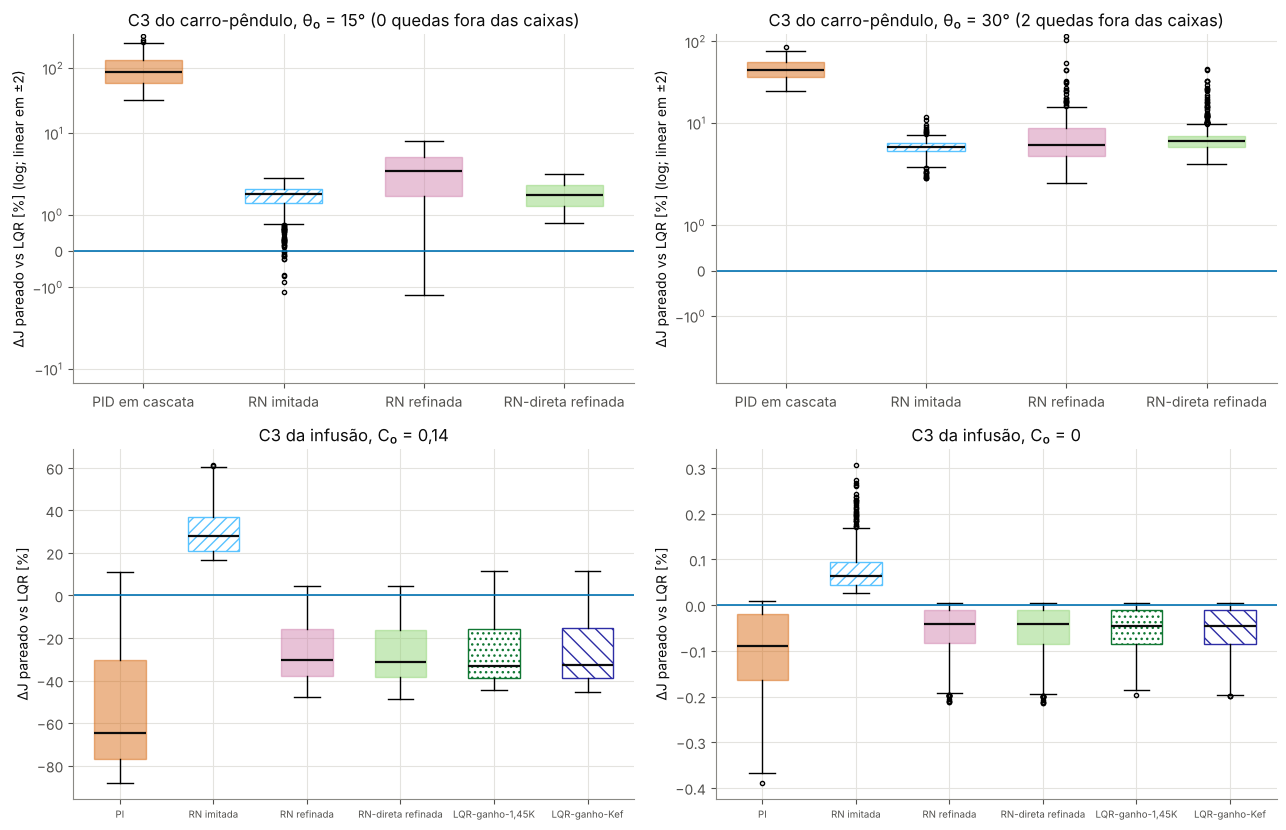

**Figura `C3_boxplots_pareados.png`.** ΔJ pareado contra o LQR (o controlador e o LQR na mesma planta) no C3, nas 100 plantas com parâmetros a ±20 %: carro-pêndulo a θ₀ = 15° e 30° (PID em cascata, RN imitada, RN refinada e RN-direta refinada; referência: LQR correto; escala log, linear em ±2 %) e infusão a C₀ = 0,14 e 0 (PI, RN imitada, RN refinada, RN-direta refinada, LQR-ganho-1,45K e LQR-ganho-Kef; referência: LQR). Nas linhas com 5 sementes, os 500 valores juntos; as realizações em que o pêndulo caiu ficam fora das caixas. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

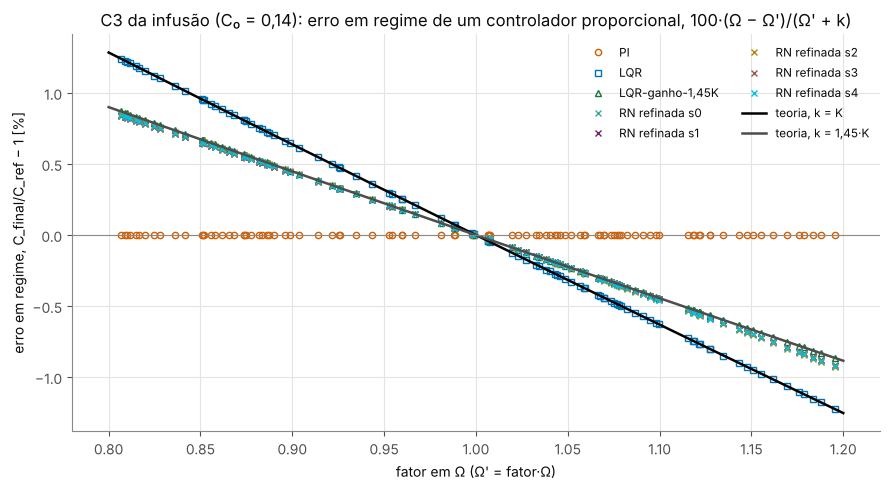

**Figura `C3_infusao_erro_regime.png`.** Erro em regime, C_final/C_ref − 1 (depois de 1500 s), em função do fator de Ω nas 100 plantas do C3 da infusão (C₀ = 0,14): PI, LQR, LQR-ganho-1,45K e RN refinada (variante RN, 5 sementes), e a curva 100·(Ω − Ω′)/(Ω′ + k) para k = K e k = 1,45·K.

In [47]:
figura_C3_boxplots(RES_C3_PEND, RES_C3_INF)
figura_C3_erro_regime(RES_C3_INF, FATORES_C3_INF)

### 4.4 C4

O LQR aproximado (`cartpole_lqr_gain`, massa pontual) é o alvo da imitação da `RN-C4`; o emulador é o corrigido, treinado com dados da planta real. Linhas, de 5° a 40°: LQR correto, LQR aproximado, `LQR-identificado`, `LQR-aprox-refinado` (3.8), RN-C4 imitada e refinada e `RN-C4-direta` refinada (a mesma imitação, refinada pela planta exata). ΔJ sobre o LQR correto e sobre o LQR aproximado, e a fração recuperada $(J_{aprox} - J)/(J_{aprox} - J_{correto})$. Tabelas completas: `pendulo__C4__tabela.csv`, `pendulo__C4__resumo.csv`, `pendulo__C4__linhas_de_controle_por_semente.csv`, `pendulo__C4__linhas_de_controle_resumo.csv` e `pendulo__C4__linhas_de_controle_fracao_recuperada.csv`.

**Tabela.** C4 do carro-pêndulo, θ₀ de 5° a 40°: ΔJ sobre o LQR correto e sobre o LQR aproximado e fração recuperada da distância entre os dois LQR, mediana (mín. a máx.) sobre θ₀ e sementes; simulações abaixo do LQR aproximado; quedas. Por θ₀: matriz__C4_linhas_de_controle.csv. RN-C4-direta refinada: a imitação do LQR aproximado refinada pela planta exata; ela conhece o modelo que o LQR aproximado errou e, no C4, é um limite superior idealizado, não o aprendizado do erro de modelo a partir de dados (a RN-C4, o LQR-identificado e o LQR-aprox-refinado usam só dados).

,simulações,ΔJ vs LQR correto [%],ΔJ vs LQR aproximado [%],abaixo do LQR aproximado,fração recuperada [%],caíram
linha,,,,,,
LQR aproximado,8,+6.06 (+5.73 a +6.76),+0.00 (+0.00 a +0.00),0 de 8,+0 (+0 a +0),0 de 8
LQR-identificado,40,-0.01 (-0.07 a +0.04),-5.74 (-6.32 a -5.40),40 de 40,+100 (+99 a +101),0 de 40
LQR-aprox-refinado,40,+0.78 (-0.26 a +1.73),-5.06 (-6.53 a -3.96),40 de 40,+87 (+73 a +104),0 de 40
RN-C4 imitada,40,+7.64 (+4.85 a +61.88),+1.68 (-1.15 a +51.63),7 de 37,-29 (-815 a +20),3 de 40
RN-C4 refinada,40,+4.61 (+0.97 a +49.45),-1.21 (-4.62 a +39.99),26 de 40,+22 (-632 a +84),0 de 40
RN-C4-direta refinada,40,+3.47 (+1.11 a +36.90),-2.49 (-4.49 a +28.24),30 de 39,+43 (-446 a +81),1 de 40


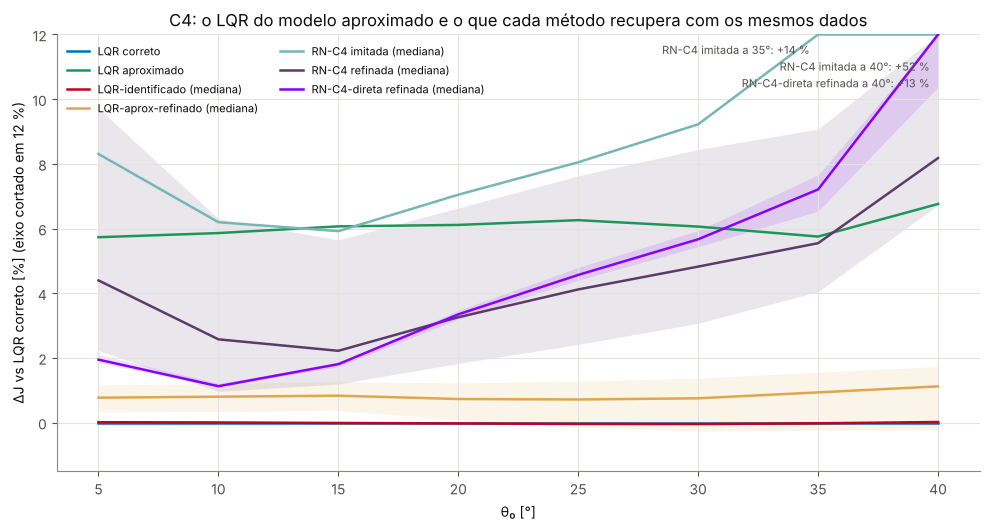

**Figura `C4_linhas_de_controle.png`.** ΔJ sobre o LQR correto em função de θ₀ no C4 do carro-pêndulo (θ₀ de 5° a 40°): LQR correto, LQR aproximado, LQR-identificado, LQR-aprox-refinado, RN-C4 imitada, RN-C4 refinada e RN-C4-direta refinada; nas linhas com 5 sementes, mediana e faixa mínimo–máximo sombreada (na RN-C4 imitada, só a mediana); eixo cortado em 12 %, com as medianas acima anotadas. RN-C4-direta refinada: a imitação do LQR aproximado refinada pela planta exata; ela conhece o modelo que o LQR aproximado errou e, no C4, é um limite superior idealizado, não o aprendizado do erro de modelo a partir de dados (a RN-C4, o LQR-identificado e o LQR-aprox-refinado usam só dados).

In [48]:
linhas = []
for th in ANGULOS_C4:
    j_c, j_a = RES_C4[("LQR correto", th)]["J"], RES_C4[("LQR aproximado", th)]["J"]
    linha = {"θ₀ [°]": th, "J LQR correto": j_c, "J LQR aprox.": j_a, "LQR aprox. vs correto [%]": 100 * (j_a / j_c - 1)}
    for etapa in ["imitada", "refinada"]:
        for s in SEMENTES:
            j = RES_C4[(rotulo_rn("RN-C4", etapa, s), th)]["J"]
            linha[f"{etapa} s{s} vs aprox. [%]"] = 100 * (j / j_a - 1)
    for s in SEMENTES:
        j = RES_C4[(rotulo_rn("RN-C4", "refinada", s), th)]["J"]
        linha[f"refinada s{s} vs correto [%]"] = 100 * (j / j_c - 1)
        linha[f"fração recuperada s{s} [%]"] = 100 * (j_a - j) / (j_a - j_c)
    linha[f"k de {len(SEMENTES)}: refinada < LQR aprox."] = sum(RES_C4[(rotulo_rn("RN-C4", "refinada", s), th)]["J"] < j_a for s in SEMENTES)
    for s in SEMENTES:
        j = RES_C4[(rotulo_rn("RN-C4-direta", "refinada", s), th)]["J"]
        linha[f"direta s{s} vs aprox. [%]"] = 100 * (j / j_a - 1)
        linha[f"direta s{s} vs correto [%]"] = 100 * (j / j_c - 1)
        linha[f"fração recuperada direta s{s} [%]"] = 100 * (j_a - j) / (j_a - j_c)
    linha[f"k de {len(SEMENTES)}: direta < LQR aprox."] = sum(RES_C4[(rotulo_rn("RN-C4-direta", "refinada", s), th)]["J"] < j_a for s in SEMENTES)
    linhas.append(linha)
TAB_C4 = pd.DataFrame(linhas).set_index("θ₀ [°]")
resumo_c4 = pd.DataFrame({
    "RN-C4 imitada vs LQR aprox. [%]": [resumo_sementes([TAB_C4.loc[th, f"imitada s{s} vs aprox. [%]"] for s in SEMENTES]) for th in ANGULOS_C4],
    "RN-C4 refinada vs LQR aprox. [%]": [resumo_sementes([TAB_C4.loc[th, f"refinada s{s} vs aprox. [%]"] for s in SEMENTES]) for th in ANGULOS_C4],
    "RN-C4 refinada vs LQR correto [%]": [resumo_sementes([TAB_C4.loc[th, f"refinada s{s} vs correto [%]"] for s in SEMENTES]) for th in ANGULOS_C4],
    "fração recuperada [%] (mediana, mín a máx)": [resumo_sementes([TAB_C4.loc[th, f"fração recuperada s{s} [%]"] for s in SEMENTES], 0, contar=False) for th in ANGULOS_C4],
    "RN-C4-direta refinada vs LQR aprox. [%]": [resumo_sementes([TAB_C4.loc[th, f"direta s{s} vs aprox. [%]"] for s in SEMENTES]) for th in ANGULOS_C4],
    "RN-C4-direta refinada vs LQR correto [%]": [resumo_sementes([TAB_C4.loc[th, f"direta s{s} vs correto [%]"] for s in SEMENTES]) for th in ANGULOS_C4],
    "fração recuperada RN-C4-direta [%] (mediana, mín a máx)": [resumo_sementes([TAB_C4.loc[th, f"fração recuperada direta s{s} [%]"] for s in SEMENTES], 0, contar=False)
                                                                for th in ANGULOS_C4],
}, index=pd.Index(ANGULOS_C4, name="θ₀ [°]"))
registrar_tabela("pendulo/C4/tabela", TAB_C4)
registrar_tabela("pendulo/C4/resumo", resumo_c4)

# Tabela longa, uma linha por (θ₀, linha do C4, semente).
LINHAS_C4 = ["LQR correto", "LQR aproximado", "LQR-identificado", "LQR-aprox-refinado", "RN-C4 imitada", "RN-C4 refinada", "RN-C4-direta refinada"]
linhas = []
for th in ANGULOS_C4:
    j_c, j_a = RES_C4_TOTAL[("LQR correto", th)]["J"], RES_C4_TOTAL[("LQR aproximado", th)]["J"]
    for nome in LINHAS_C4:
        for rot in rotulos_da_linha(nome):
            r = RES_C4_TOTAL[(rot, th)]
            linhas.append({"θ₀ [°]": th, "linha": nome, "semente": r["semente"], "J": r["J"], "caiu": r["caiu"],
                           "ΔJ vs LQR correto [%]": 100 * (r["J"] / j_c - 1), "ΔJ vs LQR aproximado [%]": 100 * (r["J"] / j_a - 1),
                           "fração recuperada [%]": 100 * (j_a - r["J"]) / (j_a - j_c)})
TAB_C4_LINHAS = pd.DataFrame(linhas)
registrar_tabela("pendulo/C4/linhas_de_controle_por_semente", TAB_C4_LINHAS)

resumo = {}
for nome in LINHAS_C4:
    fixo = nome in FIXOS
    for ref in ["LQR correto", "LQR aproximado"]:
        resumo[(nome, f"ΔJ vs {ref} [%]")] = [celula_c4(linhas_c4(TAB_C4_LINHAS, th, nome)[f"ΔJ vs {ref} [%]"].to_numpy(), fixo) for th in ANGULOS_C4]
RESUMO_C4_LINHAS = pd.DataFrame(resumo, index=pd.Index(ANGULOS_C4, name="θ₀ [°]")).T
RESUMO_C4_LINHAS.index.names = ["linha", "referência"]
registrar_tabela("pendulo/C4/linhas_de_controle_resumo", RESUMO_C4_LINHAS)
FRACAO_C4 = pd.DataFrame({nome: [resumo_sementes(linhas_c4(TAB_C4_LINHAS, th, nome)["fração recuperada [%]"].to_numpy(), 0, contar=False)
                                 for th in ANGULOS_C4] for nome in LINHAS_C4[2:]}, index=pd.Index(ANGULOS_C4, name="θ₀ [°]"))
registrar_tabela("pendulo/C4/linhas_de_controle_fracao_recuperada", FRACAO_C4)

# As sete linhas, com as duas referências e a fração recuperada.
partes = []
for ref in ["LQR correto", "LQR aproximado"]:
    p = RESUMO_C4_LINHAS.loc[[(nome, f"ΔJ vs {ref} [%]") for nome in LINHAS_C4]].copy()
    p.index = pd.MultiIndex.from_tuples([(f"ΔJ vs {ref} [%]", nome) for nome in LINHAS_C4], names=["medida", "linha"])
    partes.append(p)
f = FRACAO_C4.T.copy()
f.index = pd.MultiIndex.from_tuples([("fração recuperada [%]", nome) for nome in f.index], names=["medida", "linha"])
C4_FINAL = pd.concat(partes + [f])
registrar_tabela_matriz("C4_linhas_de_controle", C4_FINAL)

legenda_csv("matriz__C4_linhas_de_controle.csv", "C4 do carro-pêndulo, θ₀ de 5° a 40°: ΔJ sobre o LQR correto e sobre o LQR aproximado [%] "
            "de LQR correto, LQR aproximado, LQR-identificado, LQR-aprox-refinado, RN-C4 imitada, RN-C4 refinada e RN-C4-direta refinada, e a "
            "fração recuperada da distância entre os dois LQR; nas linhas com 5 sementes, mediana (mín. a máx.) · sementes abaixo da "
            "referência. " + LEGENDA_C4_DIRETA)
linhas_ = []
for nome in LINHAS_C4[1:]:
    t = TAB_C4_LINHAS[TAB_C4_LINHAS["linha"] == nome]
    ok = np.isfinite(t["J"].to_numpy(dtype=float))
    linhas_.append({"linha": nome, "simulações": len(t),
                    "ΔJ vs LQR correto [%]": texto_faixa(t["ΔJ vs LQR correto [%]"].to_numpy(dtype=float)[ok], "{:+.2f}"),
                    "ΔJ vs LQR aproximado [%]": texto_faixa(t["ΔJ vs LQR aproximado [%]"].to_numpy(dtype=float)[ok], "{:+.2f}"),
                    "abaixo do LQR aproximado": f"{int(np.sum(t['ΔJ vs LQR aproximado [%]'].to_numpy(dtype=float)[ok] < 0))} de {int(ok.sum())}",
                    "fração recuperada [%]": texto_faixa(t["fração recuperada [%]"].to_numpy(dtype=float)[ok], "{:+.0f}"),
                    "caíram": f"{int((~ok).sum())} de {len(t)}"})
mostrar_tabela(pd.DataFrame(linhas_).set_index("linha"), "C4 do carro-pêndulo, θ₀ de 5° a 40°: ΔJ sobre o LQR correto e sobre o LQR aproximado "
               "e fração recuperada da distância entre os dois LQR, mediana (mín. a máx.) sobre θ₀ e sementes; simulações abaixo do LQR "
               "aproximado; quedas. Por θ₀: matriz__C4_linhas_de_controle.csv. " + LEGENDA_C4_DIRETA, opcoes={"display.max_colwidth": 30})
figura_C4(TAB_C4_LINHAS)

### 4.5 Infusão: o ganho da RN

- **LQR-ganho-Kef × RN refinada da mesma semente:** J(LQR-ganho-Kef)/J(RN refinada) − 1, em %, em cada C₀ do C1 e do C2 e, no C3, a mediana e o maior valor dessa diferença nas 100 plantas (pareada).
- **C₀ = 0,14 (C1) e C₀ = 0,145:** ΔJ sobre o LQR do LQR-ganho-1,45K, do LQR-ganho-Kef e da RN refinada (variante `RN`).
- **Diagnóstico da sigmoide** (`refinar_lei_linear`, 4.0): a lei linear $u = u_{ss} - k\,e$, refinada pela planta exata com a perda do refinamento da infusão, a partir de k = 0,8·K, com (a) recorte duro e (b) a sigmoide da RN. Verificação: na versão (a), |k/K − 1| < 1e-3 ao fim das 3000 épocas.

diagnostico-sigmoide-recorte: OK | (a) k/K = 1.00000; (b) k/K = 1.4840 | tolerância: |k/K − 1| < 1e-3


**Tabela.** LQR-ganho-Kef × RN refinada da mesma semente, na infusão: K_ef/K e J(LQR-ganho-Kef)/J(RN refinada) − 1 [%] em cada C₀ do C1 e do C2 e, no C3 (100 plantas), a mediana pareada e a maior diferença absoluta; mediana (mín. a máx.) nas 5 sementes. Por semente: infusao__ganho_da_RN__Kef_vs_RN_refinada.csv.

,mediana (mín. a máx.) nas 5 sementes
K_ef / K,+1.456 (+1.436 a +1.464)
C₀ = 0.0: J(Kef)/J(RN) − 1 [%],-0.002 (-0.002 a -0.002)
C₀ = 0.05: J(Kef)/J(RN) − 1 [%],-0.007 (-0.007 a -0.006)
C₀ = 0.1: J(Kef)/J(RN) − 1 [%],-0.015 (-0.022 a -0.011)
C₀ = 0.14: J(Kef)/J(RN) − 1 [%],-1.472 (-1.628 a -1.403)
C₀ = 0.18: J(Kef)/J(RN) − 1 [%],-0.161 (-0.170 a -0.152)
C₀ = 0.22: J(Kef)/J(RN) − 1 [%],-0.014 (-0.015 a -0.014)
"C3, C₀ = 0.14: mediana pareada [%]",-0.700 (-0.824 a -0.644)
"C3, C₀ = 0.14: máx. |dif.| [%]",+11.672 (+11.568 a +11.730)
"C3, C₀ = 0.0: mediana pareada [%]",-0.002 (-0.002 a -0.002)


**Tabela `infusao__ganho_da_RN__deltaJ_C0_014_e_0145.csv`.** ΔJ sobre o LQR na infusão a C₀ = 0,14 (C1) e a C₀ = 0,145 [%]: LQR-ganho-1,45K, LQR-ganho-Kef e RN refinada (variante RN); nas linhas com 5 sementes, mediana (mín. a máx.).

,"LQR-ganho-1,45K",LQR-ganho-Kef,RN refinada
condição,,,
"C₀ = 0,14 (C1)",+2.18,+2.20 (+2.14 a +2.22),+3.74 (+3.66 a +3.83)
"C₀ = 0,145",+20.00,+20.03 (+19.95 a +20.06),+2.33 (+2.13 a +2.40)


**Tabela `infusao__ganho_da_RN__diagnostico_sigmoide.csv`.** Diagnóstico da sigmoide: k/K inicial, na época 201 e ao fim de 3000 épocas, no refinamento da lei linear u = u_ss − k·e pela planta exata da infusão, com (a) recorte duro e (b) a sigmoide da RN.

,k/K inicial,k/K na época 201,k/K final (3000 épocas)
"(a) lei linear, recorte duro",0.8,1.000,1.000
(b) lei linear pela sigmoide da RN,0.8,1.396,1.484


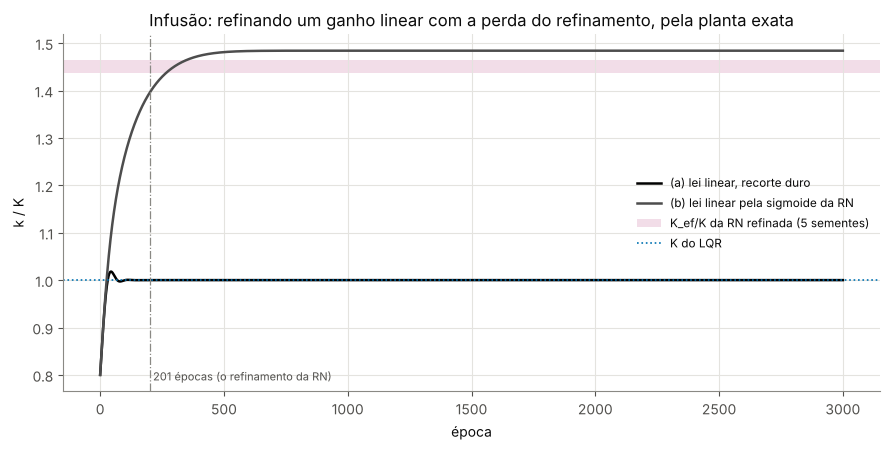

**Figura `infusao_diagnostico_sigmoide.png`.** k/K ao longo das épocas no refinamento de uma lei linear u = u_ss − k·e pela planta exata da infusão, com a perda do refinamento da RN, a partir de k = 0,8·K (3000 épocas, Adam 5e-3, float64): (a) com recorte duro em [0, u_max]; (b) pela sigmoide da saída da RN; faixa do K_ef/K da RN refinada (5 sementes), K do LQR e a época 201 marcados.

In [49]:
linhas = []
for s in SEMENTES:
    linha = {"semente": s, "K_ef / K": K_EF_INF[s] / K_nom_inf}
    for c in CONDS_INF:
        j_kef = RES_C2_INF[(f"LQR-ganho-Kef s{s}", c)]["J"]
        j_rn = RES_C2_INF[(rotulo_rn("RN", "refinada", s), c)]["J"]
        linha[f"C₀ = {c}: J(Kef)/J(RN) − 1 [%]"] = 100 * (j_kef / j_rn - 1)
    for cond in CONDICOES_C3_INF:
        j_kef_c3 = RES_C3_INF[(f"LQR-ganho-Kef s{s}", cond)]["J"].to_numpy(dtype=float)
        j_rn_c3 = RES_C3_INF[(rotulo_rn("RN", "refinada", s), cond)]["J"].to_numpy(dtype=float)
        d = 100 * (j_kef_c3 / j_rn_c3 - 1)
        linha[f"C3, C₀ = {cond}: mediana pareada [%]"] = float(np.median(d))
        linha[f"C3, C₀ = {cond}: máx. |dif.| [%]"] = float(np.max(np.abs(d)))
    linhas.append(linha)
TAB_KEF_VS_RN = pd.DataFrame(linhas).set_index("semente")
registrar_tabela("infusao/ganho_da_RN/Kef_vs_RN_refinada", TAB_KEF_VS_RN)

# C₀ = 0,14 e C₀ = 0,145: ΔJ sobre o LQR das leis com o ganho da RN e da RN refinada.
GRUPOS_GANHO = [("LQR-ganho-1,45K", ["LQR-ganho-1,45K"]), ("LQR-ganho-Kef", [f"LQR-ganho-Kef s{s}" for s in SEMENTES]),
                ("RN refinada", [rotulo_rn("RN", "refinada", s) for s in SEMENTES])]
TAB_GANHO_C0 = pd.DataFrame({nome: [texto_faixa([delta_pct(res, rot, c0, "LQR") for rot in rots], "{:+.2f}") for res, c0 in [(RES_C1_INF, C1_INF), (RES_OTIM, C0_OTIM)]]
                             for nome, rots in GRUPOS_GANHO}, index=pd.Index(["C₀ = 0,14 (C1)", "C₀ = 0,145"], name="condição"))
registrar_tabela("infusao/ganho_da_RN/deltaJ_C0_014_e_0145", TAB_GANHO_C0)

# Diagnóstico da sigmoide.
t0 = time.perf_counter()
DIAG_SIGMOIDE = {saida: refinar_lei_linear(planta_inf, 0.8 * K_nom_inf, saida) / K_nom_inf for saida in ["recorte", "sigmoide"]}
TEMPO_DIAG_SIGMOIDE = time.perf_counter() - t0
liberar_memoria_tf()
kef_rel = np.array(list(K_EF_INF.values())) / K_nom_inf
TAB_SIGMOIDE = pd.DataFrame({
    "k/K inicial": {v: h[0] for v, h in DIAG_SIGMOIDE.items()},
    "k/K na época 201": {v: h[201] for v, h in DIAG_SIGMOIDE.items()},
    "k/K final (3000 épocas)": {v: h[-1] for v, h in DIAG_SIGMOIDE.items()},
}).rename(index={"recorte": "(a) lei linear, recorte duro", "sigmoide": "(b) lei linear pela sigmoide da RN"})
registrar_tabela("infusao/ganho_da_RN/diagnostico_sigmoide", TAB_SIGMOIDE)
for saida, hist in DIAG_SIGMOIDE.items():
    for epoca, v in enumerate(hist):
        NUMEROS[f"infusao/ganho_da_RN/diagnostico_sigmoide/{saida}/epoca{epoca:04d}/k por K"] = float(v)
TEMPOS["infusao/ganho_da_RN/diagnostico_sigmoide/tempo [s]"] = TEMPO_DIAG_SIGMOIDE
verificar("diagnostico-sigmoide-recorte — infusão: a lei linear com recorte duro, refinada pela planta exata, converge para o K do LQR, |k/K − 1| < 1e-3",
          abs(DIAG_SIGMOIDE["recorte"][-1] - 1) < 1e-3,
          f"(a) k/K = {DIAG_SIGMOIDE['recorte'][-1]:.5f}; (b) k/K = {DIAG_SIGMOIDE['sigmoide'][-1]:.4f}", tol="|k/K − 1| < 1e-3")

legenda_csv("infusao__ganho_da_RN__Kef_vs_RN_refinada.csv", "LQR-ganho-Kef × RN refinada da mesma semente, na infusão: K_ef/K e "
            "J(LQR-ganho-Kef)/J(RN refinada) − 1 [%] em cada C₀ do C1 e do C2 e, no C3 (100 plantas), a mediana pareada e a maior diferença "
            "absoluta, por semente.")
mostrar_tabela(resumo_por_coluna(TAB_KEF_VS_RN, "{:+.3f}"), "LQR-ganho-Kef × RN refinada da mesma semente, na infusão: K_ef/K e "
               "J(LQR-ganho-Kef)/J(RN refinada) − 1 [%] em cada C₀ do C1 e do C2 e, no C3 (100 plantas), a mediana pareada e a maior diferença "
               "absoluta; mediana (mín. a máx.) nas 5 sementes. Por semente: infusao__ganho_da_RN__Kef_vs_RN_refinada.csv.")
mostrar_tabela(TAB_GANHO_C0, "ΔJ sobre o LQR na infusão a C₀ = 0,14 (C1) e a C₀ = 0,145 [%]: LQR-ganho-1,45K, LQR-ganho-Kef e RN refinada "
               "(variante RN); nas linhas com 5 sementes, mediana (mín. a máx.).", csv="infusao__ganho_da_RN__deltaJ_C0_014_e_0145.csv")
mostrar_tabela(TAB_SIGMOIDE.round(4), "Diagnóstico da sigmoide: k/K inicial, na época 201 e ao fim de 3000 épocas, no refinamento da lei linear "
               "u = u_ss − k·e pela planta exata da infusão, com (a) recorte duro e (b) a sigmoide da RN.",
               csv="infusao__ganho_da_RN__diagnostico_sigmoide.csv")
figura_diagnostico_sigmoide(DIAG_SIGMOIDE, kef_rel)

### 4.6 Custo computacional

Tempo por passo: a chamada do controlador, medida com `time.perf_counter` ao longo de simulações completas do C1 (pêndulo: 5 simulações de 600 passos; infusão: 20 de 150; a RN via Keras só como referência, numa amostra menor). Tempo de treino: soma das três etapas de uma RN (emulador, imitação, refinamento); com os pesos do cache, é o tempo da execução que os treinou. Projeto do LQR: o Riccati do professor, 500 iterações. Tempos de relógio desta execução: ficam em `tempos__*.csv`, fora da comparação exata da rodada de referência.

In [50]:
x0_c1 = estado_inicial_pendulo(C1_ANGULO)
tempos = {"PID em cascata": tempo_por_passo(planta, pid, x0_c1), "LQR correto": tempo_por_passo(planta, FIXOS["LQR correto"], x0_c1),
          "RN refinada s0 (numpy)": tempo_por_passo(planta, RNS[("RN", 0)]["refinada"], x0_c1)}
keras_ref = RNS[("RN", 0)]["keras_refinada"]
pol_keras = lambda s: float(keras_ref(tf.constant(np.asarray(s, dtype=np.float32).reshape(1, -1)), training=False).numpy()[0, 0])
tempos["RN refinada s0 (Keras, referência)"] = tempo_por_passo(planta, pol_keras, x0_c1, repeticoes=1, T=200)
TAB_TEMPO = pd.DataFrame(tempos).T.rename(columns={"media": "média [µs]", "p99": "percentil 99 [µs]", "pior": "pior caso [µs]", "chamadas": "chamadas medidas"})
TAB_TREINO = tabela_treino(RNS, VARIANTES)
t0 = time.perf_counter(); solve_discrete_lqr(Ad, Bd, Q, R); TEMPO_RICCATI_PEND = 1e3 * (time.perf_counter() - t0)
registrar_tabela("pendulo/custo/tempo_por_passo", TAB_TEMPO, tempo=True)
registrar_tabela("pendulo/custo/treino", TAB_TREINO, tempo=True)
TEMPOS["pendulo/custo/Riccati [ms]"] = TEMPO_RICCATI_PEND

x0_c1_inf = estado_inicial_infusao(C1_INF)
tempos_inf = {"PI": tempo_por_passo(planta_inf, pi_inf, x0_c1_inf, repeticoes=20), "LQR": tempo_por_passo(planta_inf, FIXOS_INF["LQR"], x0_c1_inf, repeticoes=20),
              "RN refinada s0 (numpy)": tempo_por_passo(planta_inf, RNS_INF[("RN", 0)]["refinada"], x0_c1_inf, repeticoes=20)}
keras_ref_inf = RNS_INF[("RN", 0)]["keras_refinada"]
pol_keras_inf = lambda s: float(keras_ref_inf(tf.constant(np.asarray(s, dtype=np.float32).reshape(1, -1)), training=False).numpy()[0, 0])
tempos_inf["RN refinada s0 (Keras, referência)"] = tempo_por_passo(planta_inf, pol_keras_inf, x0_c1_inf, repeticoes=1)
TAB_TEMPO_INF = pd.DataFrame(tempos_inf).T.rename(columns={"media": "média [µs]", "p99": "percentil 99 [µs]", "pior": "pior caso [µs]", "chamadas": "chamadas medidas"})
TAB_TREINO_INF = tabela_treino(RNS_INF, VARIANTES_INF)
t0 = time.perf_counter(); solve_discrete_lqr(Ad_inf, Bd_inf, Q_inf, R_inf); TEMPO_RICCATI_INF = 1e3 * (time.perf_counter() - t0)
registrar_tabela("infusao/custo/tempo_por_passo", TAB_TEMPO_INF, tempo=True)
registrar_tabela("infusao/custo/treino", TAB_TREINO_INF, tempo=True)
TEMPOS["infusao/custo/Riccati [ms]"] = TEMPO_RICCATI_INF

linhas = []
for chave_planta, tab_tr, tab_t, nomes_t, riccati in [
        ("pendulo", TAB_TREINO, TAB_TEMPO, [("PID em cascata", "PID em cascata"), ("LQR correto", "LQR correto"), ("RN refinada (numpy)", "RN refinada s0 (numpy)"),
                                           ("RN refinada (Keras, referência)", "RN refinada s0 (Keras, referência)")], TEMPO_RICCATI_PEND),
        ("infusao", TAB_TREINO_INF, TAB_TEMPO_INF, [("PI", "PI"), ("LQR", "LQR"), ("RN refinada (numpy)", "RN refinada s0 (numpy)"),
                                                   ("RN refinada (Keras, referência)", "RN refinada s0 (Keras, referência)")], TEMPO_RICCATI_INF)]:
    itens = [("treino: emulador corrigido (3000 épocas) [s]", tempos_variante(tab_tr, "RN", "emulador [s]")),
             ("treino: imitação (501 épocas) [s]", tempos_variante(tab_tr, "RN", "imitação [s]")),
             ("treino: refinamento pelo emulador (201 épocas) [s]", tempos_variante(tab_tr, "RN", "refinamento [s]")),
             ("treino: refinamento pela planta exata, RN-direta [s]", tempos_variante(tab_tr, "RN-direta", "refinamento [s]")),
             ("treino: uma RN completa, 3 etapas (variante RN) [s]", tempos_variante(tab_tr, "RN", "total de uma RN [s]"))]
    if chave_planta == "pendulo":
        itens.insert(1, ("treino: emulador do professor (501 épocas) [s]", np.array([TREINO["emuladores"][("professor", s)][1]["tempo"] for s in SEMENTES])))
        itens += [("C4: LQR-identificado, mínimos quadrados + Riccati [ms]", 1e3 * np.array([LQR_C4[s]["tempo_id"] for s in SEMENTES])),
                  ("C4: LQR-aprox-refinado, 201 épocas pelo emulador [s]", np.array([LQR_C4[s]["tempo_ref"] for s in SEMENTES]))]
    else:
        itens += [("diagnóstico da sigmoide, 2 × 3000 épocas pela planta exata [s]", np.array([TEMPO_DIAG_SIGMOIDE]))]
    itens += [("projeto do LQR: Riccati do professor, 500 iterações [ms]", np.array([riccati]))]
    itens += [(f"tempo por passo, média: {rot} [µs]", np.array([tab_t.loc[nome, "média [µs]"]])) for rot, nome in nomes_t]
    for item, v in itens:
        linhas.append({"planta": chave_planta, "item": item, "mediana (mín a máx)": texto_faixa(v, "{:.2f}" if "[µs]" in item or "[ms]" in item else "{:.1f}"),
                       "mediana": float(np.median(v)), "mín.": float(v.min()), "máx.": float(v.max()), "n": len(v)})
CUSTO = pd.DataFrame(linhas).set_index(["planta", "item"])
registrar_tabela_matriz("custo_computacional", CUSTO, tempo=True)
mostrar_tabela(CUSTO[["mediana (mín a máx)", "n"]], "Custo de projeto e de operação: treino de cada etapa da RN (variante RN e, no "
               "refinamento pela planta exata, RN-direta; mediana (mín. a máx.) de 5 sementes), projeto do LQR e das linhas de controle, e tempo "
               "médio por passo de cada controlador no C1. Tempos de relógio desta execução (os de treino, da execução que treinou os pesos); "
               "variam com o ambiente.", csv="tempos__matriz__custo_computacional.csv", opcoes={"display.max_colwidth": 70})

**Tabela `tempos__matriz__custo_computacional.csv`.** Custo de projeto e de operação: treino de cada etapa da RN (variante RN e, no refinamento pela planta exata, RN-direta; mediana (mín. a máx.) de 5 sementes), projeto do LQR e das linhas de controle, e tempo médio por passo de cada controlador no C1. Tempos de relógio desta execução (os de treino, da execução que treinou os pesos); variam com o ambiente.

mediana (mín a máx)  n
planta  item                                                                                 
pendulo treino: emulador corrigido (3000 épocas) [s]                    19.4 (18.7 a 21.3)  5
        treino: emulador do professor (501 épocas) [s]                  17.7 (17.1 a 17.9)  5
        treino: imitação (501 épocas) [s]                                  3.4 (3.1 a 3.4)  5
        treino: refinamento pelo emulador (201 épocas) [s]              24.1 (23.1 a 24.2)  5
        treino: refinamento pela planta exata, RN-direta [s]            38.4 (36.1 a 39.6)  5
        treino: uma RN completa, 3 etapas (variante RN) [s]             46.1 (45.4 a 48.9)  5
        C4: LQR-identificado, mínimos quadrados + Riccati [ms]          5.55 (5.47 a 6.42)  5
        C4: LQR-aprox-refinado, 201 épocas pelo emulador [s]            18.4 (18.2 a 19.2)  5
        projeto do LQR: Riccati do professor, 500 iterações [ms]                      5.35  1
        tempo por passo, média: PID em cascata [µs]                                   4.57  1
        tempo por passo, média: LQR correto [µs]                                      3.92  1
        tempo por passo, média: RN refinada (numpy) [µs]                              5.31  1
        tempo por passo, média: RN refinada (Keras, referência) [µs]               1588.29  1
infusao treino: emulador corrigido (3000 épocas) [s]                    17.2 (17.0 a 18.5)  5
        treino: imitação (501 épocas) [s]                                  3.6 (3.4 a 4.0)  5
        treino: refinamento pelo emulador (201 épocas) [s]              24.9 (24.5 a 26.5)  5
        treino: refinamento pela planta exata, RN-direta [s]            17.6 (17.4 a 18.5)  5
        treino: uma RN completa, 3 etapas (variante RN) [s]             45.4 (45.2 a 49.0)  5
        diagnóstico da sigmoide, 2 × 3000 épocas pela planta exata [s]                22.8  1
        projeto do LQR: Riccati do professor, 500 iterações [ms]                      4.72  1
        tempo por passo, média: PI [µs]                                               2.34  1
        tempo por passo, média: LQR [µs]                                              3.32  1
        tempo por passo, média: RN refinada (numpy) [µs]                              5.37  1
        tempo por passo, média: RN refinada (Keras, referência) [µs]               1597.79  1

In [51]:
# Razões entre os custos (o que se compara entre ambientes).
linhas = []
for chave_planta, nome_classico, nome_lqr in [("pendulo", "PID em cascata", "LQR correto"), ("infusao", "PI", "LQR")]:
    passo = lambda item: CUSTO.loc[(chave_planta, f"tempo por passo, média: {item} [µs]"), "mediana"]
    treino_rn = CUSTO.loc[(chave_planta, "treino: uma RN completa, 3 etapas (variante RN) [s]"), "mediana"]
    riccati_s = CUSTO.loc[(chave_planta, "projeto do LQR: Riccati do professor, 500 iterações [ms]"), "mediana"] / 1e3
    linhas += [{"planta": chave_planta, "razão": f"tempo por passo: RN refinada (numpy) / {nome_lqr}", "valor": passo("RN refinada (numpy)") / passo(nome_lqr)},
               {"planta": chave_planta, "razão": f"tempo por passo: RN refinada (numpy) / {nome_classico}", "valor": passo("RN refinada (numpy)") / passo(nome_classico)},
               {"planta": chave_planta, "razão": "tempo de treino de uma RN (3 etapas, mediana) / projeto do LQR (Riccati)", "valor": treino_rn / riccati_s}]
CUSTO_RAZOES = pd.DataFrame(linhas).set_index(["planta", "razão"])
registrar_tabela_matriz("custo_razoes", CUSTO_RAZOES, tempo=True)
mostrar_tabela(CUSTO_RAZOES, "Razões entre os custos: tempo por passo da RN refinada (numpy) sobre o do LQR e o do PID em cascata ou PI, e "
               "tempo de treino de uma RN (3 etapas, mediana de 5 sementes) sobre o de projeto do LQR (Riccati do professor). Tempos de "
               "relógio desta execução; variam com o ambiente. As razões são o que se compara. Com os pesos do cache, o tempo de treino é o "
               "da execução que os treinou, e a razão treino/projeto mistura duas execuções; numa rodada do zero, as duas medidas são da "
               "mesma.", csv="tempos__matriz__custo_razoes.csv",
               opcoes={"display.float_format": lambda v: f"{v:.3g}", "display.max_colwidth": 80})

**Tabela `tempos__matriz__custo_razoes.csv`.** Razões entre os custos: tempo por passo da RN refinada (numpy) sobre o do LQR e o do PID em cascata ou PI, e tempo de treino de uma RN (3 etapas, mediana de 5 sementes) sobre o de projeto do LQR (Riccati do professor). Tempos de relógio desta execução; variam com o ambiente. As razões são o que se compara. Com os pesos do cache, o tempo de treino é o da execução que os treinou, e a razão treino/projeto mistura duas execuções; numa rodada do zero, as duas medidas são da mesma.

valor
planta  razão                                                                            
pendulo tempo por passo: RN refinada (numpy) / LQR correto                           1.35
        tempo por passo: RN refinada (numpy) / PID em cascata                        1.16
        tempo de treino de uma RN (3 etapas, mediana) / projeto do LQR (Riccati) 8.61e+03
infusao tempo por passo: RN refinada (numpy) / LQR                                   1.62
        tempo por passo: RN refinada (numpy) / PI                                     2.3
        tempo de treino de uma RN (3 etapas, mediana) / projeto do LQR (Riccati) 9.63e+03

### 4.7 Respostas ao degrau e métricas clássicas

Funções que chamam `simular` e `metricas` (1.3), sem alterá-las, e gravam CSV próprios (`degrau__*.csv` e `metricas_ampliadas__*.csv`). Controladores nas tabelas e figuras: LQR (correto, no pêndulo), PID em cascata ou PI, RN imitada, RN refinada (pelo emulador) e RN-direta refinada (pela planta exata, sem emulador; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto); nas RN, mediana (mín. a máx.) de 5 sementes. Os demais controladores (LQR aproximado; na infusão, a RN imitada sem calibrar e as linhas LQR-ganho) ficam só nos CSV.

| métrica | definição |
|---|---|
| tempo de subida | $t_{90} - t_{10}$, com $t_p$ o primeiro instante em que a variável percorre a fração $p$ da variação total, do valor inicial ao valor final de referência; interpolação linear entre amostras (dt = 0,02 s no pêndulo, Ts = 10 s na infusão); NaN se não chega a 90 % |
| tempo de subida de θ (pêndulo, a partir de θ₀) | variação total de θ₀ até 0: $t_{10}$ e $t_{90}$ são os primeiros instantes com θ/θ₀ ≤ 0,9 e θ/θ₀ ≤ 0,1 (os primeiros cruzamentos de 90 % e 10 % de \|θ₀\|) |
| sobressinal (degrau em x) | $\max(y) - 1$, em % de Δ, com $y = (x + \Delta)/\Delta$ |
| recuo inicial (degrau em x) | $-\min(y)$ antes do primeiro instante com y ≥ 0,5, em % de Δ (0 se y não fica negativo) |
| acomodação (degrau em x) | primeiro instante a partir do qual \|y − 1\| ≤ 0,02 até o fim (o instante seguinte ao último fora da faixa), como em 1.3 |
| limite físico (infusão) | tempo de subida com a vazão constante no limite do atuador (u_max nos degraus positivos, 0 nos negativos), pela solução contínua $C(t) = C_\infty + (C_0 - C_\infty)\,e^{-t/\tau}$, $C_\infty = u/\Omega$ |
| acomodação, pico pós-cruzamento, sobressinal Mp (C1, C2, C3) | as de 1.3 |

**Degrau em x_ref no carro-pêndulo.** O `step()` não depende de x: um degrau Δ em x_ref, a partir do repouso na origem, equivale a partir de x₀ = −Δ (ẋ₀ = θ₀ = θ̇₀ = 0) com alvo na origem. Δ = 0,2 e 0,5 m; janela de 20 s (1000 passos). J com a fórmula de 1.3 (erro em relação ao alvo, média nos 1000 passos).

**Degrau de referência na infusão.** As simulações do C2 (com o C1), lidas como degraus de C_ref − C₀: 0,15 (C₀ = 0), 0,10 (C₀ = 0,05), 0,05 (C₀ = 0,10), 0,01 (C₀ = 0,14); negativos, −0,03 (C₀ = 0,18) e −0,07 (C₀ = 0,22), em que a bomba só pode ficar em 0.

**C1, C2 e C3.** Tempo de subida no C1 (θ de 15° a 0; C de 0,14 a 0,15) e a matriz 2 × 3 com essa linha; tempo de subida, acomodação e pico pós-cruzamento (pêndulo) ou sobressinal (infusão) por condição inicial no C2; no C3, mediana e IQR da acomodação e do pico ou sobressinal nas 100 plantas, com as métricas por realização já calculadas em 4.3 (com a RN-direta refinada).

Verificações:
- tempo de subida de uma resposta de 1ª ordem amostrada, $1 - e^{-t/\tau}$ e $e^{-t/\tau}$: τ·ln 9, a 1e-5·τ;
- invariância por translação do `step()`: step(x + c) − c = step(x) em x, e igual nos outros estados, em 1000 estados e forças sorteados e c = ±0,2 e ±0,5 m, a 1e-5 m;
- limite físico da infusão: a fórmula fechada contra a integração da EDO (`solve_ivp`, com eventos nos níveis de 10 % e 90 %), a 1e-6 s; com C₀ = 0, 178,6 s;
- degrau do LQR correto e do PID em cascata (Δ = 0,2 e 0,5 m) contra uma implementação independente, sem RN: subida, sobressinal, recuo e acomodação; |θ| máx. a 0,5 m; nada satura.

Na tela, só resumos; por condição inicial e por semente, nos CSV.

In [52]:
def instante_fracao(t, progresso, p):
    """Primeiro instante em que o progresso (0 no valor inicial, 1 no valor final) chega a p, com interpolação linear entre as
    duas amostras em volta; NaN se não chega."""
    acima = np.flatnonzero(progresso >= p)
    if len(acima) == 0:
        return np.nan
    k = acima[0]
    if k == 0:
        return float(t[0])
    p0, p1 = progresso[k - 1], progresso[k]
    return float(t[k - 1] + (p - p0) / (p1 - p0) * (t[k] - t[k - 1]))


def tempo_subida(t, y, y0, yf):
    """Tempo de subida de 10 % a 90 % da variação de y0 a yf, com interpolação linear entre amostras."""
    progresso = (np.asarray(y, dtype=float) - y0) / (yf - y0)
    return instante_fracao(t, progresso, 0.9) - instante_fracao(t, progresso, 0.1)


def subida_regulacao(planta, sim):
    """Tempo de subida da variável regulada, da condição inicial ao alvo: θ de θ₀ a 0 (pêndulo) ou C de C₀ a C_ref (infusão);
    NaN se caiu ou divergiu."""
    if sim["caiu"] or sim["divergiu"]:
        return np.nan
    X = sim["X"]
    t = np.arange(len(X)) * planta.dt
    if planta.nome == "pendulo":
        return tempo_subida(t, X[:, 2], X[0, 2], 0.0)
    return tempo_subida(t, X[:, 0], X[0, 0], planta.C_ref)


# Degrau em x_ref no carro-pêndulo.
DELTAS_DEGRAU = [0.2, 0.5]   # m
T_DEGRAU = 1000              # 20 s


def estado_inicial_degrau(delta):
    """Degrau Δ em x_ref a partir do repouso na origem = partida de x₀ = −Δ com alvo na origem."""
    return [-delta, 0.0, 0.0, 0.0]


def metricas_degrau_pendulo(planta, sim, delta):
    """Métricas do degrau em x_ref, com y = (x + Δ)/Δ; J, % saturado e quedas de `metricas` (1.3)."""
    base = metricas(planta, sim)
    saida_ = {"J": base["J"], "caiu": sim["caiu"] or sim["divergiu"]}
    nomes = ["tempo de subida [s]", "sobressinal [% de Δ]", "recuo inicial [% de Δ]", "acomodação a 2 % [s]", "|θ| máx. [°]", "|F| máx. [N]",
             "% saturado", "y final"]
    if saida_["caiu"]:
        return {**saida_, **{n: np.nan for n in nomes}}
    X, U = sim["X"], sim["U"]
    t = np.arange(len(X)) * planta.dt
    y = (X[:, 0] + delta) / delta
    meio = np.flatnonzero(y >= 0.5)
    recuo = 100 * max(0.0, -float(np.min(y[:meio[0]]))) if len(meio) else np.nan
    fora = np.flatnonzero(np.abs(y - 1) > 0.02)
    acomodacao = 0.0 if len(fora) == 0 else (np.nan if fora[-1] == len(y) - 1 else float(t[fora[-1] + 1]))
    valores = [tempo_subida(t, y, 0.0, 1.0), 100 * max(0.0, float(np.max(y)) - 1), recuo, acomodacao,
               float(np.rad2deg(np.max(np.abs(X[:, 2])))), float(np.max(np.abs(U))), base["% saturado"], float(y[-1])]
    return {**saida_, **dict(zip(nomes, valores))}


def subida_limite_fisico(planta, C0):
    """Tempo de subida (10 % a 90 % de C₀ a C_ref) com a vazão constante no limite do atuador (u_max se C₀ < C_ref; 0 se C₀ > C_ref),
    pela solução contínua C(t) = C_∞ + (C₀ − C_∞)·e^(−t/τ), C_∞ = u/Ω."""
    u = planta.u_max if C0 < planta.C_ref else planta.u_min
    C_inf = u / planta.Omega
    t_p = lambda p: -planta.tau * np.log((C0 + p * (planta.C_ref - C0) - C_inf) / (C0 - C_inf))
    return float(t_p(0.9) - t_p(0.1))


def subida_limite_fisico_edo(planta, C0):
    """O mesmo tempo, pela integração da EDO (solve_ivp, DOP853) com eventos nos níveis de 10 % e 90 %."""
    u = planta.u_max if C0 < planta.C_ref else planta.u_min
    niveis = [C0 + p * (planta.C_ref - C0) for p in (0.1, 0.9)]
    eventos = [lambda t, C, n=n: C[0] - n for n in niveis]
    sol = scipy.integrate.solve_ivp(lambda t, C: -planta.lam * C + u / planta.V1, (0.0, 20 * planta.tau), [C0], method="DOP853",
                                    events=eventos, rtol=1e-12, atol=1e-15)
    return float(sol.t_events[1][0] - sol.t_events[0][0])


def semente_j_mediano(res, rotulos, cond):
    """O rótulo, entre os de 5 sementes, com o J mediano na condição dada."""
    return sorted((res[(r, cond)]["J"], r) for r in rotulos)[len(rotulos) // 2][1]


# Linhas das tabelas e figuras desta seção: (nome, rótulos) por planta.
def linhas_novas(nome_pid, nome_lqr):
    return [(nome_lqr, [nome_lqr]), (nome_pid, [nome_pid]), ("RN imitada", [rotulo_rn("RN", "imitada", s) for s in SEMENTES]),
            ("RN refinada", [rotulo_rn("RN", "refinada", s) for s in SEMENTES]),
            ("RN-direta refinada", [rotulo_rn("RN-direta", "refinada", s) for s in SEMENTES])]


def celula(valores, fmt):
    """Um valor (controlador fixo) ou 'mediana (mín a máx)' das sementes; 'não acomodou'/'caiu' à parte."""
    return texto_faixa(np.asarray(valores, dtype=float), fmt, "sem valor")


def bandas(eixo, x, curvas, minimo=3):
    """Desenha, para cada (nome, matriz sementes × x, cor), a mediana (onde ao menos `minimo` sementes têm valor) e a faixa
    mínimo–máximo; para uma linha só, a curva."""
    for nome, v, cor in curvas:
        v = np.atleast_2d(np.asarray(v, dtype=float))
        if len(v) == 1:
            eixo.plot(x, v[0], color=cor, label=nome)
            continue
        com_valor = np.isfinite(v).sum(axis=0)
        mn, md_, mx = (np.array([f(c[np.isfinite(c)]) if np.isfinite(c).any() else np.nan for c in v.T]) for f in (np.min, np.median, np.max))
        eixo.fill_between(x, mn, mx, color=cor, alpha=0.15, lw=0)
        eixo.plot(x, np.where(com_valor >= minimo, md_, np.nan), color=cor, label=f"{nome} (mediana; faixa = 5 sementes)")


def figura_degrau_pendulo(res, delta):
    fig, eixos = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for nome, rotulos in linhas_novas("PID em cascata", "LQR correto"):
        cor = COR[nome]
        rot_med = rotulos[0] if len(rotulos) == 1 else semente_j_mediano(res, rotulos, delta)
        for eixo, f in [(eixos[0], lambda X: (X[:, 0] + delta) / delta), (eixos[1], lambda X: np.rad2deg(X[:, 2]))]:
            Y = np.array([f(res[(r, delta)]["sim"]["X"]) for r in rotulos])
            t = np.arange(Y.shape[1]) * planta.dt
            if len(rotulos) > 1:
                eixo.fill_between(t, Y.min(axis=0), Y.max(axis=0), color=cor, alpha=0.15, lw=0)
            rotulo_curva = nome if len(rotulos) == 1 else f"{nome} (s{rot_med.rsplit(' s', 1)[1]}; faixa = 5 sementes)"
            eixo.plot(t, f(res[(rot_med, delta)]["sim"]["X"]), color=cor, label=rotulo_curva)
    eixos[0].axhline(1.0, color=COR_AUX["cinza"], lw=0.8)
    eixos[0].axhspan(0.98, 1.02, color=COR_AUX["cinza claro"], alpha=0.6, lw=0, label="±2 % de Δ")
    eixos[0].axhline(0.0, color=COR_AUX["cinza"], lw=0.8)
    eixos[1].axhline(0.0, color=COR_AUX["cinza"], lw=0.8)
    eixos[0].set(ylabel="y = (x + Δ)/Δ", title=f"Carro-pêndulo: degrau de Δ = {br(delta)} m em x_ref (partida de x₀ = −Δ)")
    eixos[1].set(ylabel="θ [°]", xlabel="tempo [s]", xlim=(0, 12))
    eixos[0].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    salvar_figura(fig, "degrau_pendulo",
                  f"Resposta ao degrau de Δ = {br(delta)} m na referência de posição do carro-pêndulo (equivalente a x₀ = −Δ com alvo na origem; "
                  "primeiros 12 s da janela de 20 s): posição normalizada y = (x + Δ)/Δ e ângulo θ do LQR correto, do PID em cascata, da RN "
                  "imitada, da RN refinada e da RN-direta refinada; RN: semente de J mediano e faixa mínimo–máximo de 5 sementes; faixa de "
                  "±2 % de Δ sombreada. " + LEGENDA_DIRETA)


def figura_degrau_infusao(res, conds, janelas):
    fig, eixos = plt.subplots(2, len(conds), figsize=(13, 6.8), sharex="col")
    for col, (c0, janela) in enumerate(zip(conds, janelas)):
        for nome, rotulos in linhas_novas("PI", "LQR"):
            cor = COR[nome]
            rot_med = rotulos[0] if len(rotulos) == 1 else semente_j_mediano(res, rotulos, c0)
            rotulo_curva = nome if len(rotulos) == 1 else f"{nome} (s{rot_med.rsplit(' s', 1)[1]}; faixa = 5 sementes)"
            X = np.array([res[(r, c0)]["sim"]["X"][:, 0] for r in rotulos])
            U = np.array([res[(r, c0)]["sim"]["U"] for r in rotulos])
            t = np.arange(X.shape[1]) * planta_inf.dt
            if len(rotulos) > 1:
                eixos[0, col].fill_between(t, X.min(axis=0), X.max(axis=0), color=cor, alpha=0.15, lw=0)
                eixos[1, col].fill_between(t[:-1], 1e3 * U.min(axis=0), 1e3 * U.max(axis=0), step="post", color=cor, alpha=0.15, lw=0)
            eixos[0, col].plot(t, res[(rot_med, c0)]["sim"]["X"][:, 0], color=cor, label=rotulo_curva)
            eixos[1, col].step(t[:-1], 1e3 * res[(rot_med, c0)]["sim"]["U"], where="post", color=cor, label=rotulo_curva)
        eixos[0, col].axhline(planta_inf.C_ref, color=COR_AUX["cinza"], lw=0.8)
        eixos[1, col].axhline(1e3 * planta_inf.u_max, color=COR_AUX["cinza escuro"], lw=0.9, ls="--", label="u_max")
        eixos[1, col].axhline(1e3 * planta_inf.u_eq, color=COR_AUX["cinza"], lw=0.8)
        eixos[0, col].set(title=f"C₀ = {c0:g}: degrau de {planta_inf.C_ref - c0:+.2f}".replace(".", ","), ylabel="C (concentração)")
        eixos[1, col].set(xlabel="tempo [s]", ylabel="u [10⁻³ mL/s]", xlim=(0, janela))
    eixos[0, 0].legend(fontsize=7.5, loc="lower right")
    eixos[1, 0].legend(fontsize=7.5, loc="center right")
    plt.tight_layout()
    salvar_figura(fig, "degrau_infusao",
                  "Resposta ao degrau de referência na infusão, lida das simulações do C2 e do C1: concentração C e vazão u a partir de "
                  f"C₀ = 0 (degrau de 0,15; primeiros {janelas[0]:.0f} s) e de C₀ = 0,14 (degrau de 0,01; primeiros {janelas[1]:.0f} s), com "
                  "C_ref = 0,15: PI, LQR, RN imitada, RN refinada e RN-direta refinada; RN: semente de J mediano e faixa mínimo–máximo de 5 "
                  "sementes; u_max marcado. " + LEGENDA_DIRETA)


def figura_C2_metricas_classicas(dados_pend, dados_inf):
    """dados_*: (x, {métrica: [(nome, matriz sementes × x, cor)]}, rótulo do eixo x)."""
    metricas_ = list(dados_pend[1])
    fig, eixos = plt.subplots(len(metricas_), 2, figsize=(13, 10), sharex="col")
    for col, (x, por_metrica, xlabel, titulo) in enumerate([dados_pend, dados_inf]):
        for lin, (rotulo_y, curvas) in enumerate(por_metrica.items()):
            bandas(eixos[lin, col], x, curvas)
            eixos[lin, col].set(ylabel=rotulo_y)
        eixos[0, col].set(title=titulo)
        eixos[-1, col].set(xlabel=xlabel)
    eixos[0, 0].legend(fontsize=7.5)
    eixos[0, 1].legend(fontsize=7.5)
    eixos[0, 1].invert_xaxis()
    plt.tight_layout()
    salvar_figura(fig, "C2_metricas_classicas",
                  "Métricas clássicas no C2: tempo de subida, acomodação a 2 % e pico pós-cruzamento (% de θ₀) do carro-pêndulo em função "
                  "de θ₀; tempo de subida, acomodação a 2 % e sobressinal Mp da infusão em função do degrau C_ref − C₀ (degraus negativos à "
                  "direita). LQR, PID em cascata ou PI, RN imitada, RN refinada e RN-direta refinada; RN: mediana (onde ao menos 3 de 5 "
                  "sementes têm valor) e faixa mínimo–máximo de 5 sementes; sem ponto onde o controlador cai ou não acomoda. " + LEGENDA_DIRETA)

In [53]:
# Verificações das funções desta seção.
# (a) Tempo de subida de uma resposta de 1ª ordem amostrada (τ = 1, dt = 1e-3): τ·ln 9, subindo e descendo.
t_teste = np.arange(0.0, 10.0, 1e-3)
subidas_teste = [tempo_subida(t_teste, 1 - np.exp(-t_teste), 0.0, 1.0), tempo_subida(t_teste, np.exp(-t_teste), 1.0, 0.0)]
verificar("subida-primeira-ordem — tempo de subida de 1 − e^(−t/τ) e de e^(−t/τ), amostradas a τ/1000, = τ·ln 9",
          max(abs(v - np.log(9)) for v in subidas_teste) < 1e-5, f"{subidas_teste[0]:.6f} e {subidas_teste[1]:.6f} × {np.log(9):.6f}", tol="1e-5·τ")

# (b) Invariância por translação do step() do pêndulo: step(x + c) − c = step(x).
gerador_degrau = np.random.default_rng(2028)   # gerador próprio
estados_tr = (gerador_degrau.uniform(-1, 1, (1000, 4)) * CAIXA_TESTE).astype(np.float32)
forcas_tr = gerador_degrau.uniform(-20, 20, 1000)
pior_tr = 0.0
for c in [-0.5, -0.2, 0.2, 0.5]:
    for s_, f_ in zip(estados_tr, forcas_tr):
        a_ = np.asarray(planta.step(s_, f_), dtype=np.float64)
        b_ = np.asarray(planta.step(s_ + np.array([c, 0, 0, 0], dtype=np.float32), f_), dtype=np.float64) - np.array([c, 0, 0, 0])
        pior_tr = max(pior_tr, float(np.max(np.abs(a_ - b_))))
verificar("degrau-translacao — pêndulo: step(x + c) − c = step(x), 1000 estados e forças, c = ±0,2 e ±0,5 m", pior_tr < 1e-5,
          f"maior diferença {pior_tr:.1e}", tol="1e-5 m")

# (c) Limite físico da infusão: fórmula fechada × integração da EDO.
LIMITE_FISICO = {c0: subida_limite_fisico(planta_inf, c0) for c0 in CONDS_INF}
dif_limite = max(abs(LIMITE_FISICO[c0] - subida_limite_fisico_edo(planta_inf, c0)) for c0 in CONDS_INF)
verificar("degrau-limite-fisico — infusão: tempo de subida com a vazão no limite, fórmula fechada = integração da EDO (solve_ivp); com C₀ = 0, 178,6 s",
          dif_limite < 1e-6 and abs(LIMITE_FISICO[0.0] - 178.6) < 0.1, f"C₀ = 0: {LIMITE_FISICO[0.0]:.3f} s; maior diferença {dif_limite:.1e} s",
          tol="1e-6 s; 0,1 s")
registrar_numeros("degrau/infusao/limite_fisico [s]", {condicao_infusao(c0): v for c0, v in LIMITE_FISICO.items()})
registrar_numeros("degrau/verificacoes", {"subida_primeira_ordem_subindo": subidas_teste[0], "subida_primeira_ordem_descendo": subidas_teste[1],
                                          "translacao_maior_diferenca": pior_tr, "limite_fisico_maior_diferenca": dif_limite})

subida-primeira-ordem: OK | 2.197225 e 2.197225 × 2.197225 | tolerância: 1e-5·τ
degrau-translacao: OK | maior diferença 1.2e-07 | tolerância: 1e-5 m
degrau-limite-fisico: OK | C₀ = 0: 178.663 s; maior diferença 2.6e-10 s | tolerância: 1e-6 s; 0,1 s


**Tabela `degrau__pendulo__resumo.csv`.** Degrau em x_ref no carro-pêndulo (x₀ = −Δ, alvo na origem, 20 s): tempo de subida (10–90 %, interpolado), sobressinal, recuo inicial e acomodação a 2 % de Δ, |θ| máx., |F| máx., % do tempo saturado e J; RN: mediana (mín. a máx.) de 5 sementes. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

LQR correto PID em cascata                 RN imitada                RN refinada         RN-direta refinada
métrica                degrau                                                                                                               
tempo de subida [s]    Δ = 0,2 m        1.52           3.65         1.58 (1.53 a 1.58)         2.69 (1.97 a 3.77)         2.39 (2.37 a 2.42)
                       Δ = 0,5 m        1.51           3.65         1.58 (1.52 a 1.58)         2.68 (1.97 a 3.77)         2.38 (2.37 a 2.42)
sobressinal [% de Δ]   Δ = 0,2 m         1.5            4.1            2.8 (2.4 a 3.2)            0.0 (0.0 a 0.0)            0.0 (0.0 a 0.0)
                       Δ = 0,5 m         1.5            4.1            2.8 (2.4 a 3.2)            0.0 (0.0 a 0.0)            0.0 (0.0 a 0.0)
recuo inicial [% de Δ] Δ = 0,2 m         5.6            3.5            5.3 (5.2 a 5.4)            4.4 (3.8 a 5.2)            4.7 (4.7 a 4.8)
                       Δ = 0,5 m         5.6            3.5            5.3 (5.2 a 5.4)            4.4 (3.8 a 5.2)            4.7 (4.7 a 4.8)
acomodação a 2 % [s]   Δ = 0,2 m        2.72          10.24         4.34 (4.22 a 4.40)         5.44 (3.78 a 7.40)         4.76 (4.72 a 4.84)
                       Δ = 0,5 m        2.72          10.24         4.34 (4.22 a 4.40)         5.44 (3.78 a 7.40)         4.76 (4.72 a 4.84)
|θ| máx. [°]           Δ = 0,2 m        1.22           0.71         1.10 (1.09 a 1.12)         0.92 (0.79 a 1.10)         0.99 (0.99 a 1.00)
                       Δ = 0,5 m        3.04           1.77         2.76 (2.72 a 2.80)         2.31 (1.97 a 2.75)         2.49 (2.47 a 2.50)
|F| máx. [N]           Δ = 0,2 m        1.45           0.61         2.19 (2.12 a 2.21)         2.03 (1.87 a 3.73)         1.74 (1.71 a 1.79)
                       Δ = 0,5 m        3.61           1.51         5.30 (5.13 a 5.34)         4.91 (4.51 a 8.62)         4.22 (4.19 a 4.37)
% saturado             Δ = 0,2 m         0.0            0.0            0.0 (0.0 a 0.0)            0.0 (0.0 a 0.0)            0.0 (0.0 a 0.0)
                       Δ = 0,5 m         0.0            0.0            0.0 (0.0 a 0.0)            0.0 (0.0 a 0.0)            0.0 (0.0 a 0.0)
J                      Δ = 0,2 m     0.01636         0.0221  0.0165 (0.01649 a 0.01...  0.01758 (0.01664 a 0.0...  0.01697 (0.01697 a 0.017)
                       Δ = 0,5 m      0.1022         0.1381     0.103 (0.103 a 0.1031)    0.109 (0.1039 a 0.1161)    0.106 (0.1059 a 0.1062)

degrau-conferencia: OK | pior: PID em cascata, recuo inicial [% de Δ], Δ = 0.5 m, diferença 0.042; saturado 0.0 % | tolerância: 0,02 s nos tempos; 0,05 nos % e em graus


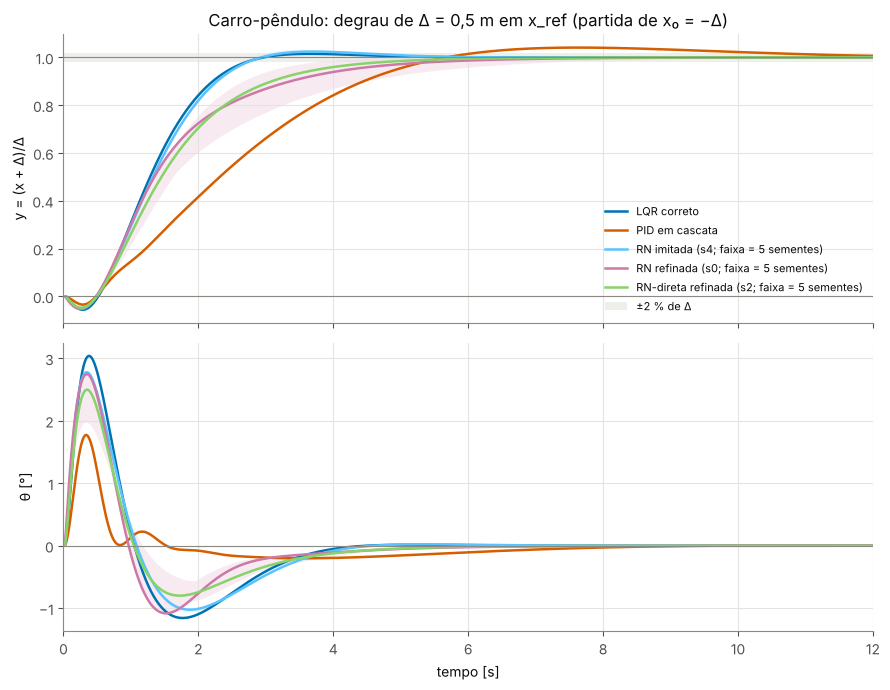

**Figura `degrau_pendulo.png`.** Resposta ao degrau de Δ = 0,5 m na referência de posição do carro-pêndulo (equivalente a x₀ = −Δ com alvo na origem; primeiros 12 s da janela de 20 s): posição normalizada y = (x + Δ)/Δ e ângulo θ do LQR correto, do PID em cascata, da RN imitada, da RN refinada e da RN-direta refinada; RN: semente de J mediano e faixa mínimo–máximo de 5 sementes; faixa de ±2 % de Δ sombreada. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

In [54]:
# Degrau em x_ref no carro-pêndulo: todos os controladores do C2, Δ = 0,2 e 0,5 m, 20 s.
lista_degrau = controladores(VARIANTES_C1, fixos=("PID em cascata", "LQR correto", "LQR aproximado"))
RES_DEGRAU = {}
for rotulo, familia, etapa, semente, politica in lista_degrau:
    for delta in DELTAS_DEGRAU:
        sim = simular(planta, politica, estado_inicial_degrau(delta), T=T_DEGRAU)
        RES_DEGRAU[(rotulo, delta)] = dict(familia=familia, etapa=etapa, semente=semente, sim=sim, **metricas_degrau_pendulo(planta, sim, delta))
METRICAS_DEGRAU = ["tempo de subida [s]", "sobressinal [% de Δ]", "recuo inicial [% de Δ]", "acomodação a 2 % [s]", "|θ| máx. [°]", "|F| máx. [N]",
                   "% saturado", "J"]
TAB_DEGRAU = pd.DataFrame([{"controlador": rot, "Δ [m]": d, **{m: r[m] for m in METRICAS_DEGRAU + ["y final", "caiu"]}}
                           for (rot, d), r in RES_DEGRAU.items()]).set_index(["controlador", "Δ [m]"])
registrar_tabela("degrau/pendulo/tabela", TAB_DEGRAU)
for (rot, d), r in RES_DEGRAU.items():
    X = np.ascontiguousarray(r["sim"]["X"], dtype=np.float64)
    U = np.ascontiguousarray(r["sim"]["U"], dtype=np.float64)
    TRAJETORIAS[f"degrau/pendulo/{chave_controlador(rot)}/delta{d}"] = hashlib.sha256(X.tobytes() + U.tobytes()).hexdigest()

# Resumo: as linhas desta seção, mediana (mín. a máx.) nas RN.
FORMATO_DEGRAU = {"tempo de subida [s]": "{:.2f}", "sobressinal [% de Δ]": "{:.1f}", "recuo inicial [% de Δ]": "{:.1f}", "acomodação a 2 % [s]": "{:.2f}",
                  "|θ| máx. [°]": "{:.2f}", "|F| máx. [N]": "{:.2f}", "% saturado": "{:.1f}", "J": "{:.4g}"}
RESUMO_DEGRAU = pd.DataFrame({nome: {(m, f"Δ = {br(d)} m"): celula([RES_DEGRAU[(r, d)][m] for r in rotulos], FORMATO_DEGRAU[m])
                                     for m in METRICAS_DEGRAU for d in DELTAS_DEGRAU}
                              for nome, rotulos in linhas_novas("PID em cascata", "LQR correto")})
RESUMO_DEGRAU.index.names = ["métrica", "degrau"]
registrar_tabela("degrau/pendulo/resumo", RESUMO_DEGRAU)
legenda_csv("degrau__pendulo__tabela.csv", "Degrau em x_ref no carro-pêndulo (x₀ = −Δ, alvo na origem, 20 s), Δ = 0,2 e 0,5 m, por controlador "
            "e semente (todos os controladores do C2): tempo de subida, sobressinal, recuo inicial, acomodação a 2 % de Δ, "
            "|θ| máx., |F| máx., % do tempo saturado, J, y final e queda.")
mostrar_tabela(RESUMO_DEGRAU, "Degrau em x_ref no carro-pêndulo (x₀ = −Δ, alvo na origem, 20 s): tempo de subida (10–90 %, interpolado), "
               "sobressinal, recuo inicial e acomodação a 2 % de Δ, |θ| máx., |F| máx., % do tempo saturado e J; RN: mediana (mín. a máx.) "
               "de 5 sementes. " + LEGENDA_DIRETA, csv="degrau__pendulo__resumo.csv", opcoes={"display.max_colwidth": 26})

# Conferência do LQR correto e do PID em cascata contra uma implementação independente (sem RN), nos dois Δ.
REF_DEGRAU = {"LQR correto": {"tempo de subida [s]": 1.52, "sobressinal [% de Δ]": 1.5, "recuo inicial [% de Δ]": 5.6, "acomodação a 2 % [s]": 2.72, "|θ| máx. [°]": 3.0},
              "PID em cascata": {"tempo de subida [s]": 3.64, "sobressinal [% de Δ]": 4.1, "recuo inicial [% de Δ]": 3.5, "acomodação a 2 % [s]": 10.24, "|θ| máx. [°]": 1.8}}
TOL_DEGRAU = {"tempo de subida [s]": 0.02, "sobressinal [% de Δ]": 0.05, "recuo inicial [% de Δ]": 0.05, "acomodação a 2 % [s]": 0.02, "|θ| máx. [°]": 0.05}
difs_degrau = {}
for nome, ref_ in REF_DEGRAU.items():
    for m, v in ref_.items():
        for d in (DELTAS_DEGRAU if m != "|θ| máx. [°]" else [0.5]):
            difs_degrau[(nome, m, d)] = abs(RES_DEGRAU[(nome, d)][m] - v)
saturou_degrau = max(RES_DEGRAU[(nome, d)]["% saturado"] for nome in REF_DEGRAU for d in DELTAS_DEGRAU)
pior_degrau = max(difs_degrau, key=lambda k: difs_degrau[k] / TOL_DEGRAU[k[1]])
verificar("degrau-conferencia — degrau em x_ref (Δ = 0,2 e 0,5 m), LQR correto e PID em cascata = implementação independente: subida, "
          "sobressinal, recuo, acomodação e |θ| máx. a 0,5 m; nada satura",
          all(v <= TOL_DEGRAU[k[1]] + 1e-9 for k, v in difs_degrau.items()) and saturou_degrau == 0,
          f"pior: {pior_degrau[0]}, {pior_degrau[1]}, Δ = {pior_degrau[2]} m, diferença {difs_degrau[pior_degrau]:.3f}; saturado {saturou_degrau:.1f} %",
          tol="0,02 s nos tempos; 0,05 nos % e em graus")
registrar_numeros("degrau/pendulo/conferencia", {f"{n} | {m} | delta{d}": v for (n, m, d), v in difs_degrau.items()})
figura_degrau_pendulo(RES_DEGRAU, 0.5)

**Tabela `degrau__infusao__resumo.csv`.** Degrau de referência na infusão: C₀ = 0 (degrau de 0,15) e C₀ = 0,14 (degrau de 0,01): tempo de subida (10–90 %, interpolado entre amostras de 10 s), limite físico (u = u_max constante, solução contínua), sobressinal Mp, acomodação a 2 % e % do tempo saturado; RN: mediana (mín. a máx.) de 5 sementes. Os outros C₀, inclusive os degraus negativos: degrau__infusao__tabela.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

tempo de subida [s] limite físico [s]  sobressinal Mp [%] acomodação a 2 % [s]          % saturado
controlador        degrau                                                                                                         
LQR                C₀ = 0                     178.7             178.7                0.00                  230                14.7
                   C₀ = 0,14                   26.4              19.1                0.00                   50                 0.7
PI                 C₀ = 0                     178.7             178.7                0.60                  230                14.7
                   C₀ = 0,14                   21.1              19.1                3.78                   70                 1.3
RN imitada         C₀ = 0     179.2 (179.1 a 179.2)             178.7  0.00 (0.00 a 0.00)      230 (230 a 240)  12.7 (12.7 a 12.7)
                   C₀ = 0,14     36.6 (36.2 a 38.3)              19.1  0.00 (0.00 a 0.00)         70 (60 a 70)     0.0 (0.0 a 0.0)
RN refinada        C₀ = 0     178.7 (178.7 a 178.7)             178.7  0.00 (0.00 a 0.00)      230 (230 a 230)  14.0 (14.0 a 14.0)
                   C₀ = 0,14     25.3 (25.3 a 25.4)              19.1  0.00 (0.00 a 0.00)         40 (40 a 40)     0.0 (0.0 a 0.0)
RN-direta refinada C₀ = 0     178.7 (178.7 a 178.7)             178.7  0.00 (0.00 a 0.00)      230 (230 a 230)  14.0 (14.0 a 14.0)
                   C₀ = 0,14     25.2 (25.2 a 25.4)              19.1  0.00 (0.00 a 0.00)         40 (40 a 40)     0.0 (0.0 a 0.0)

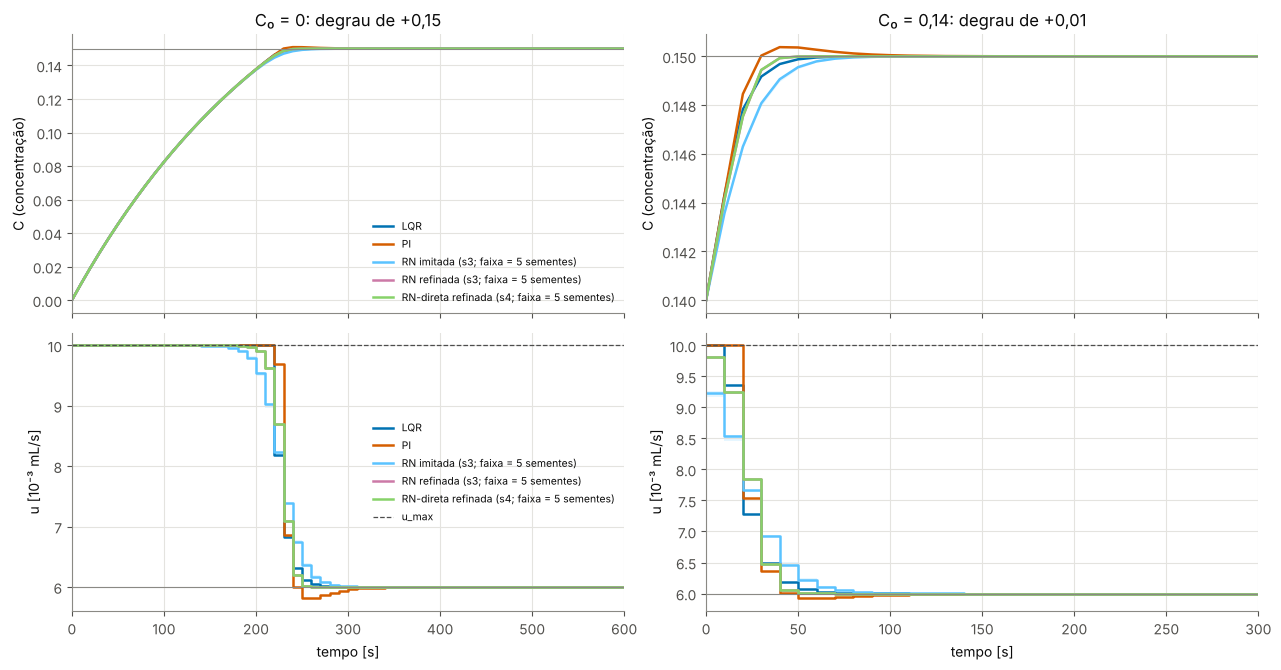

**Figura `degrau_infusao.png`.** Resposta ao degrau de referência na infusão, lida das simulações do C2 e do C1: concentração C e vazão u a partir de C₀ = 0 (degrau de 0,15; primeiros 600 s) e de C₀ = 0,14 (degrau de 0,01; primeiros 300 s), com C_ref = 0,15: PI, LQR, RN imitada, RN refinada e RN-direta refinada; RN: semente de J mediano e faixa mínimo–máximo de 5 sementes; u_max marcado. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

In [55]:
# Degrau de referência na infusão: as simulações do C2 (com o C1), todos os controladores.
linhas_ = []
for rotulo, familia, etapa, semente, _ in lista_inf:
    for c0 in CONDS_INF:
        r = RES_C2_INF[(rotulo, c0)]
        linhas_.append({"controlador": rotulo, "C₀": c0, "degrau C_ref − C₀": planta_inf.C_ref - c0,
                        "sentido": "positivo" if c0 < planta_inf.C_ref else "negativo (a bomba só pode ficar em 0)",
                        "tempo de subida [s]": subida_regulacao(planta_inf, r["sim"]), "limite físico [s]": LIMITE_FISICO[c0],
                        "sobressinal Mp [%]": r["Mp [%]"], "acomodação a 2 % [s]": r["acomodação C [s]"], "% saturado": r["% saturado"],
                        "erro final [% de C_ref]": r["erro final [% de C_ref]"]})
TAB_DEGRAU_INF = pd.DataFrame(linhas_).set_index(["controlador", "C₀"])
registrar_tabela("degrau/infusao/tabela", TAB_DEGRAU_INF)
METRICAS_DEGRAU_INF = {"tempo de subida [s]": "{:.1f}", "sobressinal Mp [%]": "{:.2f}", "acomodação a 2 % [s]": "{:.0f}", "% saturado": "{:.1f}"}
tab_ = {}
for nome, rotulos in linhas_novas("PI", "LQR"):
    for c0 in [0.0, C1_INF]:
        tab_[(nome, f"C₀ = {c0:g}".replace(".", ","))] = {m: celula([TAB_DEGRAU_INF.loc[(r, c0), m] for r in rotulos], f) for m, f in METRICAS_DEGRAU_INF.items()}
RESUMO_DEGRAU_INF = pd.DataFrame(tab_).T
RESUMO_DEGRAU_INF.index.names = ["controlador", "degrau"]
RESUMO_DEGRAU_INF.insert(1, "limite físico [s]", [f"{LIMITE_FISICO[0.0 if '0,14' not in d else C1_INF]:.1f}" for _, d in RESUMO_DEGRAU_INF.index])
registrar_tabela("degrau/infusao/resumo", RESUMO_DEGRAU_INF)
legenda_csv("degrau__infusao__tabela.csv", "Degrau de referência na infusão (as simulações do C2 e do C1, lidas como degraus de C_ref − C₀; "
            "negativos em C₀ = 0,18 e 0,22), por controlador e semente: tempo de subida (10–90 %, interpolado entre amostras), limite "
            "físico (vazão constante no limite do atuador, solução contínua), sobressinal Mp, acomodação a 2 %, % do tempo saturado e erro final.")
mostrar_tabela(RESUMO_DEGRAU_INF, "Degrau de referência na infusão: C₀ = 0 (degrau de 0,15) e C₀ = 0,14 (degrau de 0,01): tempo de subida "
               "(10–90 %, interpolado entre amostras de 10 s), limite físico (u = u_max constante, solução contínua), sobressinal Mp, acomodação "
               "a 2 % e % do tempo saturado; RN: mediana (mín. a máx.) de 5 sementes. Os outros C₀, inclusive os degraus negativos: "
               "degrau__infusao__tabela.csv. " + LEGENDA_DIRETA, csv="degrau__infusao__resumo.csv", opcoes={"display.max_colwidth": 26})
figura_degrau_infusao(RES_C2_INF, [0.0, C1_INF], [600, 300])

In [56]:
# C1: tempo de subida (θ de 15° a 0; C de 0,14 a 0,15) de todos os controladores do C1, e a matriz 2 × 3 com essa linha.
linhas_ = []
for chave_planta, res, lista_, cond, p_ in [("pendulo", RES_C1, lista_c1, C1_ANGULO, planta), ("infusao", RES_C1_INF, lista_inf, C1_INF, planta_inf)]:
    for rotulo, *_ in lista_:
        linhas_.append({"planta": chave_planta, "controlador": rotulo, "tempo de subida [s]": subida_regulacao(p_, res[(rotulo, cond)]["sim"])})
TAB_SUBIDA_C1 = pd.DataFrame(linhas_).set_index(["planta", "controlador"])
registrar_tabela("metricas_ampliadas/C1/tempo_de_subida", TAB_SUBIDA_C1)
SUBIDA_C1 = {k: v for k, v in TAB_SUBIDA_C1["tempo de subida [s]"].items()}
tab_ = {}
for chave_planta, titulo, nome_pid, nome_lqr in [("pendulo", "carro-pêndulo, θ₀ = 15° (θ de 15° a 0)", "PID em cascata", "LQR correto"),
                                                 ("infusao", "infusão, C₀ = 0,14 (C de 0,14 a 0,15)", "PI", "LQR")]:
    tab_[titulo] = {nome if nome not in (nome_pid, nome_lqr) else ("PID / PI" if nome == nome_pid else "LQR"):
                    celula([SUBIDA_C1[(chave_planta, r)] for r in rotulos], "{:.3g}") for nome, rotulos in linhas_novas(nome_pid, nome_lqr)}
SUBIDA_C1_TEXTO = pd.DataFrame(tab_).T[["PID / PI", "LQR", "RN imitada", "RN refinada", "RN-direta refinada"]]
SUBIDA_C1_TEXTO.index.name = "tempo de subida [s]"
registrar_tabela("metricas_ampliadas/C1/tempo_de_subida_texto", SUBIDA_C1_TEXTO)

# A matriz 2 × 3 de 4.1 com a linha de tempo de subida depois da acomodação (a de 4.1 não muda).
partes = []
for chave_planta, titulo in [("pendulo", "carro-pêndulo, θ₀ = 15°"), ("infusao", "infusão, C₀ = 0,14")]:
    bloco = MATRIZ_C1_EXIBIDA.loc[[titulo]]
    linha_nova = SUBIDA_C1_TEXTO.iloc[[0 if chave_planta == "pendulo" else 1]][["PID / PI", "LQR", "RN refinada"]]
    linha_nova.index = pd.MultiIndex.from_tuples([(titulo, "tempo de subida [s]")])
    i_ac = [j for j, (_, m) in enumerate(bloco.index) if m.startswith("acomodação")][0]
    partes.append(pd.concat([bloco.iloc[:i_ac + 1], linha_nova, bloco.iloc[i_ac + 1:]]))
MATRIZ_C1_COM_SUBIDA = pd.concat(partes)
MATRIZ_C1_COM_SUBIDA.index.names = ["planta", "métrica"]
registrar_tabela("metricas_ampliadas/C1/matriz_2x3_com_subida", MATRIZ_C1_COM_SUBIDA)
legenda_csv("metricas_ampliadas__C1__tempo_de_subida.csv", "Tempo de subida no C1 (10–90 %, interpolado entre amostras): θ de 15° a 0 no "
            "carro-pêndulo e C de 0,14 a 0,15 na infusão, por controlador e semente (todos os controladores do C1).")
legenda_csv("metricas_ampliadas__C1__matriz_2x3_com_subida.csv", "Matriz 2 × 3 no C1 (a de matriz__C1_2x3_texto.csv) com a linha de tempo de "
            "subida (10–90 %, interpolado entre amostras: θ de 15° a 0; C de 0,14 a 0,15) depois da acomodação; RN refinada: mediana (mín. a máx.) "
            "de 5 sementes.")
mostrar_tabela(SUBIDA_C1_TEXTO, "Tempo de subida no C1 [s] (10–90 %, interpolado entre amostras): θ de 15° a 0 no carro-pêndulo e C de 0,14 a "
               "0,15 na infusão; RN: mediana (mín. a máx.) de 5 sementes. A matriz 2 × 3 com esta linha: "
               "metricas_ampliadas__C1__matriz_2x3_com_subida.csv. " + LEGENDA_DIRETA, csv="metricas_ampliadas__C1__tempo_de_subida_texto.csv",
               opcoes={"display.max_colwidth": 26})

**Tabela `metricas_ampliadas__C1__tempo_de_subida_texto.csv`.** Tempo de subida no C1 [s] (10–90 %, interpolado entre amostras): θ de 15° a 0 no carro-pêndulo e C de 0,14 a 0,15 na infusão; RN: mediana (mín. a máx.) de 5 sementes. A matriz 2 × 3 com esta linha: metricas_ampliadas__C1__matriz_2x3_com_subida.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

,PID / PI,LQR,RN imitada,RN refinada,RN-direta refinada
tempo de subida [s],,,,,
"carro-pêndulo, θ₀ = 15° (θ de 15° a 0)",0.118,0.186,0.18 (0.179 a 0.185),0.196 (0.185 a 0.211),0.191 (0.189 a 0.192)
"infusão, C₀ = 0,14 (C de 0,14 a 0,15)",21.1,26.4,36.6 (36.2 a 38.3),25.3 (25.3 a 25.4),25.2 (25.2 a 25.4)


In [57]:
# C2: tempo de subida, acomodação e pico pós-cruzamento (pêndulo) ou sobressinal (infusão), por condição inicial, todos os controladores.
METRICAS_C2 = {"pendulo": [("tempo de subida [s]", None), ("acomodação a 2 % [s]", "acomodação θ [s]"), ("pico pós-cruzamento [% de θ₀]", "pico [% de θ₀]")],
               "infusao": [("tempo de subida [s]", None), ("acomodação a 2 % [s]", "acomodação C [s]"), ("sobressinal Mp [%]", "Mp [%]")]}
TABS_C2_AMPL = {}
for chave_planta, res, lista_, conds, p_ in [("pendulo", RES_C2, lista_c2, ANGULOS_C2, planta), ("infusao", RES_C2_INF, lista_inf, CONDS_INF, planta_inf)]:
    linhas_ = []
    for rotulo, *_ in lista_:
        for cond in conds:
            r = res[(rotulo, cond)]
            linha = {"controlador": rotulo, "condição": cond}
            for m, chave in METRICAS_C2[chave_planta]:
                linha[m] = subida_regulacao(p_, r["sim"]) if chave is None else (np.nan if (r["caiu"] or r["divergiu"]) else r[chave])
            linhas_.append(linha)
    TABS_C2_AMPL[chave_planta] = pd.DataFrame(linhas_).set_index(["controlador", "condição"])
    registrar_tabela(f"metricas_ampliadas/C2/{chave_planta}", TABS_C2_AMPL[chave_planta])

# Por condição inicial, as linhas desta seção (texto, só CSV); na tela, mediana (mín. a máx.) sobre condições e sementes.
resumos_ = []
for chave_planta, conds, nome_pid, nome_lqr, rotulo_c in [("pendulo", ANGULOS_C2, "PID em cascata", "LQR correto", lambda c: f"θ₀ = {c}°"),
                                                          ("infusao", CONDS_INF, "PI", "LQR", lambda c: f"C₀ = {c:g}".replace(".", ","))]:
    t_ = TABS_C2_AMPL[chave_planta]
    tab_, res_ = {}, {}
    for nome, rotulos in linhas_novas(nome_pid, nome_lqr):
        for m, _ in METRICAS_C2[chave_planta]:
            fmt = "{:.3g}"
            tab_[(nome, m)] = {rotulo_c(c): celula([t_.loc[(r, c), m] for r in rotulos], fmt) for c in conds}
            v = np.array([t_.loc[(r, c), m] for r in rotulos for c in conds], dtype=float)
            res_[(nome, m)] = {"mediana (mín. a máx.) sobre condições e sementes": celula(v[np.isfinite(v)], fmt) if np.isfinite(v).any() else "—",
                               "sem valor (caiu ou não acomodou)": f"{int((~np.isfinite(v)).sum())} de {len(v)}"}
    texto_ = pd.DataFrame(tab_).T
    texto_.index.names = ["controlador", "métrica"]
    registrar_tabela(f"metricas_ampliadas/C2/{chave_planta}_texto", texto_)
    resumo_ = pd.DataFrame(res_).T
    resumo_.index.names = ["controlador", "métrica"]
    resumos_.append(resumo_)
legenda_csv("metricas_ampliadas__C2__pendulo.csv", "C2 do carro-pêndulo, por controlador, semente e θ₀ (todos os controladores do C2): tempo de "
            "subida (θ de θ₀ a 0, 10–90 %, interpolado), acomodação a 2 % e pico pós-cruzamento em % de θ₀; NaN onde caiu ou não acomodou.")
legenda_csv("metricas_ampliadas__C2__infusao.csv", "C2 da infusão (com o C1), por controlador, semente e C₀ (todos os controladores do C2): tempo "
            "de subida (C de C₀ a C_ref, 10–90 %, interpolado entre amostras de 10 s), acomodação a 2 % e sobressinal Mp.")
legenda_csv("metricas_ampliadas__C2__pendulo_texto.csv", "C2 do carro-pêndulo, por θ₀: tempo de subida, acomodação a 2 % e pico pós-cruzamento "
            "(% de θ₀) do LQR correto, do PID em cascata, da RN imitada, da RN refinada e da RN-direta refinada; RN: mediana (mín. a máx.) "
            "de 5 sementes; \"sem valor\": caiu ou não acomodou. " + LEGENDA_DIRETA)
legenda_csv("metricas_ampliadas__C2__infusao_texto.csv", "C2 da infusão, por C₀: tempo de subida, acomodação a 2 % e sobressinal Mp do LQR, do "
            "PI, da RN imitada, da RN refinada e da RN-direta refinada; RN: mediana (mín. a máx.) de 5 sementes. " + LEGENDA_DIRETA)
mostrar_tabela(resumos_[0], "C2 do carro-pêndulo, θ₀ de 5° a 60°: tempo de subida (θ de θ₀ a 0) e acomodação a 2 % [s], pico pós-cruzamento "
               "[% de θ₀]; mediana (mín. a máx.) sobre θ₀ e sementes, sem as simulações que caíram ou não acomodaram. Por θ₀: "
               "metricas_ampliadas__C2__pendulo_texto.csv. " + LEGENDA_DIRETA, opcoes={"display.max_colwidth": 30})


**Tabela.** C2 do carro-pêndulo, θ₀ de 5° a 60°: tempo de subida (θ de θ₀ a 0) e acomodação a 2 % [s], pico pós-cruzamento [% de θ₀]; mediana (mín. a máx.) sobre θ₀ e sementes, sem as simulações que caíram ou não acomodaram. Por θ₀: metricas_ampliadas__C2__pendulo_texto.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

mediana (mín. a máx.) sobre condições e sementes sem valor (caiu ou não acomodou)
controlador        métrica                                                                                                        
LQR correto        tempo de subida [s]                     0.187 (0.18 a 0.222)                                          3 de 12  
                   acomodação a 2 % [s]                      3.68 (3.58 a 3.84)                                          3 de 12  
                   pico pós-cruzamento [% de θ₀]             47.2 (37.8 a 86.7)                                          3 de 12  
PID em cascata     tempo de subida [s]                     0.165 (0.116 a 0.38)                                          0 de 12  
                   acomodação a 2 % [s]                       2.76 (1.62 a 9.2)                                          1 de 12  
                   pico pós-cruzamento [% de θ₀]             72.7 (46.8 a 84.2)                                          0 de 12  
RN imitada         tempo de subida [s]                    0.183 (0.178 a 0.254)                                         19 de 60  
                   acomodação a 2 % [s]                       3.92 (3.5 a 5.02)                                         19 de 60  
                   pico pós-cruzamento [% de θ₀]              44.3 (30.9 a 104)                                         19 de 60  
RN refinada        tempo de subida [s]                      0.2 (0.185 a 0.238)                                         21 de 60  
                   acomodação a 2 % [s]                      3.38 (2.46 a 4.26)                                         21 de 60  
                   pico pós-cruzamento [% de θ₀]              47.1 (26.9 a 100)                                         21 de 60  
RN-direta refinada tempo de subida [s]                    0.195 (0.186 a 0.238)                                         22 de 60  
                   acomodação a 2 % [s]                      3.49 (2.58 a 3.72)                                         22 de 60  
                   pico pós-cruzamento [% de θ₀]              44.3 (33.9 a 104)                                         22 de 60

**Tabela.** C2 da infusão, C₀ de 0 a 0,22 (com o C1): tempo de subida (C de C₀ a C_ref) e acomodação a 2 % [s], sobressinal Mp [%]; mediana (mín. a máx.) sobre C₀ e sementes. Por C₀: metricas_ampliadas__C2__infusao_texto.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

mediana (mín. a máx.) sobre condições e sementes sem valor (caiu ou não acomodou)
controlador        métrica                                                                                               
LQR                tempo de subida [s]               78.6 (26.4 a 179)                                           0 de 6  
                   acomodação a 2 % [s]                 110 (50 a 230)                                           0 de 6  
                   sobressinal Mp [%]                        0 (0 a 0)                                           0 de 6  
PI                 tempo de subida [s]               78.5 (21.1 a 179)                                           0 de 6  
                   acomodação a 2 % [s]                 100 (70 a 230)                                           0 de 6  
                   sobressinal Mp [%]             0.911 (0.268 a 3.78)                                           0 de 6  
RN imitada         tempo de subida [s]               82.3 (36.2 a 179)                                          0 de 30  
                   acomodação a 2 % [s]                 115 (60 a 240)                                          0 de 30  
                   sobressinal Mp [%]                        0 (0 a 0)                                          0 de 30  
RN refinada        tempo de subida [s]               79.1 (25.3 a 179)                                          0 de 30  
                   acomodação a 2 % [s]                 105 (40 a 230)                                          0 de 30  
                   sobressinal Mp [%]                        0 (0 a 0)                                          0 de 30  
RN-direta refinada tempo de subida [s]               79.1 (25.2 a 179)                                          0 de 30  
                   acomodação a 2 % [s]                 105 (40 a 230)                                          0 de 30  
                   sobressinal Mp [%]                        0 (0 a 0)                                          0 de 30

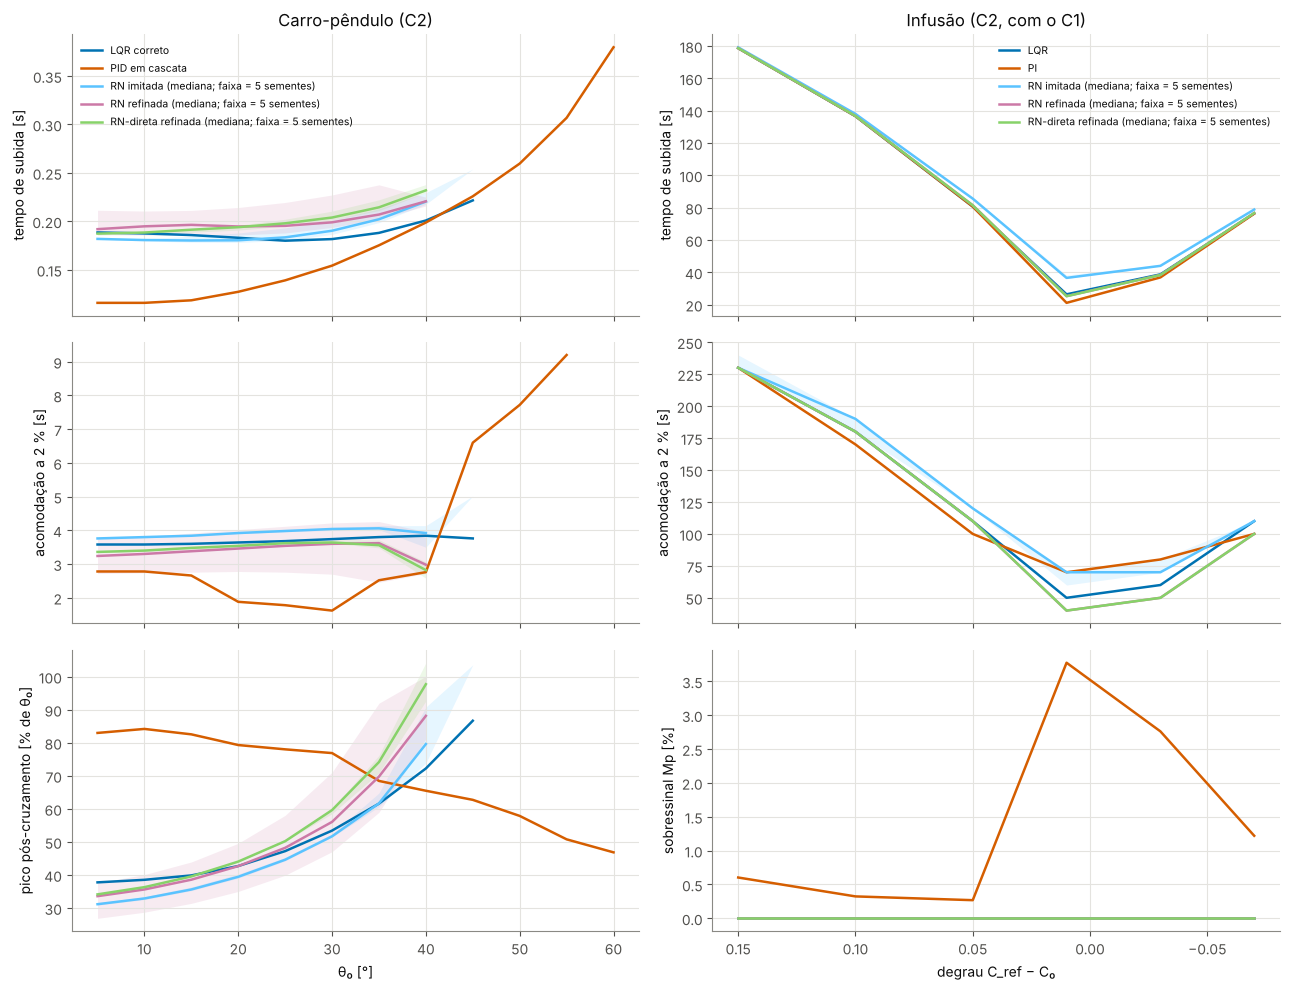

**Figura `C2_metricas_classicas.png`.** Métricas clássicas no C2: tempo de subida, acomodação a 2 % e pico pós-cruzamento (% de θ₀) do carro-pêndulo em função de θ₀; tempo de subida, acomodação a 2 % e sobressinal Mp da infusão em função do degrau C_ref − C₀ (degraus negativos à direita). LQR, PID em cascata ou PI, RN imitada, RN refinada e RN-direta refinada; RN: mediana (onde ao menos 3 de 5 sementes têm valor) e faixa mínimo–máximo de 5 sementes; sem ponto onde o controlador cai ou não acomoda. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

In [58]:
# C2: resumo da infusão e figura.
mostrar_tabela(resumos_[1], "C2 da infusão, C₀ de 0 a 0,22 (com o C1): tempo de subida (C de C₀ a C_ref) e acomodação a 2 % [s], sobressinal "
               "Mp [%]; mediana (mín. a máx.) sobre C₀ e sementes. Por C₀: metricas_ampliadas__C2__infusao_texto.csv. " + LEGENDA_DIRETA,
               opcoes={"display.max_colwidth": 30})

# Figura: as três métricas em função da amplitude.
def series_c2(chave_planta, conds, nome_pid, nome_lqr):
    t_ = TABS_C2_AMPL[chave_planta]
    return {m: [(nome, np.array([[t_.loc[(r, c), m] for c in conds] for r in rotulos], dtype=float), COR[nome])
                for nome, rotulos in linhas_novas(nome_pid, nome_lqr)] for m, _ in METRICAS_C2[chave_planta]}


figura_C2_metricas_classicas(
    (np.array(ANGULOS_C2), series_c2("pendulo", ANGULOS_C2, "PID em cascata", "LQR correto"), "θ₀ [°]", "Carro-pêndulo (C2)"),
    (planta_inf.C_ref - np.array(CONDS_INF), series_c2("infusao", CONDS_INF, "PI", "LQR"), "degrau C_ref − C₀", "Infusão (C2, com o C1)"))

In [59]:
# C3: acomodação e pico pós-cruzamento (pêndulo) ou sobressinal (infusão) nas 100 plantas, das métricas por realização de 4.3.
METRICAS_C3 = {"pendulo": [("acomodação a 2 % [s]", "acomodação θ [s]"), ("pico pós-cruzamento [% de θ₀]", "pico [% de θ₀]")],
               "infusao": [("acomodação a 2 % [s]", "acomodação C [s]"), ("sobressinal Mp [%]", "Mp [%]")]}
linhas_num, textos_ = [], {}
for chave_planta, res, lista_, conds, nome_pid, nome_lqr in [("pendulo", RES_C3_PEND, lista_c3, CONDICOES_C3_PEND, "PID em cascata", "LQR correto"),
                                                             ("infusao", RES_C3_INF, lista_c3_inf, CONDICOES_C3_INF, "PI", "LQR")]:
    for rotulo, familia, etapa, semente, _ in lista_:
        for cond in conds:
            t_ = res[(rotulo, cond)]
            for m, chave in METRICAS_C3[chave_planta]:
                v = t_[chave].to_numpy(dtype=float)
                ok = v[np.isfinite(v)]
                linhas_num.append({"planta": chave_planta, "controlador": rotulo, "condição": cond, "métrica": m,
                                   "mediana": np.median(ok) if len(ok) else np.nan, "P25": np.percentile(ok, 25) if len(ok) else np.nan,
                                   "P75": np.percentile(ok, 75) if len(ok) else np.nan, "com valor": len(ok), "sem valor (caiu ou não acomodou)": len(v) - len(ok)})
TAB_C3_AMPL = pd.DataFrame(linhas_num).set_index(["planta", "controlador", "condição", "métrica"])
registrar_tabela("metricas_ampliadas/C3/tabela", TAB_C3_AMPL)

# Texto: controlador fixo, "mediana [P25 a P75]"; RN, a mediana entre sementes da mediana (mín. a máx.) e do P25 e do P75.
partes = {}
for chave_planta, conds, nome_pid, nome_lqr, rotulo_c in [("pendulo", CONDICOES_C3_PEND, "PID em cascata", "LQR correto", lambda c: f"θ₀ = {c}°"),
                                                          ("infusao", CONDICOES_C3_INF, "PI", "LQR", lambda c: f"C₀ = {c:g}".replace(".", ","))]:
    tab_ = {}
    for nome, rotulos in linhas_novas(nome_pid, nome_lqr):
        for cond in conds:
            celulas_ = {}
            for m, _ in METRICAS_C3[chave_planta]:
                q = TAB_C3_AMPL.loc[[(chave_planta, r, cond, m) for r in rotulos]]
                fmt = "{:.3g}"
                med = celula(q["mediana"], fmt)
                celulas_[m] = f"{med} [{fmt.format(np.median(q['P25']))} a {fmt.format(np.median(q['P75']))}]"
                if q["sem valor (caiu ou não acomodou)"].sum():
                    celulas_[m] += f" · sem valor {int(q['sem valor (caiu ou não acomodou)'].sum())} de {100 * len(rotulos)}"
            tab_[(nome, rotulo_c(cond))] = celulas_
    partes[chave_planta] = pd.DataFrame(tab_).T
    partes[chave_planta].index.names = ["controlador", "condição"]
    registrar_tabela(f"metricas_ampliadas/C3/{chave_planta}_texto", partes[chave_planta])
legenda_csv("metricas_ampliadas__C3__tabela.csv", "C3 (100 plantas a ±20 %), por controlador, semente e condição inicial: mediana, P25 e P75 da "
            "acomodação a 2 % e do pico pós-cruzamento (pêndulo) ou do sobressinal Mp (infusão) nas plantas em que há valor, e quantas não têm "
            "(caiu ou não acomodou); todos os controladores do C3.")
mostrar_tabela(partes["pendulo"], "C3 do carro-pêndulo (100 plantas com M, m e l a ±20 %): acomodação a 2 % [s] e pico pós-cruzamento [% de θ₀], "
               "mediana [P25 a P75] nas plantas em que há valor; RN: mediana entre sementes da mediana (mín. a máx.) e do P25 e do P75; "
               "\"sem valor\": caiu ou não acomodou. " + LEGENDA_DIRETA, csv="metricas_ampliadas__C3__pendulo_texto.csv", opcoes={"display.max_colwidth": 70})
mostrar_tabela(partes["infusao"], "C3 da infusão (100 plantas com V₁ e Ω a ±20 %): acomodação a 2 % [s] e sobressinal Mp [%], mediana [P25 a P75] "
               "nas plantas em que há valor (\"sem valor\": não acomodou, isto é, terminou fora da faixa de 2 % da amplitude); RN: mediana entre sementes da mediana (mín. a máx.) e do P25 e do P75. LQR-ganho-1,45K e LQR-ganho-Kef: "
               "metricas_ampliadas__C3__tabela.csv. " + LEGENDA_DIRETA, csv="metricas_ampliadas__C3__infusao_texto.csv", opcoes={"display.max_colwidth": 70})

**Tabela `metricas_ampliadas__C3__pendulo_texto.csv`.** C3 do carro-pêndulo (100 plantas com M, m e l a ±20 %): acomodação a 2 % [s] e pico pós-cruzamento [% de θ₀], mediana [P25 a P75] nas plantas em que há valor; RN: mediana entre sementes da mediana (mín. a máx.) e do P25 e do P75; "sem valor": caiu ou não acomodou. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

acomodação a 2 % [s]                          pico pós-cruzamento [% de θ₀]
controlador        condição                                                                                                             
LQR correto        θ₀ = 15°                                     3.6 [3.56 a 3.66]                                     39.4 [36.7 a 43.8]
                   θ₀ = 30°                                      3.76 [3.7 a 3.8]                                       52.8 [48 a 59.6]
PID em cascata     θ₀ = 15°                                     2.6 [2.06 a 2.84]                                     81.9 [70.7 a 94.9]
                   θ₀ = 30°                                    2.15 [1.76 a 2.42]                                     73.5 [67.4 a 79.6]
RN imitada         θ₀ = 15°                      3.84 (3.84 a 3.86) [3.82 a 3.88]                       35.4 (35.1 a 36.1) [33.6 a 38.1]
                   θ₀ = 30°                            4.04 (4 a 4.08) [4 a 4.06]                         51 (50.8 a 51.8) [46.7 a 57.9]
RN refinada        θ₀ = 15°                       3.38 (2.76 a 3.92) [3.34 a 3.4]                       38.4 (31.3 a 43.8) [36.5 a 41.3]
                   θ₀ = 30°  3.6 (2.75 a 4.22) [3.58 a 3.62] · sem valor 2 de 500  55.3 (46.5 a 69.6) [50.4 a 64.8] · sem valor 2 de 500
RN-direta refinada θ₀ = 15°                      3.48 (3.43 a 3.48) [3.44 a 3.52]                         39.3 (39.1 a 39.4) [37 a 42.8]
                   θ₀ = 30°                        3.64 (3.62 a 3.7) [3.54 a 3.7]                         58.7 (57.6 a 59.1) [52 a 69.3]

**Tabela `metricas_ampliadas__C3__infusao_texto.csv`.** C3 da infusão (100 plantas com V₁ e Ω a ±20 %): acomodação a 2 % [s] e sobressinal Mp [%], mediana [P25 a P75] nas plantas em que há valor ("sem valor": não acomodou, isto é, terminou fora da faixa de 2 % da amplitude); RN: mediana entre sementes da mediana (mín. a máx.) e do P25 e do P75. LQR-ganho-1,45K e LQR-ganho-Kef: metricas_ampliadas__C3__tabela.csv. RN-direta refinada: refinada pela planta exata; o gradiente é exato por autodiferenciação do simulador, uma idealização do controle direto.

acomodação a 2 % [s]     sobressinal Mp [%]
controlador        condição                                                                         
LQR                C₀ = 0,14               40 [40 a 50] · sem valor 90 de 100             0 [0 a 11]
                   C₀ = 0                                     220 [200 a 242]          0 [0 a 0.732]
PI                 C₀ = 0,14                                     70 [40 a 90]    4.14 [0.855 a 9.34]
                   C₀ = 0                                     220 [200 a 240]  0.347 [0.138 a 0.668]
RN imitada         C₀ = 0,14  60 (60 a 60) [60 a 62.5] · sem valor 460 de 500   0 (0 a 0) [0 a 12.4]
                   C₀ = 0                         230 (230 a 230) [210 a 252]  0 (0 a 0) [0 a 0.824]
RN refinada        C₀ = 0,14  35 (35 a 40) [30 a 42.5] · sem valor 440 de 500   0 (0 a 0) [0 a 7.67]
                   C₀ = 0                         220 (220 a 220) [200 a 250]  0 (0 a 0) [0 a 0.509]
RN-direta refinada C₀ = 0,14  35 (35 a 40) [30 a 42.5] · sem valor 440 de 500   0 (0 a 0) [0 a 7.62]
                   C₀ = 0                         220 (220 a 220) [200 a 250]  0 (0 a 0) [0 a 0.506]

## Apêndice A — código original do professor

Funções do notebook `contr_neural_indireto.ipynb` do professor que este notebook não usa nas simulações, sem alteração: `generate_data`, `train_controller_from_linear_feedback`, `calibrate_controller_offset`, `simulate_model` e `refine_controller_with_model`. As demais estão em 1.1 (`InvertedPendulumCart`), 2.1 (`solve_discrete_lqr`, `cartpole_lqr_gain`, `state_feedback_control`) e 3.1 (`PlantModel`, `train_plant_model` e `Controller`, com o parâmetro `n_estados`).

Conferências das versões deste notebook contra esse código, na semente 0 (as impressões de treino das funções do professor são capturadas):
- `gerar_dados` = `generate_data`, bit a bit, com a mesma semente;
- `rotulo_lqr` = `state_feedback_control`, a 1e-12 N, em 1000 estados;
- imitação compilada (`treinar_imitacao`) = `train_controller_from_linear_feedback`, 5 épocas, pesos a 1e-6;
- refinamento vetorizado (`perda_no_emulador`, `refinar_controlador`) = o laço de `refine_controller_with_model` com `simulate_model`: perda a 1e-5 e gradiente a 1e-4 (relativos), e 2 épocas completas a 1e-5.

In [60]:
# Código do professor, sem alteração.
def generate_data(plant, rollouts=120, T=60):
    data = []

    for _ in range(rollouts):
        state = np.asarray(
            [
                np.random.uniform(-0.8, 0.8),
                np.random.uniform(-0.6, 0.6),
                np.random.uniform(-0.25, 0.25),
                np.random.uniform(-0.8, 0.8),
            ],
            dtype=np.float32,
        )

        for _ in range(T):
            force = np.random.uniform(-plant.force_limit, plant.force_limit)
            next_state = plant.step(state, force)
            data.append(np.concatenate([state, [force], next_state]))
            state = next_state

    data = np.asarray(data, dtype=np.float32)
    return data[:, :5], data[:, 5:]


def train_controller_from_linear_feedback(plant, K, epochs=501, samples=8000):
    controller = Controller(force_limit=plant.force_limit)
    optimizer = keras.optimizers.Adam(learning_rate=0.001)
    loss_fn = keras.losses.MeanSquaredError()

    states = np.column_stack(
        [
            np.random.uniform(-1.0, 1.0, samples),
            np.random.uniform(-1.0, 1.0, samples),
            np.random.uniform(-0.35, 0.35, samples),
            np.random.uniform(-1.5, 1.5, samples),
        ]
    ).astype(np.float32)
    forces = np.asarray(
        [state_feedback_control(state, K, plant.force_limit) for state in states],
        dtype=np.float32,
    ).reshape(-1, 1)

    states = tf.convert_to_tensor(states, dtype=tf.float32)
    forces = tf.convert_to_tensor(forces, dtype=tf.float32)

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            force_pred = controller(states, training=True)
            loss = loss_fn(forces, force_pred)

        gradients = tape.gradient(loss, controller.trainable_variables)
        optimizer.apply_gradients(zip(gradients, controller.trainable_variables))

        if epoch % 50 == 0:
            print(f"[Linear feedback emulation] Epoch {epoch}, Loss: {loss.numpy():.6f}")

    return controller


def calibrate_controller_offset(controller):
    zero_state = tf.zeros((1, 4), dtype=tf.float32)
    force_at_origin = controller(zero_state, training=False).numpy()[0, 0]
    controller.output_offset.assign_add(-force_at_origin)
    return {
        "force_at_origin_before": float(force_at_origin),
        "offset": float(controller.output_offset.numpy()),
    }


def simulate_model(controller, model, initial_state=None, T=160):
    if initial_state is None:
        initial_state = [0.0, 0.0, np.deg2rad(15.0), 0.0]

    state = tf.convert_to_tensor([initial_state], dtype=tf.float32)
    states = []
    forces = []

    for _ in range(T):
        force = controller(state, training=True)
        state = model([state, force], training=False)
        states.append(state)
        forces.append(force)

    return tf.concat(states, axis=0), tf.concat(forces, axis=0)


def refine_controller_with_model(model, controller, epochs=201):
    optimizer = keras.optimizers.Adam(learning_rate=0.0005)
    model.trainable = False
    loss_history = []

    initial_conditions = tf.constant(
        [
            [0.0, 0.0, np.deg2rad(15.0), 0.0],
            [0.2, 0.0, np.deg2rad(10.0), 0.0],
            [-0.2, 0.0, np.deg2rad(-10.0), 0.0],
        ],
        dtype=tf.float32,
    )

    Q1 = tf.constant([6.0, 1.0, 80.0, 4.0], dtype=tf.float32)
    R1 = 0.08

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            total_loss = 0.0
            for i in range(initial_conditions.shape[0]):
                states, forces = simulate_model(
                    controller,
                    model,
                    initial_state=initial_conditions[i].numpy(),
                    T=100,
                )
                state_loss = tf.reduce_mean(tf.reduce_sum(Q1 * tf.square(states), axis=1))
                force_loss = R1 * tf.reduce_mean(tf.square(forces))
                total_loss += state_loss + force_loss

            loss = total_loss / float(initial_conditions.shape[0])

        gradients = tape.gradient(loss, controller.trainable_variables)
        optimizer.apply_gradients(zip(gradients, controller.trainable_variables))
        loss_history.append(float(loss.numpy()))

        if epoch % 50 == 0:
            print(f"[Control refinement] Epoch {epoch}, Loss: {loss.numpy():.6f}")

    return controller, loss_history

In [61]:
# (a) dados: gerar_dados × generate_data, com a mesma semente.
fixar_semente(0, "dados")
X_prof, Y_prof = generate_data(planta.nucleo)
X_gen, Y_gen = TREINO["dados"][0][:2]
verificar("professor-dados — gerar_dados = generate_data do professor (bit a bit), semente 0", np.array_equal(X_prof, X_gen) and np.array_equal(Y_prof, Y_gen), tol="bit a bit")

# (b) rótulos da imitação: rotulo_lqr × state_feedback_control.
rot_prof = np.array([state_feedback_control(s, K_correto, planta.u_max) for s in estados_teste])
rot_gen = np.array([rotulo_lqr(planta, K_correto, s) for s in estados_teste])
verificar("professor-rotulos-lqr — rotulo_lqr = state_feedback_control do professor, a 1e-12 N", np.max(np.abs(rot_prof - rot_gen)) < 1e-12,
          f"maior diferença {np.max(np.abs(rot_prof - rot_gen)):.1e} N", tol="1e-12 N")

# (c) imitação: 5 épocas do código do professor (eager) × treinar_imitacao (@tf.function), mesma semente.
fixar_semente(0, "imitacao")
with contextlib.redirect_stdout(io.StringIO()):
    c_prof = train_controller_from_linear_feedback(planta.nucleo, K_correto, epochs=5)
c_gen, _ = treinar_imitacao(planta, K_correto, planta.caixa_imitacao, 0, epocas=5)
dif_imit = max(float(np.max(np.abs(p - q))) for p, q in zip(c_prof.net.get_weights(), c_gen.net.get_weights()))
verificar("professor-imitacao — imitação compilada = imitação do professor (5 épocas, pesos a 1e-6)", dif_imit < 1e-6, f"maior diferença nos pesos {dif_imit:.1e}", tol="1e-6 nos pesos")

# (d) refinamento: perda e gradiente do laço do professor (3 condições iniciais com o simulate_model dele) × a versão vetorizada, nos
# mesmos pesos; depois, 2 épocas completas de cada um.
emu0 = TREINO["emuladores"][("corrigido", 0)][0]
imit0 = TREINO["imitados"][("imit-correto", 0)][0]
c_a = copiar_controlador(planta, imit0)
Q1_prof = tf.constant([6.0, 1.0, 80.0, 4.0], dtype=tf.float32)
with tf.GradientTape() as tape:
    total = 0.0
    for i in range(3):   # o bloco de perda de refine_controller_with_model
        states, forces = simulate_model(c_a, emu0, initial_state=planta.cis_refinamento[i], T=100)
        total += tf.reduce_mean(tf.reduce_sum(Q1_prof * tf.square(states), axis=1)) + 0.08 * tf.reduce_mean(tf.square(forces))
    perda_prof = total / 3.0
grad_prof = tape.gradient(perda_prof, c_a.trainable_variables)
with tf.GradientTape() as tape:
    perda_vetorizada = perda_no_emulador(planta, emu0, c_a, planta.cis_refinamento, planta.T_refinamento)
grad_vetorizado = tape.gradient(perda_vetorizada, c_a.trainable_variables)
g1 = np.concatenate([g_.numpy().ravel() for g_ in grad_prof])
g2 = np.concatenate([g_.numpy().ravel() for g_ in grad_vetorizado])
dif_perda = abs(float(perda_prof) - float(perda_vetorizada)) / abs(float(perda_prof))
dif_grad = float(np.linalg.norm(g1 - g2) / np.linalg.norm(g1))
with contextlib.redirect_stdout(io.StringIO()):
    _, hist_prof = refine_controller_with_model(emu0, copiar_controlador(planta, imit0), epochs=2)
_, meta_b = refinar_controlador(planta, emu0, copiar_controlador(planta, imit0), planta.cis_refinamento, planta.T_refinamento, epocas=2)
dif_hist = max(abs(p - q) / abs(p) for p, q in zip(hist_prof, meta_b["perdas"]))
verificar("professor-refinamento — refinamento vetorizado = refinamento do professor: perda a 1e-5, gradiente a 1e-4 (relativo), 2 épocas a 1e-5",
          dif_perda < 1e-5 and dif_grad < 1e-4 and dif_hist < 1e-5,
          f"perda {dif_perda:.1e}, gradiente {dif_grad:.1e}, épocas {dif_hist:.1e}", tol="perda 1e-5, gradiente 1e-4, épocas 1e-5 (relativos)")

professor-dados: OK | tolerância: bit a bit
professor-rotulos-lqr: OK | maior diferença 0.0e+00 N | tolerância: 1e-12 N


professor-imitacao: OK | maior diferença nos pesos 1.5e-08 | tolerância: 1e-6 nos pesos


professor-refinamento: OK | perda 2.2e-07, gradiente 6.6e-06, épocas 3.3e-07 | tolerância: perda 1e-5, gradiente 1e-4, épocas 1e-5 (relativos)


## Apêndice B — diagnóstico

### B.1 Horizonte de avaliação e termo de x

ΔJ sobre o LQR correto da RN imitada e da RN refinada a 10° e 15°, com horizontes de avaliação de 100, 240 e 600 passos (2 s, 4,8 s e 12 s), com e sem o termo de x no custo ("J sem x"). Cada célula: mediana (mín. a máx.) · sementes abaixo do LQR correto, de 5.

In [62]:
linhas = []
for T in [100, 240, 600]:
    for th in [10, 15]:
        x0 = estado_inicial_pendulo(th)
        ref = metricas(planta, simular(planta, FIXOS["LQR correto"], x0, T))
        linha = {"T [passos]": T, "θ₀ [°]": th}
        for variante, etapa in [("RN", "imitada"), ("RN", "refinada")]:
            m_ = [metricas(planta, simular(planta, RNS[(variante, s)][etapa], x0, T)) for s in SEMENTES]
            linha[f"ΔJ {variante} {etapa} [%]"] = resumo_sementes([100 * (r["J"] / ref["J"] - 1) for r in m_])
            linha[f"ΔJ sem x, {variante} {etapa} [%]"] = resumo_sementes([100 * (r["J sem x"] / ref["J sem x"] - 1) for r in m_])
        linhas.append(linha)
TAB_HORIZONTE = pd.DataFrame(linhas).set_index(["T [passos]", "θ₀ [°]"])
registrar_tabela("pendulo/horizonte", TAB_HORIZONTE)
mostrar_tabela(TAB_HORIZONTE, "ΔJ sobre o LQR correto no carro-pêndulo a θ₀ = 10° e 15°, com horizontes de avaliação de 100, 240 e 600 passos, "
               "com e sem o termo de x no custo: RN imitada e RN refinada; mediana (mín. a máx.) · sementes abaixo do "
               "LQR correto, de 5.", csv="pendulo__horizonte.csv", opcoes={"display.max_colwidth": 30})

**Tabela `pendulo__horizonte.csv`.** ΔJ sobre o LQR correto no carro-pêndulo a θ₀ = 10° e 15°, com horizontes de avaliação de 100, 240 e 600 passos, com e sem o termo de x no custo: RN imitada e RN refinada; mediana (mín. a máx.) · sementes abaixo do LQR correto, de 5.

ΔJ RN imitada [%]     ΔJ sem x, RN imitada [%]           ΔJ RN refinada [%]    ΔJ sem x, RN refinada [%]
T [passos] θ₀ [°]                                                                                                                    
100        10      +1.3 (+1.1 a +1.7) · 0 de 5  +0.8 (+0.3 a +1.6) · 0 de 5  +1.2 (+0.1 a +4.6) · 0 de 5  -1.7 (-2.5 a +7.6) · 4 de 5
           15      +1.0 (+0.7 a +1.1) · 0 de 5  -1.9 (-3.1 a -1.5) · 5 de 5  +1.2 (-0.0 a +1.8) · 1 de 5  -4.7 (-6.9 a +2.3) · 4 de 5
240        10      +1.8 (+1.6 a +2.2) · 0 de 5  +1.0 (+0.4 a +1.7) · 0 de 5  +3.8 (+0.9 a +6.5) · 0 de 5  -1.9 (-2.6 a +7.0) · 4 de 5
           15      +1.7 (+1.4 a +1.8) · 0 de 5  -1.6 (-2.8 a -1.2) · 5 de 5  +2.3 (+1.2 a +5.3) · 0 de 5  -4.7 (-6.9 a +1.8) · 4 de 5
600        10      +1.8 (+1.6 a +2.2) · 0 de 5  +1.0 (+0.4 a +1.7) · 0 de 5  +4.0 (+0.9 a +6.5) · 0 de 5  -1.9 (-2.6 a +7.0) · 4 de 5
           15      +1.7 (+1.4 a +1.8) · 0 de 5  -1.6 (-2.8 a -1.2) · 5 de 5  +2.3 (+1.2 a +5.3) · 0 de 5  -4.7 (-6.9 a +1.8) · 4 de 5

## 5. Reprodução

- **Cores:** confere que todas as figuras passaram pela conferência de cores de `salvar_figura`.
- **Rodada de referência**, gravada em `PASTA_REFERENCIA`:
  - `csv/`: todos os CSV gravados nesta execução;
  - `numeros.json`: todo número de resultado, com a chave e o valor em precisão total;
  - `trajetorias.json`: o SHA-256 de cada trajetória simulada (X e U);
  - `tempos.json`: os tempos de relógio, à parte;
  - `hashes.txt`: para cada `.npz` do cache, o SHA-256 dos pesos (tipo, forma e bytes de cada array, na ordem) e o do arquivo inteiro;
  - `ambiente.json`: versões das bibliotecas e contagens da rodada.
- `legendas.md`, na pasta de figuras: a legenda de cada figura e tabela.
- O resumo lista todas as verificações e os tempos desta execução.

A função `comparar(ref_dir, novo_dir)` de `ler_referencia.py` compara duas pastas de referência.

In [63]:
menor_normal = min(v["normal"] for v in CORES_CONFERIDAS.values())
menor_deut = min(v["deuteranopia"] for v in CORES_CONFERIDAS.values())
verificar("cores-distantes — em todas as figuras: toda curva em traço contínuo, sem marcador e com a mesma espessura, no máximo 7 por "
          "eixo; as curvas com rótulo de um mesmo eixo a ΔE (CIELAB, 1976) ≥ 25 duas a duas, em visão normal e sob deuteranopia; os "
          "demais artistas com rótulo e as barras de um grupo com cores distintas",
          len(CORES_CONFERIDAS) == len(FIGURAS_GRAVADAS) and min(menor_normal, menor_deut) >= DELTA_E_MIN,
          f"{len(CORES_CONFERIDAS)} figuras; menor ΔE {menor_normal:.1f} (normal) e {menor_deut:.1f} (deuteranopia)", tol="ΔE ≥ 25")


def sha256_arquivo(caminho):
    h = hashlib.sha256()
    with open(caminho, "rb") as f:
        for bloco in iter(lambda: f.read(1 << 20), b""):
            h.update(bloco)
    return h.hexdigest()


def sha256_pesos(caminho):
    """SHA-256 só dos pesos de um .npz do cache: tipo, forma e bytes de cada array, na ordem."""
    h = hashlib.sha256()
    with np.load(caminho) as dados:
        for i in range(len(dados.files) - 1):
            a = np.ascontiguousarray(dados[f"p{i}"])
            h.update(f"{a.dtype.str}|{a.shape}|".encode())
            h.update(a.tobytes())
    return h.hexdigest()


def gravar_referencia(pasta):
    os.makedirs(os.path.join(pasta, "csv"), exist_ok=True)
    for arquivo in CSV_GRAVADOS:
        shutil.copy2(arquivo, os.path.join(pasta, "csv", os.path.basename(arquivo)))
    for nome, dados in [("numeros.json", NUMEROS), ("tempos.json", TEMPOS), ("trajetorias.json", TRAJETORIAS)]:
        with open(os.path.join(pasta, nome), "w", encoding="utf-8") as f:
            json.dump(dict(sorted(dados.items())), f, ensure_ascii=False, indent=0)
    arquivos_npz = sorted(a for a in os.listdir(PASTA_CACHE) if a.endswith(".npz"))
    with open(os.path.join(pasta, "hashes.txt"), "w", encoding="utf-8") as f:
        f.write("# arquivo\tsha256 dos pesos\tsha256 do arquivo\n")
        for a in arquivos_npz:
            c = os.path.join(PASTA_CACHE, a)
            f.write(f"{a}\t{sha256_pesos(c)}\t{sha256_arquivo(c)}\n")
    ambiente = dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, tensorflow=tf.__version__, keras=keras.__version__,
                    pandas=pd.__version__, matplotlib=matplotlib.__version__,
                    RETREINAR=RETREINAR, colab=EM_COLAB, data=time.strftime("%Y-%m-%d %H:%M:%S"), numeros=len(NUMEROS), trajetorias=len(TRAJETORIAS),
                    csv=len(CSV_GRAVADOS), npz=len(arquivos_npz), figuras=len(FIGURAS_GRAVADAS))
    with open(os.path.join(pasta, "ambiente.json"), "w", encoding="utf-8") as f:
        json.dump(ambiente, f, ensure_ascii=False, indent=1)
    return ambiente


def gravar_legendas(pasta):
    with open(os.path.join(pasta, "legendas.md"), "w", encoding="utf-8") as f:
        f.write("# Legendas das figuras e tabelas\n\n")
        for nome, legenda in LEGENDAS.items():
            f.write(f"- `{nome}`: {legenda}\n")


TEMPOS["total/notebook até a referência [s]"] = time.time() - INICIO_NOTEBOOK
AMBIENTE_REF = gravar_referencia(PASTA_REFERENCIA)
gravar_legendas(PASTA_FIGURAS)
mostrar_tabela(pd.DataFrame({"valor": [AMBIENTE_REF[c] for c in ["numeros", "trajetorias", "csv", "npz", "figuras", "RETREINAR"]]},
                            index=["números", "trajetórias", "CSV", "arquivos de pesos", "figuras", "RETREINAR"]),
               f"Rodada de referência gravada em {PASTA_REFERENCIA}.", opcoes={"display.max_colwidth": 100})

cores-distantes: OK | 23 figuras; menor ΔE 30.8 (normal) e 28.0 (deuteranopia) | tolerância: ΔE ≥ 25


**Tabela.** Rodada de referência gravada em /trabalho/TFC/referencia.

,valor
números,75335
trajetórias,809
CSV,75
arquivos de pesos,65
figuras,23
RETREINAR,False


In [64]:
# Todas as verificações, em três colunas (na ordem em que rodaram, de cima para baixo); valor e tolerância estão na linha que
# cada uma imprimiu.
itens = [f"{nome.split(' — ')[0]}: {'OK' if ok else 'FALHA'}" for nome, ok, _, _ in VERIFICACOES]
n_linhas = int(np.ceil(len(itens) / 3))
grade = pd.DataFrame([[itens[j * n_linhas + i] if j * n_linhas + i < len(itens) else "" for j in range(3)] for i in range(n_linhas)],
                     columns=["", " ", "  "], index=range(1, n_linhas + 1))
mostrar_tabela(grade, f"Verificações: {sum(ok for _, ok, _, _ in VERIFICACOES)} de {len(VERIFICACOES)} passaram.", opcoes={"display.max_colwidth": 70})
mostrar_tabela(pd.DataFrame({"tempo [min]": [TEMPO_TREINO_PENDULO / 60, TEMPO_TREINO_INFUSAO / 60, TEMPOS["pendulo/reprodutibilidade [s]"] / 60,
                                             TEMPOS["infusao/reprodutibilidade [s]"] / 60, TEMPO_C3_PEND / 60, TEMPO_DIAG_SIGMOIDE / 60,
                                             (time.time() - INICIO_NOTEBOOK) / 60]},
                            index=["treino ou carga das RN, pêndulo (3.2)", "treino ou carga das RN, infusão (3.2)", "reprodutibilidade, pêndulo (3.7)",
                                   "reprodutibilidade, infusão (3.7)", "simulações do C3 do pêndulo (4.3)", "diagnóstico da sigmoide (4.5)", "notebook inteiro"]).round(1),
               "Tempos desta execução.")

**Tabela.** Verificações: 45 de 45 passaram.

,,,
1,linearizacao-a: OK,infusao-pi-estavel: OK,reprodutibilidade-infusao-refinada: OK
2,linearizacao-b: OK,pi-margem-de-fase: OK,c4-lqr-identificado: OK
3,linearizacao-Ad-Bd: OK,margens-bordas: OK,infusao-otimalidade-lqr: OK
4,linearizacao-continua: OK,margens-pi-igual-2.2: OK,c3-pendulo-mesmas-plantas: OK
5,planta-exata-pendulo: OK,margens-conferencia: OK,c3-infusao-mesmas-plantas-regime: OK
6,infusao-zoh: OK,rn-c4-direta-imitada: OK,diagnostico-sigmoide-recorte: OK
7,infusao-artigo: OK,portao-impresso: OK,subida-primeira-ordem: OK
8,planta-exata-infusao: OK,calibracao-keras: OK,degrau-translacao: OK
9,lqr-correto-estavel: OK,calibracao-numpy: OK,degrau-limite-fisico: OK
10,lqr-aproximado-estavel: OK,numpy-igual-keras: OK,degrau-conferencia: OK


**Tabela.** Tempos desta execução.

,tempo [min]
"treino ou carga das RN, pêndulo (3.2)",0.1
"treino ou carga das RN, infusão (3.2)",0.0
"reprodutibilidade, pêndulo (3.7)",0.8
"reprodutibilidade, infusão (3.7)",0.8
simulações do C3 do pêndulo (4.3),0.5
diagnóstico da sigmoide (4.5),0.4
notebook inteiro,3.5
